# VisionGuard-AI
## CCTV-Based Pedestrian Detection Using Deep Learning

**Course:** CSCI1409 — Deep Learning  
**Project Type:** Individual Project  
**Institution:** Kazakh-British Technical University (KBTU)

---

### 1. Project Overview

VisionGuard-AI is a deep learning-based computer vision project designed to detect pedestrians in CCTV-style surveillance images.

The project uses a pretrained YOLO11 object detection model, fine-tuned on the MOT17 pedestrian dataset, to identify and localize people in surveillance environments.

### 2. Project Objective

The primary objective is to develop and evaluate an efficient pedestrian detection model capable of identifying people in surveillance-camera images.

The project focuses on:
- Fine-tuning pretrained object detection models.
- Preparing and validating pedestrian annotations.
- Evaluating detection performance using standard metrics.
- Comparing model configurations through controlled experimentation.
- Analyzing predictions and detection failure cases.

### 3. Technical Configuration

| Component | Configuration |
|---|---|
| Task | Object Detection |
| Target Class | Person / Pedestrian |
| Dataset | MOT17 |
| Baseline Model | YOLO11n |
| Framework | PyTorch + Ultralytics |
| Programming Language | Python |
| Environment | Google Colab |
| GPU | NVIDIA Tesla T4 |
| Evaluation Metrics | Precision, Recall, F1-score, mAP@0.50, mAP@0.50:0.95 |

### 4. Project Workflow

1. Runtime and hardware verification
2. Dataset acquisition and inspection
3. Dataset preparation and annotation conversion
4. Training, validation, and test separation
5. Ground-truth visualization
6. Baseline model training
7. Controlled experiment
8. Model comparison and selection
9. Final test evaluation
10. Prediction visualization and failure analysis

### 5. Reproducibility

All experiments use documented configurations, saved model checkpoints, training logs, and evaluation reports.

The dataset is divided at the source-video sequence level to prevent data leakage between training, validation, and test sets.

---

**Author:** MD Sha Niamatullah  
**Project:** VisionGuard-AI  
**Academic Year:** 2026

In [1]:


import os
import sys
import platform
import subprocess
import json
from pathlib import Path


PROJECT_NAME = "VisionGuard-AI"
PROJECT_DIR = Path("/content") / PROJECT_NAME

RANDOM_SEED = 42

os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

print("=" * 65)
print("VISIONGUARD-AI | RUNTIME INITIALIZATION")
print("=" * 65)


print("\n[ENVIRONMENT]")

print("Python Version :", sys.version.split()[0])
print("Platform       :", platform.platform())
print("Python Executable:", sys.executable)

try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

print("Google Colab   :", IS_COLAB)

if not IS_COLAB:
    raise RuntimeError(
        "This notebook must run inside Google Colab."
    )


print("\n[CPU INFORMATION]")

cpu_count = os.cpu_count() or 1

print("Logical CPU Cores:", cpu_count)


print("\n[MEMORY INFORMATION]")

try:
    import psutil

    memory = psutil.virtual_memory()

    print(
        f"Total RAM     : {memory.total / (1024**3):.2f} GB"
    )
    print(
        f"Available RAM : {memory.available / (1024**3):.2f} GB"
    )
except ImportError:
    print("psutil not installed; RAM details unavailable.")




print("\n[GPU INFORMATION]")

gpu_check = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if gpu_check.returncode != 0:
    raise RuntimeError(
        "GPU unavailable. Enable GPU in Colab Runtime settings."
    )

print(gpu_check.stdout)

import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Please reconnect to a GPU runtime."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024**3)
)

print("PyTorch Version:", torch.__version__)
print("CUDA Version   :", torch.version.cuda)
print("GPU Name       :", GPU_NAME)
print(f"GPU VRAM       : {GPU_MEMORY:.2f} GB")


print("\n[COLAB STORAGE]")

disk = psutil.disk_usage("/content")

print(f"Total Storage : {disk.total / (1024**3):.2f} GB")
print(f"Free Storage  : {disk.free / (1024**3):.2f} GB")


DIRECTORIES = [
    "dataset/raw",
    "dataset/processed",
    "dataset/backups",
    "configs",
    "models/pretrained",
    "models/baseline",
    "models/experiment",
    "models/final",
    "runs",
    "logs",
    "metrics",
    "predictions",
    "visualizations",
    "reports",
]

for directory in DIRECTORIES:
    (PROJECT_DIR / directory).mkdir(
        parents=True,
        exist_ok=True
    )

print("\n[PROJECT WORKSPACE]")
print("Project Directory:", PROJECT_DIR)

print("\nCreated Directories:")
for directory in DIRECTORIES:
    print(" -", directory)


runtime_metadata = {
    "project": PROJECT_NAME,
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "colab": IS_COLAB,
    "cpu_cores": cpu_count,
    "gpu": GPU_NAME,
    "gpu_vram_gb": round(GPU_MEMORY, 2),
    "pytorch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "random_seed": RANDOM_SEED,
    "workspace": str(PROJECT_DIR),
}

metadata_path = PROJECT_DIR / "configs" / "runtime.json"

with open(metadata_path, "w") as file:
    json.dump(runtime_metadata, file, indent=4)

print("\n" + "=" * 65)
print("RUNTIME INITIALIZATION COMPLETED SUCCESSFULLY")
print("=" * 65)


VISIONGUARD-AI | RUNTIME INITIALIZATION

[ENVIRONMENT]
Python Version : 3.13.16
Platform       : Linux-6.6.159+-x86_64-with-glibc2.39
Python Executable: /usr/bin/python3
Google Colab   : True

[CPU INFORMATION]
Logical CPU Cores: 2

[MEMORY INFORMATION]
Total RAM     : 12.67 GB
Available RAM : 11.38 GB

[GPU INFORMATION]
Fri Nov 20 22:16:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|


## 2. Environment Setup and Dependencies

Install the required deep learning and computer vision
libraries with pinned versions to ensure reproducibility.

The project uses:
- PyTorch for tensor computation and GPU acceleration.
- Ultralytics for YOLO11 object detection.
- OpenCV for image processing.
- Pandas and NumPy for annotation processing.
- PyYAML for dataset configuration.

Existing Colab PyTorch and CUDA installations will be preserved.


In [33]:


import sys
import json
import platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError


PROJECT_DIR = Path("/content/VisionGuard-AI")
CONFIG_DIR = PROJECT_DIR / "configs"

CONFIG_DIR.mkdir(parents=True, exist_ok=True)

assert PROJECT_DIR.exists(), "Project directory not found."


import torch
import ultralytics
import cv2
import numpy as np
import pandas as pd
import yaml
import matplotlib
import seaborn
import PIL
import psutil
import huggingface_hub

print("=" * 60)
print("VISIONGUARD-AI — ENVIRONMENT VERIFICATION")
print("=" * 60)

package_names = [
    "ultralytics",
    "opencv-python-headless",
    "pandas",
    "numpy",
    "PyYAML",
    "Pillow",
    "psutil",
    "huggingface-hub",
    "matplotlib",
    "seaborn",
]

installed_packages = {}

for package in package_names:
    try:
        installed_packages[package] = version(package)
        print(f"{package:25}: {installed_packages[package]}")
    except PackageNotFoundError:
        installed_packages[package] = "NOT INSTALLED"
        print(f"{package:25}: NOT INSTALLED")



cuda_available = torch.cuda.is_available()

print("\nRUNTIME INFORMATION")
print("-" * 60)
print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", cuda_available)

gpu_name = None

if cuda_available:
    gpu_name = torch.cuda.get_device_name(0)
    print("GPU:", gpu_name)
else:
    print("WARNING: GPU is unavailable.")



environment = {
    "project": "VisionGuard-AI",
    "python": platform.python_version(),
    "platform": platform.platform(),
    "pytorch": torch.__version__,
    "cuda": torch.version.cuda,
    "cuda_available": cuda_available,
    "gpu": gpu_name,
    "dependencies": installed_packages,
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
}

manifest_path = CONFIG_DIR / "dependencies.json"

with open(manifest_path, "w") as f:
    json.dump(environment, f, indent=4)



requirements_path = PROJECT_DIR / "requirements-colab.txt"

requirements_lines = [
    f"{package}=={installed_packages[package]}"
    for package in package_names
    if installed_packages[package] != "NOT INSTALLED"
]

with open(requirements_path, "w") as f:
    f.write("\n".join(requirements_lines) + "\n")



assert manifest_path.exists()
assert requirements_path.exists()

print("\n" + "=" * 60)
print("ENVIRONMENT VERIFICATION COMPLETED")
print("=" * 60)

print("Dependency manifest:", manifest_path)
print("Requirements file:", requirements_path)
print("Existing environment modified: NO")
print("Model checkpoints modified: NO")


VISIONGUARD-AI — ENVIRONMENT VERIFICATION
ultralytics              : 8.4.215
opencv-python-headless   : 5.0.0.93
pandas                   : 2.2.3
numpy                    : 2.4.6
PyYAML                   : 6.0.3
Pillow                   : 11.3.0
psutil                   : 5.9.5
huggingface-hub          : 1.33.0
matplotlib               : 3.10.0
seaborn                  : 0.13.2

RUNTIME INFORMATION
------------------------------------------------------------
Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch: 2.14.1+cu130
CUDA: 13.0
CUDA available: True
GPU: Tesla T4

ENVIRONMENT VERIFICATION COMPLETED
Dependency manifest: /content/VisionGuard-AI/configs/dependencies.json
Requirements file: /content/VisionGuard-AI/requirements-colab.txt
Existing environment modified: NO
Model checkpoints modified: NO



## 3. Dataset Selection and Source Verification

### Dataset: MOT17

MOT17 is a pedestrian detection and multi-object tracking
benchmark containing video sequences with bounding-box annotations.

For this project, only the FRCNN variant will be considered.
The target detection class is Pedestrian (class ID 1).

### Proposed sequence-level split

| Split | Sequences |
|---|---|
| Training | MOT17-02, 04, 05, 09 |
| Validation | MOT17-10 |
| Testing | MOT17-11, 13 |

The official test partition is not used because its ground-truth
annotations are unavailable in this repository.

A custom sequence-level split will be documented.


In [3]:


from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path

REPO_ID = "Lekim89/MOT17"

api = HfApi()

print("DATASET SOURCE VERIFICATION")
print("=" * 55)


info = api.dataset_info(REPO_ID)

print("Repository:", info.id)
print("Public access: YES")
print("License metadata:", info.card_data.license if info.card_data else None)


readme_path = hf_hub_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    filename="README.md"
)

readme_text = Path(readme_path).read_text(
    encoding="utf-8",
    errors="replace"
)

print("\nDATASET README")
print("-" * 55)
print(readme_text[:10000])


split_plan = {
    "train": [
        "MOT17-02-FRCNN",
        "MOT17-04-FRCNN",
        "MOT17-05-FRCNN",
        "MOT17-09-FRCNN",
    ],
    "val": [
        "MOT17-10-FRCNN",
    ],
    "test": [
        "MOT17-11-FRCNN",
        "MOT17-13-FRCNN",
    ],
}

files = set(api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
))

print("\nPROPOSED SPLIT VERIFICATION")
print("-" * 55)

for split, sequences in split_plan.items():
    for sequence in sequences:
        image_path = f"train/{sequence}/img1/000001.jpg"
        annotation_path = f"train/{sequence}/gt/gt.txt"

        assert image_path in files, f"Missing: {image_path}"
        assert annotation_path in files, f"Missing: {annotation_path}"

        print(f"{split.upper():5} | {sequence} | VERIFIED")


import json

config_path = PROJECT_DIR / "configs" / "split_plan.json"

with open(config_path, "w") as f:
    json.dump(split_plan, f, indent=4)

print("\nSplit plan saved:", config_path)
print("\nSOURCE VERIFICATION COMPLETED")


DATASET SOURCE VERIFICATION


Repository: Lekim89/MOT17
Public access: YES
License metadata: other


README.md:   0%|          | 0.00/8.14k [00:00<?, ?B/s]


DATASET README
-------------------------------------------------------
---
pretty_name: "MOT17"
language:
- en
license: other
task_categories:
- object-detection
tags:
- computer-vision
- video
- multi-object-tracking
- pedestrian-tracking
- object-detection
- motchallenge
- mot17
- tracking
- datasets
size_categories:
- 10K<n<100K
---

# MOT17

MOT17 is a benchmark dataset for **single-camera multi-object tracking (MOT)**, focused primarily on pedestrian tracking in real-world video sequences. This Hugging Face repository provides the MOT17 data in the original MOTChallenge-style structure for research, benchmarking, training, and evaluation of multi-object tracking systems.

MOT17 extends MOT16 with more accurate ground-truth annotations and provides each sequence with three public detection sets:

- **DPM**
- **Faster R-CNN / FRCNN**
- **SDP**

> This repository is a convenience mirror/repackaging of MOT17. Please cite the original MOTChallenge work and follow the original dataset 


## 4.1 Dataset Storage and Download Audit

Before downloading the dataset, inspect the storage footprint
of the selected MOT17 sequences.

This step verifies:
- Number of available source images per sequence
- Total source image size
- Annotation file availability
- Estimated storage requirement

No image data is downloaded in this step.


In [4]:


# Dataset storage and download feasibility audit


from huggingface_hub import HfApi

REPO_ID = "Lekim89/MOT17"

SEQUENCE_PLAN = {
    "train": {
        "MOT17-02-FRCNN": 300,
        "MOT17-04-FRCNN": 300,
        "MOT17-05-FRCNN": 300,
        "MOT17-09-FRCNN": 300,
    },
    "val": {
        "MOT17-10-FRCNN": 400,
    },
    "test": {
        "MOT17-11-FRCNN": 200,
        "MOT17-13-FRCNN": 200,
    },
}

api = HfApi()

print("=" * 65)
print("VISIONGUARD-AI | DATASET STORAGE AUDIT")
print("=" * 65)

total_images = 0
total_bytes = 0
total_annotation_bytes = 0

for split, sequences in SEQUENCE_PLAN.items():
    print(f"\n[{split.upper()}]")

    for sequence, target_count in sequences.items():
        prefix = f"train/{sequence}/"

        files = list(
            api.list_repo_tree(
                repo_id=REPO_ID,
                repo_type="dataset",
                path_in_repo=prefix,
                recursive=True,
                expand=True,
            )
        )

        image_files = [
            item for item in files
            if "/img1/" in item.path
            and item.path.lower().endswith(".jpg")
        ]

        annotation_files = [
            item for item in files
            if item.path.endswith("/gt/gt.txt")
        ]

        image_bytes = sum(
            getattr(item, "size", 0) or 0
            for item in image_files
        )

        annotation_bytes = sum(
            getattr(item, "size", 0) or 0
            for item in annotation_files
        )

        if len(image_files) < target_count:
            raise RuntimeError(
                f"Not enough images in {sequence}"
            )

        if not annotation_files:
            raise RuntimeError(
                f"Missing annotations for {sequence}"
            )

        total_images += len(image_files)
        total_bytes += image_bytes
        total_annotation_bytes += annotation_bytes

        print(
            f"{sequence}: "
            f"available={len(image_files)}, "
            f"selected={target_count}, "
            f"source_size={image_bytes / 1024**2:.2f} MB, "
            f"GT={annotation_bytes / 1024:.2f} KB"
        )

print("\n" + "=" * 65)
print("TOTAL SOURCE IMAGES:", total_images)
print(f"TOTAL SOURCE IMAGE SIZE: {total_bytes / 1024**3:.2f} GB")
print(f"ANNOTATION SIZE: {total_annotation_bytes / 1024**2:.2f} MB")
print("TARGET DATASET SIZE: 2,000 images")
print("=" * 65)

print("\nSTORAGE AUDIT COMPLETED")


VISIONGUARD-AI | DATASET STORAGE AUDIT

[TRAIN]
MOT17-02-FRCNN: available=600, selected=300, source_size=100.75 MB, GT=924.74 KB
MOT17-04-FRCNN: available=1050, selected=300, source_size=233.32 MB, GT=3469.95 KB
MOT17-05-FRCNN: available=837, selected=300, source_size=29.33 MB, GT=251.80 KB
MOT17-09-FRCNN: available=525, selected=300, source_size=105.32 MB, GT=328.41 KB

[VAL]
MOT17-10-FRCNN: available=654, selected=400, source_size=85.49 MB, GT=544.66 KB

[TEST]
MOT17-11-FRCNN: available=900, selected=200, source_size=121.44 MB, GT=340.08 KB
MOT17-13-FRCNN: available=750, selected=200, source_size=167.19 MB, GT=639.85 KB

TOTAL SOURCE IMAGES: 5316
TOTAL SOURCE IMAGE SIZE: 0.82 GB
ANNOTATION SIZE: 6.35 MB
TARGET DATASET SIZE: 2,000 images

STORAGE AUDIT COMPLETED


In [5]:

# Download selected MOT17-FRCNN sequences

from huggingface_hub import snapshot_download
from pathlib import Path
import json
import time

PROJECT_DIR = Path("/content/VisionGuard-AI")
RAW_DIR = PROJECT_DIR / "dataset" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

REPO_ID = "Lekim89/MOT17"

SEQUENCES = [
    "MOT17-02-FRCNN",
    "MOT17-04-FRCNN",
    "MOT17-05-FRCNN",
    "MOT17-09-FRCNN",
    "MOT17-10-FRCNN",
    "MOT17-11-FRCNN",
    "MOT17-13-FRCNN",
]


patterns = []

for sequence in SEQUENCES:
    patterns.extend([
        f"train/{sequence}/img1/*.jpg",
        f"train/{sequence}/gt/gt.txt",
        f"train/{sequence}/seqinfo.ini",
    ])

print("=" * 65)
print("VISIONGUARD-AI | MOT17 DATASET DOWNLOAD")
print("=" * 65)
print(f"Repository : {REPO_ID}")
print(f"Sequences  : {len(SEQUENCES)}")
print(f"Destination: {RAW_DIR}")
print("\nStarting download...\n")

start_time = time.time()

download_path = snapshot_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    local_dir=str(RAW_DIR),
    allow_patterns=patterns,
    max_workers=8,
)

elapsed = time.time() - start_time

# Verify downloaded files
image_files = list(RAW_DIR.glob("train/*/img1/*.jpg"))
gt_files = list(RAW_DIR.glob("train/*/gt/gt.txt"))
seqinfo_files = list(RAW_DIR.glob("train/*/seqinfo.ini"))

total_bytes = sum(f.stat().st_size for f in image_files)

download_report = {
    "repository": REPO_ID,
    "sequences": SEQUENCES,
    "image_count": len(image_files),
    "annotation_files": len(gt_files),
    "metadata_files": len(seqinfo_files),
    "image_size_mb": round(total_bytes / (1024 ** 2), 2),
    "download_time_seconds": round(elapsed, 2),
}

report_path = PROJECT_DIR / "configs" / "download_report.json"
report_path.write_text(json.dumps(download_report, indent=4))

print("\n" + "=" * 65)
print("DOWNLOAD VERIFICATION")
print("=" * 65)
print(f"Images downloaded : {len(image_files)}")
print(f"GT files          : {len(gt_files)}")
print(f"Sequence metadata : {len(seqinfo_files)}")
print(f"Image data size   : {total_bytes / (1024 ** 3):.3f} GB")
print(f"Download time     : {elapsed / 60:.2f} minutes")
print(f"Report saved      : {report_path}")

assert len(image_files) == 5316, (
    f"Expected 5316 images, found {len(image_files)}"
)
assert len(gt_files) == 7, (
    f"Expected 7 annotation files, found {len(gt_files)}"
)
assert len(seqinfo_files) == 7, (
    f"Expected 7 metadata files, found {len(seqinfo_files)}"
)

print("\nSUCCESS: All selected MOT17 sequences downloaded and verified.")

VISIONGUARD-AI | MOT17 DATASET DOWNLOAD
Repository : Lekim89/MOT17
Sequences  : 7
Destination: /content/VisionGuard-AI/dataset/raw

Starting download...



Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5330 files:   0%|          | 0/5330 [00:00<?, ?it/s]


DOWNLOAD VERIFICATION
Images downloaded : 5316
GT files          : 7
Sequence metadata : 7
Image data size   : 0.823 GB
Download time     : 7.29 minutes
Report saved      : /content/VisionGuard-AI/configs/download_report.json

SUCCESS: All selected MOT17 sequences downloaded and verified.


In [6]:

# Deterministic Sampling + MOT17 to YOLO Conversion


from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import json
import configparser
from collections import defaultdict
from tqdm.auto import tqdm

PROJECT_DIR = Path("/content/VisionGuard-AI")
RAW_DIR = PROJECT_DIR / "dataset" / "raw"
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

SEED = 42

SPLIT_PLAN = {
    "train": {
        "MOT17-02-FRCNN": 300,
        "MOT17-04-FRCNN": 300,
        "MOT17-05-FRCNN": 300,
        "MOT17-09-FRCNN": 300,
    },
    "val": {
        "MOT17-10-FRCNN": 400,
    },
    "test": {
        "MOT17-11-FRCNN": 200,
        "MOT17-13-FRCNN": 200,
    },
}


import shutil

if PROCESSED_DIR.exists():
    shutil.rmtree(PROCESSED_DIR)

for split in SPLIT_PLAN:
    (PROCESSED_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (PROCESSED_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

manifest = []
statistics = defaultdict(lambda: {
    "selected_frames": 0,
    "original_person_boxes": 0,
    "clipped_boxes": 0,
    "dropped_boxes": 0,
    "saved_boxes": 0,
    "empty_frames": 0,
})

print("=" * 70)
print("VISIONGUARD-AI | DATASET PREPARATION")
print("=" * 70)

for split, sequences in SPLIT_PLAN.items():

    for sequence, target_count in sequences.items():

        sequence_dir = RAW_DIR / "train" / sequence
        image_dir = sequence_dir / "img1"
        gt_path = sequence_dir / "gt" / "gt.txt"

        image_paths = sorted(
            image_dir.glob("*.jpg"),
            key=lambda p: int(p.stem)
        )

        if len(image_paths) < target_count:
            raise ValueError(
                f"{sequence}: requested {target_count}, "
                f"but only {len(image_paths)} images exist."
            )


        selected_indices = np.linspace(
            0,
            len(image_paths) - 1,
            target_count,
            dtype=int
        )

        selected_paths = [image_paths[i] for i in selected_indices]

        if len(set(selected_indices)) != target_count:
            raise RuntimeError(f"Duplicate sampled indices in {sequence}")


        gt = pd.read_csv(gt_path, header=None)



        gt.columns = [
            "frame", "identity", "left", "top",
            "width", "height", "confidence",
            "class_id", "visibility"
        ]


        gt = gt[gt["class_id"] == 1].copy()


        frame_annotations = {
            int(frame): group
            for frame, group in gt.groupby("frame")
        }

        sequence_stats = statistics[sequence]

        print(f"\n[{split.upper()}] {sequence}")
        print(f"Available frames : {len(image_paths)}")
        print(f"Selected frames  : {target_count}")

        for image_path in tqdm(selected_paths, desc=sequence):

            frame_number = int(image_path.stem)

            image = cv2.imread(str(image_path))

            if image is None:
                raise RuntimeError(f"Could not read image: {image_path}")

            height, width = image.shape[:2]

            label_lines = []
            annotations = frame_annotations.get(
                frame_number,
                pd.DataFrame()
            )

            for row in annotations.itertuples(index=False):

                sequence_stats["original_person_boxes"] += 1

                x1 = float(row.left)
                y1 = float(row.top)
                x2 = x1 + float(row.width)
                y2 = y1 + float(row.height)


                clipped_x1 = np.clip(x1, 0, width)
                clipped_y1 = np.clip(y1, 0, height)
                clipped_x2 = np.clip(x2, 0, width)
                clipped_y2 = np.clip(y2, 0, height)

                if (
                    clipped_x1 != x1 or
                    clipped_y1 != y1 or
                    clipped_x2 != x2 or
                    clipped_y2 != y2
                ):
                    sequence_stats["clipped_boxes"] += 1

                box_width = clipped_x2 - clipped_x1
                box_height = clipped_y2 - clipped_y1


                if box_width <= 0 or box_height <= 0:
                    sequence_stats["dropped_boxes"] += 1
                    continue


                center_x = (clipped_x1 + clipped_x2) / 2 / width
                center_y = (clipped_y1 + clipped_y2) / 2 / height
                normalized_width = box_width / width
                normalized_height = box_height / height

                label_lines.append(
                    f"0 {center_x:.6f} {center_y:.6f} "
                    f"{normalized_width:.6f} {normalized_height:.6f}"
                )

                sequence_stats["saved_boxes"] += 1


            output_name = f"{sequence}_{image_path.stem}.jpg"

            output_image = PROCESSED_DIR / "images" / split / output_name
            output_label = (
                PROCESSED_DIR / "labels" / split /
                f"{sequence}_{image_path.stem}.txt"
            )

            shutil.copy2(image_path, output_image)


            output_label.write_text(
                "\n".join(label_lines),
                encoding="utf-8"
            )

            sequence_stats["selected_frames"] += 1

            if not label_lines:
                sequence_stats["empty_frames"] += 1

            manifest.append({
                "image": str(output_image.relative_to(PROCESSED_DIR)),
                "label": str(output_label.relative_to(PROCESSED_DIR)),
                "split": split,
                "sequence": sequence,
                "frame": frame_number,
            })


data_yaml = """path: /content/VisionGuard-AI/dataset/processed
train: images/train
val: images/val
test: images/test

nc: 1
names:
  0: person
"""

(PROCESSED_DIR / "data.yaml").write_text(
    data_yaml,
    encoding="utf-8"
)


manifest_path = PROCESSED_DIR / "split_manifest.json"

manifest_path.write_text(
    json.dumps({
        "seed": SEED,
        "sampling_method": "deterministic temporal linspace",
        "split_plan": SPLIT_PLAN,
        "total_images": len(manifest),
        "manifest": manifest,
    }, indent=2),
    encoding="utf-8"
)


stats_path = PROJECT_DIR / "reports" / "annotation_statistics.json"

stats_path.parent.mkdir(parents=True, exist_ok=True)

stats_path.write_text(
    json.dumps(dict(statistics), indent=2),
    encoding="utf-8"
)


split_counts = {}

for split in SPLIT_PLAN:

    image_count = len(
        list((PROCESSED_DIR / "images" / split).glob("*.jpg"))
    )

    label_count = len(
        list((PROCESSED_DIR / "labels" / split).glob("*.txt"))
    )

    split_counts[split] = {
        "images": image_count,
        "labels": label_count,
    }

    assert image_count == label_count

total_images = sum(x["images"] for x in split_counts.values())

assert total_images == 2000

print("\n" + "=" * 70)
print("DATASET PREPARATION COMPLETED")
print("=" * 70)

print(json.dumps(split_counts, indent=4))
print(f"\nTotal images : {total_images}")
print(f"Class        : person")
print(f"YOLO config  : {PROCESSED_DIR / 'data.yaml'}")
print(f"Manifest     : {manifest_path}")
print(f"Statistics   : {stats_path}")

print("\nANNOTATION CLEANING SUMMARY")

for sequence, values in statistics.items():
    print(f"\n{sequence}")
    for key, value in values.items():
        print(f"  {key}: {value}")

print("\nSUCCESS: 2,000 images converted to YOLO format.")

VISIONGUARD-AI | DATASET PREPARATION

[TRAIN] MOT17-02-FRCNN
Available frames : 600
Selected frames  : 300


MOT17-02-FRCNN:   0%|          | 0/300 [00:00<?, ?it/s]


[TRAIN] MOT17-04-FRCNN
Available frames : 1050
Selected frames  : 300


MOT17-04-FRCNN:   0%|          | 0/300 [00:00<?, ?it/s]


[TRAIN] MOT17-05-FRCNN
Available frames : 837
Selected frames  : 300


MOT17-05-FRCNN:   0%|          | 0/300 [00:00<?, ?it/s]

... (5 outputs left out)

MOT17-11-FRCNN:   0%|          | 0/200 [00:00<?, ?it/s]


[TEST] MOT17-13-FRCNN
Available frames : 750
Selected frames  : 200


MOT17-13-FRCNN:   0%|          | 0/200 [00:00<?, ?it/s]


DATASET PREPARATION COMPLETED
{
    "train": {
        "images": 1200,
        "labels": 1200
    },
    "val": {
        "images": 400,
        "labels": 400
    },
    "test": {
        "images": 400,
        "labels": 400
    }
}

Total images : 2000
Class        : person
YOLO config  : /content/VisionGuard-AI/dataset/processed/data.yaml
Manifest     : /content/VisionGuard-AI/dataset/processed/split_manifest.json
Statistics   : /content/VisionGuard-AI/reports/annotation_statistics.json

ANNOTATION CLEANING SUMMARY

MOT17-02-FRCNN
  selected_frames: 300
  original_person_boxes: 9292
  clipped_boxes: 158
  dropped_boxes: 0
  saved_boxes: 9292
  empty_frames: 0

MOT17-04-FRCNN
  selected_frames: 300
  original_person_boxes: 13587
  clipped_boxes: 3518
  dropped_boxes: 0
  saved_boxes: 13587
  empty_frames: 0

MOT17-05-FRCNN
  selected_frames: 300
  original_person_boxes: 2468
  clipped_boxes: 551
  dropped_boxes: 0
  saved_boxes: 2468
  empty_frames: 0

MOT17-09-FRCNN
  selected_frame

In [34]:


# Correct Dataset Sampling Documentation
# Safe: Does not modify images or labels

from pathlib import Path
import json

PROJECT_DIR = Path("/content/VisionGuard-AI")
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

manifest_path = PROCESSED_DIR / "split_manifest.json"

assert manifest_path.exists(), "Split manifest not found."

with open(manifest_path, "r") as f:
    manifest = json.load(f)


manifest["sampling_method"] = (
    "deterministic temporal linspace sampling"
)


manifest["random_seed"] = None

manifest["seed_note"] = (
    "Seed 42 was configured in the original preparation cell, "
    "but frame selection used deterministic numpy.linspace. "
    "Therefore, the seed did not affect frame selection."
)

manifest["split_strategy"] = (
    "sequence-wise split to prevent source-video leakage"
)


manifest["configured_seed"] = 42

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)


for split, expected_count in {
    "train": 1200,
    "val": 400,
    "test": 400
}.items():

    image_count = len(
        list((PROCESSED_DIR / "images" / split).glob("*.jpg"))
    )

    label_count = len(
        list((PROCESSED_DIR / "labels" / split).glob("*.txt"))
    )

    assert image_count == expected_count
    assert label_count == expected_count

    print(f"{split}: {image_count} images, {label_count} labels")

print("\nDATASET MANIFEST DOCUMENTATION UPDATED")
print("Images and labels modified: NO")
print("Original split preserved: YES")
print("Sampling method: Deterministic temporal linspace")
print("Random seed used for sampling: NO")
print("Manifest:", manifest_path)


train: 1200 images, 1200 labels
val: 400 images, 400 labels
test: 400 images, 400 labels

DATASET MANIFEST DOCUMENTATION UPDATED
Images and labels modified: NO
Original split preserved: YES
Sampling method: Deterministic temporal linspace
Random seed used for sampling: NO
Manifest: /content/VisionGuard-AI/dataset/processed/split_manifest.json


VISIONGUARD-AI | GROUND TRUTH INSPECTION
TRAIN | MOT17-02-FRCNN_000457.jpg           | Boxes: 34
TRAIN | MOT17-02-FRCNN_000103.jpg           | Boxes: 26
VAL   | MOT17-10-FRCNN_000621.jpg           | Boxes: 15
VAL   | MOT17-10-FRCNN_000230.jpg           | Boxes: 23
TEST  | MOT17-11-FRCNN_000565.jpg           | Boxes: 9


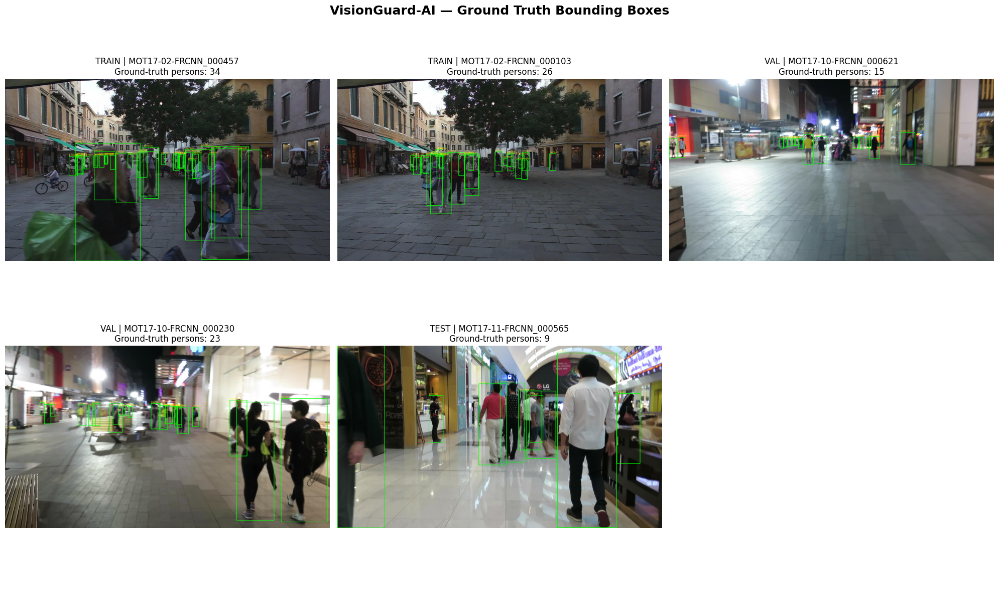


Ground-truth visualization completed.


In [7]:

# Ground Truth Visualization & Annotation Quality Check


from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random
import numpy as np

PROJECT_DIR = Path("/content/VisionGuard-AI")
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

random.seed(42)


samples = []

for split in ["train", "val", "test"]:

    image_dir = DATA_DIR / "images" / split
    label_dir = DATA_DIR / "labels" / split

    image_paths = sorted(image_dir.glob("*.jpg"))


    count = 2 if split != "test" else 1

    selected = random.sample(image_paths, count)

    for image_path in selected:

        label_path = label_dir / f"{image_path.stem}.txt"

        samples.append({
            "split": split,
            "image": image_path,
            "label": label_path,
        })

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

print("=" * 65)
print("VISIONGUARD-AI | GROUND TRUTH INSPECTION")
print("=" * 65)

for index, sample in enumerate(samples):

    image = cv2.imread(str(sample["image"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    box_count = 0

    if sample["label"].exists():

        lines = sample["label"].read_text().strip().splitlines()

        for line in lines:

            if not line.strip():
                continue

            class_id, cx, cy, bw, bh = map(float, line.split())


            x1 = int((cx - bw / 2) * width)
            y1 = int((cy - bh / 2) * height)
            x2 = int((cx + bw / 2) * width)
            y2 = int((cy + bh / 2) * height)


            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                image,
                "person",
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 255, 0),
                1
            )

            box_count += 1

    axes[index].imshow(image)
    axes[index].set_title(
        f"{sample['split'].upper()} | "
        f"{sample['image'].stem}\n"
        f"Ground-truth persons: {box_count}"
    )
    axes[index].axis("off")

    print(
        f"{sample['split'].upper():5} | "
        f"{sample['image'].name:35} | "
        f"Boxes: {box_count}"
    )


for index in range(len(samples), len(axes)):
    axes[index].axis("off")

plt.suptitle(
    "VisionGuard-AI — Ground Truth Bounding Boxes",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\nGround-truth visualization completed.")

In [8]:


from pathlib import Path
import zipfile
import hashlib
import json
import shutil
from google.colab import files

PROJECT_DIR = Path("/content/VisionGuard-AI")
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

BACKUP_DIR = PROJECT_DIR / "dataset" / "backups"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = BACKUP_DIR / "VisionGuard-AI-Selective-Dataset-v1.zip"

print("=" * 65)
print("VISIONGUARD-AI | BACKUP CREATION")
print("=" * 65)

# 1. Create backup documentation
readme = """
# VisionGuard-AI — Selective Dataset Backup

Author: MD Sha Niamatullah

## Dataset
MOT17-FRCNN selected pedestrian detection dataset.

Source:
https://motchallenge.net/data/MOT17/

Hugging Face mirror:
https://huggingface.co/datasets/Lekim89/MOT17

## Dataset Configuration
- Task: Object Detection
- Model target: YOLO11n
- Classes: 1
- Class 0: person
- Annotation format: YOLO normalized XYWH

## Dataset Split

| Split | Images |
|-------|--------|
| Train | 1200 |
| Validation | 400 |
| Test | 400 |
| Total | 2000 |

## Directory Structure

dataset/
    images/
        train/
        val/
        test/
    labels/
        train/
        val/
        test/
    data.yaml
    split_manifest.json

## Reproducibility
Random seed: 42
Sampling: Deterministic temporal linspace
Split strategy: Sequence-wise separation

## Important
The original MOT17 dataset is governed by its original
MOTChallenge terms. Refer to the official source for usage
and redistribution conditions.

This backup contains a selected subset for project work.
"""

(PROJECT_DIR / "dataset" / "DATASET_README.md").write_text(
    readme.strip(),
    encoding="utf-8"
)

# 2. Files to include
files_to_backup = [
    DATA_DIR / "images",
    DATA_DIR / "labels",
    DATA_DIR / "data.yaml",
    DATA_DIR / "split_manifest.json",
    PROJECT_DIR / "reports" / "annotation_statistics.json",
    PROJECT_DIR / "configs" / "runtime.json",
    PROJECT_DIR / "configs" / "dependencies.json",
    PROJECT_DIR / "configs" / "download_report.json",
    PROJECT_DIR / "dataset" / "DATASET_README.md",
]

for path in files_to_backup:
    if not path.exists():
        raise FileNotFoundError(f"Missing backup item: {path}")

# 3. Create ZIP without recompressing JPEG images
print("\nCreating ZIP archive...")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_STORED
) as archive:

    for item in files_to_backup:

        if item.is_file():
            archive.write(
                item,
                arcname=item.relative_to(PROJECT_DIR)
            )

        else:
            for file_path in item.rglob("*"):
                if file_path.is_file():
                    archive.write(
                        file_path,
                        arcname=file_path.relative_to(PROJECT_DIR)
                    )

# 4. Verify archive integrity
print("Verifying ZIP integrity...")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(f"Corrupted file inside ZIP: {bad_file}")

# 5. Calculate SHA256
print("Calculating SHA256 checksum...")

sha256 = hashlib.sha256()

with open(ZIP_PATH, "rb") as file:
    for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

checksum = sha256.hexdigest()

CHECKSUM_PATH = ZIP_PATH.with_suffix(".sha256")
CHECKSUM_PATH.write_text(
    f"{checksum}  {ZIP_PATH.name}\n",
    encoding="utf-8"
)

# 6. Final report
size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print("\n" + "=" * 65)
print("BACKUP READY")
print("=" * 65)
print(f"Archive       : {ZIP_PATH.name}")
print(f"Size          : {size_mb:.2f} MB")
print(f"SHA256        : {checksum}")
print(f"Integrity     : PASSED")
print(f"Checksum file : {CHECKSUM_PATH.name}")

# 7. Download archive and checksum to laptop
print("\nStarting laptop download...")

files.download(str(ZIP_PATH))

VISIONGUARD-AI | BACKUP CREATION

Creating ZIP archive...
Verifying ZIP integrity...
Calculating SHA256 checksum...

BACKUP READY
Archive       : VisionGuard-AI-Selective-Dataset-v1.zip
Size          : 314.25 MB
SHA256        : e9e4dda79f3a867e5fa6e8e73e35629d35708a349b7a76a9b8008b3a5946516a
Integrity     : PASSED
Checksum file : VisionGuard-AI-Selective-Dataset-v1.sha256

Starting laptop download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

# Final Dataset Integrity Validation


from pathlib import Path
from PIL import Image
import json

PROJECT_DIR = Path("/content/VisionGuard-AI")
DATA_DIR = PROJECT_DIR / "dataset" / "processed"

EXPECTED = {
    "train": 1200,
    "val": 400,
    "test": 400,
}

report = {
    "total_images": 0,
    "total_labels": 0,
    "corrupt_images": [],
    "missing_labels": [],
    "invalid_annotations": [],
    "split_counts": {},
}

print("=" * 65)
print("VISIONGUARD-AI | FINAL DATASET VALIDATION")
print("=" * 65)

for split, expected_count in EXPECTED.items():

    image_dir = DATA_DIR / "images" / split
    label_dir = DATA_DIR / "labels" / split

    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))

    report["split_counts"][split] = {
        "images": len(images),
        "labels": len(labels),
    }

    assert len(images) == expected_count, (
        f"{split}: expected {expected_count} images, found {len(images)}"
    )

    assert len(labels) == expected_count, (
        f"{split}: expected {expected_count} labels, found {len(labels)}"
    )

    label_names = {p.stem for p in labels}

    for image_path in images:

        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            report["missing_labels"].append(str(image_path))
            continue

        # Verify image integrity
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            report["corrupt_images"].append(str(image_path))
            continue

        # Validate YOLO annotations
        content = label_path.read_text(encoding="utf-8").strip()

        if not content:
            continue

        for line_number, line in enumerate(content.splitlines(), start=1):

            try:
                values = line.split()

                if len(values) != 5:
                    raise ValueError("Expected 5 YOLO values")

                class_id, cx, cy, bw, bh = map(float, values)

                valid = (
                    class_id == 0
                    and 0 <= cx <= 1
                    and 0 <= cy <= 1
                    and 0 < bw <= 1
                    and 0 < bh <= 1
                    and cx - bw / 2 >= -1e-6
                    and cy - bh / 2 >= -1e-6
                    and cx + bw / 2 <= 1 + 1e-6
                    and cy + bh / 2 <= 1 + 1e-6
                )

                if not valid:
                    report["invalid_annotations"].append({
                        "file": str(label_path),
                        "line": line_number,
                        "values": line,
                    })

            except Exception as error:
                report["invalid_annotations"].append({
                    "file": str(label_path),
                    "line": line_number,
                    "error": str(error),
                })

    report["total_images"] += len(images)
    report["total_labels"] += len(labels)

# Save validation report
report_path = PROJECT_DIR / "reports" / "dataset_validation.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(json.dumps(report, indent=4))

print("\nSPLIT SUMMARY")

for split, counts in report["split_counts"].items():
    print(
        f"{split.upper():5} | "
        f"Images: {counts['images']} | "
        f"Labels: {counts['labels']}"
    )

print("\nVALIDATION RESULTS")
print(f"Total images          : {report['total_images']}")
print(f"Total labels          : {report['total_labels']}")
print(f"Corrupt images        : {len(report['corrupt_images'])}")
print(f"Missing labels        : {len(report['missing_labels'])}")
print(f"Invalid annotations   : {len(report['invalid_annotations'])}")

print(f"\nReport saved: {report_path}")

assert not report["corrupt_images"], "Corrupt images detected"
assert not report["missing_labels"], "Missing labels detected"
assert not report["invalid_annotations"], "Invalid YOLO annotations detected"

print("\nSUCCESS: Dataset is ready for model training.")

VISIONGUARD-AI | FINAL DATASET VALIDATION

SPLIT SUMMARY
TRAIN | Images: 1200 | Labels: 1200
VAL   | Images: 400 | Labels: 400
TEST  | Images: 400 | Labels: 400

VALIDATION RESULTS
Total images          : 2000
Total labels          : 2000
Corrupt images        : 0
Missing labels        : 0
Invalid annotations   : 0

Report saved: /content/VisionGuard-AI/reports/dataset_validation.json

SUCCESS: Dataset is ready for model training.


In [10]:

# YOLO11n Baseline Training


from pathlib import Path
from ultralytics import YOLO
import torch
import json
import time
import shutil
import ultralytics

PROJECT_DIR = Path("/content/VisionGuard-AI")

DATA_YAML = PROJECT_DIR / "dataset" / "processed" / "data.yaml"

PRETRAINED_DIR = PROJECT_DIR / "models" / "pretrained"
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

RUNS_DIR = PROJECT_DIR / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_DIR = PROJECT_DIR / "configs"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)


# 1. Hardware verification


assert torch.cuda.is_available(), "CUDA GPU is not available!"

device_name = torch.cuda.get_device_name(0)

print("=" * 70)
print("VISIONGUARD-AI | BASELINE TRAINING")
print("=" * 70)

print(f"PyTorch       : {torch.__version__}")
print(f"Ultralytics   : {ultralytics.__version__}")
print(f"GPU           : {device_name}")
print(f"CUDA          : {torch.version.cuda}")
print(f"GPU Memory    : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")


# 2. Training configuration


TRAIN_CONFIG = {
    "experiment": "baseline",
    "model": "YOLO11n",
    "initial_weights": "yolo11n.pt",
    "dataset": str(DATA_YAML),
    "image_size": 640,
    "batch_size": 8,
    "epochs": 15,
    "optimizer": "auto",
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "cache": False,
    "pretrained": True,
    "validation_during_training": True,
    "test_during_training": False,
}

config_path = CONFIG_DIR / "baseline_config.json"

config_path.write_text(
    json.dumps(TRAIN_CONFIG, indent=4),
    encoding="utf-8"
)

print("\nTRAINING CONFIGURATION")
print(json.dumps(TRAIN_CONFIG, indent=4))




print("\nLoading pretrained YOLO11n weights...")

model = YOLO("yolo11n.pt")

print("Pretrained model loaded successfully.")


initial_weights = PRETRAINED_DIR / "yolo11n.pt"

if not initial_weights.exists():
    source_weights = Path("yolo11n.pt")

    if source_weights.exists():
        shutil.copy2(source_weights, initial_weights)



print("\nStarting baseline training...")
print("Training will use the Colab NVIDIA T4 GPU.")

start_time = time.time()

results = model.train(
    data=str(DATA_YAML),
    epochs=15,
    imgsz=640,
    batch=8,
    workers=2,
    device=0,
    optimizer="auto",
    seed=42,
    deterministic=True,
    amp=True,
    cache=False,
    pretrained=True,
    val=True,
    plots=True,
    save=True,
    project=str(RUNS_DIR),
    name="baseline",
    exist_ok=True,
    verbose=True,
)

training_time = time.time() - start_time


# 5. Locate and preserve best checkpoint


save_dir = Path(model.trainer.save_dir)

best_checkpoint = save_dir / "weights" / "best.pt"
last_checkpoint = save_dir / "weights" / "last.pt"

assert best_checkpoint.exists(), "Best checkpoint was not created!"

final_baseline_path = (
    PROJECT_DIR / "models" / "baseline"
)
final_baseline_path.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    best_checkpoint,
    final_baseline_path / "best.pt"
)


# 6. Save training report


training_report = {
    "experiment": "baseline",
    "model": "YOLO11n",
    "gpu": device_name,
    "epochs_requested": 15,
    "training_time_seconds": round(training_time, 2),
    "training_time_minutes": round(training_time / 60, 2),
    "run_directory": str(save_dir),
    "best_checkpoint": str(best_checkpoint),
    "last_checkpoint": str(last_checkpoint),
    "preserved_checkpoint": str(final_baseline_path / "best.pt"),
    "results_csv": str(save_dir / "results.csv"),
    "config": TRAIN_CONFIG,
}

report_path = PROJECT_DIR / "reports" / "baseline_training_report.json"

report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(
    json.dumps(training_report, indent=4),
    encoding="utf-8"
)


# 7. Final summary


print("\n" + "=" * 70)
print("BASELINE TRAINING COMPLETED")
print("=" * 70)

print(f"Training time : {training_time / 60:.2f} minutes")
print(f"Best model    : {final_baseline_path / 'best.pt'}")
print(f"Last model    : {last_checkpoint}")
print(f"Results CSV   : {save_dir / 'results.csv'}")
print(f"Report        : {report_path}")

print("\nSUCCESS: Baseline checkpoint saved.")

VISIONGUARD-AI | BASELINE TRAINING
PyTorch       : 2.14.1+cu130
Ultralytics   : 8.4.215
GPU           : Tesla T4
CUDA          : 13.0
GPU Memory    : 14.56 GB

TRAINING CONFIGURATION
{
    "experiment": "baseline",
    "model": "YOLO11n",
    "initial_weights": "yolo11n.pt",
    "dataset": "/content/VisionGuard-AI/dataset/processed/data.yaml",
    "image_size": 640,
    "batch_size": 8,
    "epochs": 15,
    "optimizer": "auto",
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": true,
    "amp": true,
    "cache": false,
    "pretrained": true,
    "validation_during_training": true,
    "test_during_training": false
}

Loading pretrained YOLO11n weights...
Pretrained model loaded successfully.

Starting baseline training...
Training will use the Colab NVIDIA T4 GPU.
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer:

In [11]:

# Experiment 02 — YOLO11n at 512 Resolution


from pathlib import Path
from ultralytics import YOLO
import torch
import json
import time
import shutil
import ultralytics

PROJECT_DIR = Path("/content/VisionGuard-AI")

DATA_YAML = PROJECT_DIR / "dataset/processed/data.yaml"
INITIAL_WEIGHTS = PROJECT_DIR / "models/pretrained/yolo11n.pt"

RUNS_DIR = PROJECT_DIR / "runs"
CONFIG_DIR = PROJECT_DIR / "configs"

EXPERIMENT_DIR = PROJECT_DIR / "models/experiment"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available()
assert INITIAL_WEIGHTS.exists(), "Original pretrained weights missing!"

# Experiment configuration
EXPERIMENT_CONFIG = {
    "experiment": "experiment_02",
    "model": "YOLO11n",
    "initial_weights": str(INITIAL_WEIGHTS),
    "image_size": 512,
    "batch_size": 8,
    "epochs": 15,
    "optimizer": "auto",
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "cache": False,
    "pretrained": True,
    "hypothesis": (
        "Reducing image resolution from 640 to 512 may reduce "
        "training time and resource consumption, but may affect "
        "small pedestrian detection performance."
    ),
    "only_intentional_change": "image_size: 640 -> 512"
}

config_path = CONFIG_DIR / "experiment_02_config.json"
config_path.write_text(json.dumps(EXPERIMENT_CONFIG, indent=4))

print("=" * 70)
print("VISIONGUARD-AI | EXPERIMENT 02")
print("=" * 70)

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"PyTorch: {torch.__version__}")
print(f"Ultralytics: {ultralytics.__version__}")
print("Image size: 512")
print("Batch size: 8")
print("Epochs: 15")

# Load the SAME original pretrained weights
model = YOLO(str(INITIAL_WEIGHTS))

print("\nOriginal pretrained YOLO11n loaded.")

# Start experiment
start_time = time.time()

results = model.train(
    data=str(DATA_YAML),
    epochs=15,
    imgsz=512,
    batch=8,
    workers=2,
    device=0,
    optimizer="auto",
    seed=42,
    deterministic=True,
    amp=True,
    cache=False,
    pretrained=True,
    val=True,
    plots=True,
    save=True,
    project=str(RUNS_DIR),
    name="experiment_02",
    exist_ok=True,
    verbose=True,
)

training_time = time.time() - start_time

# Preserve best checkpoint
save_dir = Path(model.trainer.save_dir)

best_checkpoint = save_dir / "weights" / "best.pt"
last_checkpoint = save_dir / "weights" / "last.pt"

assert best_checkpoint.exists(), "Best checkpoint missing!"

experiment_checkpoint = EXPERIMENT_DIR / "experiment_02_best.pt"

shutil.copy2(best_checkpoint, experiment_checkpoint)

# Save report
report = {
    **EXPERIMENT_CONFIG,
    "gpu": torch.cuda.get_device_name(0),
    "training_time_seconds": round(training_time, 2),
    "training_time_minutes": round(training_time / 60, 2),
    "run_directory": str(save_dir),
    "best_checkpoint": str(experiment_checkpoint),
    "last_checkpoint": str(last_checkpoint),
    "results_csv": str(save_dir / "results.csv"),
}

report_path = PROJECT_DIR / "reports" / "experiment_02_report.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(json.dumps(report, indent=4))

print("\n" + "=" * 70)
print("EXPERIMENT 02 COMPLETED")
print("=" * 70)

print(f"Training time : {training_time / 60:.2f} minutes")
print(f"Best model    : {experiment_checkpoint}")
print(f"Results CSV   : {save_dir / 'results.csv'}")
print(f"Report        : {report_path}")

print("\nSUCCESS: Experiment 02 checkpoint saved.")

VISIONGUARD-AI | EXPERIMENT 02
GPU: Tesla T4
PyTorch: 2.14.1+cu130
Ultralytics: 8.4.215
Image size: 512
Batch size: 8
Epochs: 15

Original pretrained YOLO11n loaded.
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VisionGuard-AI/dataset/processed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

In [12]:

# Advanced Training — YOLO11n Refined
# Stage 2: Fine-tuning from Baseline Best Checkpoint


from pathlib import Path
from ultralytics import YOLO
import torch
import json
import time
import shutil
import ultralytics



PROJECT_DIR = Path("/content/VisionGuard-AI")

DATA_YAML = PROJECT_DIR / "dataset/processed/data.yaml"
BASELINE_CHECKPOINT = PROJECT_DIR / "models/baseline/best.pt"

RUNS_DIR = PROJECT_DIR / "runs"
CONFIG_DIR = PROJECT_DIR / "configs"
REPORT_DIR = PROJECT_DIR / "reports"

REFINED_DIR = PROJECT_DIR / "models/refined"
REFINED_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "CUDA GPU unavailable!"
assert BASELINE_CHECKPOINT.exists(), "Baseline checkpoint missing!"
assert DATA_YAML.exists(), "Dataset configuration missing!"

device_name = torch.cuda.get_device_name(0)

print("=" * 70)
print("VISIONGUARD-AI | YOLO11n REFINED TRAINING")
print("=" * 70)

print(f"GPU           : {device_name}")
print(f"PyTorch       : {torch.__version__}")
print(f"Ultralytics   : {ultralytics.__version__}")
print(f"Initial model : {BASELINE_CHECKPOINT}")
print(f"Image size    : 640")
print(f"Additional epochs: 25")
print(f"Cumulative training epochs: 40")


# 2. Fine-tuning configuration


REFINED_CONFIG = {
    "experiment": "yolo11n_refined",
    "architecture": "YOLO11n",
    "initial_checkpoint": str(BASELINE_CHECKPOINT),
    "dataset": str(DATA_YAML),

    # Preserve baseline resolution and batch size
    "image_size": 640,
    "batch_size": 8,

    # 15 baseline epochs + 25 refinement epochs = 40
    "additional_epochs": 25,
    "cumulative_epochs": 40,

    # Lower learning rate for fine-tuning
    "optimizer": "AdamW",
    "lr0": 0.0005,
    "lrf": 0.01,
    "cos_lr": True,

    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "cache": False,
    "patience": 10,
    "close_mosaic": 5,

    "selection": "validation",
    "test_during_training": False
}

config_path = CONFIG_DIR / "yolo11n_refined_config.json"
config_path.write_text(json.dumps(REFINED_CONFIG, indent=4))

print("\nCONFIGURATION")
print(json.dumps(REFINED_CONFIG, indent=4))


# 3. Load the best baseline checkpoint


print("\nLoading baseline best checkpoint...")

model = YOLO(str(BASELINE_CHECKPOINT))

print("Baseline checkpoint loaded successfully.")


# 4. Fine-tuning


print("\nStarting YOLO11n refinement on NVIDIA T4...")

torch.cuda.reset_peak_memory_stats()
start_time = time.time()

results = model.train(
    data=str(DATA_YAML),

    epochs=25,
    imgsz=640,
    batch=8,

    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    cos_lr=True,

    workers=2,
    device=0,
    seed=42,
    deterministic=True,

    amp=True,
    cache=False,
    pretrained=True,

    patience=10,
    close_mosaic=5,

    val=True,
    plots=True,
    save=True,

    project=str(RUNS_DIR),
    name="yolo11n_refined",
    exist_ok=True,
    verbose=True,
)

training_time = time.time() - start_time
peak_gpu_memory = torch.cuda.max_memory_allocated() / (1024 ** 3)


# 5. Preserve best and last checkpoints


save_dir = Path(model.trainer.save_dir)

best_checkpoint = save_dir / "weights" / "best.pt"
last_checkpoint = save_dir / "weights" / "last.pt"

assert best_checkpoint.exists(), "Refined best checkpoint missing!"

preserved_best = REFINED_DIR / "best.pt"
preserved_last = REFINED_DIR / "last.pt"

shutil.copy2(best_checkpoint, preserved_best)

if last_checkpoint.exists():
    shutil.copy2(last_checkpoint, preserved_last)


# 6. Save experiment report


report = {
    **REFINED_CONFIG,
    "gpu": device_name,
    "pytorch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "training_time_seconds": round(training_time, 2),
    "training_time_minutes": round(training_time / 60, 2),
    "peak_gpu_memory_gb": round(peak_gpu_memory, 3),
    "run_directory": str(save_dir),
    "best_checkpoint": str(preserved_best),
    "last_checkpoint": str(preserved_last),
    "results_csv": str(save_dir / "results.csv"),
    "training_started_from": "Baseline best checkpoint",
}

report_path = REPORT_DIR / "yolo11n_refined_report.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(json.dumps(report, indent=4))


# 7. Summary


print("\n" + "=" * 70)
print("YOLO11n REFINED TRAINING COMPLETED")
print("=" * 70)

print(f"Training time       : {training_time / 60:.2f} minutes")
print(f"Peak GPU memory     : {peak_gpu_memory:.2f} GB")
print(f"Best checkpoint     : {preserved_best}")
print(f"Last checkpoint     : {preserved_last}")
print(f"Results CSV         : {save_dir / 'results.csv'}")
print(f"Configuration       : {config_path}")
print(f"Training report     : {report_path}")

print("\nSUCCESS: Refined YOLO11n checkpoint saved.")

VISIONGUARD-AI | YOLO11n REFINED TRAINING
GPU           : Tesla T4
PyTorch       : 2.14.1+cu130
Ultralytics   : 8.4.215
Initial model : /content/VisionGuard-AI/models/baseline/best.pt
Image size    : 640
Additional epochs: 25
Cumulative training epochs: 40

CONFIGURATION
{
    "experiment": "yolo11n_refined",
    "architecture": "YOLO11n",
    "initial_checkpoint": "/content/VisionGuard-AI/models/baseline/best.pt",
    "dataset": "/content/VisionGuard-AI/dataset/processed/data.yaml",
    "image_size": 640,
    "batch_size": 8,
    "additional_epochs": 25,
    "cumulative_epochs": 40,
    "optimizer": "AdamW",
    "lr0": 0.0005,
    "lrf": 0.01,
    "cos_lr": true,
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": true,
    "amp": true,
    "cache": false,
    "patience": 10,
    "close_mosaic": 5,
    "selection": "validation",
    "test_during_training": false
}

Loading baseline best checkpoint...
Baseline checkpoint loaded successfully.

Starting YOLO11n refine

In [13]:

# Advanced Training — YOLO11s
# Larger Model Architecture Experiment


from pathlib import Path
from ultralytics import YOLO
import torch
import json
import time
import shutil
import ultralytics




PROJECT_DIR = Path("/content/VisionGuard-AI")

DATA_YAML = PROJECT_DIR / "dataset/processed/data.yaml"
RUNS_DIR = PROJECT_DIR / "runs"
CONFIG_DIR = PROJECT_DIR / "configs"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR = PROJECT_DIR / "models" / "yolo11s"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "CUDA GPU unavailable!"
assert DATA_YAML.exists(), "Dataset configuration missing!"

GPU_NAME = torch.cuda.get_device_name(0)

print("=" * 70)
print("VISIONGUARD-AI | YOLO11s TRAINING")
print("=" * 70)

print(f"GPU         : {GPU_NAME}")
print(f"PyTorch     : {torch.__version__}")
print(f"Ultralytics : {ultralytics.__version__}")



CONFIG = {
    "experiment": "yolo11s_architecture_comparison",
    "architecture": "YOLO11s",
    "initial_weights": "yolo11s.pt",
    "image_size": 640,
    "batch_size": 8,
    "maximum_epochs": 40,
    "optimizer": "auto",
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "cache": False,
    "patience": 10,
    "pretrained": True,
    "validation_during_training": True,
    "test_during_training": False,
    "hypothesis": (
        "The larger YOLO11s architecture may improve pedestrian "
        "detection performance compared with YOLO11n, potentially "
        "at the cost of increased computation and inference latency."
    )
}

config_path = CONFIG_DIR / "yolo11s_config.json"
config_path.write_text(json.dumps(CONFIG, indent=4))

print("\nEXPERIMENT CONFIGURATION")
print(json.dumps(CONFIG, indent=4))



print("\nLoading pretrained YOLO11s weights...")

model = YOLO("yolo11s.pt")

print("YOLO11s pretrained model loaded.")


pretrained_path = Path("yolo11s.pt")

if pretrained_path.exists():
    shutil.copy2(
        pretrained_path,
        MODEL_DIR / "yolo11s_pretrained.pt"
    )


# 4. Training


print("\nStarting YOLO11s training on Tesla T4...")

torch.cuda.reset_peak_memory_stats()
start_time = time.time()

results = model.train(
    data=str(DATA_YAML),

    epochs=40,
    imgsz=640,
    batch=8,

    optimizer="auto",

    workers=2,
    device=0,

    seed=42,
    deterministic=True,

    amp=True,
    cache=False,
    pretrained=True,

    patience=10,

    val=True,
    plots=True,
    save=True,

    project=str(RUNS_DIR),
    name="yolo11s",
    exist_ok=True,

    verbose=True,
)

training_time = time.time() - start_time

peak_gpu_memory = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
)


# 5. Save best checkpoint


save_dir = Path(model.trainer.save_dir)

best_checkpoint = save_dir / "weights" / "best.pt"
last_checkpoint = save_dir / "weights" / "last.pt"

assert best_checkpoint.exists(), "YOLO11s best checkpoint missing!"

preserved_best = MODEL_DIR / "best.pt"
preserved_last = MODEL_DIR / "last.pt"

shutil.copy2(best_checkpoint, preserved_best)

if last_checkpoint.exists():
    shutil.copy2(last_checkpoint, preserved_last)



report = {
    **CONFIG,
    "gpu": GPU_NAME,
    "pytorch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "actual_epochs_completed": int(model.trainer.epoch + 1),
    "training_time_seconds": round(training_time, 2),
    "training_time_minutes": round(training_time / 60, 2),
    "peak_gpu_memory_gb": round(peak_gpu_memory, 3),
    "run_directory": str(save_dir),
    "best_checkpoint": str(preserved_best),
    "last_checkpoint": str(preserved_last),
    "results_csv": str(save_dir / "results.csv"),
}

report_path = REPORT_DIR / "yolo11s_training_report.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(json.dumps(report, indent=4))



print("\n" + "=" * 70)
print("YOLO11s TRAINING COMPLETED")
print("=" * 70)

print(f"Actual epochs    : {report['actual_epochs_completed']}")
print(f"Training time    : {training_time / 60:.2f} minutes")
print(f"Peak GPU memory  : {peak_gpu_memory:.2f} GB")
print(f"Best checkpoint  : {preserved_best}")
print(f"Last checkpoint  : {preserved_last}")
print(f"Results CSV      : {save_dir / 'results.csv'}")
print(f"Training report  : {report_path}")

print("\nSUCCESS: YOLO11s experiment saved.")

VISIONGUARD-AI | YOLO11s TRAINING
GPU         : Tesla T4
PyTorch     : 2.14.1+cu130
Ultralytics : 8.4.215

EXPERIMENT CONFIGURATION
{
    "experiment": "yolo11s_architecture_comparison",
    "architecture": "YOLO11s",
    "initial_weights": "yolo11s.pt",
    "image_size": 640,
    "batch_size": 8,
    "maximum_epochs": 40,
    "optimizer": "auto",
    "workers": 2,
    "device": 0,
    "seed": 42,
    "deterministic": true,
    "amp": true,
    "cache": false,
    "patience": 10,
    "pretrained": true,
    "validation_during_training": true,
    "test_during_training": false,
    "hypothesis": "The larger YOLO11s architecture may improve pedestrian detection performance compared with YOLO11n, potentially at the cost of increased computation and inference latency."
}

Loading pretrained YOLO11s weights...
YOLO11s pretrained model loaded.

Starting YOLO11s training on Tesla T4...
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultral

Available metrics:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


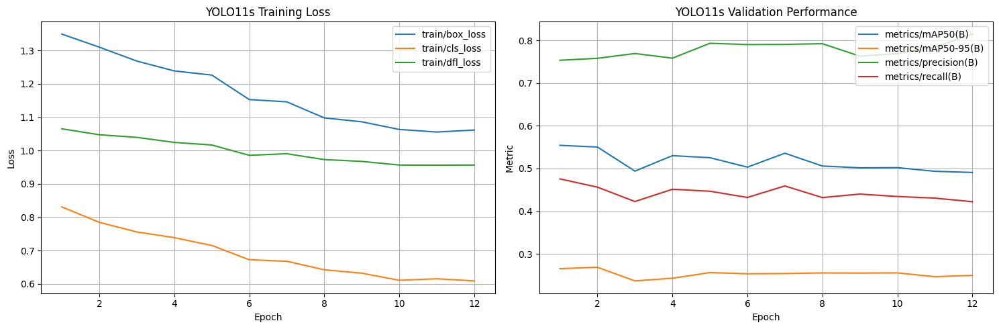

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path(
    "/content/VisionGuard-AI/runs/yolo11s/results.csv"
)

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

print("Available metrics:")
print(df.columns.tolist())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))


for col in ["train/box_loss", "train/cls_loss", "train/dfl_loss"]:
    if col in df.columns:
        axes[0].plot(df.index + 1, df[col], label=col)

axes[0].set_title("YOLO11s Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


for col in [
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
    "metrics/precision(B)",
    "metrics/recall(B)"
]:
    if col in df.columns:
        axes[1].plot(df.index + 1, df[col], label=col)

axes[1].set_title("YOLO11s Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Metric")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

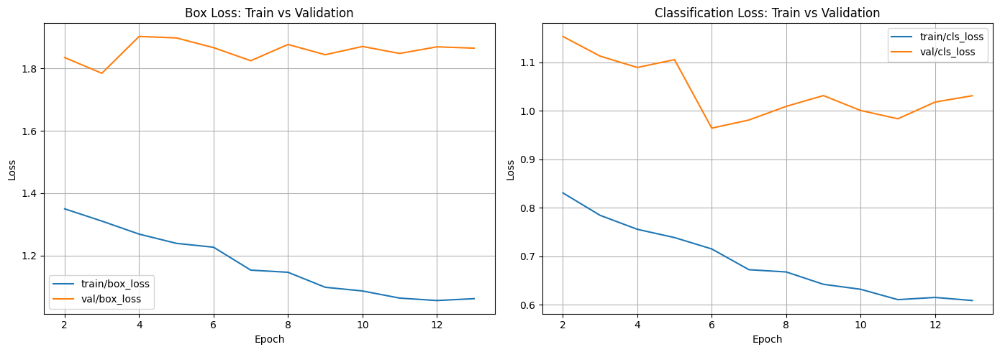


Validation loss by epoch:
 epoch  val/box_loss  val/cls_loss  val/dfl_loss
     1       1.83505       1.15360       1.15753
     2       1.78469       1.11301       1.13086
     3       1.90281       1.08953       1.21091
     4       1.89813       1.10567       1.15828
     5       1.86683       0.96438       1.17857
     6       1.82491       0.98116       1.16681
     7       1.87708       1.00930       1.18213
     8       1.84415       1.03154       1.15697
     9       1.87061       1.00078       1.19070
    10       1.84821       0.98367       1.18786
    11       1.86941       1.01818       1.17114
    12       1.86524       1.03124       1.17924


In [15]:
import pandas as pd
import matplotlib.pyplot as plt

path = "/content/VisionGuard-AI/runs/yolo11s/results.csv"
df = pd.read_csv(path)
df.columns = df.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


for col in ["train/box_loss", "val/box_loss"]:
    axes[0].plot(df["epoch"] + 1, df[col], label=col)

axes[0].set_title("Box Loss: Train vs Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


for col in ["train/cls_loss", "val/cls_loss"]:
    axes[1].plot(df["epoch"] + 1, df[col], label=col)

axes[1].set_title("Classification Loss: Train vs Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("\nValidation loss by epoch:")
print(df[[
    "epoch",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss"
]].to_string(index=False))

In [16]:

import json
import time
import shutil
from pathlib import Path

import torch
from ultralytics import YOLO


# VISIONGUARD-AI | EXPERIMENT 03
# YOLO11s - Lower Learning Rate


ROOT = Path("/content/VisionGuard-AI")
DATA = ROOT / "dataset/processed/data.yaml"

RUN_DIR = ROOT / "runs"
MODEL_DIR = ROOT / "models/yolo11s_lr_tuned"
CONFIG_DIR = ROOT / "configs"
REPORT_DIR = ROOT / "reports"

for folder in [MODEL_DIR, CONFIG_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

assert DATA.exists(), "Dataset YAML missing. Restore processed dataset first."

# Preserve the original pretrained initialization
model = YOLO("yolo11s.pt")

config = {
    "experiment": "yolo11s_lower_learning_rate",
    "architecture": "YOLO11s",
    "initial_weights": "yolo11s.pt",
    "image_size": 640,
    "batch_size": 8,
    "maximum_epochs": 40,
    "optimizer": "AdamW",
    "learning_rate": 0.0005,
    "momentum": 0.9,
    "patience": 10,
    "workers": 2,
    "seed": 42,
    "deterministic": True,
    "amp": True,
    "cache": False,
    "hypothesis": (
        "A lower learning rate may stabilize weight updates "
        "and improve validation generalization while balancing "
        "precision, recall and mAP."
    ),
    "only_intentional_change": "Learning rate: 0.002 -> 0.0005"
}

with open(CONFIG_DIR / "yolo11s_lr_tuned_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("=" * 65)
print("VISIONGUARD-AI | EXPERIMENT 03")
print("=" * 65)
print("Architecture : YOLO11s")
print("Optimizer    : AdamW")
print("Learning rate: 0.0005")
print("Image size   : 640")
print("Batch size   : 8")
print("Max epochs   : 40")
print("Patience     : 10")
print("=" * 65)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    print("GPU:", torch.cuda.get_device_name(0))

start_time = time.time()

results = model.train(
    data=str(DATA),
    epochs=40,
    imgsz=640,
    batch=8,
    optimizer="AdamW",
    lr0=0.0005,
    momentum=0.9,
    patience=10,
    workers=2,
    device=0,
    seed=42,
    deterministic=True,
    amp=True,
    cache=False,
    val=True,
    plots=True,
    save=True,
    project=str(RUN_DIR),
    name="yolo11s_lr_tuned",
    exist_ok=True,
    verbose=True
)

training_seconds = time.time() - start_time
actual_epochs = model.trainer.epoch + 1

best_source = Path(model.trainer.best)
last_source = Path(model.trainer.last)

best_destination = MODEL_DIR / "best.pt"
last_destination = MODEL_DIR / "last.pt"

shutil.copy2(best_source, best_destination)

if last_source.exists():
    shutil.copy2(last_source, last_destination)

peak_memory_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
    if torch.cuda.is_available()
    else None
)

report = {
    **config,
    "actual_epochs": actual_epochs,
    "training_time_seconds": round(training_seconds, 2),
    "training_time_minutes": round(training_seconds / 60, 2),
    "peak_gpu_memory_gb": round(peak_memory_gb, 3)
        if peak_memory_gb is not None else None,
    "best_checkpoint": str(best_destination),
    "last_checkpoint": str(last_destination),
    "results_csv": str(
        RUN_DIR / "yolo11s_lr_tuned" / "results.csv"
    )
}

with open(REPORT_DIR / "yolo11s_lr_tuned_report.json", "w") as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 65)
print("EXPERIMENT 03 COMPLETED")
print("=" * 65)
print("Actual epochs :", actual_epochs)
print("Training time :", round(training_seconds / 60, 2), "minutes")
print("Peak GPU memory:", peak_memory_gb, "GB")
print("Best checkpoint:", best_destination)
print("Results CSV:", report["results_csv"])
print("Report:", REPORT_DIR / "yolo11s_lr_tuned_report.json")
print("=" * 65)


VISIONGUARD-AI | EXPERIMENT 03
Architecture : YOLO11s
Optimizer    : AdamW
Learning rate: 0.0005
Image size   : 640
Batch size   : 8
Max epochs   : 40
Patience     : 10
GPU: Tesla T4
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VisionGuard-AI/dataset/processed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, f

In [17]:

import json
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

ROOT = Path("/content/VisionGuard-AI")
DATA = ROOT / "dataset/processed/data.yaml"

# All checkpoints remain untouched.
candidates = {
    "YOLO11n Baseline": ROOT / "models/baseline/best.pt",
    "YOLO11n Refined": ROOT / "models/refined/best.pt",
    "YOLO11n 512 Experiment": ROOT / "models/experiment/experiment_02_best.pt",
    "YOLO11s": ROOT / "models/yolo11s/best.pt",
    "YOLO11s LR Tuned": ROOT / "models/yolo11s_lr_tuned/best.pt",
}

for name, path in candidates.items():
    if not path.exists():
        raise FileNotFoundError(f"{name}: checkpoint missing: {path}")

comparison_dir = ROOT / "runs/standardized_validation"
comparison_dir.mkdir(parents=True, exist_ok=True)

records = []

print("=" * 70)
print("VISIONGUARD-AI | STANDARDIZED VALIDATION")
print("Split: validation | Image size: 640 | Conf: 0.001 | IoU: 0.7")
print("=" * 70)

for name, checkpoint in candidates.items():
    print(f"\nEvaluating: {name}")

    model = YOLO(str(checkpoint))

    metrics = model.val(
        data=str(DATA),
        split="val",
        imgsz=640,
        batch=8,
        conf=0.001,
        iou=0.7,
        device=0,
        workers=2,
        plots=True,
        project=str(comparison_dir),
        name=name.lower().replace(" ", "_"),
        exist_ok=True,
        verbose=False
    )

    precision = float(metrics.box.mp)
    recall = float(metrics.box.mr)
    map50 = float(metrics.box.map50)
    map5095 = float(metrics.box.map)

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    records.append({
        "model": name,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mAP50": map50,
        "mAP50_95": map5095,
        "checkpoint": str(checkpoint)
    })

    print(
        f"P={precision:.4f} | R={recall:.4f} | "
        f"F1={f1:.4f} | mAP50={map50:.4f} | "
        f"mAP50-95={map5095:.4f}"
    )

df = pd.DataFrame(records)
df = df.sort_values("mAP50_95", ascending=False)

csv_path = ROOT / "metrics/standardized_model_comparison.csv"
json_path = ROOT / "reports/standardized_model_comparison.json"

csv_path.parent.mkdir(parents=True, exist_ok=True)
json_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(csv_path, index=False)

with open(json_path, "w") as f:
    json.dump(df.to_dict(orient="records"), f, indent=4)

print("\n" + "=" * 70)
print("FINAL STANDARDIZED VALIDATION RANKING")
print("=" * 70)
print(df[[
    "model", "precision", "recall",
    "f1", "mAP50", "mAP50_95"
]].to_string(index=False))

print("\nSaved:", csv_path)
print("Saved:", json_path)


VISIONGUARD-AI | STANDARDIZED VALIDATION
Split: validation | Image size: 640 | Conf: 0.001 | IoU: 0.7

Evaluating: YOLO11n Baseline
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1456.9±704.4 MB/s, size: 128.7 KB)
val: Scanning /content/VisionGuard-AI/dataset/processed/labels/val.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 104.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 8.0it/s 6.3s
                   all        400       7854      0.753      0.415      0.479       0.23
Speed: 1.0ms preprocess, 4.4ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/VisionGuard-AI/runs/standardized_validation/yolo11n_baseline
P=0.7533 | R=0.4146 | F1=0.5348 | mAP50=0.4786 | mAP50-95=0.2296

Evaluatin

In [18]:

import json
import shutil
from pathlib import Path

ROOT = Path("/content/VisionGuard-AI")

source = ROOT / "models/yolo11s_lr_tuned/best.pt"
final_dir = ROOT / "models/final"
final_dir.mkdir(parents=True, exist_ok=True)

destination = final_dir / "best.pt"

assert source.exists(), f"Checkpoint missing: {source}"

# Preserve the original experiment checkpoint.
shutil.copy2(source, destination)

selection = {
    "selected_model": "YOLO11s LR Tuned",
    "architecture": "YOLO11s",
    "selection_basis": "Standardized validation comparison only",
    "validation_metrics": {
        "precision": 0.839367,
        "recall": 0.491002,
        "f1": 0.619574,
        "mAP50": 0.593077,
        "mAP50_95": 0.301730
    },
    "evaluation_settings": {
        "split": "val",
        "images": 400,
        "ground_truth_instances": 7854,
        "image_size": 640,
        "confidence": 0.001,
        "nms_iou": 0.7
    },
    "checkpoint": str(destination),
    "test_evaluated": False
}

report_path = ROOT / "reports/final_model_selection.json"

with open(report_path, "w") as f:
    json.dump(selection, f, indent=4)

print("=" * 65)
print("FINAL MODEL CANDIDATE SAVED")
print("=" * 65)
print("Selected model:", selection["selected_model"])
print("Checkpoint:", destination)
print("Selection report:", report_path)
print("Test evaluated:", selection["test_evaluated"])
print("=" * 65)


FINAL MODEL CANDIDATE SAVED
Selected model: YOLO11s LR Tuned
Checkpoint: /content/VisionGuard-AI/models/final/best.pt
Selection report: /content/VisionGuard-AI/reports/final_model_selection.json
Test evaluated: False


In [19]:

import json
import time
from pathlib import Path

import torch
from ultralytics import YOLO

ROOT = Path("/content/VisionGuard-AI")

MODEL_PATH = ROOT / "models/final/best.pt"
DATA_PATH = ROOT / "dataset/processed/data.yaml"

REPORT_DIR = ROOT / "reports"
PREDICTION_DIR = ROOT / "predictions/test"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.exists(), "Final checkpoint not found."
assert DATA_PATH.exists(), "Dataset configuration not found."

print("=" * 65)
print("VISIONGUARD-AI | FINAL HELD-OUT TEST EVALUATION")
print("=" * 65)

model = YOLO(str(MODEL_PATH))

start_time = time.time()

metrics = model.val(
    data=str(DATA_PATH),
    split="test",
    imgsz=640,
    batch=8,
    conf=0.001,
    iou=0.7,
    device=0,
    workers=2,
    plots=True,
    project=str(ROOT / "runs"),
    name="final_test_evaluation",
    exist_ok=True,
    verbose=True
)

evaluation_seconds = time.time() - start_time

precision = float(metrics.box.mp)
recall = float(metrics.box.mr)
map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

report = {
    "model": "YOLO11s LR Tuned",
    "split": "test",
    "evaluation_settings": {
        "image_size": 640,
        "confidence_threshold": 0.001,
        "nms_iou_threshold": 0.7
    },
    "metrics": {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mAP50": map50,
        "mAP50_95": map5095
    },
    "evaluation_time_seconds": round(evaluation_seconds, 2),
    "checkpoint": str(MODEL_PATH),
    "test_evaluated": True
}

report_path = REPORT_DIR / "final_test_evaluation.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 65)
print("FINAL TEST RESULTS")
print("=" * 65)
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"mAP50     : {map50:.4f}")
print(f"mAP50-95  : {map5095:.4f}")
print(f"Eval time : {evaluation_seconds:.2f} seconds")
print("Report    :", report_path)
print("=" * 65)


VISIONGUARD-AI | FINAL HELD-OUT TEST EVALUATION
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 38.5±20.8 MB/s, size: 170.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/VisionGuard-AI/dataset/processed/labels/test... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 329.8it/s 1.2s
val: New cache created: /content/VisionGuard-AI/dataset/processed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 5.6it/s 9.0s
                   all        400       5216        0.8      0.432      0.504       0.31
Speed: 1.2ms preprocess, 6.2ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved t

In [20]:

from pathlib import Path
from ultralytics import YOLO
import random
import json

ROOT = Path("/content/VisionGuard-AI")
MODEL = ROOT / "models/final/best.pt"
TEST_IMAGES = ROOT / "dataset/processed/images/test"
OUTPUT = ROOT / "predictions/test"

OUTPUT.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL))

image_paths = sorted(
    list(TEST_IMAGES.glob("*.jpg")) +
    list(TEST_IMAGES.glob("*.png")) +
    list(TEST_IMAGES.glob("*.jpeg"))
)

assert len(image_paths) >= 10, "Not enough test images."

random.seed(42)
selected_images = random.sample(image_paths, 10)

results = model.predict(
    source=[str(p) for p in selected_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(OUTPUT),
    name="visual_samples",
    exist_ok=True,
    verbose=False
)

summary = []

for path, result in zip(selected_images, results):
    detections = []

    for box in result.boxes:
        detections.append({
            "class": result.names[int(box.cls.item())],
            "confidence": round(float(box.conf.item()), 4),
            "xyxy": [round(float(x), 2) for x in box.xyxy[0].tolist()]
        })

    summary.append({
        "image": path.name,
        "detection_count": len(detections),
        "detections": detections
    })

with open(OUTPUT / "prediction_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("TEST PREDICTION VISUALIZATION COMPLETED")
print("Images processed:", len(results))
print("Output:", OUTPUT / "visual_samples")
print("Summary:", OUTPUT / "prediction_summary.json")

for item in summary:
    print(item["image"], "->", item["detection_count"], "detections")


Results saved to /content/VisionGuard-AI/predictions/test/visual_samples
8 labels saved to /content/VisionGuard-AI/predictions/test/visual_samples/labels
TEST PREDICTION VISUALIZATION COMPLETED
Images processed: 10
Output: /content/VisionGuard-AI/predictions/test/visual_samples
Summary: /content/VisionGuard-AI/predictions/test/prediction_summary.json
MOT17-13-FRCNN_000479.jpg -> 1 detections
MOT17-11-FRCNN_000258.jpg -> 10 detections
MOT17-11-FRCNN_000055.jpg -> 6 detections
MOT17-13-FRCNN_000674.jpg -> 0 detections
MOT17-11-FRCNN_000633.jpg -> 7 detections
MOT17-11-FRCNN_000565.jpg -> 9 detections
MOT17-11-FRCNN_000516.jpg -> 9 detections
MOT17-11-FRCNN_000321.jpg -> 6 detections
MOT17-13-FRCNN_000667.jpg -> 0 detections
MOT17-11-FRCNN_000235.jpg -> 9 detections


In [21]:

import pandas as pd
from pathlib import Path
from ultralytics import YOLO

ROOT = Path("/content/VisionGuard-AI")

model = YOLO(str(ROOT / "models/final/best.pt"))
DATA = str(ROOT / "dataset/processed/data.yaml")

thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.50
]

records = []

print("VISIONGUARD-AI | CONFIDENCE THRESHOLD TUNING")
print("Validation only | Image size 640 | NMS IoU 0.7")

for conf in thresholds:

    result = model.val(
        data=DATA,
        split="val",
        imgsz=640,
        batch=8,
        conf=conf,
        iou=0.7,
        device=0,
        workers=2,
        plots=False,
        verbose=False
    )

    p = float(result.box.mp)
    r = float(result.box.mr)
    f1 = 2 * p * r / (p + r) if p + r else 0

    records.append({
        "confidence": conf,
        "precision": p,
        "recall": r,
        "f1": f1,
        "mAP50": float(result.box.map50),
        "mAP50_95": float(result.box.map)
    })

    print(
        f"Conf={conf:.2f} | "
        f"P={p:.4f} | R={r:.4f} | F1={f1:.4f}"
    )

df = pd.DataFrame(records)

best = df.loc[df["f1"].idxmax()]

output = ROOT / "metrics/confidence_threshold_comparison.csv"
output.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output, index=False)

print("\nBEST VALIDATION THRESHOLD")
print(best.to_string())
print("\nSaved:", output)


VISIONGUARD-AI | CONFIDENCE THRESHOLD TUNING
Validation only | Image size 640 | NMS IoU 0.7
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1296.9±1169.8 MB/s, size: 130.6 KB)
val: Scanning /content/VisionGuard-AI/dataset/processed/labels/val.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 88.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 6.8it/s 7.3s
                   all        400       7854      0.839      0.491      0.554      0.288
Speed: 1.1ms preprocess, 6.1ms inference, 0.0ms loss, 3.0ms postprocess per image
Conf=0.05 | P=0.8394 | R=0.4910 | F1=0.6196
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 2

In [22]:

import json
from pathlib import Path

ROOT = Path("/content/VisionGuard-AI")

report = {
    "experiment": "confidence_threshold_tuning",
    "selected_threshold": 0.05,
    "nms_iou": 0.7,
    "selection_split": "validation",
    "selection_metric": "F1",
    "validation_metrics": {
        "precision": 0.839367,
        "recall": 0.491002,
        "f1": 0.619574
    },
    "original_test_metrics": {
        "confidence": 0.001,
        "precision": 0.8003,
        "recall": 0.4319,
        "f1": 0.5610,
        "mAP50": 0.5039,
        "mAP50_95": 0.3103
    },
    "test_re_evaluation_at_selected_threshold": False,
    "model_weights_changed": False
}

path = ROOT / "reports/final_threshold_selection.json"
path.parent.mkdir(parents=True, exist_ok=True)

with open(path, "w") as f:
    json.dump(report, f, indent=4)

print("FINAL THRESHOLD REPORT SAVED")
print(path)
print("Selected confidence:", report["selected_threshold"])
print("Selected NMS IoU:", report["nms_iou"])


FINAL THRESHOLD REPORT SAVED
/content/VisionGuard-AI/reports/final_threshold_selection.json
Selected confidence: 0.05
Selected NMS IoU: 0.7



0: 384x640 16 persons, 9.3ms
1: 384x640 17 persons, 9.3ms
2: 384x640 21 persons, 9.3ms
3: 384x640 21 persons, 9.3ms
4: 384x640 6 persons, 9.3ms
Speed: 8.0ms preprocess, 9.3ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/VisionGuard-AI/predictions/final_test_conf005


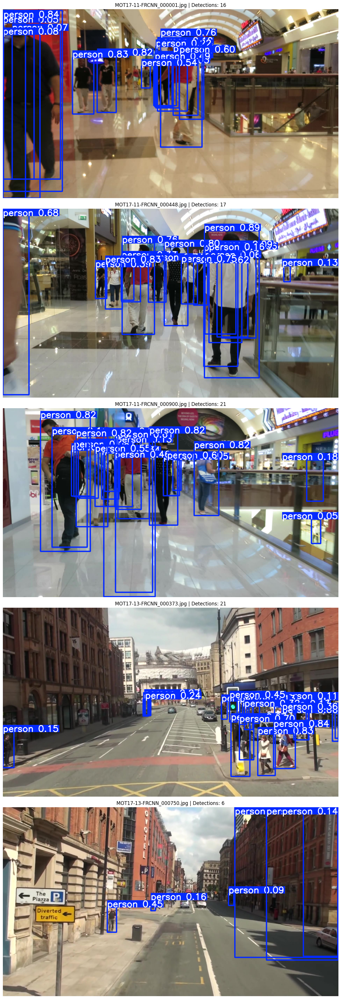


PREDICTION VISUALIZATION COMPLETE
Images processed: 5
Predictions saved: /content/VisionGuard-AI/predictions/final_test_conf005
Visualization: /content/VisionGuard-AI/predictions/final_test_conf005/five_test_predictions.png
Manifest: /content/VisionGuard-AI/predictions/final_test_conf005/prediction_manifest.json


In [23]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# Project paths
ROOT = Path("/content/VisionGuard-AI")
MODEL_PATH = ROOT / "models/final/best.pt"
TEST_IMAGES = ROOT / "dataset/processed/images/test"
OUTPUT_DIR = ROOT / "predictions/final_test_conf005"

# Verify required files
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert TEST_IMAGES.exists(), f"Test images not found: {TEST_IMAGES}"

images = sorted([
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

assert len(images) >= 5, f"Expected at least 5 test images, found {len(images)}"

# Select 5 deterministic test images
indices = np.linspace(0, len(images) - 1, 5, dtype=int)
selected_images = [images[i] for i in indices]

# Load final model
model = YOLO(str(MODEL_PATH))

# Run predictions
results = model.predict(
    source=[str(p) for p in selected_images],
    imgsz=640,
    conf=0.05,
    iou=0.7,
    save=True,
    save_conf=True,
    project=str(OUTPUT_DIR.parent),
    name=OUTPUT_DIR.name,
    exist_ok=True,
    device=0,
    verbose=True
)

# Save prediction manifest
manifest = {
    "model": str(MODEL_PATH),
    "split": "test",
    "confidence_threshold": 0.05,
    "nms_iou": 0.7,
    "image_size": 640,
    "selected_images": [p.name for p in selected_images],
    "prediction_count": len(results),
    "output_directory": str(OUTPUT_DIR)
}

manifest_path = OUTPUT_DIR / "prediction_manifest.json"
manifest_path.parent.mkdir(parents=True, exist_ok=True)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

# Display predictions
fig, axes = plt.subplots(5, 1, figsize=(14, 35))

for ax, result in zip(axes, results):
    plotted = result.plot()
    plotted = plotted[:, :, ::-1]  # BGR to RGB

    ax.imshow(plotted)
    ax.set_title(
        f"{Path(result.path).name} | "
        f"Detections: {len(result.boxes)}"
    )
    ax.axis("off")

plt.tight_layout()

# Save visualization
visualization_path = OUTPUT_DIR / "five_test_predictions.png"
fig.savefig(visualization_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nPREDICTION VISUALIZATION COMPLETE")
print("Images processed:", len(results))
print("Predictions saved:", OUTPUT_DIR)
print("Visualization:", visualization_path)
print("Manifest:", manifest_path)


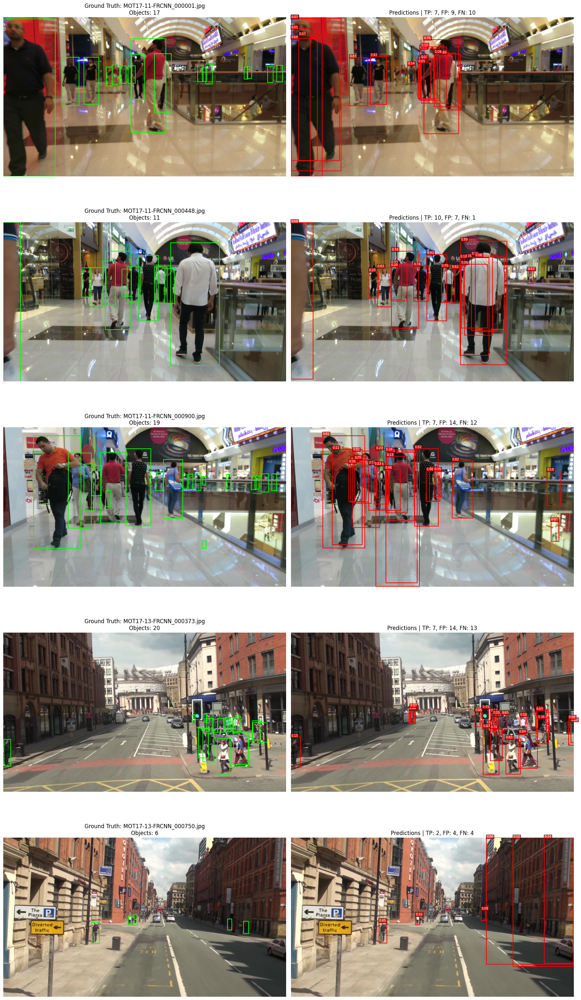


GROUND TRUTH COMPARISON COMPLETE
{'image': 'MOT17-11-FRCNN_000001.jpg', 'ground_truth': 17, 'predictions': 16, 'matched': 7, 'false_positives': 9, 'missed_objects': 10}
{'image': 'MOT17-11-FRCNN_000448.jpg', 'ground_truth': 11, 'predictions': 17, 'matched': 10, 'false_positives': 7, 'missed_objects': 1}
{'image': 'MOT17-11-FRCNN_000900.jpg', 'ground_truth': 19, 'predictions': 21, 'matched': 7, 'false_positives': 14, 'missed_objects': 12}
{'image': 'MOT17-13-FRCNN_000373.jpg', 'ground_truth': 20, 'predictions': 21, 'matched': 7, 'false_positives': 14, 'missed_objects': 13}
{'image': 'MOT17-13-FRCNN_000750.jpg', 'ground_truth': 6, 'predictions': 6, 'matched': 2, 'false_positives': 4, 'missed_objects': 4}

Total GT: 73
Total predictions: 81
Total matched: 33
Total false positives: 48
Total missed: 40

Saved: /content/VisionGuard-AI/predictions/final_test_conf005/ground_truth_vs_predictions.png
Saved: /content/VisionGuard-AI/metrics/failure_case_comparison.csv


In [24]:

from pathlib import Path
import json
import csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

ROOT = Path("/content/VisionGuard-AI")
IMAGE_DIR = ROOT / "dataset/processed/images/test"
LABEL_DIR = ROOT / "dataset/processed/labels/test"
OUTPUT_DIR = ROOT / "predictions/final_test_conf005"
MODEL_PATH = ROOT / "models/final/best.pt"

with open(OUTPUT_DIR / "prediction_manifest.json") as f:
    manifest = json.load(f)

model = YOLO(str(MODEL_PATH))

def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area_a = max(0, box_a[2]-box_a[0]) * max(0, box_a[3]-box_a[1])
    area_b = max(0, box_b[2]-box_b[0]) * max(0, box_b[3]-box_b[1])

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

all_reports = []
fig, axes = plt.subplots(5, 2, figsize=(18, 32))

for row, filename in enumerate(manifest["selected_images"]):
    image_path = IMAGE_DIR / filename
    label_path = LABEL_DIR / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Load YOLO ground-truth labels
    gt_boxes = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, parts)

            x1 = (xc - bw/2) * width
            y1 = (yc - bh/2) * height
            x2 = (xc + bw/2) * width
            y2 = (yc + bh/2) * height

            gt_boxes.append([x1, y1, x2, y2])

    # Predict using selected operating threshold
    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.05,
        iou=0.7,
        device=0,
        verbose=False
    )[0]

    pred_boxes = result.boxes.xyxy.cpu().numpy().tolist()
    pred_scores = result.boxes.conf.cpu().numpy().tolist()

    # Greedy one-to-one matching at IoU >= 0.50
    candidates = []
    for pi, pred in enumerate(pred_boxes):
        for gi, gt in enumerate(gt_boxes):
            score = calculate_iou(pred, gt)
            if score >= 0.50:
                candidates.append((score, pi, gi))

    candidates.sort(reverse=True)

    matched_preds = set()
    matched_gts = set()

    for score, pi, gi in candidates:
        if pi not in matched_preds and gi not in matched_gts:
            matched_preds.add(pi)
            matched_gts.add(gi)

    tp = len(matched_preds)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - tp

    report = {
        "image": filename,
        "ground_truth": len(gt_boxes),
        "predictions": len(pred_boxes),
        "matched": tp,
        "false_positives": fp,
        "missed_objects": fn
    }
    all_reports.append(report)

    # Draw Ground Truth
    ax_gt, ax_pred = axes[row]

    ax_gt.imshow(image)
    ax_gt.set_title(f"Ground Truth: {filename}\nObjects: {len(gt_boxes)}")

    for box in gt_boxes:
        x1, y1, x2, y2 = box
        ax_gt.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=1.5, edgecolor="lime", facecolor="none"
        ))
    ax_gt.axis("off")

    # Draw predictions
    ax_pred.imshow(image)
    ax_pred.set_title(
        f"Predictions | TP: {tp}, FP: {fp}, FN: {fn}"
    )

    for box, confidence in zip(pred_boxes, pred_scores):
        x1, y1, x2, y2 = box
        ax_pred.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=1.5, edgecolor="red", facecolor="none"
        ))
        ax_pred.text(
            x1, max(0, y1-5), f"{confidence:.2f}",
            color="white", fontsize=7,
            bbox=dict(facecolor="red", alpha=0.7, pad=1)
        )
    ax_pred.axis("off")

plt.tight_layout()

comparison_path = OUTPUT_DIR / "ground_truth_vs_predictions.png"
fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

# Save failure analysis data
csv_path = ROOT / "metrics/failure_case_comparison.csv"
csv_path.parent.mkdir(parents=True, exist_ok=True)

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=all_reports[0].keys())
    writer.writeheader()
    writer.writerows(all_reports)

print("\nGROUND TRUTH COMPARISON COMPLETE")
for item in all_reports:
    print(item)

print("\nTotal GT:", sum(x["ground_truth"] for x in all_reports))
print("Total predictions:", sum(x["predictions"] for x in all_reports))
print("Total matched:", sum(x["matched"] for x in all_reports))
print("Total false positives:", sum(x["false_positives"] for x in all_reports))
print("Total missed:", sum(x["missed_objects"] for x in all_reports))
print("\nSaved:", comparison_path)
print("Saved:", csv_path)


In [25]:

from pathlib import Path
import json

ROOT = Path("/content/VisionGuard-AI")

REPORT_DIR = ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

failure_report = {
    "project": "VisionGuard-AI",
    "analysis_type": "Qualitative failure analysis",
    "dataset": "Custom sequence-wise MOT17 test split",
    "sampled_test_images": 5,
    "matching_iou_threshold": 0.50,

    "sample_summary": {
        "ground_truth_objects": 73,
        "predictions": 81,
        "matched_true_positives": 33,
        "false_positives": 48,
        "false_negatives": 40
    },

    "failure_cases": [
        {
            "image": "MOT17-11-FRCNN_000900.jpg",
            "category": "Crowded scene and overlapping pedestrians",
            "ground_truth": 19,
            "predictions": 21,
            "matched": 7,
            "false_positives": 14,
            "missed_objects": 12,
            "likely_causes": [
                "Pedestrian overlap and occlusion",
                "Difficult localization in crowded regions",
                "Confusion between nearby pedestrians"
            ],
            "practical_next_step": "Inspect difficult crowded examples and evaluate higher-resolution training."
        },
        {
            "image": "MOT17-13-FRCNN_000373.jpg",
            "category": "Small and distant pedestrians",
            "ground_truth": 20,
            "predictions": 21,
            "matched": 7,
            "false_positives": 14,
            "missed_objects": 13,
            "likely_causes": [
                "Small pedestrian bounding boxes",
                "Distant objects with limited visual detail",
                "Dense pedestrian groups"
            ],
            "practical_next_step": "Investigate multi-scale training and small-object detection."
        },
        {
            "image": "MOT17-13-FRCNN_000750.jpg",
            "category": "Background false detections and localization errors",
            "ground_truth": 6,
            "predictions": 6,
            "matched": 2,
            "false_positives": 4,
            "missed_objects": 4,
            "likely_causes": [
                "Background confusion",
                "Inaccurate bounding box localization",
                "Low visual detail for distant pedestrians"
            ],
            "practical_next_step": "Inspect background hard negatives and bounding box localization errors."
        }
    ],

    "limitations": [
        "The analysis uses only five sampled test images.",
        "Failure counts are based on one-to-one matching at IoU 0.50.",
        "These sample counts must not be interpreted as full test-set metrics.",
        "The test set is not used for further model tuning."
    ]
}

json_path = REPORT_DIR / "failure_analysis.json"

with open(json_path, "w") as f:
    json.dump(failure_report, f, indent=4)

markdown = """# VisionGuard-AI — Failure Case Analysis

## Method
Five sampled test images were compared against their ground-truth annotations.
Predictions were matched one-to-one using IoU >= 0.50.

## Sample Summary

| Metric | Count |
|---|---:|
| Ground-truth objects | 73 |
| Predictions | 81 |
| Matched predictions | 33 |
| False positives | 48 |
| Missed objects | 40 |

## Failure Case 1: Crowded Scenes
Image: `MOT17-11-FRCNN_000900.jpg`

Likely issues include pedestrian overlap, occlusion and difficult localization.

Practical next step: Inspect crowded examples and investigate higher-resolution training.

## Failure Case 2: Small and Distant Pedestrians
Image: `MOT17-13-FRCNN_000373.jpg`

Small objects and dense pedestrian groups may contribute to missed detections.

Practical next step: Investigate multi-scale training and small-object detection.

## Failure Case 3: Background False Detections
Image: `MOT17-13-FRCNN_000750.jpg`

Some predictions do not align with ground-truth pedestrians and show inaccurate localization.

Practical next step: Inspect hard-negative background examples and localization errors.

## Limitations
This is a qualitative analysis of five sampled test images, not the complete test set.
No further model tuning is performed using the test set.
"""

md_path = REPORT_DIR / "failure_analysis.md"
md_path.write_text(markdown)

print("FAILURE ANALYSIS REPORTS SAVED")
print(json_path)
print(md_path)


FAILURE ANALYSIS REPORTS SAVED
/content/VisionGuard-AI/reports/failure_analysis.json
/content/VisionGuard-AI/reports/failure_analysis.md


In [26]:

from pathlib import Path
import json

ROOT = Path("/content/VisionGuard-AI")

checks = {
    "Academic baseline": [
        "runs/baseline/results.csv",
        "models/baseline/best.pt",
        "reports/baseline_training_report.json"
    ],
    "Academic controlled experiment": [
        "runs/experiment_02/results.csv",
        "models/experiment/experiment_02_best.pt",
        "reports/experiment_02_report.json"
    ],
    "YOLO11n refined": [
        "runs/yolo11n_refined/results.csv",
        "models/refined/best.pt",
        "reports/yolo11n_refined_report.json"
    ],
    "YOLO11s": [
        "runs/yolo11s/results.csv",
        "models/yolo11s/best.pt",
        "reports/yolo11s_training_report.json"
    ],
    "YOLO11s LR tuned": [
        "runs/yolo11s_lr_tuned/results.csv",
        "models/yolo11s_lr_tuned/best.pt",
        "reports/yolo11s_lr_tuned_report.json"
    ],
    "Final test evaluation": [
        "reports/final_test_evaluation.json",
        "metrics/standardized_model_comparison.csv",
        "reports/final_model_selection.json"
    ],
    "Prediction and failure evidence": [
        "predictions/final_test_conf005/five_test_predictions.png",
        "predictions/final_test_conf005/ground_truth_vs_predictions.png",
        "reports/failure_analysis.json",
        "reports/failure_analysis.md"
    ]
}

print("=" * 65)
print("VISIONGUARD-AI — FINAL EVIDENCE AUDIT")
print("=" * 65)

missing = []

for section, files in checks.items():
    print(f"\n{section}")
    for relative_path in files:
        path = ROOT / relative_path
        exists = path.exists()
        status = "OK" if exists else "MISSING"
        print(f"  [{status}] {relative_path}")
        if not exists:
            missing.append(relative_path)

print("\n" + "=" * 65)
print("TOTAL REQUIRED FILES:", sum(map(len, checks.values())))
print("MISSING FILES:", len(missing))

if missing:
    print("\nFiles requiring attention:")
    for item in missing:
        print("-", item)
else:
    print("\nAll audited evidence files are present.")

print("=" * 65)


VISIONGUARD-AI — FINAL EVIDENCE AUDIT

Academic baseline
  [OK] runs/baseline/results.csv
  [OK] models/baseline/best.pt
  [OK] reports/baseline_training_report.json

Academic controlled experiment
  [OK] runs/experiment_02/results.csv
  [OK] models/experiment/experiment_02_best.pt
  [OK] reports/experiment_02_report.json

YOLO11n refined
  [OK] runs/yolo11n_refined/results.csv
  [OK] models/refined/best.pt
  [OK] reports/yolo11n_refined_report.json

YOLO11s
  [OK] runs/yolo11s/results.csv
  [OK] models/yolo11s/best.pt
  [OK] reports/yolo11s_training_report.json

YOLO11s LR tuned
  [OK] runs/yolo11s_lr_tuned/results.csv
  [OK] models/yolo11s_lr_tuned/best.pt
  [OK] reports/yolo11s_lr_tuned_report.json

Final test evaluation
  [OK] reports/final_test_evaluation.json
  [OK] metrics/standardized_model_comparison.csv
  [OK] reports/final_model_selection.json

Prediction and failure evidence
  [OK] predictions/final_test_conf005/five_test_predictions.png
  [OK] predictions/final_test_conf00

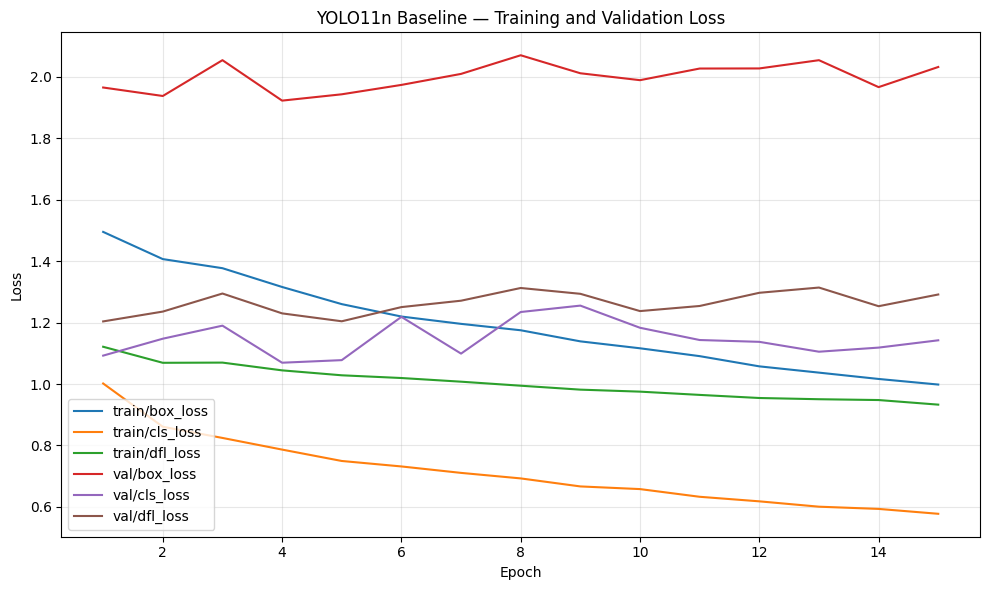

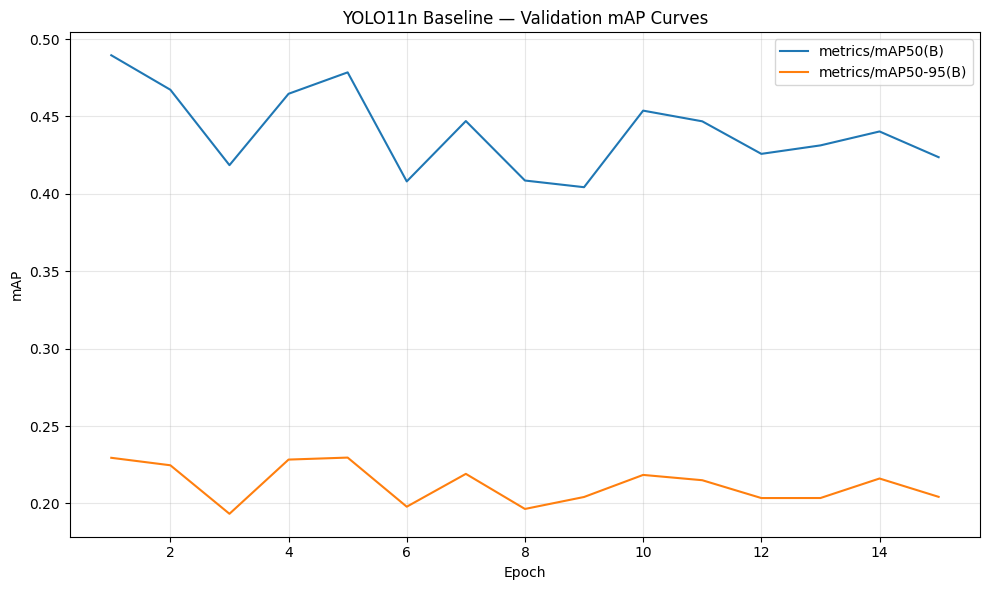

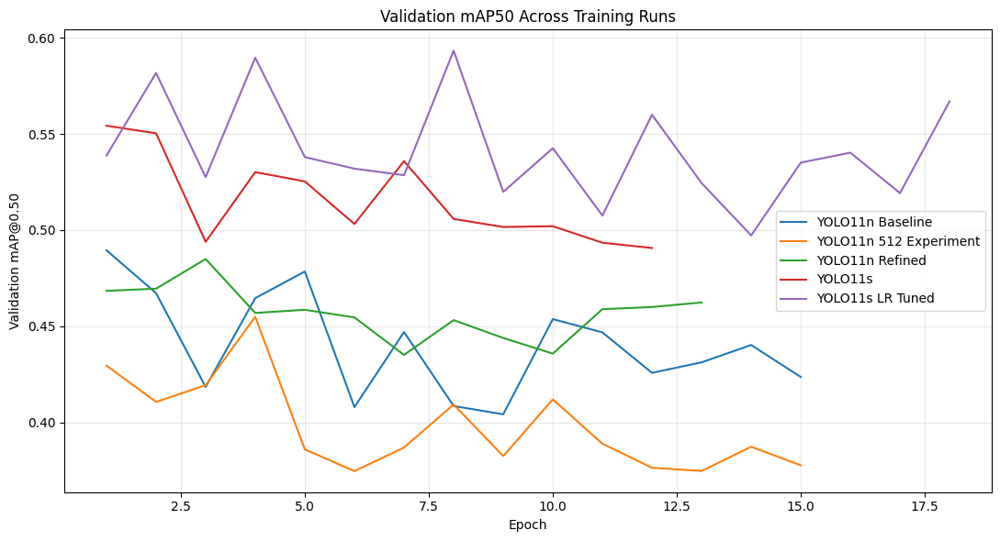


Standardized comparison columns:
['model', 'precision', 'recall', 'f1', 'mAP50', 'mAP50_95', 'checkpoint']

Available comparison data:


,model,precision,recall,f1,mAP50,mAP50_95,checkpoint
0,YOLO11s LR Tuned,0.839367,0.491002,0.619574,0.593077,0.301730,/content/VisionGuard-AI/models/yolo11s_lr_tune...
1,YOLO11s,0.754087,0.457474,0.569472,0.550434,0.268460,/content/VisionGuard-AI/models/yolo11s/best.pt
2,YOLO11n 512 Experiment,0.747800,0.442704,0.556158,0.520150,0.251766,/content/VisionGuard-AI/models/experiment/expe...
3,YOLO11n Refined,0.800129,0.421018,0.551725,0.484773,0.238260,/content/VisionGuard-AI/models/refined/best.pt
4,YOLO11n Baseline,0.753320,0.414566,0.534814,0.478606,0.229635,/content/VisionGuard-AI/models/baseline/best.pt



LEARNING CURVES GENERATED
/content/VisionGuard-AI/visualizations/all_models_map50_curves.png
/content/VisionGuard-AI/visualizations/baseline_loss_curves.png
/content/VisionGuard-AI/visualizations/baseline_map_curves.png


In [27]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

ROOT = Path("/content/VisionGuard-AI")
OUT = ROOT / "visualizations"
OUT.mkdir(parents=True, exist_ok=True)

runs = {
    "YOLO11n Baseline": "runs/baseline/results.csv",
    "YOLO11n 512 Experiment": "runs/experiment_02/results.csv",
    "YOLO11n Refined": "runs/yolo11n_refined/results.csv",
    "YOLO11s": "runs/yolo11s/results.csv",
    "YOLO11s LR Tuned": "runs/yolo11s_lr_tuned/results.csv",
}

data = {}

for name, relative_path in runs.items():
    path = ROOT / relative_path
    assert path.exists(), f"Missing CSV: {path}"

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    data[name] = df

baseline = data["YOLO11n Baseline"]

# 1. Baseline loss curves
loss_columns = [
    c for c in baseline.columns
    if "loss" in c.lower()
    and ("train" in c.lower() or "val" in c.lower())
]

if loss_columns:
    plt.figure(figsize=(10, 6))
    for col in loss_columns:
        plt.plot(baseline.index + 1, baseline[col], label=col)

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("YOLO11n Baseline — Training and Validation Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUT / "baseline_loss_curves.png", dpi=160)
    plt.show()
else:
    print("No recognizable loss columns found:", list(baseline.columns))

# 2. Baseline mAP curves
map_columns = [
    c for c in baseline.columns
    if "metrics/" in c.lower() and "map" in c.lower()
]

if map_columns:
    plt.figure(figsize=(10, 6))
    for col in map_columns:
        plt.plot(baseline.index + 1, baseline[col], label=col)

    plt.xlabel("Epoch")
    plt.ylabel("mAP")
    plt.title("YOLO11n Baseline — Validation mAP Curves")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUT / "baseline_map_curves.png", dpi=160)
    plt.show()

# 3. All models: validation mAP50
map50_col = next(
    (c for c in baseline.columns if "metrics/" in c.lower()
     and "map50(" in c.lower()),
    None
)

if map50_col:
    plt.figure(figsize=(11, 6))

    for name, df in data.items():
        col = next(
            (c for c in df.columns if "metrics/" in c.lower()
             and "map50(" in c.lower()),
            None
        )
        if col:
            plt.plot(df.index + 1, df[col], label=name)

    plt.xlabel("Epoch")
    plt.ylabel("Validation mAP@0.50")
    plt.title("Validation mAP50 Across Training Runs")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUT / "all_models_map50_curves.png", dpi=160)
    plt.show()

# 4. Final standardized model comparison
comparison_path = ROOT / "metrics/standardized_model_comparison.csv"
comparison = pd.read_csv(comparison_path)

print("\nStandardized comparison columns:")
print(comparison.columns.tolist())

print("\nAvailable comparison data:")
display(comparison)

print("\nLEARNING CURVES GENERATED")
for p in sorted(OUT.glob("*.png")):
    print(p)


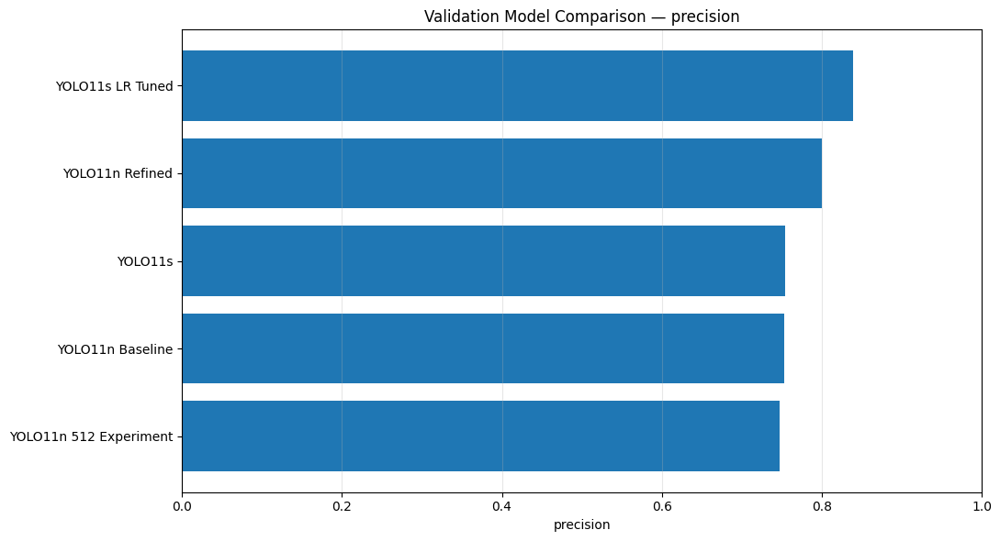

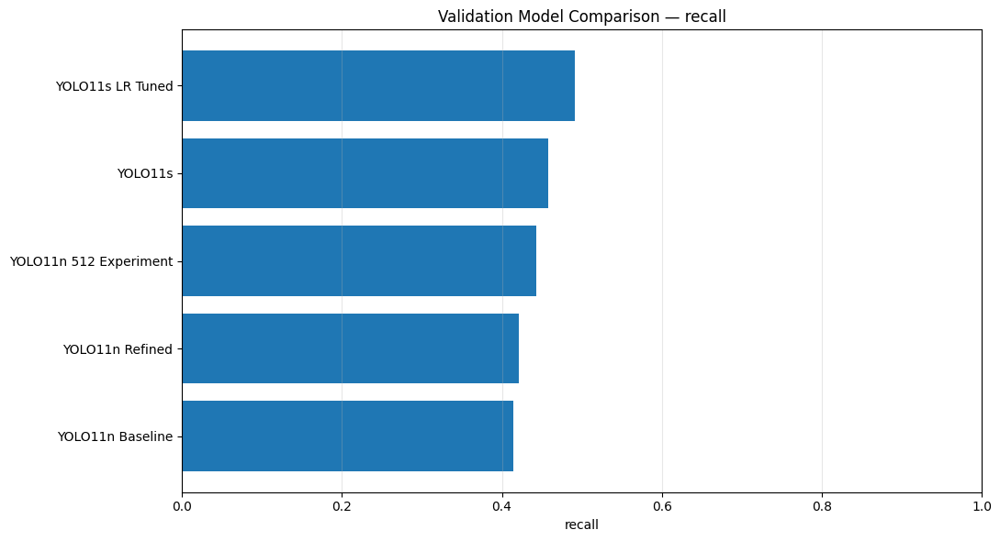

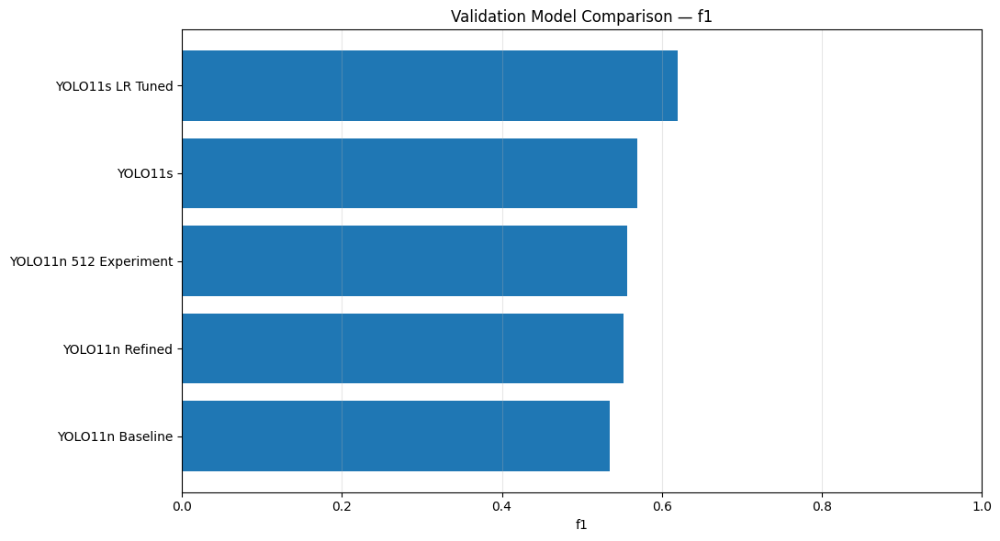

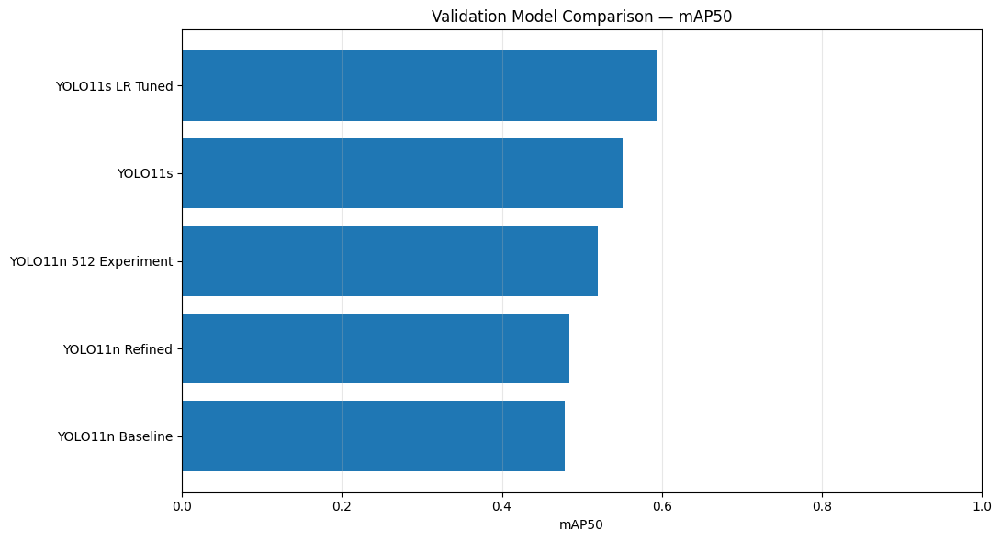

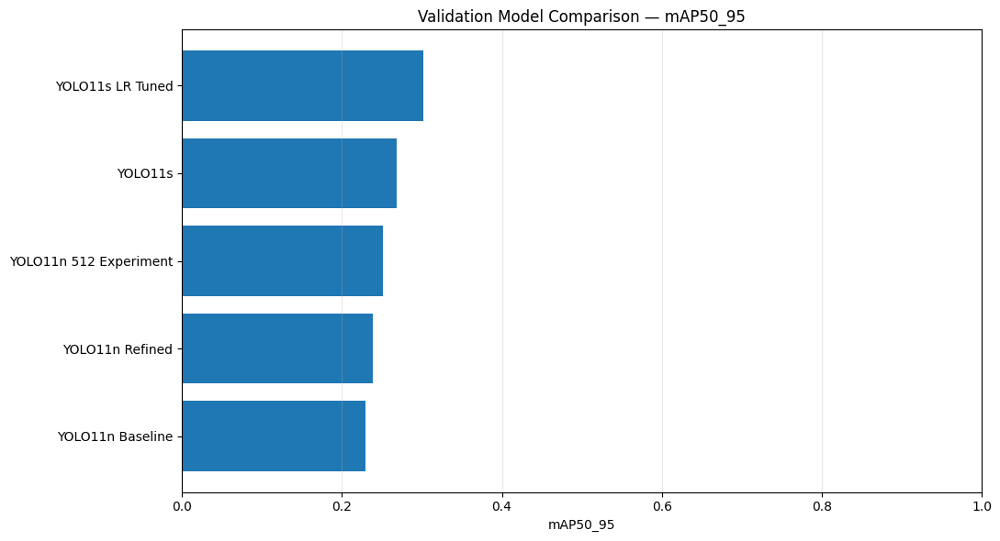

Final test report keys: ['model', 'split', 'evaluation_settings', 'metrics', 'evaluation_time_seconds', 'checkpoint', 'test_evaluated']

VALIDATION GRAPHS SAVED
/content/VisionGuard-AI/visualizations/validation_comparison_f1.png
/content/VisionGuard-AI/visualizations/validation_comparison_mAP50.png
/content/VisionGuard-AI/visualizations/validation_comparison_mAP50_95.png
/content/VisionGuard-AI/visualizations/validation_comparison_precision.png
/content/VisionGuard-AI/visualizations/validation_comparison_recall.png

Final test report loaded for separate visualization.


In [28]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

ROOT = Path("/content/VisionGuard-AI")
OUT = ROOT / "visualizations"
OUT.mkdir(parents=True, exist_ok=True)

# Standardized validation comparison
df = pd.read_csv(ROOT / "metrics/standardized_model_comparison.csv")

metrics = ["precision", "recall", "f1", "mAP50", "mAP50_95"]

# 1. Validation metric comparison
for metric in metrics:
    plt.figure(figsize=(11, 6))

    ordered = df.sort_values(metric, ascending=True)

    plt.barh(ordered["model"], ordered[metric])
    plt.xlabel(metric)
    plt.title(f"Validation Model Comparison — {metric}")
    plt.xlim(0, 1)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        OUT / f"validation_comparison_{metric}.png",
        dpi=160
    )
    plt.show()
    plt.close()

# 2. Final held-out test metrics — separate from validation
with open(ROOT / "reports/final_test_evaluation.json") as f:
    test_report = json.load(f)

print("Final test report keys:", list(test_report.keys()))
print("\nVALIDATION GRAPHS SAVED")

for path in sorted(OUT.glob("validation_comparison_*.png")):
    print(path)

print("\nFinal test report loaded for separate visualization.")


In [29]:

from pathlib import Path
import json

ROOT = Path("/content/VisionGuard-AI")

report_path = ROOT / "reports/final_test_evaluation.json"

with open(report_path) as f:
    report = json.load(f)

print("=" * 55)
print("FINAL TEST EVALUATION")
print("=" * 55)

print("\nModel:", report["model"])
print("Dataset split:", report["split"])
print("Test evaluated:", report["test_evaluated"])

print("\nEvaluation settings:")
for key, value in report["evaluation_settings"].items():
    print(f"  {key}: {value}")

print("\nFinal test metrics:")
for key, value in report["metrics"].items():
    print(f"  {key}: {value}")

print("\nEvaluation time:",
      report["evaluation_time_seconds"], "seconds")

print("\nCheckpoint:", report["checkpoint"])
print("=" * 55)


FINAL TEST EVALUATION

Model: YOLO11s LR Tuned
Dataset split: test
Test evaluated: True

Evaluation settings:
  image_size: 640
  confidence_threshold: 0.001
  nms_iou_threshold: 0.7

Final test metrics:
  precision: 0.8003348955845689
  recall: 0.4318852085400249
  f1: 0.5610244502981271
  mAP50: 0.5039471142285958
  mAP50_95: 0.3102901180164016

Evaluation time: 14.01 seconds

Checkpoint: /content/VisionGuard-AI/models/final/best.pt


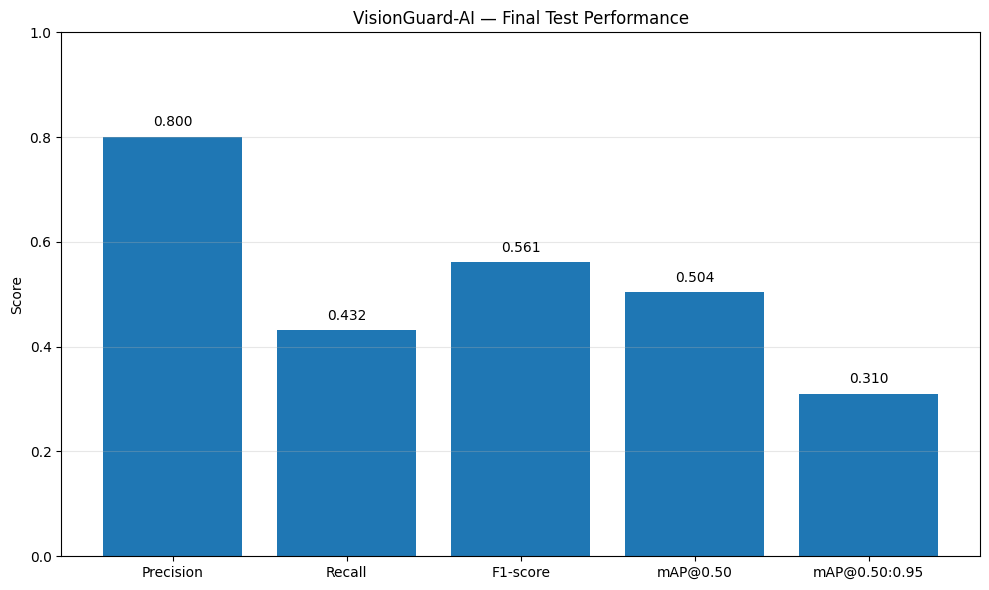

FINAL TEST GRAPH SAVED
/content/VisionGuard-AI/visualizations/final_test_metrics.png


In [36]:


# Production Model Integrity & Reproducibility Audit


from pathlib import Path
import hashlib
import json
import platform
import sys
import importlib.metadata as metadata
from datetime import datetime, timezone

import torch
import yaml
import ultralytics
from ultralytics import YOLO


PROJECT_DIR = Path("/content/VisionGuard-AI")

FINAL_MODEL = PROJECT_DIR / "models" / "final" / "best.pt"
DATA_YAML = PROJECT_DIR / "dataset" / "processed" / "data.yaml"

REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

AUDIT_REPORT = REPORT_DIR / "production_integrity_audit.json"

print("=" * 70)
print("VISIONGUARD-AI | PRODUCTION INTEGRITY AUDIT")
print("=" * 70)


# 2. SHA256 utility


def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


required_files = {
    "final_model": FINAL_MODEL,
    "dataset_config": DATA_YAML,
    "baseline_report": PROJECT_DIR / "reports" / "baseline_training_report.json",
    "final_test_report": PROJECT_DIR / "reports" / "final_test_evaluation.json",
    "model_comparison": PROJECT_DIR / "metrics" / "standardized_model_comparison.csv",
    "failure_analysis": PROJECT_DIR / "reports" / "failure_analysis.json",
    "prediction_visualization": PROJECT_DIR / "predictions" / "final_test_conf005" / "five_test_predictions.png",
}

file_audit = {}

for name, path in required_files.items():
    file_audit[name] = {
        "path": str(path),
        "exists": path.is_file(),
        "size_bytes": path.stat().st_size if path.is_file() else None,
    }

    status = "PASS" if path.is_file() else "MISSING"
    print(f"{status:8} | {name}")

assert FINAL_MODEL.is_file(), "Final model checkpoint is missing!"
assert DATA_YAML.is_file(), "Dataset configuration is missing!"


print("\nLoading final model checkpoint...")

model = YOLO(str(FINAL_MODEL))

parameter_count = sum(
    parameter.numel()
    for parameter in model.model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.model.parameters()
    if parameter.requires_grad
)

model_info = {
    "checkpoint": str(FINAL_MODEL),
    "checkpoint_size_mb": round(FINAL_MODEL.stat().st_size / (1024 ** 2), 3),
    "sha256": calculate_sha256(FINAL_MODEL),
    "architecture": "YOLO11s LR Tuned",
    "parameter_count": parameter_count,
    "trainable_parameter_count": trainable_parameters,
    "class_names": model.names,
    "number_of_classes": len(model.names),
}

print("Model loaded successfully.")
print(f"Parameters       : {parameter_count:,}")
print(f"Classes          : {model.names}")
print(f"Checkpoint size  : {model_info['checkpoint_size_mb']} MB")
print(f"SHA256           : {model_info['sha256']}")



with open(DATA_YAML, "r", encoding="utf-8") as file:
    dataset_config = yaml.safe_load(file)

dataset_path = Path(dataset_config["path"])

split_audit = {}

for split in ["train", "val", "test"]:
    image_dir = dataset_path / "images" / split
    label_dir = dataset_path / "labels" / split

    image_count = len(list(image_dir.glob("*"))) if image_dir.exists() else 0
    label_count = len(list(label_dir.glob("*.txt"))) if label_dir.exists() else 0

    split_audit[split] = {
        "image_directory_exists": image_dir.is_dir(),
        "label_directory_exists": label_dir.is_dir(),
        "image_count": image_count,
        "label_count": label_count,
    }

    print(
        f"{split.upper():5} | "
        f"Images: {image_count:4} | "
        f"Labels: {label_count:4}"
    )

dataset_audit = {
    "dataset_path": str(dataset_path),
    "class_names": dataset_config.get("names"),
    "number_of_classes": dataset_config.get("nc"),
    "splits": split_audit,
}



package_names = [
    "torch",
    "ultralytics",
    "numpy",
    "pandas",
    "opencv-python",
    "opencv-python-headless",
    "PyYAML",
    "matplotlib",
    "Pillow",
]

installed_packages = {}

for package in package_names:
    try:
        installed_packages[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed_packages[package] = None

gpu_available = torch.cuda.is_available()

runtime_audit = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_available": gpu_available,
    "gpu_name": torch.cuda.get_device_name(0) if gpu_available else None,
    "installed_packages": installed_packages,
}



all_required_files_present = all(
    item["exists"] for item in file_audit.values()
)

dataset_structure_valid = all(
    item["image_directory_exists"]
    and item["label_directory_exists"]
    and item["image_count"] > 0
    for item in split_audit.values()
)

integrity_passed = (
    all_required_files_present
    and dataset_structure_valid
    and len(model.names) == 1
)



audit_report = {
    "project": "VisionGuard-AI",
    "audit_type": "Production Model Integrity Audit",
    "audit_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "integrity_status": "PASS" if integrity_passed else "REVIEW_REQUIRED",
    "model": model_info,
    "dataset": dataset_audit,
    "runtime": runtime_audit,
    "required_files": file_audit,
}

AUDIT_REPORT.write_text(
    json.dumps(audit_report, indent=4, default=str),
    encoding="utf-8"
)


print("\n" + "=" * 70)
print("INTEGRITY AUDIT SUMMARY")
print("=" * 70)

print(f"Required files present : {all_required_files_present}")
print(f"Dataset structure      : {dataset_structure_valid}")
print(f"GPU available          : {gpu_available}")
print(f"Model classes          : {len(model.names)}")
print(f"Integrity status       : {audit_report['integrity_status']}")
print(f"\nAudit report saved to:")
print(AUDIT_REPORT)

print("\nCELL 24 COMPLETED.")


VISIONGUARD-AI | PRODUCTION INTEGRITY AUDIT
PASS     | final_model
PASS     | dataset_config
PASS     | baseline_report
PASS     | final_test_report
PASS     | model_comparison
PASS     | failure_analysis
PASS     | prediction_visualization

Loading final model checkpoint...
Model loaded successfully.
Parameters       : 9,428,179
Classes          : {0: 'person'}
Checkpoint size  : 18.263 MB
SHA256           : 0612b5df629412f28e5bd1cd1ba98c3c2987225d84ba827e0497a626f6ca7e5c
TRAIN | Images: 1200 | Labels: 1200
VAL   | Images:  400 | Labels:  400
TEST  | Images:  400 | Labels:  400

INTEGRITY AUDIT SUMMARY
Required files present : True
Dataset structure      : True
GPU available          : True
Model classes          : 1
Integrity status       : PASS

Audit report saved to:
/content/VisionGuard-AI/reports/production_integrity_audit.json

CELL 24 COMPLETED.


Image: MOT17-11-FRCNN_000001.jpg
Detections: 16
Inference time: 297.73 ms
Report: /content/VisionGuard-AI/predictions/production_inference/smoke_test_result.json


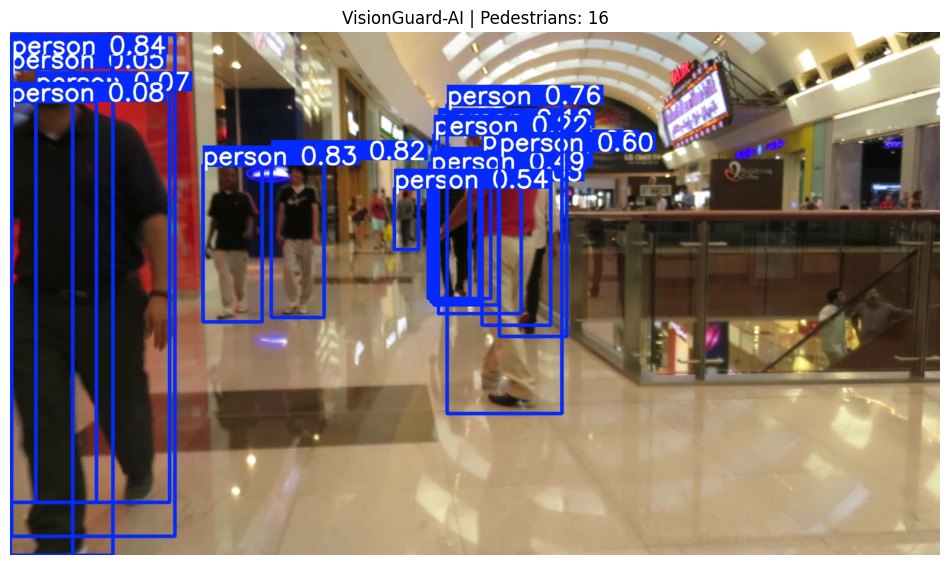

CELL 25 COMPLETED.


In [37]:

from pathlib import Path
from datetime import datetime, timezone
import json
import time

import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path("/content/VisionGuard-AI")
MODEL_PATH = PROJECT_DIR / "models/final/best.pt"
OUTPUT_DIR = PROJECT_DIR / "predictions/production_inference"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 640
DEFAULT_CONFIDENCE = 0.05
DEFAULT_IOU = 0.70
MAX_DETECTIONS = 300
DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert MODEL_PATH.is_file(), "Final model checkpoint not found."

model = YOLO(str(MODEL_PATH))

SUPPORTED_FORMATS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def validate_image(image_path):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    if image_path.suffix.lower() not in SUPPORTED_FORMATS:
        raise ValueError(f"Unsupported format: {image_path.suffix}")

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Invalid image: {image_path}")

    return image_path, image


def infer_image(
    image_path,
    confidence=DEFAULT_CONFIDENCE,
    iou=DEFAULT_IOU,
    save_visualization=True
):
    if not 0.0 <= confidence <= 1.0:
        raise ValueError("Confidence must be between 0 and 1.")

    if not 0.0 < iou <= 1.0:
        raise ValueError("IoU must be greater than 0 and at most 1.")

    image_path, original_image = validate_image(image_path)

    start_time = time.perf_counter()

    results = model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=confidence,
        iou=iou,
        max_det=MAX_DETECTIONS,
        device=DEVICE,
        verbose=False
    )

    inference_time = time.perf_counter() - start_time
    result = results[0]
    detections = []

    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())

            detections.append({
                "class_id": class_id,
                "class_name": model.names[class_id],
                "confidence": round(float(box.conf.item()), 5),
                "bounding_box_xyxy": [
                    round(float(value), 2)
                    for value in box.xyxy[0].tolist()
                ]
            })

    visualization_path = None

    if save_visualization:
        visualization_path = (
            OUTPUT_DIR / f"{image_path.stem}_prediction.jpg"
        )

        if not cv2.imwrite(
            str(visualization_path),
            result.plot()
        ):
            raise RuntimeError("Failed to save prediction image.")

    return {
        "project": "VisionGuard-AI",
        "image": image_path.name,
        "image_width": int(original_image.shape[1]),
        "image_height": int(original_image.shape[0]),
        "model": "YOLO11s LR Tuned",
        "confidence_threshold": confidence,
        "nms_iou_threshold": iou,
        "total_detections": len(detections),
        "inference_time_ms": round(inference_time * 1000, 2),
        "detections": detections,
        "visualization": (
            str(visualization_path)
            if visualization_path else None
        ),
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }


def infer_batch(
    image_paths,
    confidence=DEFAULT_CONFIDENCE,
    iou=DEFAULT_IOU
):
    if not image_paths:
        raise ValueError("Image list cannot be empty.")

    results = []
    errors = []

    for image_path in image_paths:
        try:
            results.append(
                infer_image(image_path, confidence, iou)
            )
        except (FileNotFoundError, ValueError, RuntimeError) as error:
            errors.append({
                "image": str(image_path),
                "error": str(error)
            })

    return {
        "total_images": len(image_paths),
        "successful_images": len(results),
        "failed_images": len(errors),
        "results": results,
        "errors": errors
    }


test_image_dir = (
    PROJECT_DIR / "dataset/processed/images/test"
)

test_images = sorted(
    path for path in test_image_dir.iterdir()
    if path.is_file()
    and path.suffix.lower() in SUPPORTED_FORMATS
)

assert test_images, "No test images found."

smoke_result = infer_image(test_images[0])

json_path = OUTPUT_DIR / "smoke_test_result.json"
json_path.write_text(
    json.dumps(smoke_result, indent=4),
    encoding="utf-8"
)

print(f"Image: {smoke_result['image']}")
print(f"Detections: {smoke_result['total_detections']}")
print(f"Inference time: {smoke_result['inference_time_ms']} ms")
print(f"Report: {json_path}")

visualization = cv2.imread(smoke_result["visualization"])
visualization = cv2.cvtColor(visualization, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(visualization)
plt.title(
    f"VisionGuard-AI | Pedestrians: "
    f"{smoke_result['total_detections']}"
)
plt.axis("off")
plt.show()

print("CELL 25 COMPLETED.")


In [38]:

from pathlib import Path
import json
import time

import numpy as np
import torch
import pandas as pd
from ultralytics import YOLO

PROJECT_DIR = Path("/content/VisionGuard-AI")
MODEL_PATH = PROJECT_DIR / "models/final/best.pt"
TEST_DIR = PROJECT_DIR / "dataset/processed/images/test"

OUTPUT_DIR = PROJECT_DIR / "metrics/production_benchmark"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 640
CONFIDENCE = 0.05
IOU = 0.70

BATCH_SIZES = [1, 4, 8, 16]
MAX_IMAGES = 32
REPEATS = 3
WARMUP_RUNS = 2

DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert MODEL_PATH.is_file(), "Final model not found."

model = YOLO(str(MODEL_PATH))

image_paths = sorted(
    path for path in TEST_DIR.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)[:MAX_IMAGES]

assert image_paths, "No test images available."

def synchronize():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def run_inference(paths):
    return model.predict(
        source=[str(path) for path in paths],
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE,
        iou=IOU,
        device=DEVICE,
        verbose=False,
        stream=False
    )

benchmark_results = []

print("=" * 65)
print("VISIONGUARD-AI | PERFORMANCE BENCHMARK")
print("=" * 65)

print(f"Model: {MODEL_PATH.name}")
print(f"Device: {DEVICE}")
print(f"Images: {len(image_paths)}")
print(f"Batch sizes: {BATCH_SIZES}")

for batch_size in BATCH_SIZES:
    print(f"\nTesting batch size: {batch_size}")

    latencies = []
    total_images = 0
    peak_memory_mb = None

    try:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

        batches = [
            image_paths[i:i + batch_size]
            for i in range(0, len(image_paths), batch_size)
        ]

        for _ in range(WARMUP_RUNS):
            run_inference(batches[0])
            synchronize()

        for _ in range(REPEATS):
            for batch in batches:
                synchronize()
                start_time = time.perf_counter()

                run_inference(batch)

                synchronize()
                elapsed = time.perf_counter() - start_time

                latencies.append(elapsed)
                total_images += len(batch)

        total_time = sum(latencies)

        if torch.cuda.is_available():
            peak_memory_mb = round(
                torch.cuda.max_memory_allocated() / (1024 ** 2),
                2
            )

        result = {
            "batch_size": batch_size,
            "images_processed": total_images,
            "total_time_seconds": round(total_time, 4),
            "average_batch_latency_ms": round(
                np.mean(latencies) * 1000, 2
            ),
            "p95_batch_latency_ms": round(
                np.percentile(latencies, 95) * 1000, 2
            ),
            "throughput_images_per_second": round(
                total_images / total_time, 2
            ),
            "peak_gpu_memory_mb": peak_memory_mb,
            "status": "success"
        }

        benchmark_results.append(result)

        print(
            f"Throughput: {result['throughput_images_per_second']} images/sec"
        )
        print(
            f"Average batch latency: "
            f"{result['average_batch_latency_ms']} ms"
        )
        print(f"Peak GPU memory: {peak_memory_mb} MB")

    except RuntimeError as error:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        benchmark_results.append({
            "batch_size": batch_size,
            "status": "failed",
            "error": str(error)[:500]
        })

        print(f"Batch size {batch_size} failed: {error}")

# Save benchmark results
results_df = pd.DataFrame(benchmark_results)

csv_path = OUTPUT_DIR / "performance_benchmark.csv"
json_path = OUTPUT_DIR / "performance_benchmark.json"

results_df.to_csv(csv_path, index=False)

report = {
    "project": "VisionGuard-AI",
    "model": "YOLO11s LR Tuned",
    "image_size": IMAGE_SIZE,
    "confidence_threshold": CONFIDENCE,
    "nms_iou_threshold": IOU,
    "device": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "benchmark_images": len(image_paths),
    "warmup_runs": WARMUP_RUNS,
    "repeats": REPEATS,
    "results": benchmark_results
}

json_path.write_text(
    json.dumps(report, indent=4),
    encoding="utf-8"
)

successful = [
    item for item in benchmark_results
    if item["status"] == "success"
]

if successful:
    best_throughput = max(
        successful,
        key=lambda item: item["throughput_images_per_second"]
    )

    print("\n" + "=" * 65)
    print("BENCHMARK SUMMARY")
    print("=" * 65)

    print(f"Best throughput batch size: {best_throughput['batch_size']}")
    print(
        f"Maximum throughput: "
        f"{best_throughput['throughput_images_per_second']} images/sec"
    )

print(f"\nCSV report: {csv_path}")
print(f"JSON report: {json_path}")
print("\nCELL 26 COMPLETED.")


VISIONGUARD-AI | PERFORMANCE BENCHMARK
Model: best.pt
Device: 0
Images: 32
Batch sizes: [1, 4, 8, 16]

Testing batch size: 1
Throughput: 10.66 images/sec
Average batch latency: 93.85 ms
Peak GPU memory: 184.93 MB

Testing batch size: 4
Throughput: 40.55 images/sec
Average batch latency: 98.65 ms
Peak GPU memory: 261.86 MB

Testing batch size: 8
Throughput: 38.14 images/sec
Average batch latency: 209.76 ms
Peak GPU memory: 366.99 MB

Testing batch size: 16
Throughput: 43.13 images/sec
Average batch latency: 370.98 ms
Peak GPU memory: 565.71 MB

BENCHMARK SUMMARY
Best throughput batch size: 16
Maximum throughput: 43.13 images/sec

CSV report: /content/VisionGuard-AI/metrics/production_benchmark/performance_benchmark.csv
JSON report: /content/VisionGuard-AI/metrics/production_benchmark/performance_benchmark.json

CELL 26 COMPLETED.


In [40]:

from pathlib import Path
import json
import shutil
import zipfile
from datetime import datetime, timezone

PROJECT_DIR = Path("/content/VisionGuard-AI")
PACKAGE_DIR = PROJECT_DIR / "deployment"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

PACKAGE_ZIP = PROJECT_DIR / "VisionGuard_AI_Deployment.zip"

artifact_paths = [
    PROJECT_DIR / "models/final/best.pt",
    PACKAGE_DIR / "inference_config.json",
    PACKAGE_DIR / "MODEL_CARD.md",
    PROJECT_DIR / "reports/final_test_evaluation.json",
    PROJECT_DIR / "reports/production_integrity_audit.json",
    PROJECT_DIR / "metrics/production_benchmark/performance_benchmark.json",
    PROJECT_DIR / "reports/failure_analysis.json",
    PROJECT_DIR / "metrics/standardized_model_comparison.csv",
    PROJECT_DIR / "metrics/confidence_threshold_comparison.csv",
    PROJECT_DIR / "configs/baseline_config.json",
    PROJECT_DIR / "configs/dependencies.json",
    PROJECT_DIR / "requirements-colab.txt",
]

included_files = []

for source in artifact_paths:
    if not source.is_file():
        print(f"SKIPPED: {source.name}")
        continue

    destination = PACKAGE_DIR / source.name

    if source.resolve() != destination.resolve():
        shutil.copy2(source, destination)

    included_files.append(destination)

if PACKAGE_ZIP.exists():
    PACKAGE_ZIP.unlink()

with zipfile.ZipFile(
    PACKAGE_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for file_path in included_files:
        archive.write(file_path, arcname=file_path.name)

with zipfile.ZipFile(PACKAGE_ZIP, "r") as archive:
    bad_file = archive.testzip()
    archive_contents = archive.namelist()

assert bad_file is None, f"Archive verification failed: {bad_file}"
assert "best.pt" in archive_contents, "Model checkpoint missing from package."

summary = {
    "project": "VisionGuard-AI",
    "model": "YOLO11s LR Tuned",
    "package_path": str(PACKAGE_ZIP),
    "package_size_mb": round(
        PACKAGE_ZIP.stat().st_size / (1024 ** 2), 2
    ),
    "files_included": archive_contents,
    "archive_verified": True,
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

(PACKAGE_DIR / "deployment_summary.json").write_text(
    json.dumps(summary, indent=4),
    encoding="utf-8"
)

print("=" * 60)
print("VISIONGUARD-AI | DEPLOYMENT PACKAGE")
print("=" * 60)
print(f"Files included: {len(archive_contents)}")
print(f"Package size: {summary['package_size_mb']} MB")
print(f"Archive verified: {not bool(bad_file)}")
print(f"Package: {PACKAGE_ZIP}")
print("CELL 27 COMPLETED.")


VISIONGUARD-AI | DEPLOYMENT PACKAGE
Files included: 12
Package size: 16.81 MB
Archive verified: True
Package: /content/VisionGuard-AI/VisionGuard_AI_Deployment.zip
CELL 27 COMPLETED.


Total visual files found: 190


### BoxPR_curve.png

`runs/baseline/BoxPR_curve.png`

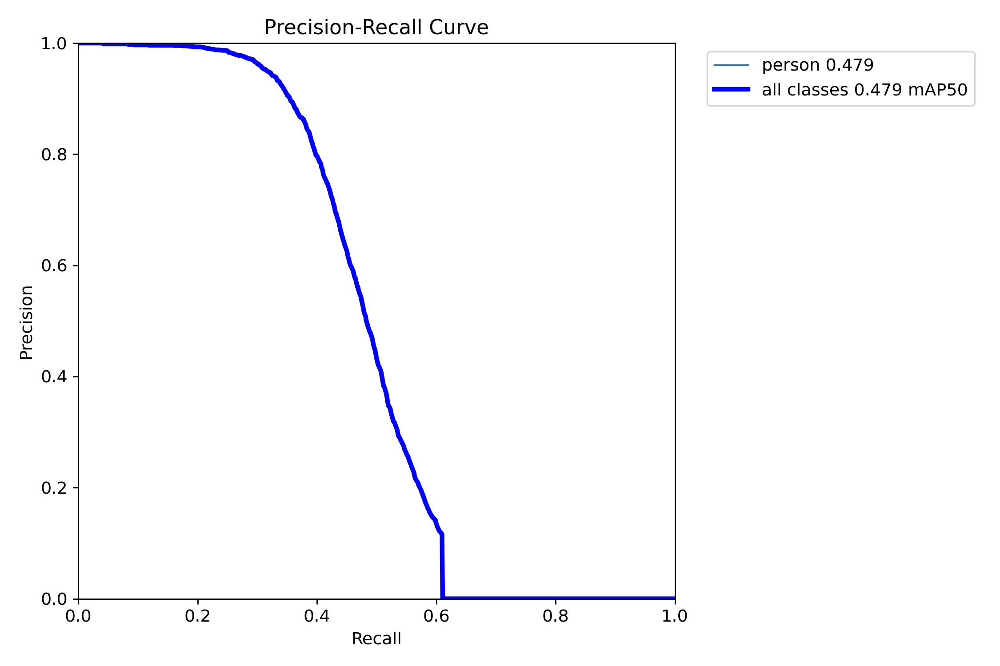

### BoxPR_curve.png

`runs/experiment_02/BoxPR_curve.png`

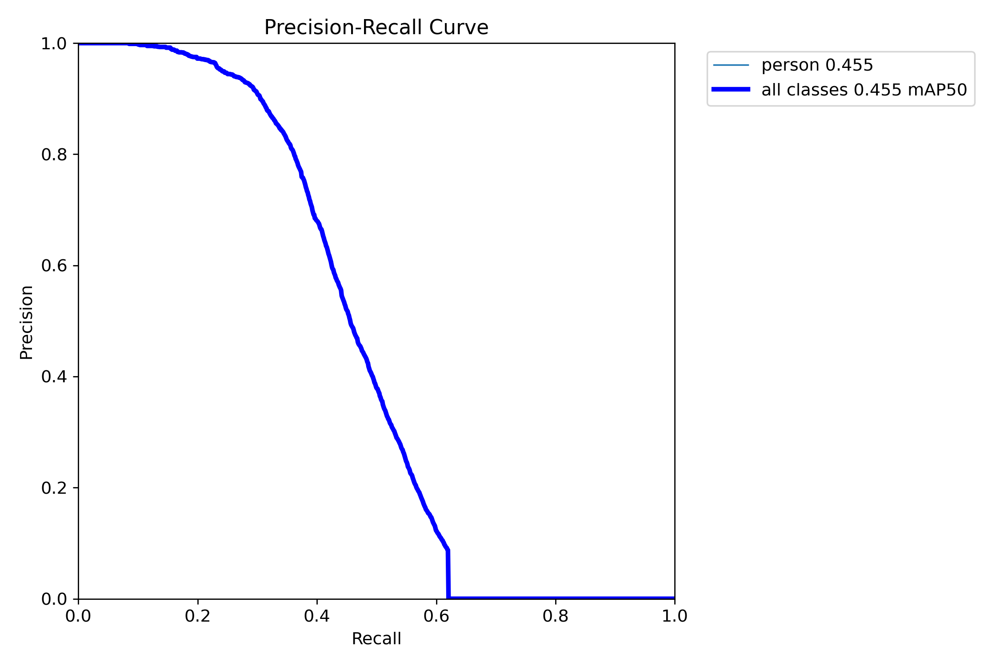

### BoxPR_curve.png

`runs/final_test_evaluation/BoxPR_curve.png`

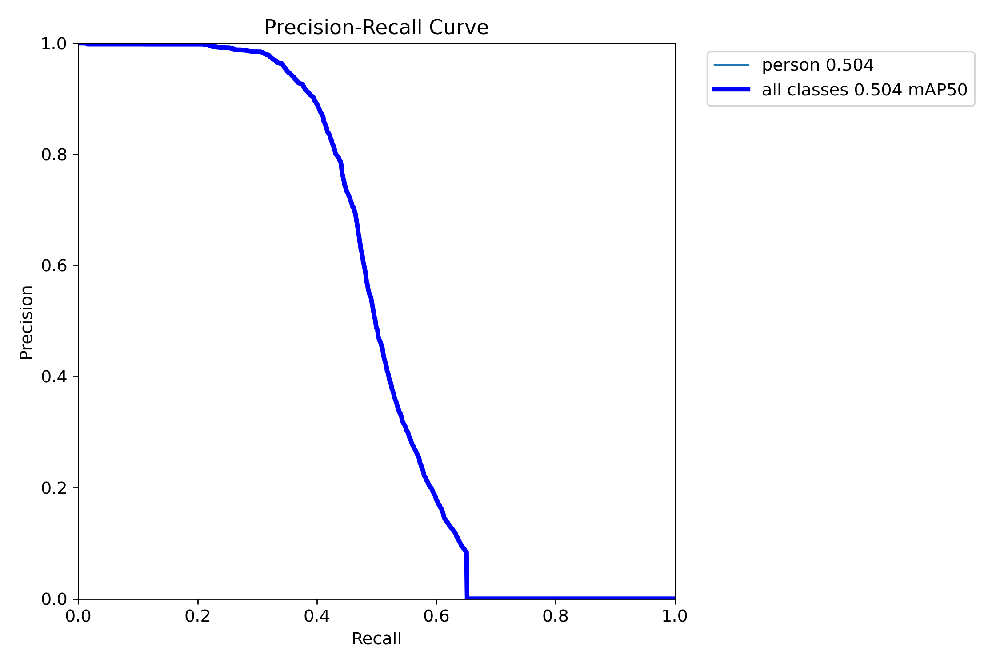

### BoxPR_curve.png

`runs/standardized_validation/yolo11n_512_experiment/BoxPR_curve.png`

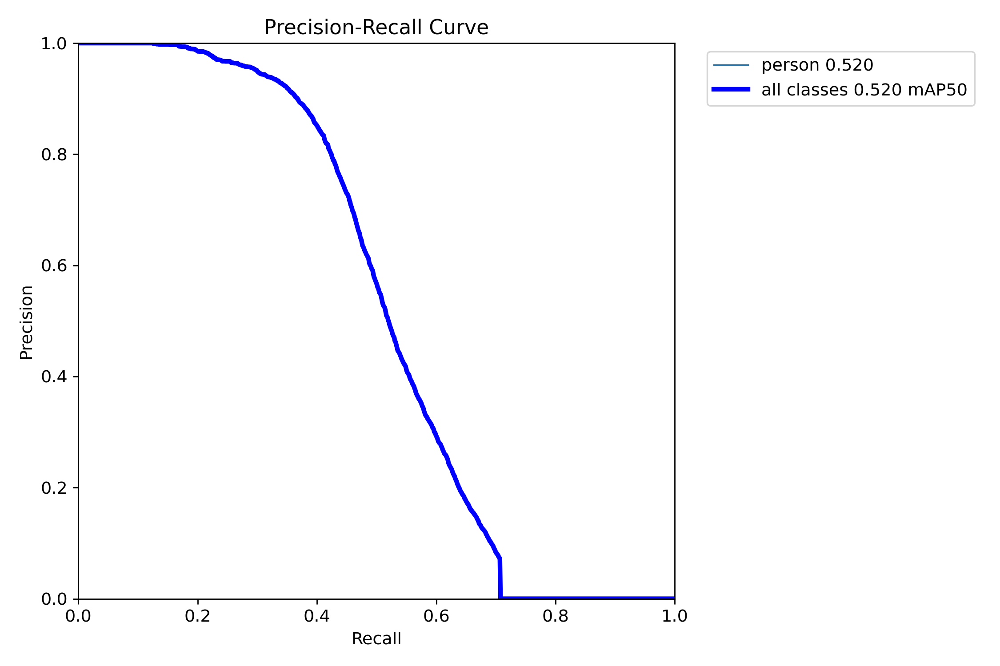

### BoxPR_curve.png

`runs/standardized_validation/yolo11n_baseline/BoxPR_curve.png`

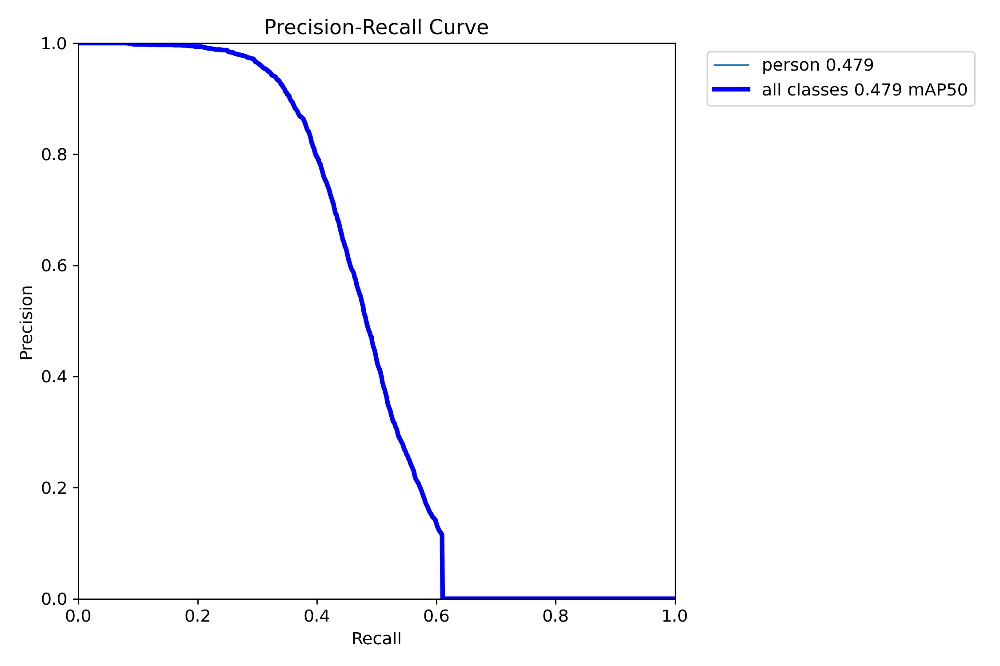

### BoxPR_curve.png

`runs/standardized_validation/yolo11n_refined/BoxPR_curve.png`

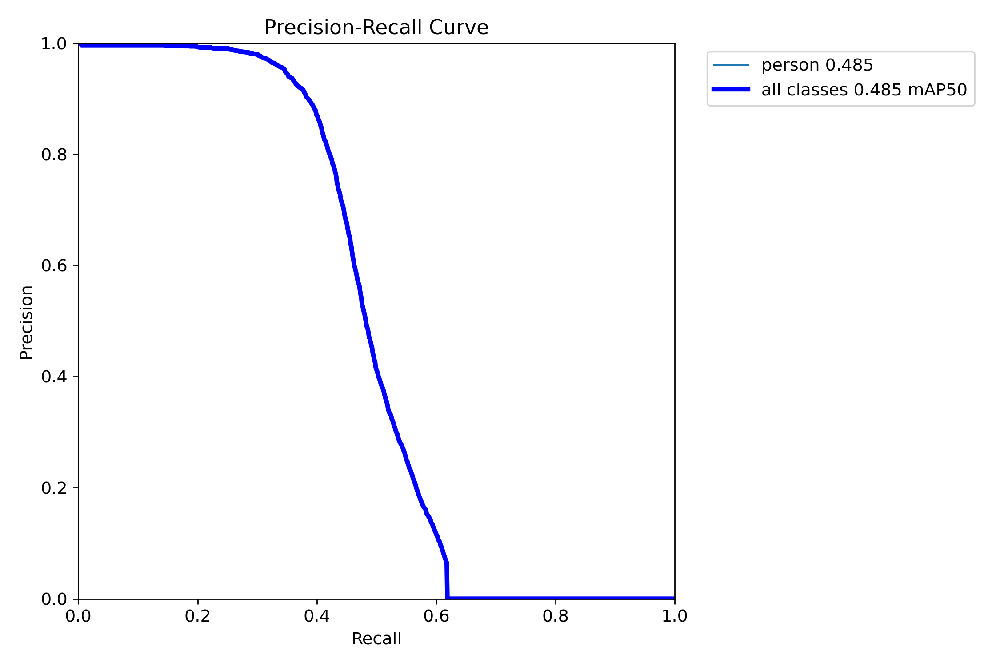

### BoxPR_curve.png

`runs/standardized_validation/yolo11s/BoxPR_curve.png`

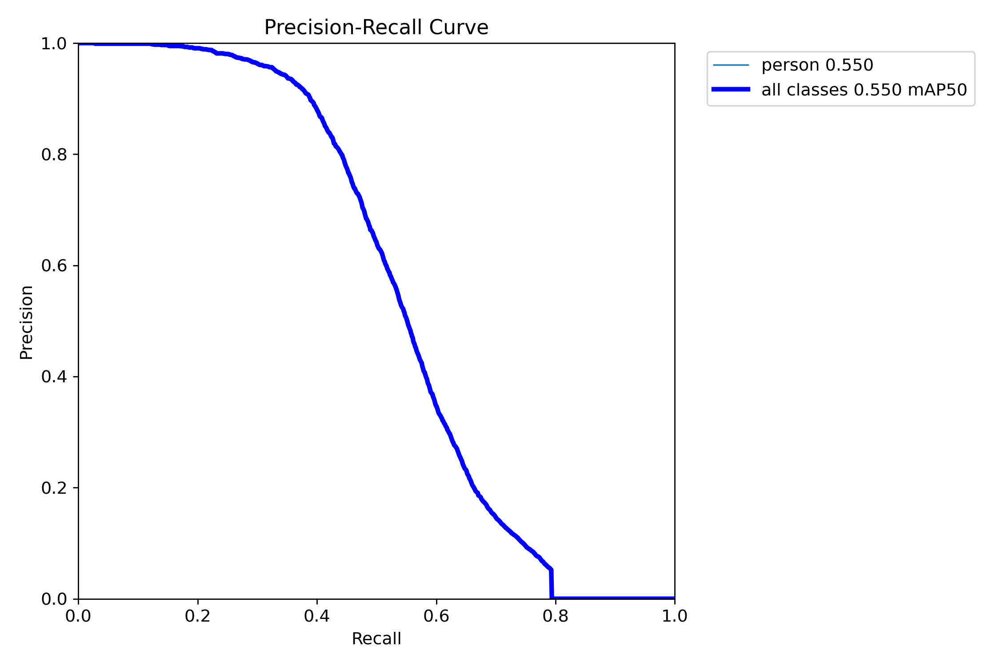

### BoxPR_curve.png

`runs/standardized_validation/yolo11s_lr_tuned/BoxPR_curve.png`

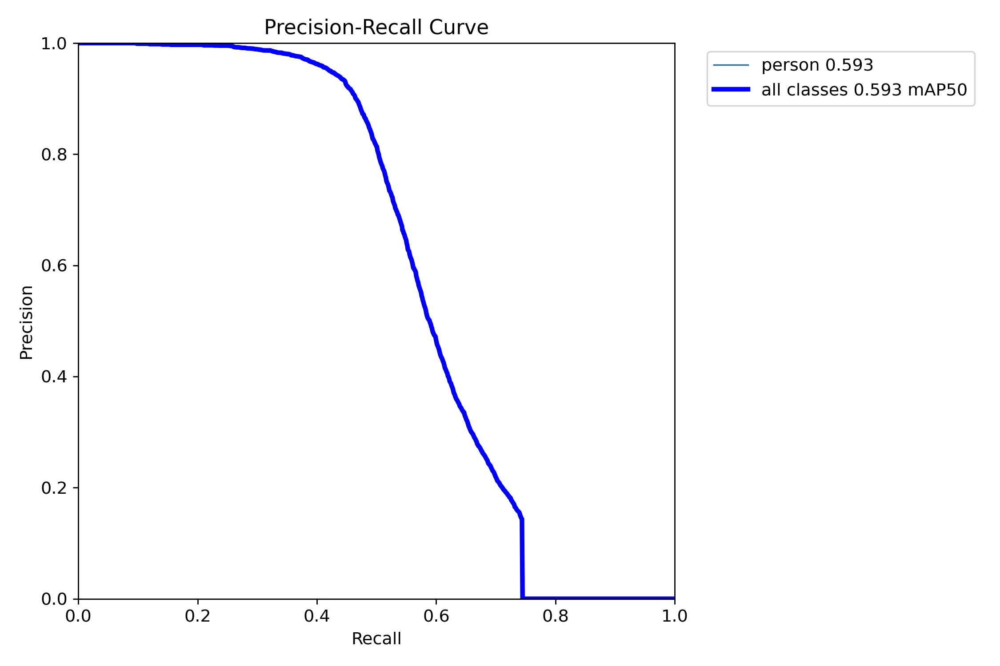

### BoxPR_curve.png

`runs/yolo11n_refined/BoxPR_curve.png`

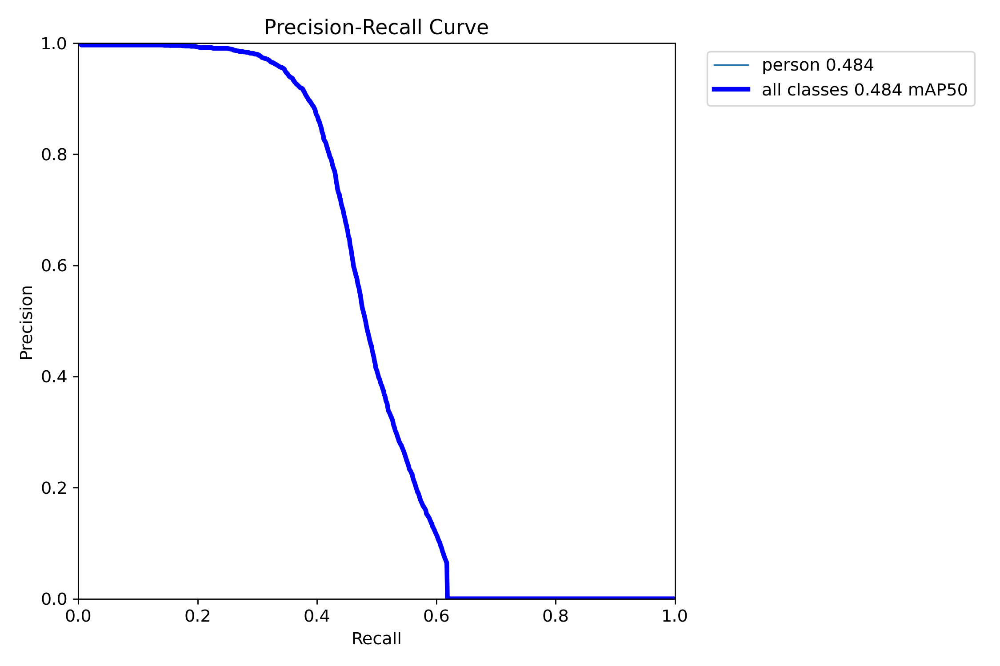

### BoxPR_curve.png

`runs/yolo11s/BoxPR_curve.png`

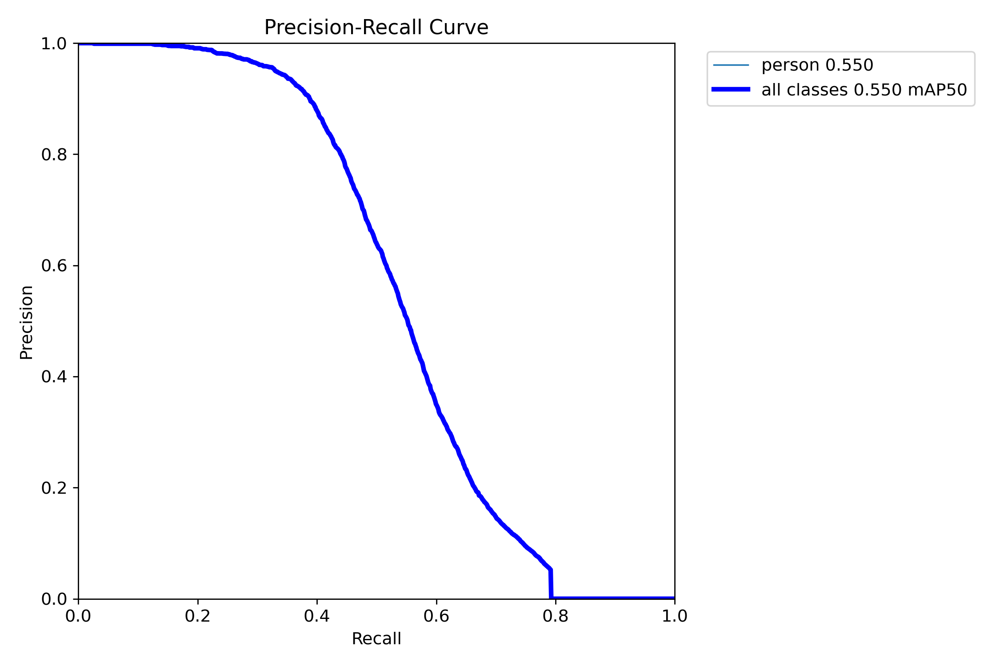

### BoxPR_curve.png

`runs/yolo11s_lr_tuned/BoxPR_curve.png`

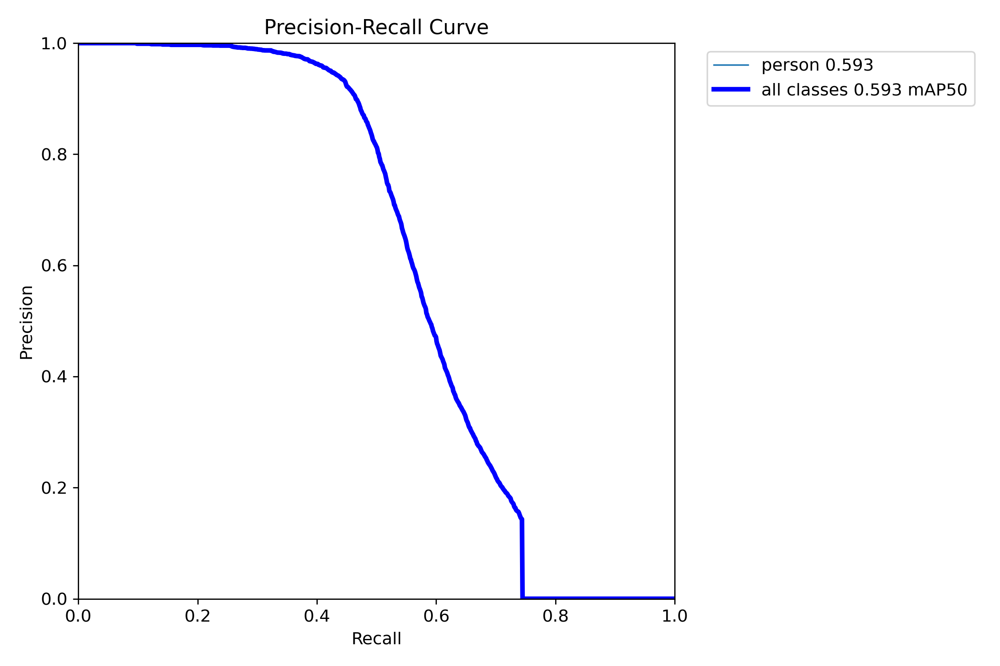

### confusion_matrix.png

`runs/baseline/confusion_matrix.png`

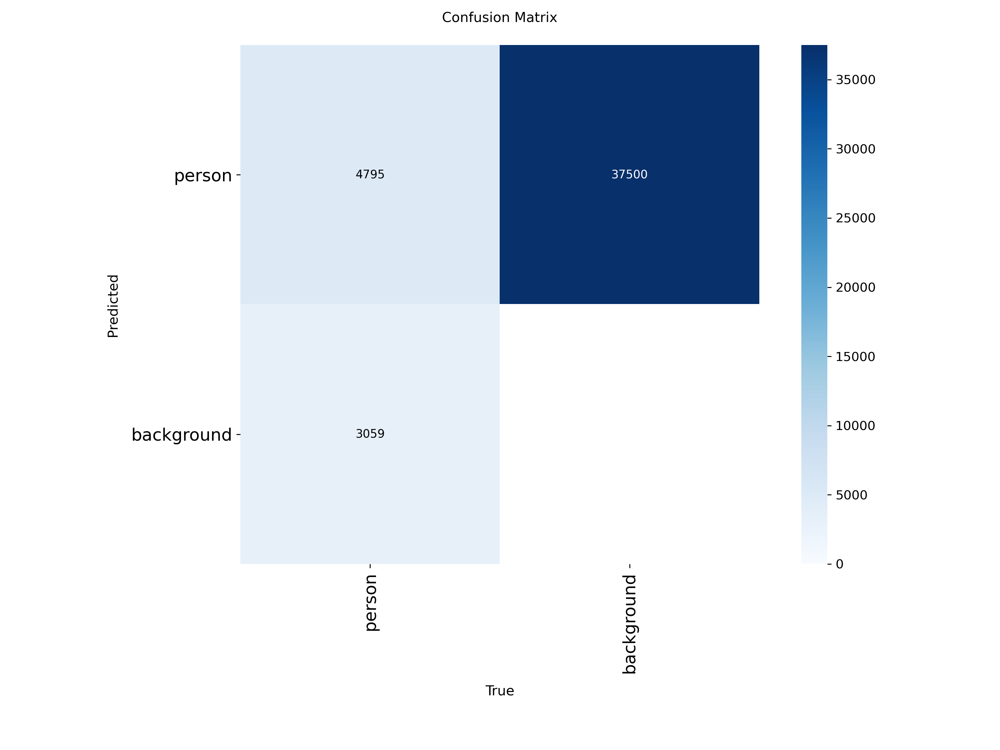

### confusion_matrix_normalized.png

`runs/baseline/confusion_matrix_normalized.png`

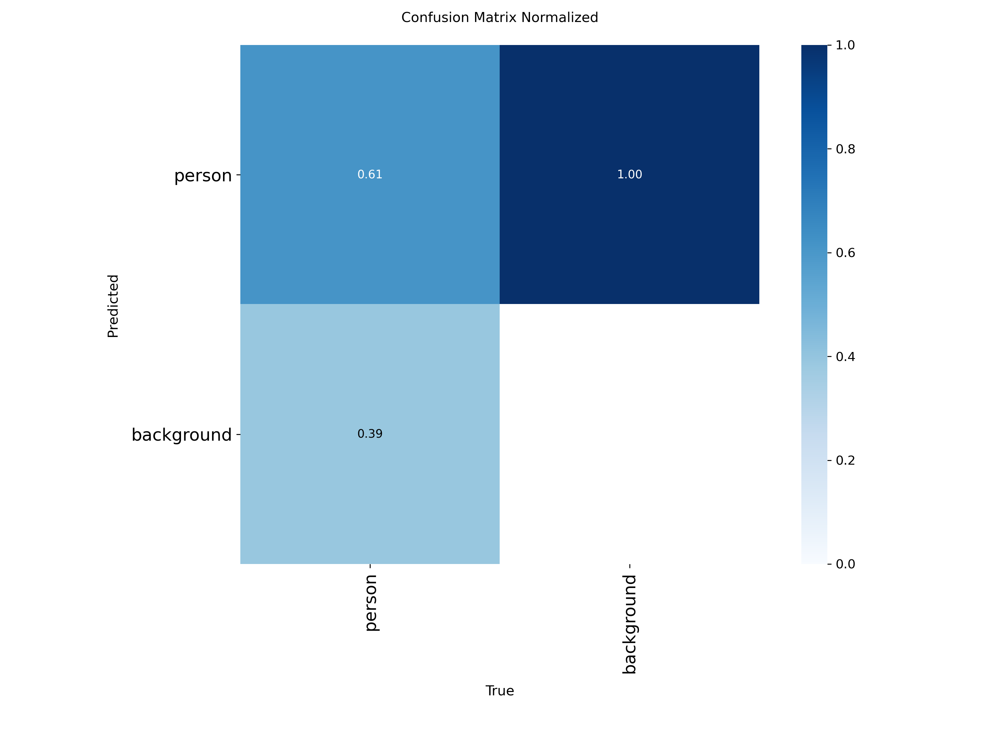

### confusion_matrix.png

`runs/experiment_02/confusion_matrix.png`

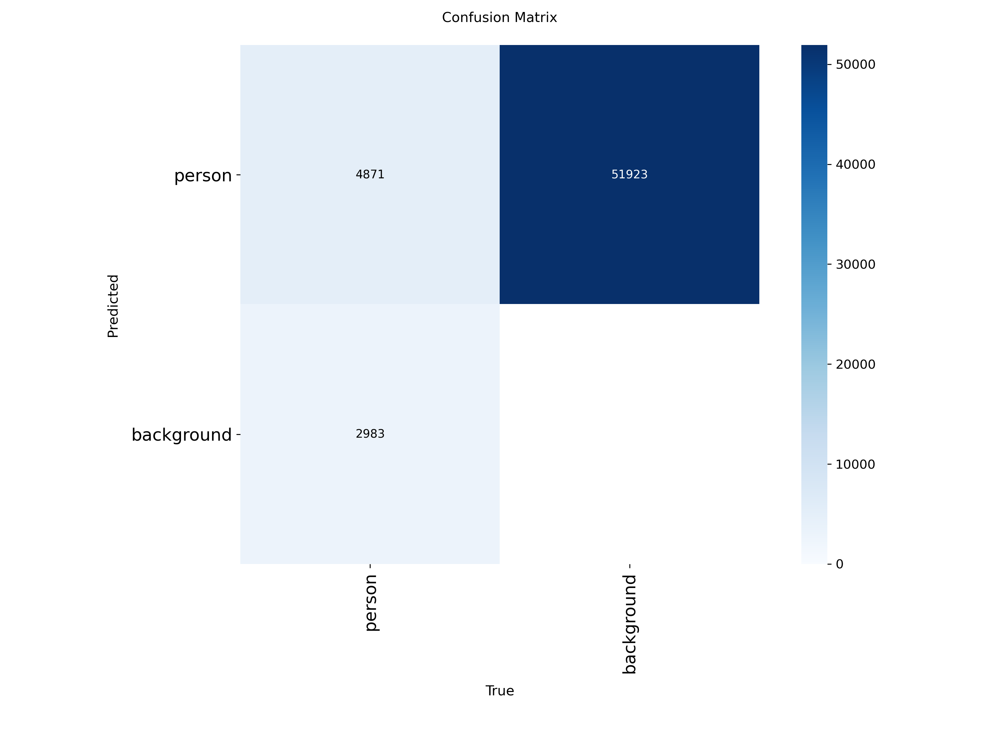

### confusion_matrix_normalized.png

`runs/experiment_02/confusion_matrix_normalized.png`

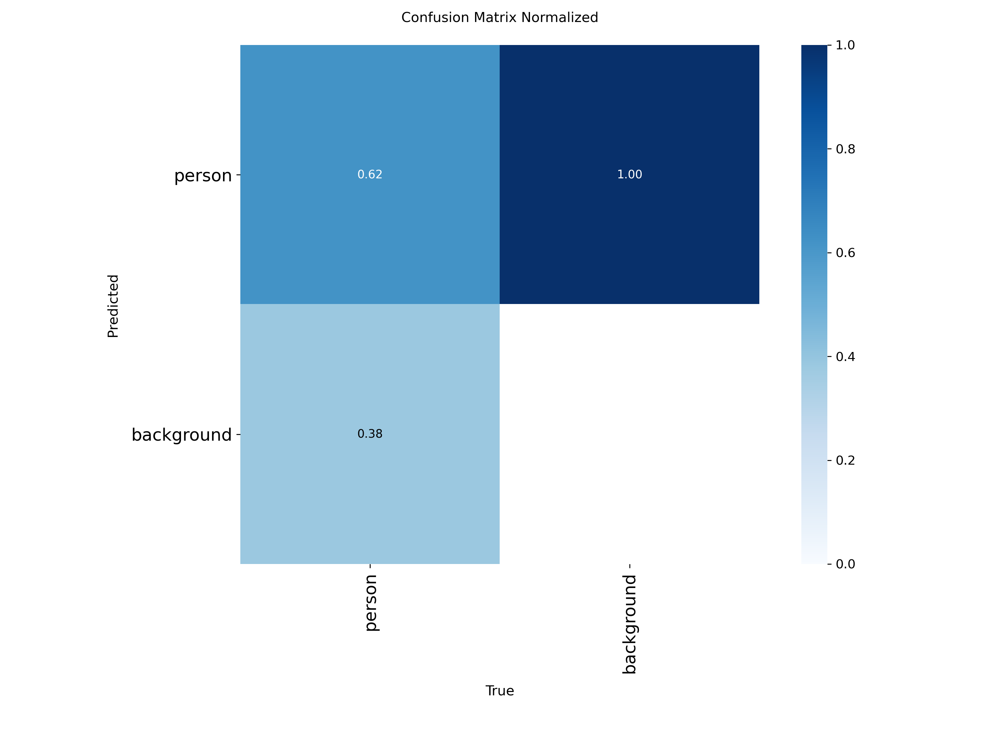

### confusion_matrix.png

`runs/final_test_evaluation/confusion_matrix.png`

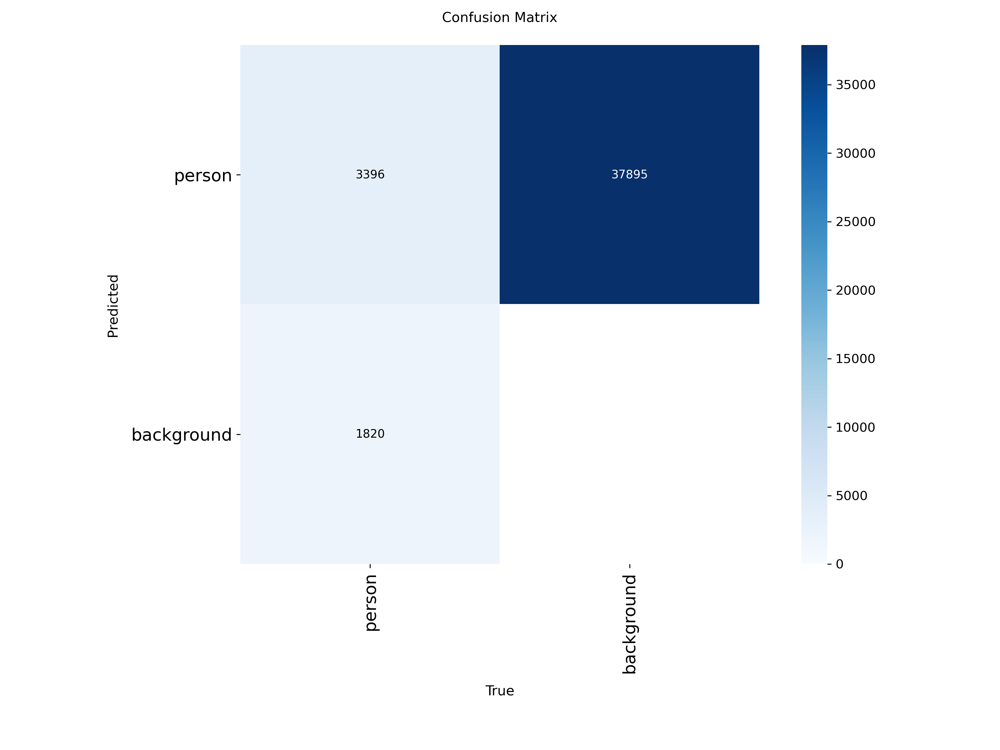

### confusion_matrix_normalized.png

`runs/final_test_evaluation/confusion_matrix_normalized.png`

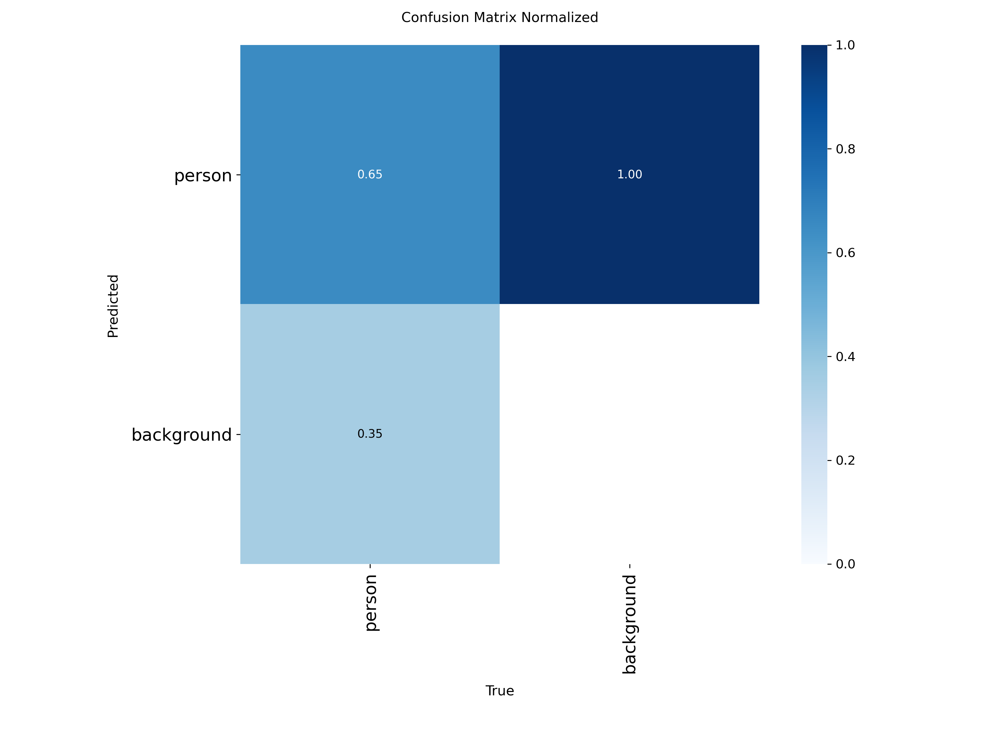

### confusion_matrix.png

`runs/standardized_validation/yolo11n_512_experiment/confusion_matrix.png`

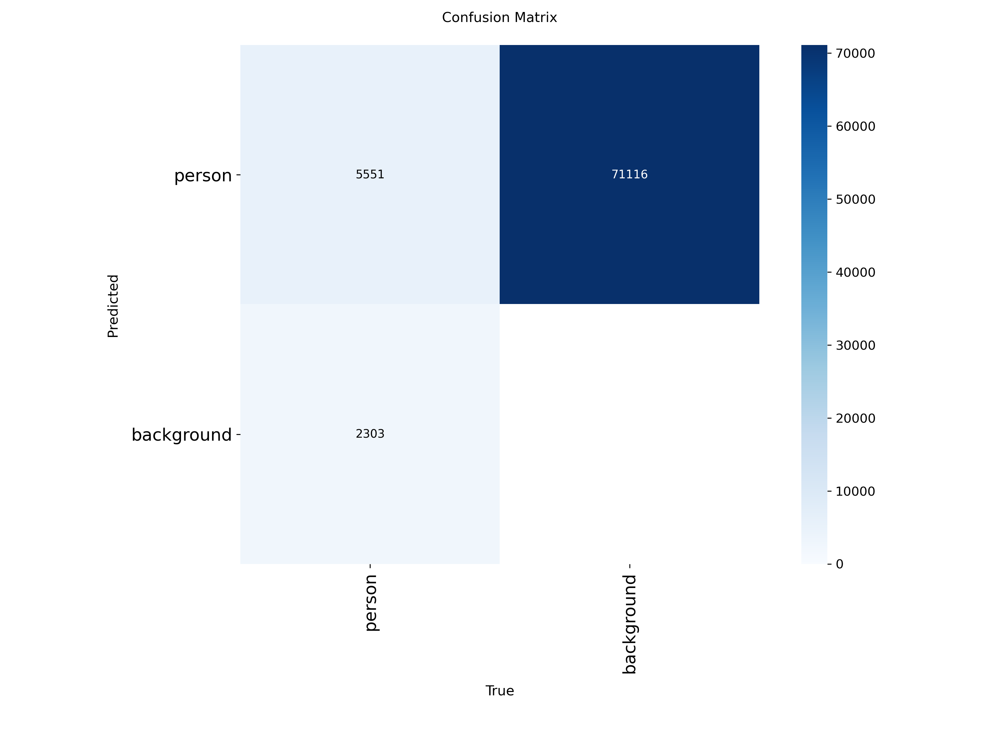

### confusion_matrix_normalized.png

`runs/standardized_validation/yolo11n_512_experiment/confusion_matrix_normalized.png`

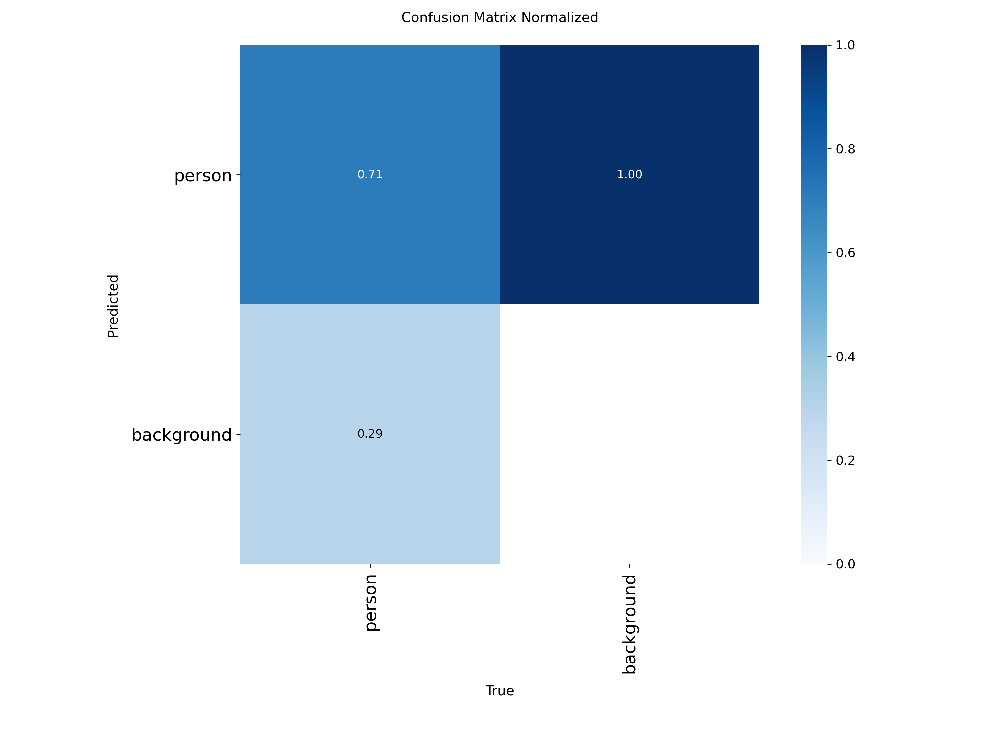

### confusion_matrix.png

`runs/standardized_validation/yolo11n_baseline/confusion_matrix.png`

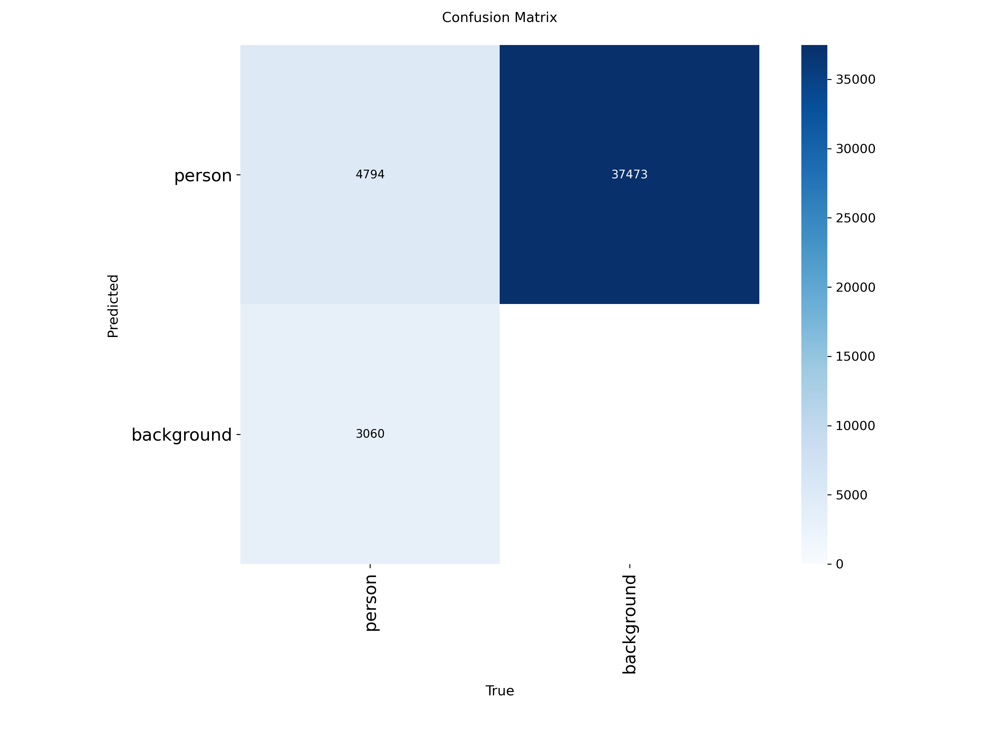

### confusion_matrix_normalized.png

`runs/standardized_validation/yolo11n_baseline/confusion_matrix_normalized.png`

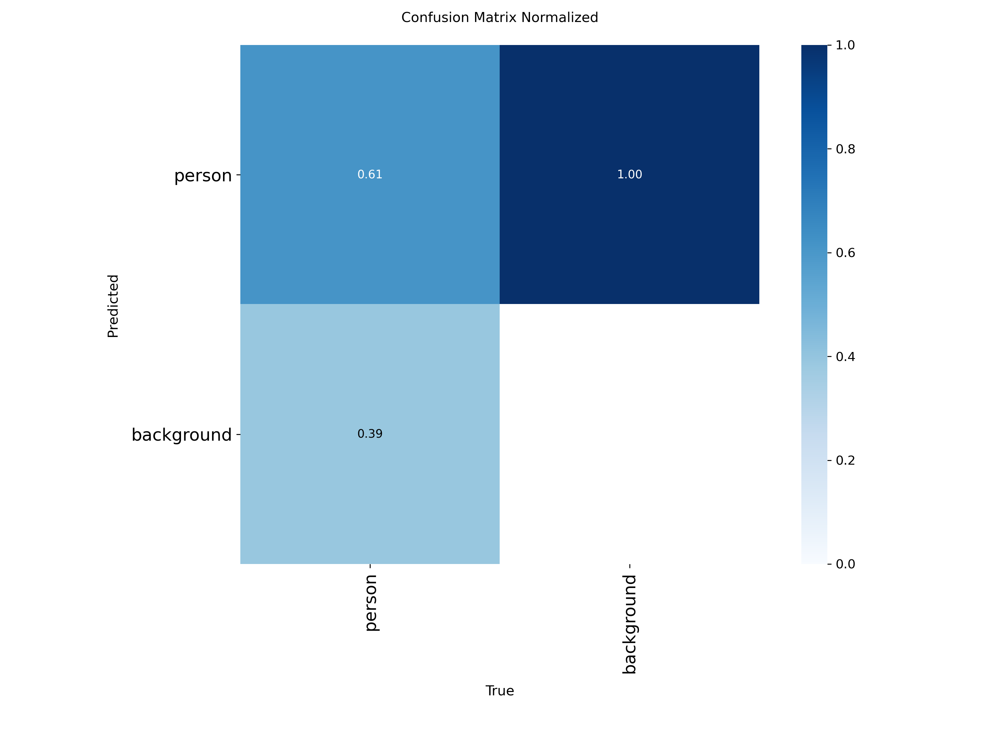

### confusion_matrix.png

`runs/standardized_validation/yolo11n_refined/confusion_matrix.png`

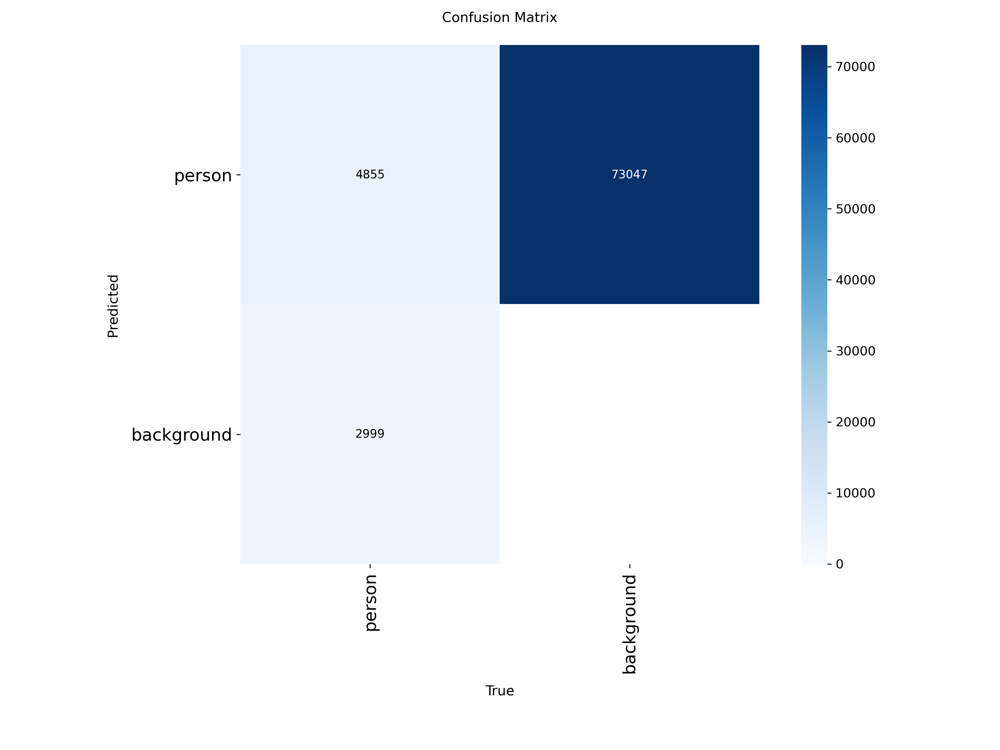

### confusion_matrix_normalized.png

`runs/standardized_validation/yolo11n_refined/confusion_matrix_normalized.png`

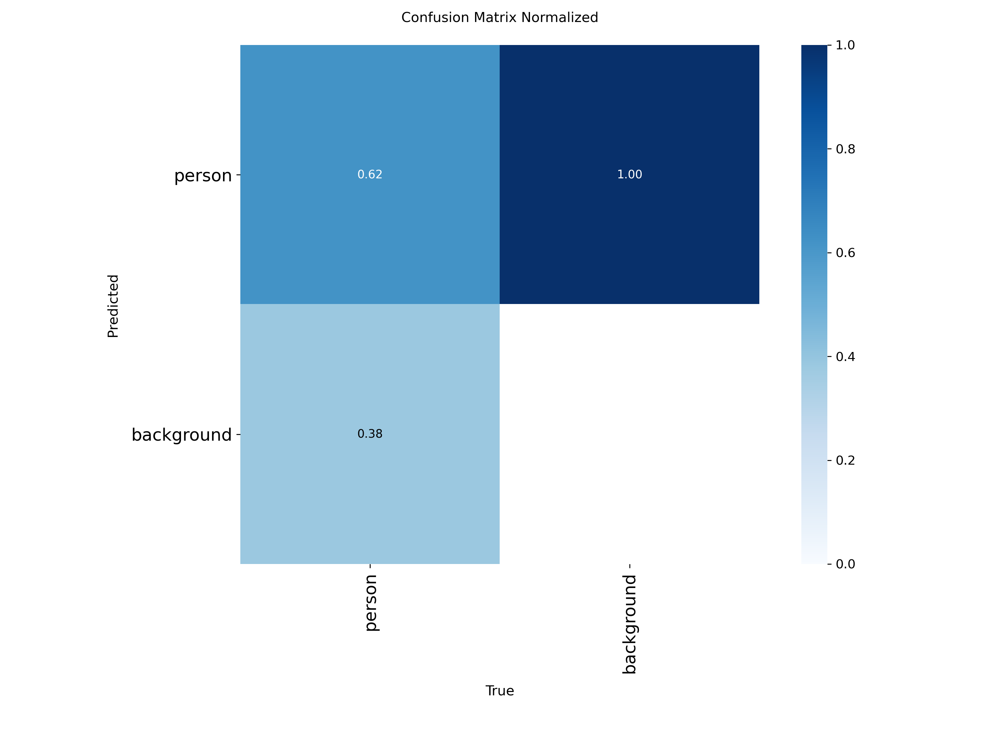

### confusion_matrix.png

`runs/standardized_validation/yolo11s/confusion_matrix.png`

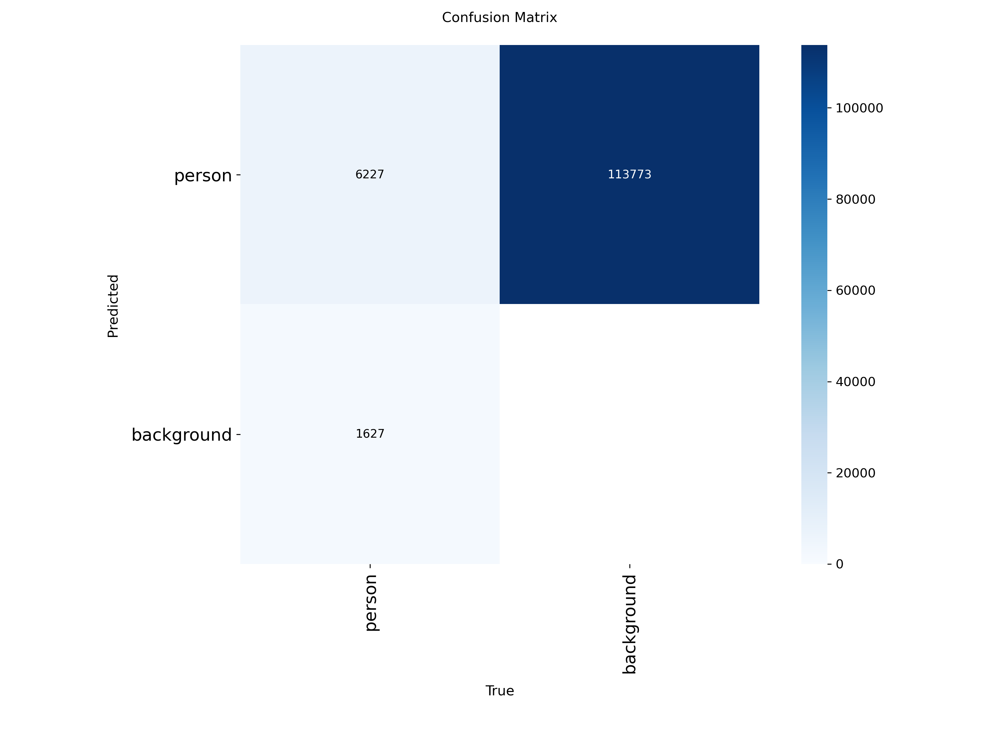

### confusion_matrix_normalized.png

`runs/standardized_validation/yolo11s/confusion_matrix_normalized.png`

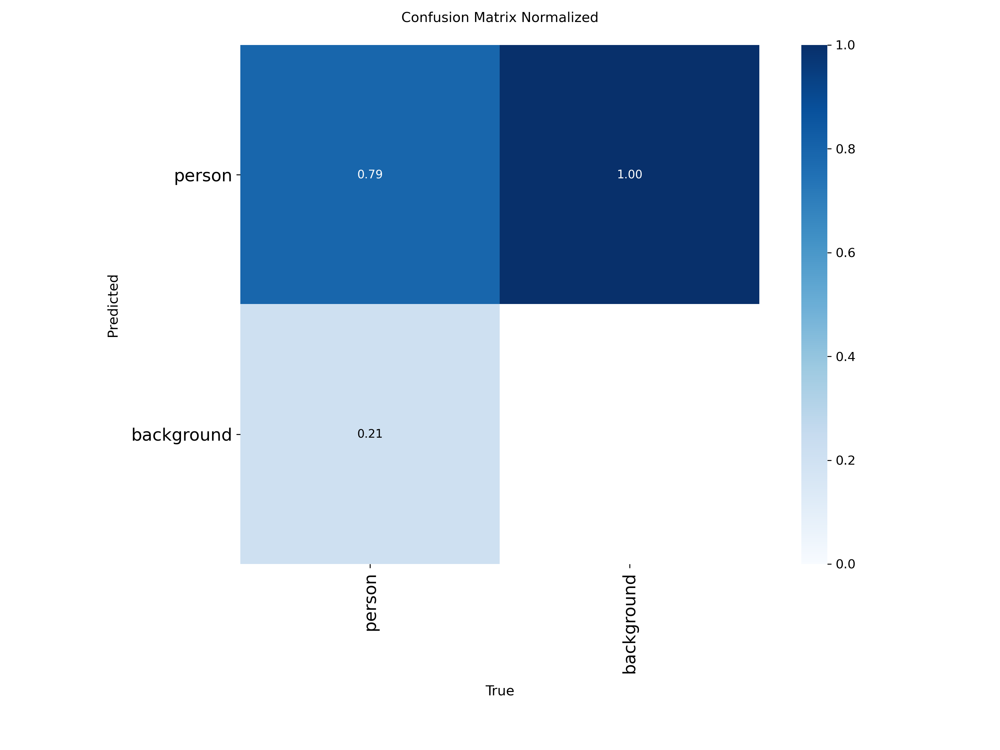

### confusion_matrix.png

`runs/standardized_validation/yolo11s_lr_tuned/confusion_matrix.png`

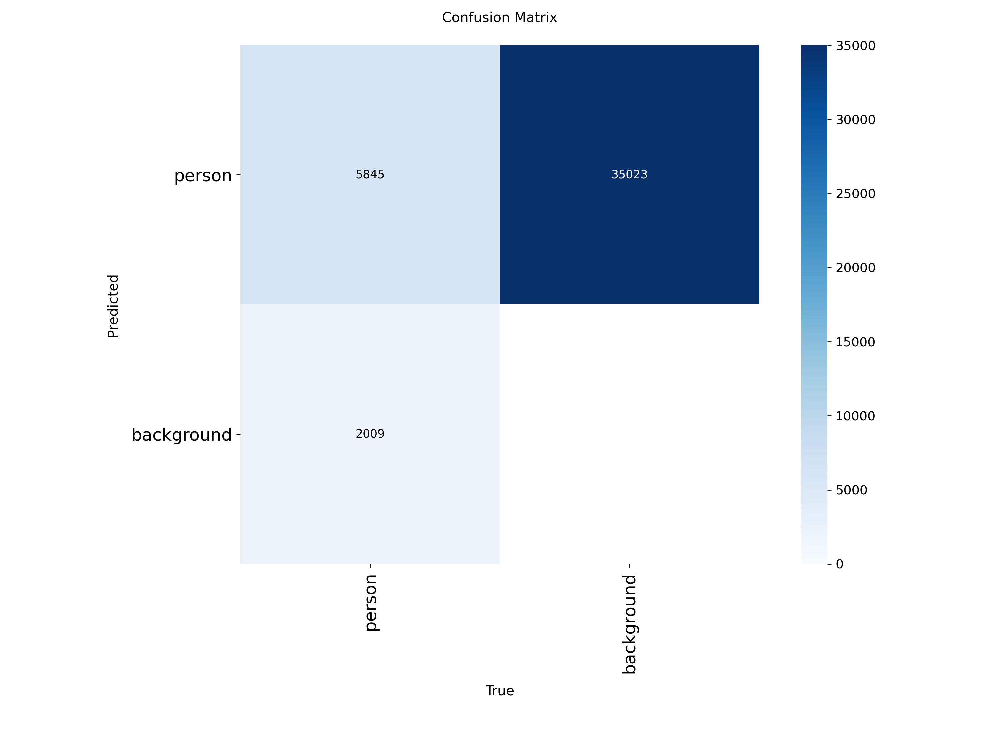

### confusion_matrix_normalized.png

`runs/standardized_validation/yolo11s_lr_tuned/confusion_matrix_normalized.png`

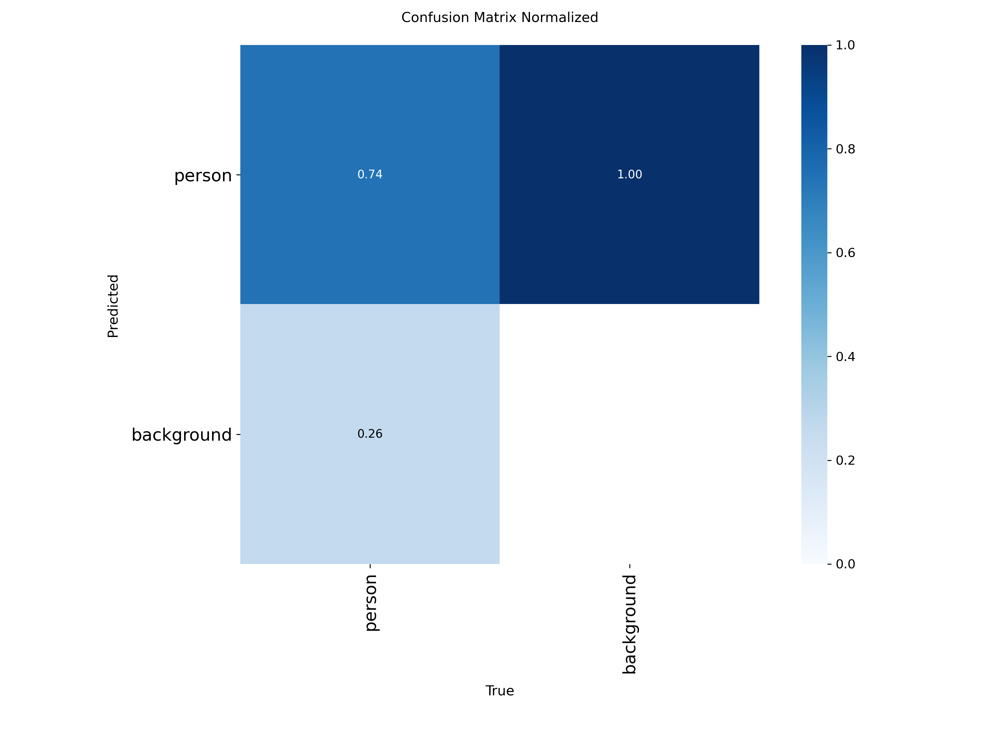

### confusion_matrix.png

`runs/yolo11n_refined/confusion_matrix.png`

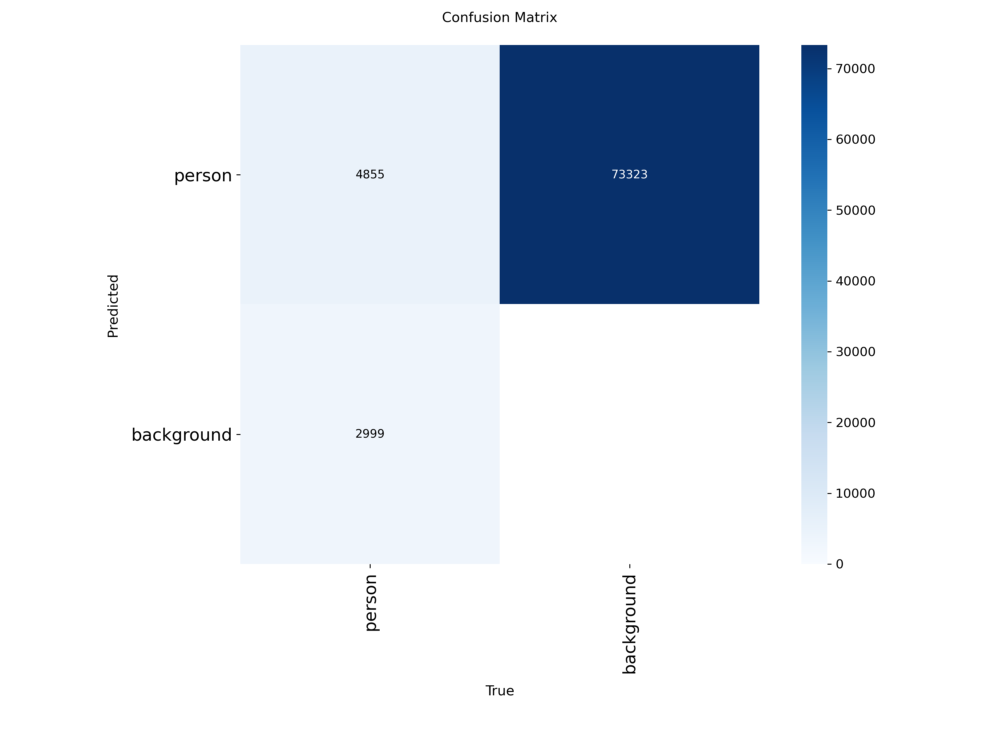

### confusion_matrix_normalized.png

`runs/yolo11n_refined/confusion_matrix_normalized.png`

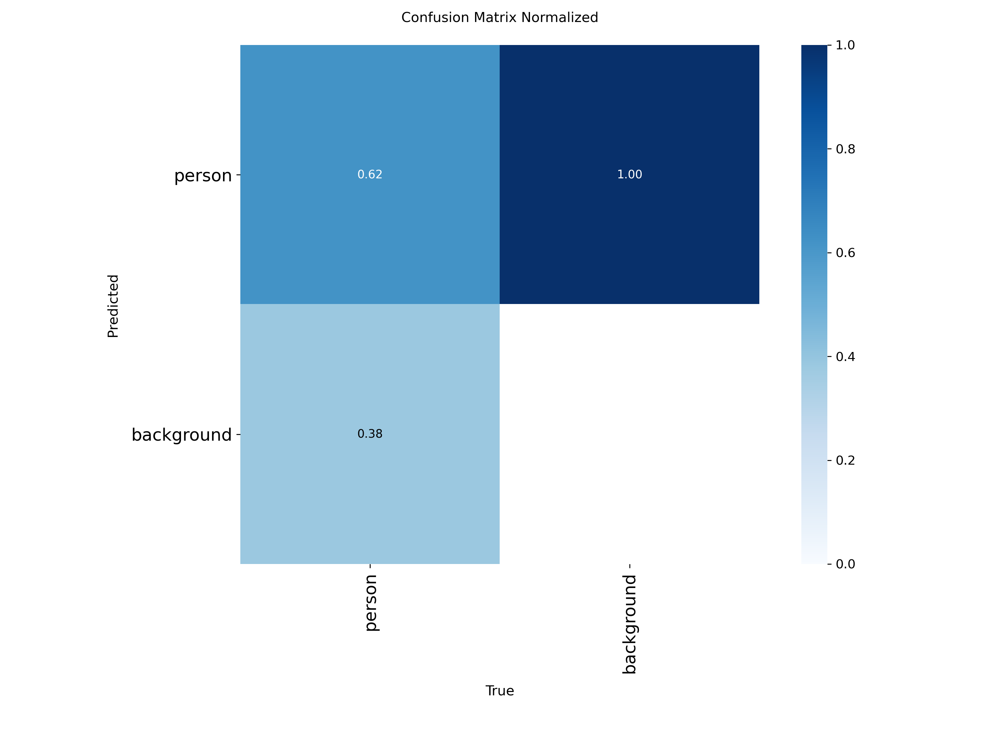

### confusion_matrix.png

`runs/yolo11s/confusion_matrix.png`

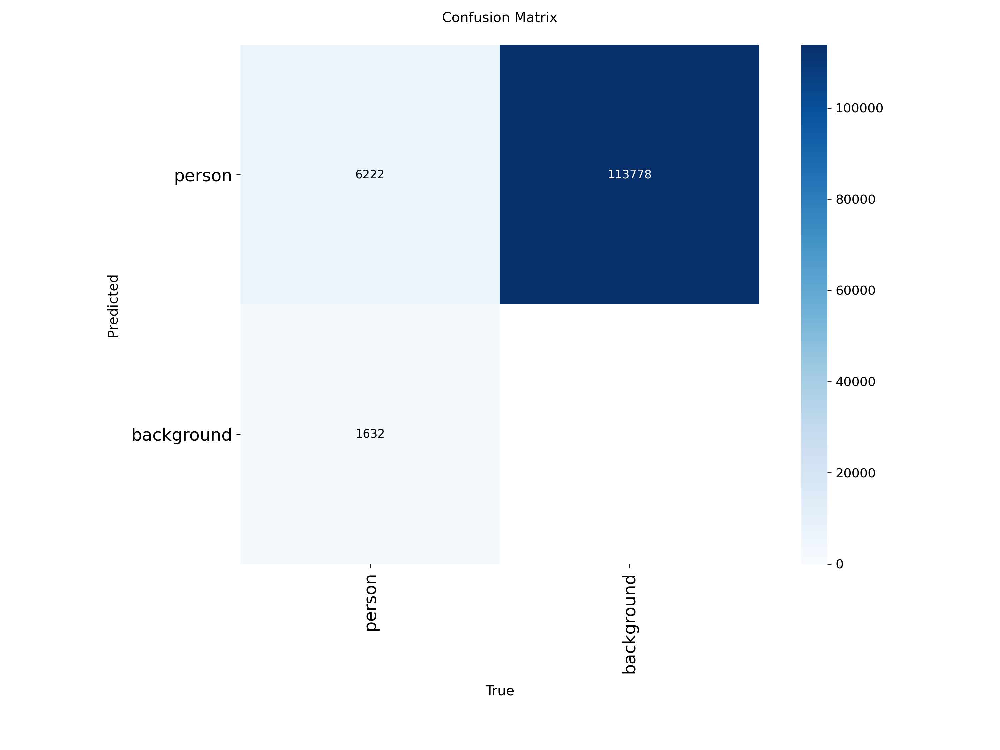

### confusion_matrix_normalized.png

`runs/yolo11s/confusion_matrix_normalized.png`

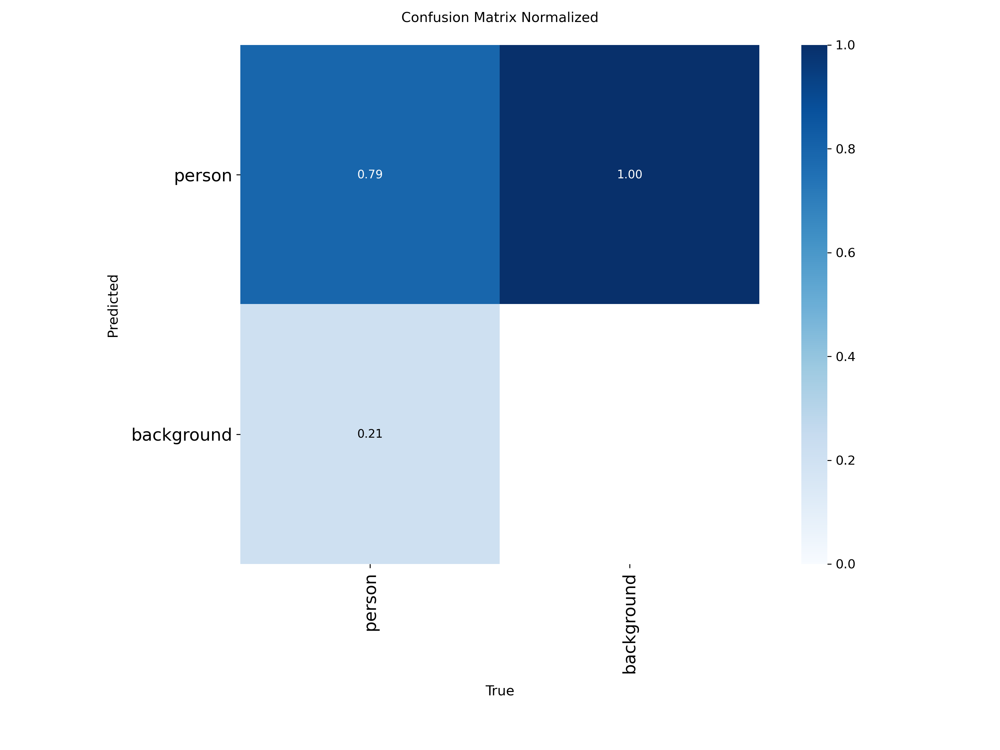

### confusion_matrix.png

`runs/yolo11s_lr_tuned/confusion_matrix.png`

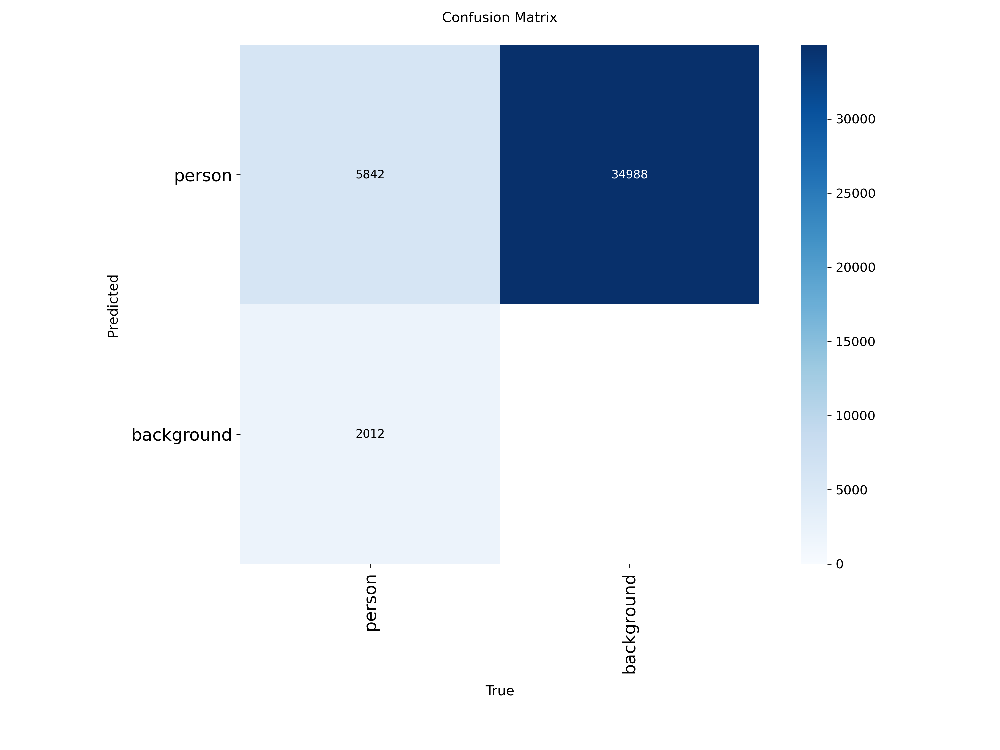

### confusion_matrix_normalized.png

`runs/yolo11s_lr_tuned/confusion_matrix_normalized.png`

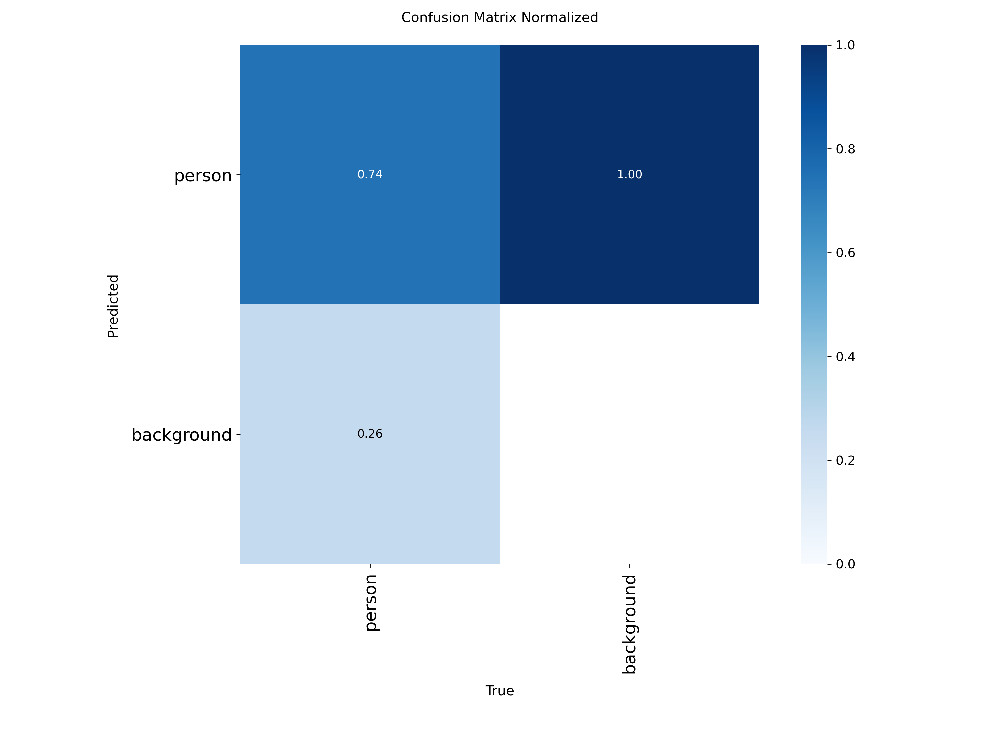

### BoxF1_curve.png

`runs/baseline/BoxF1_curve.png`

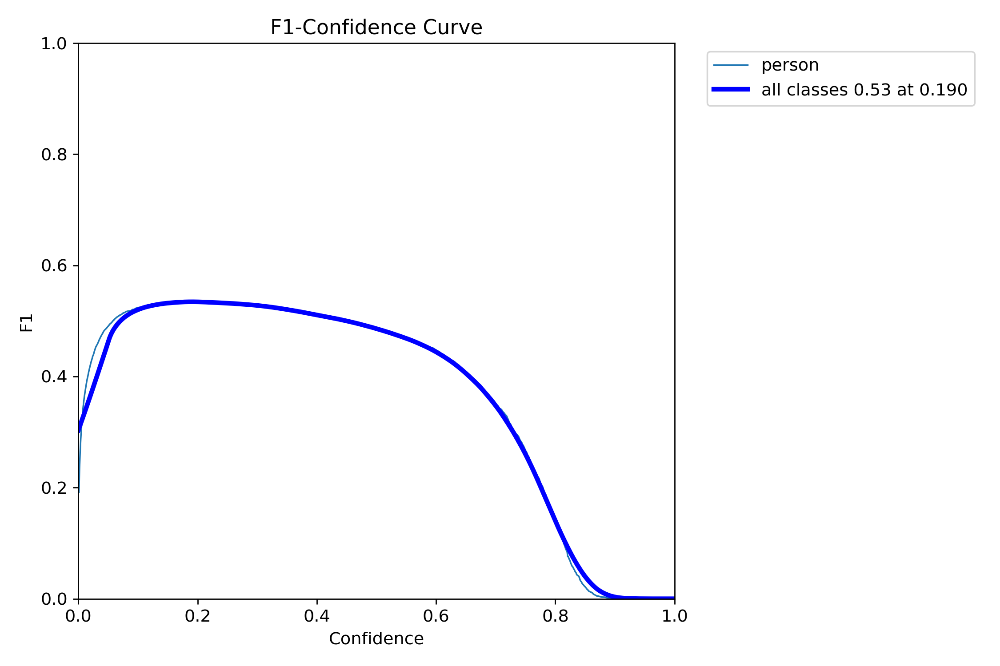

### BoxF1_curve.png

`runs/experiment_02/BoxF1_curve.png`

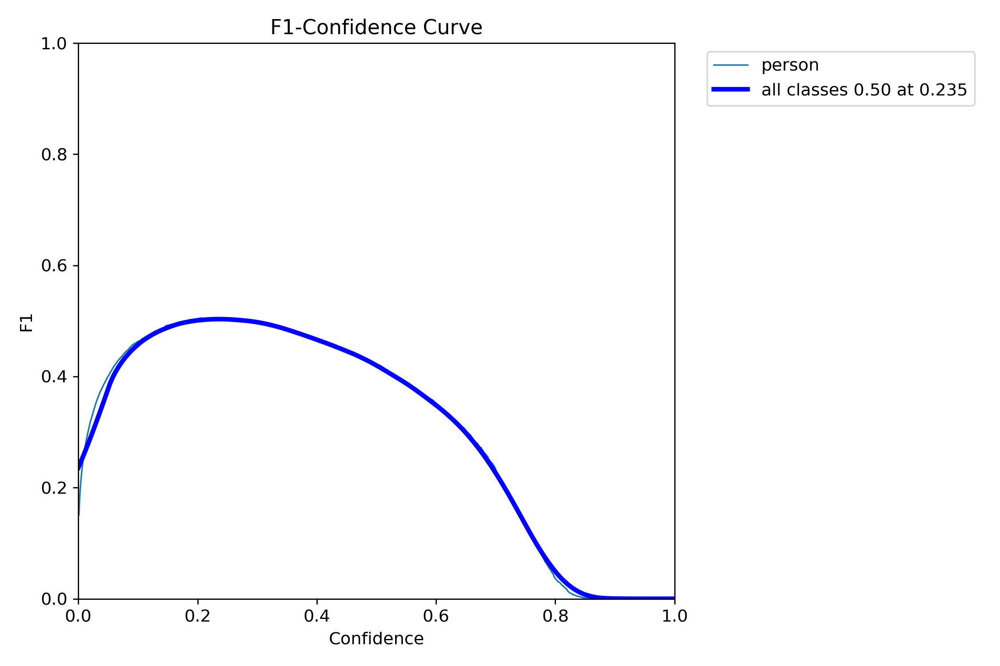

### BoxF1_curve.png

`runs/final_test_evaluation/BoxF1_curve.png`

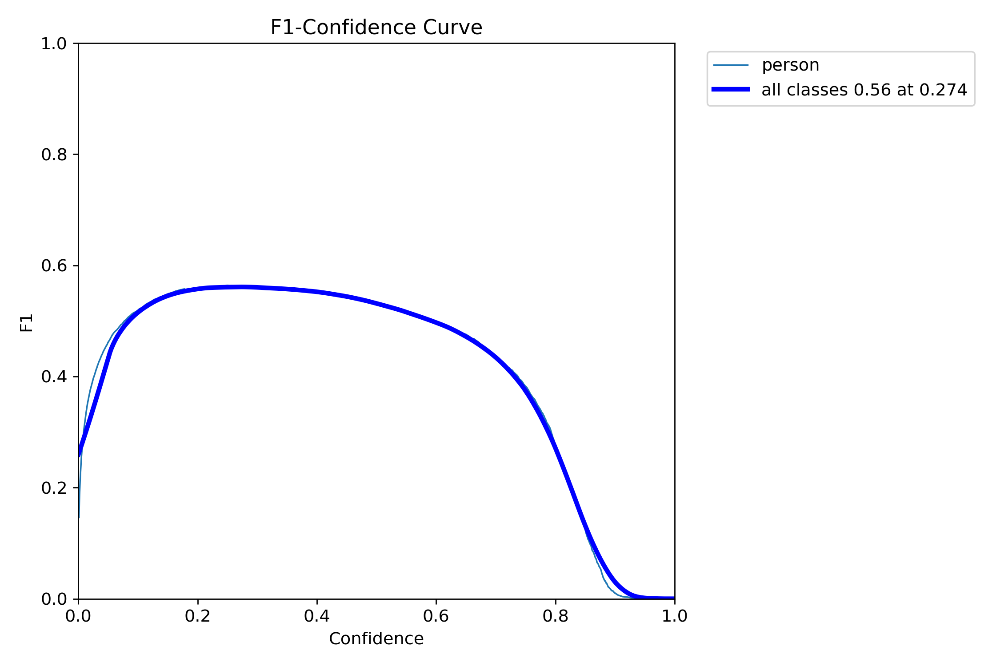

### BoxF1_curve.png

`runs/standardized_validation/yolo11n_512_experiment/BoxF1_curve.png`

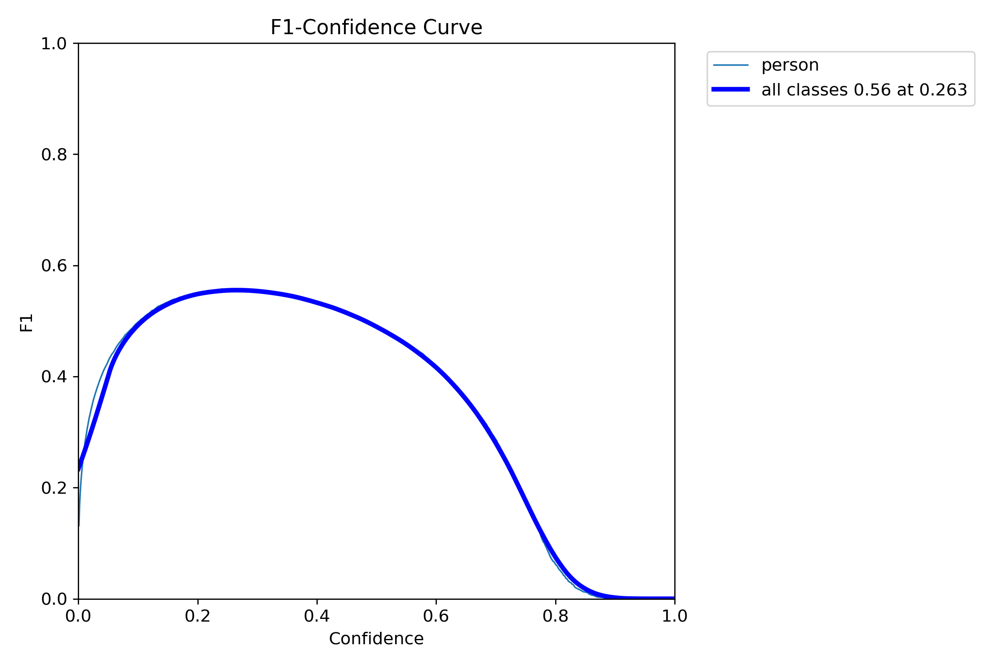

### BoxF1_curve.png

`runs/standardized_validation/yolo11n_baseline/BoxF1_curve.png`

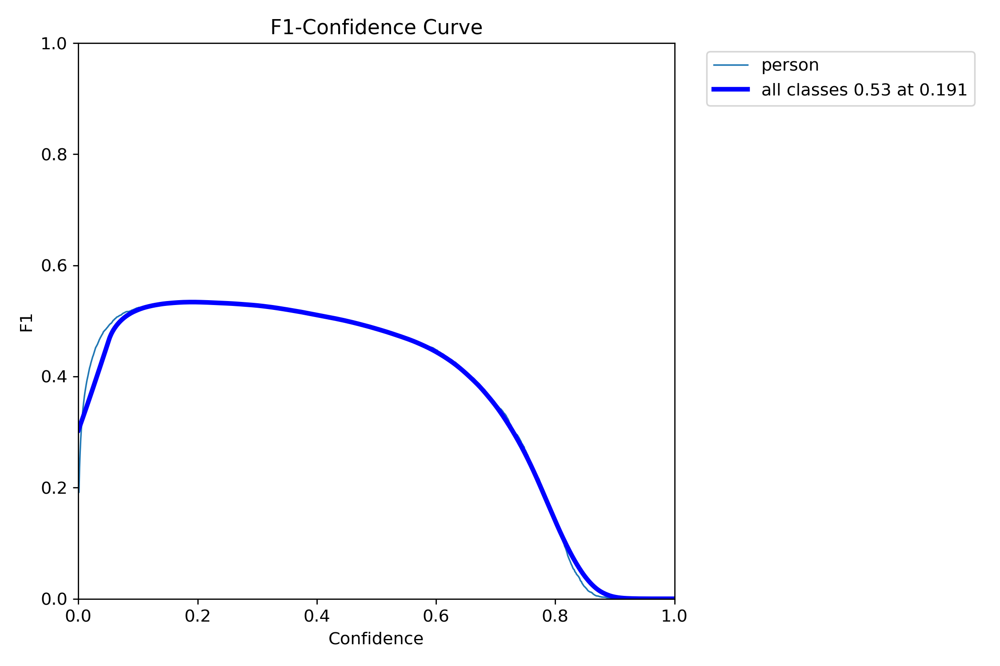

### BoxF1_curve.png

`runs/standardized_validation/yolo11n_refined/BoxF1_curve.png`

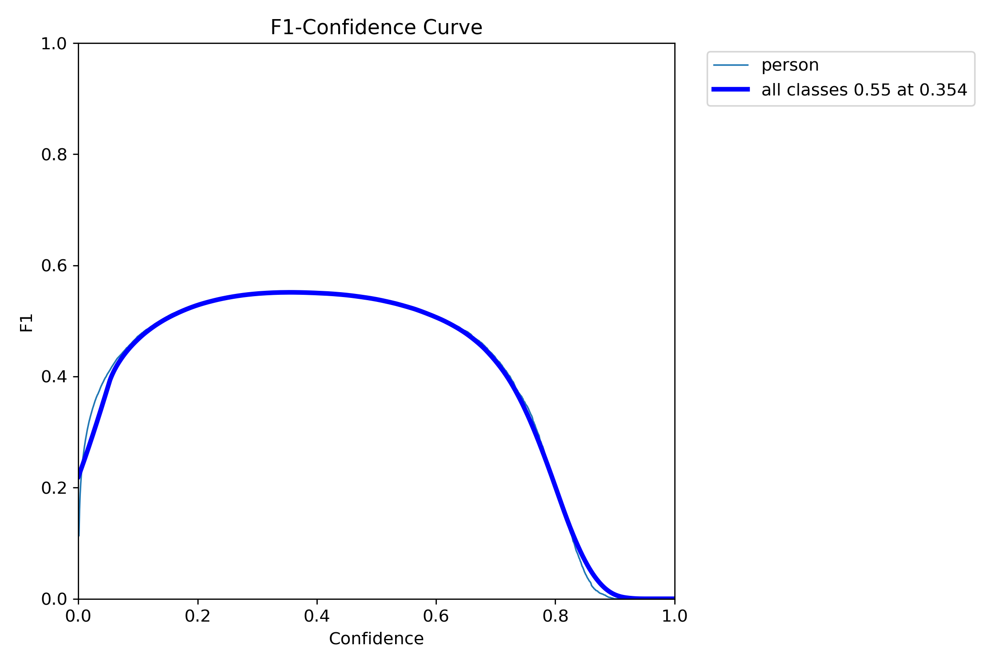

### BoxF1_curve.png

`runs/standardized_validation/yolo11s/BoxF1_curve.png`

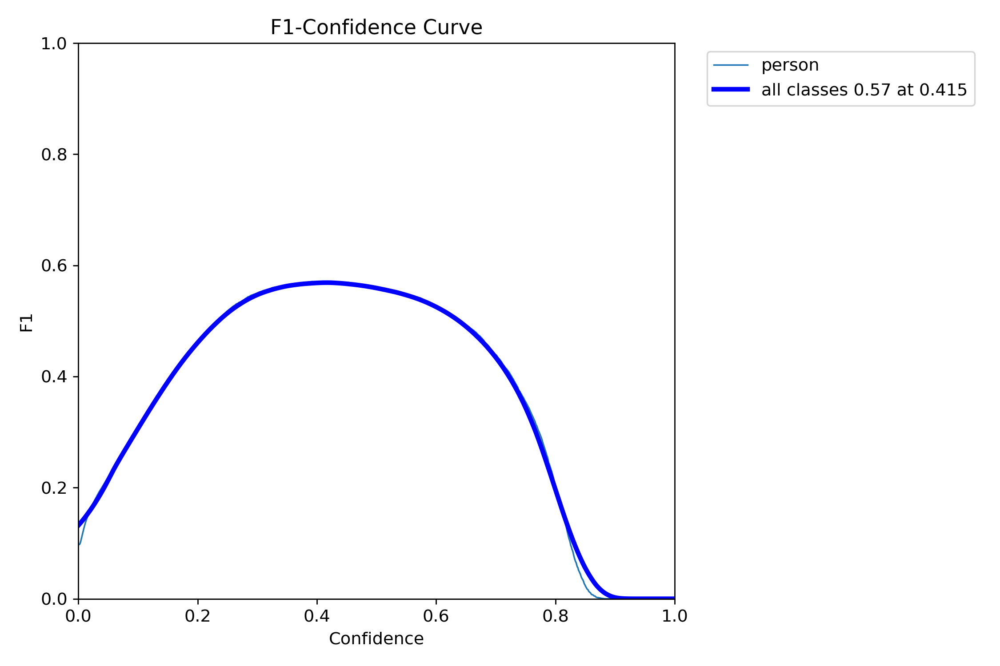

### BoxF1_curve.png

`runs/standardized_validation/yolo11s_lr_tuned/BoxF1_curve.png`

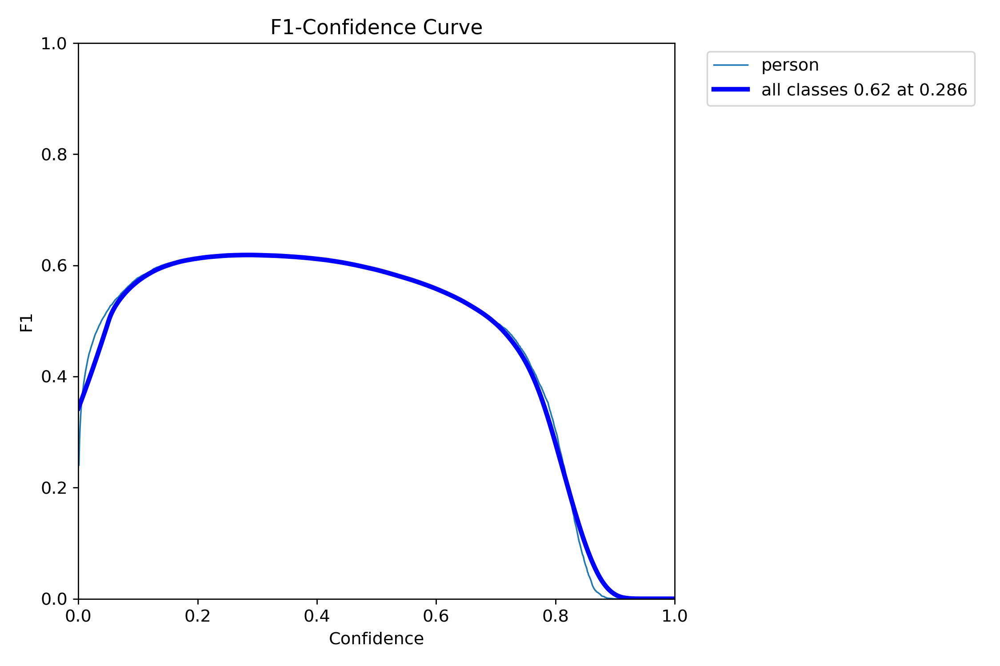

### BoxF1_curve.png

`runs/yolo11n_refined/BoxF1_curve.png`

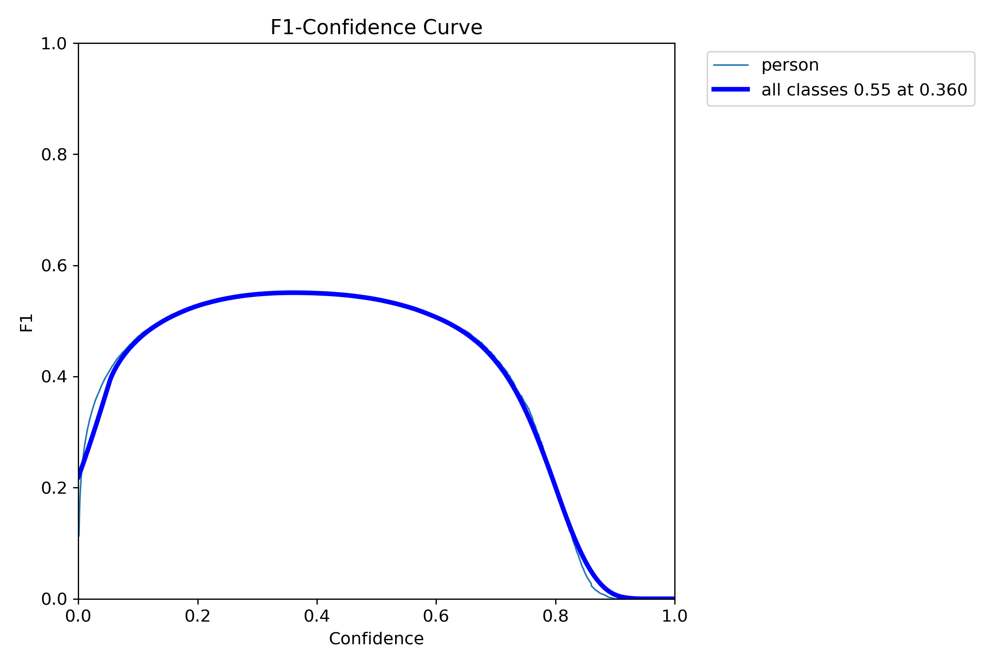

### BoxF1_curve.png

`runs/yolo11s/BoxF1_curve.png`

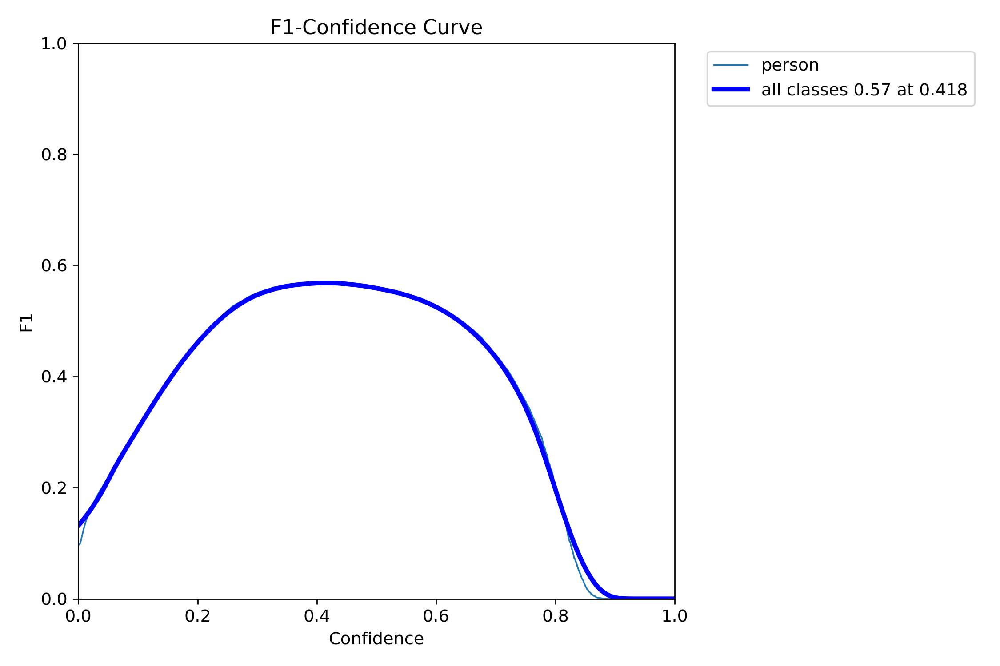

### BoxF1_curve.png

`runs/yolo11s_lr_tuned/BoxF1_curve.png`

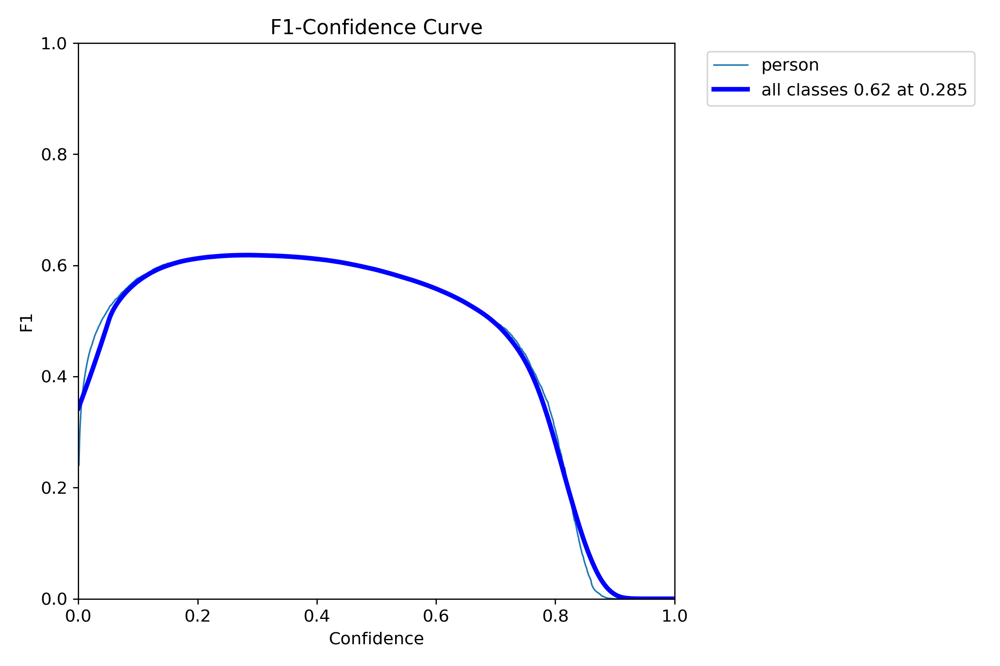

### BoxP_curve.png

`runs/baseline/BoxP_curve.png`

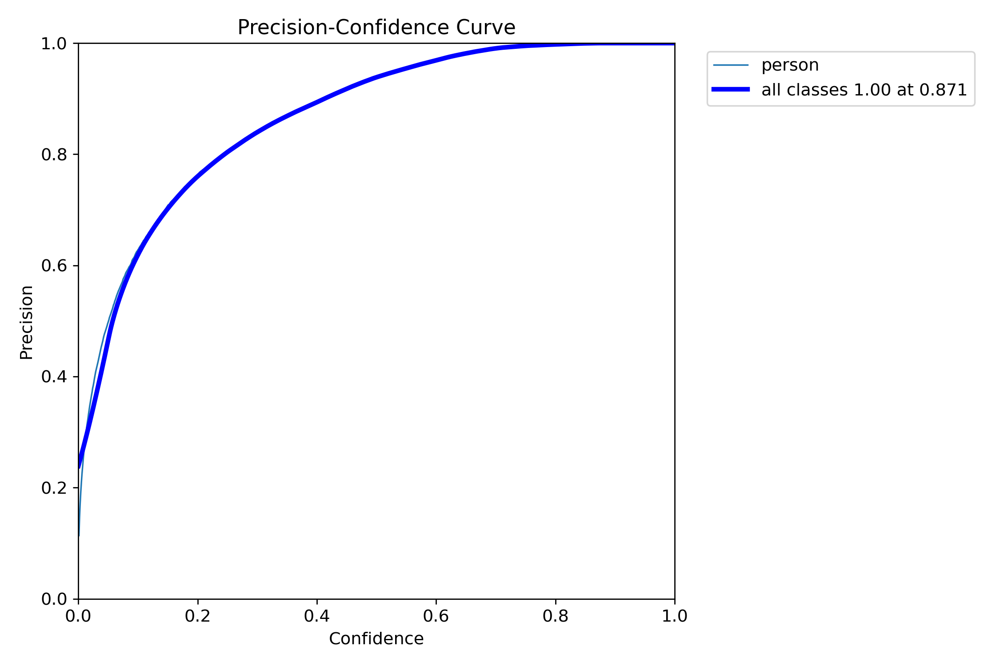

### BoxP_curve.png

`runs/experiment_02/BoxP_curve.png`

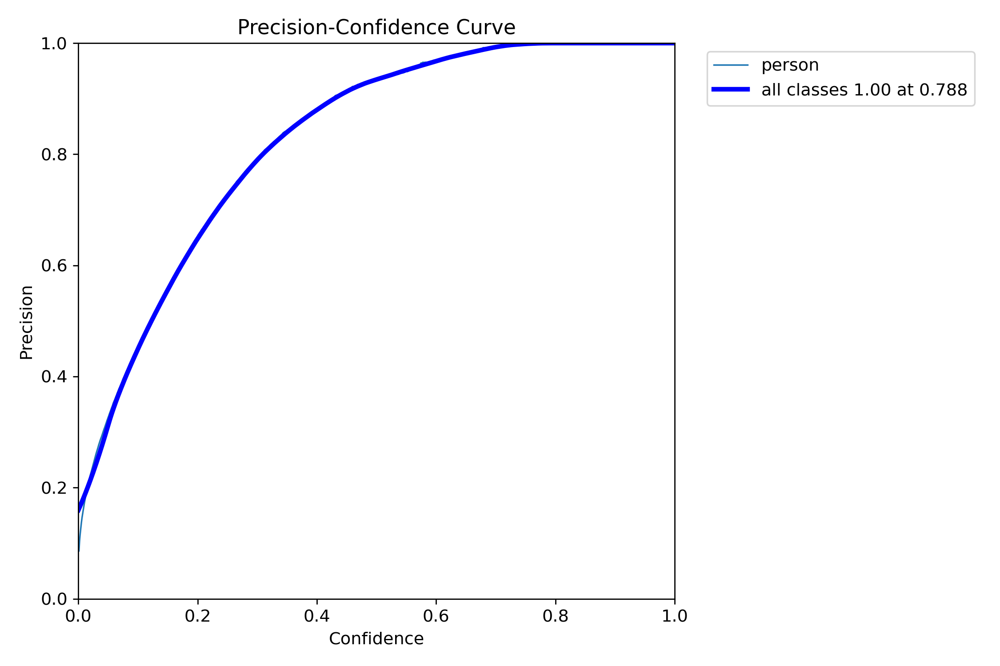

### BoxP_curve.png

`runs/final_test_evaluation/BoxP_curve.png`

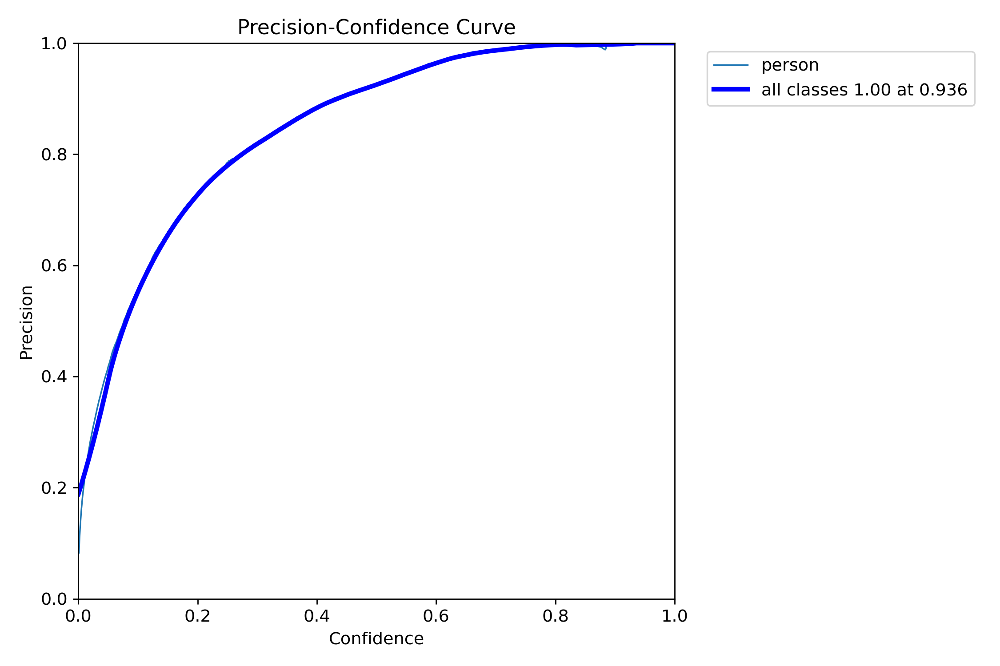

### BoxP_curve.png

`runs/standardized_validation/yolo11n_512_experiment/BoxP_curve.png`

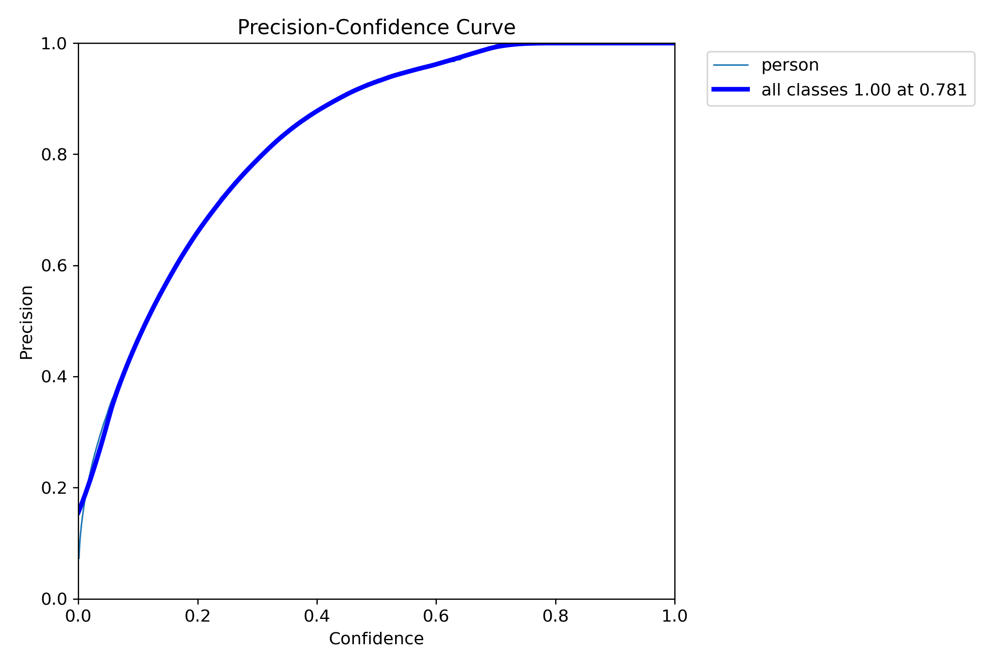

### BoxP_curve.png

`runs/standardized_validation/yolo11n_baseline/BoxP_curve.png`

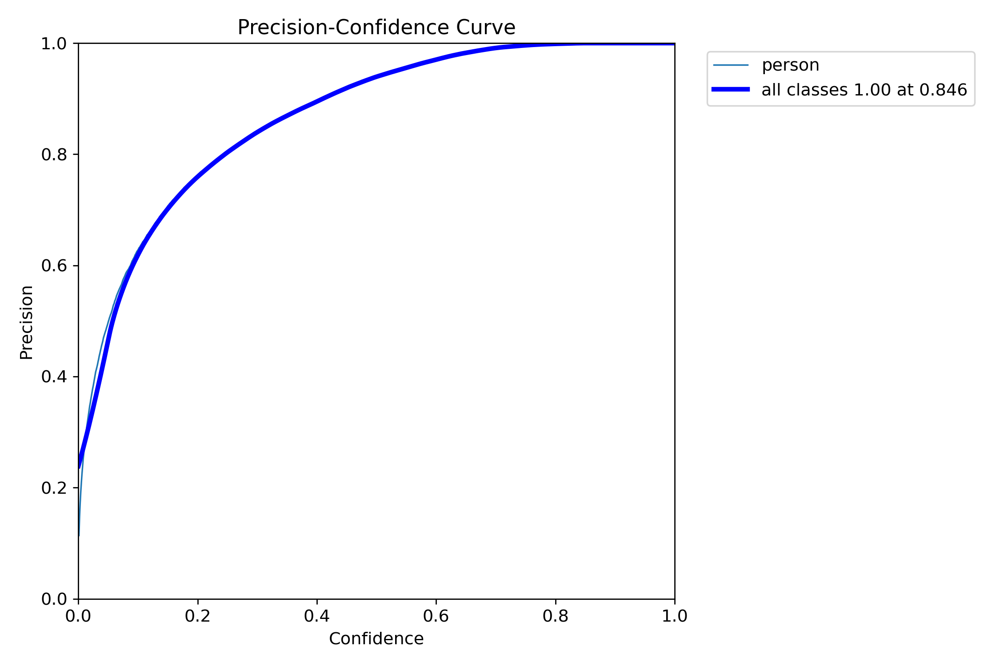

### BoxP_curve.png

`runs/standardized_validation/yolo11n_refined/BoxP_curve.png`

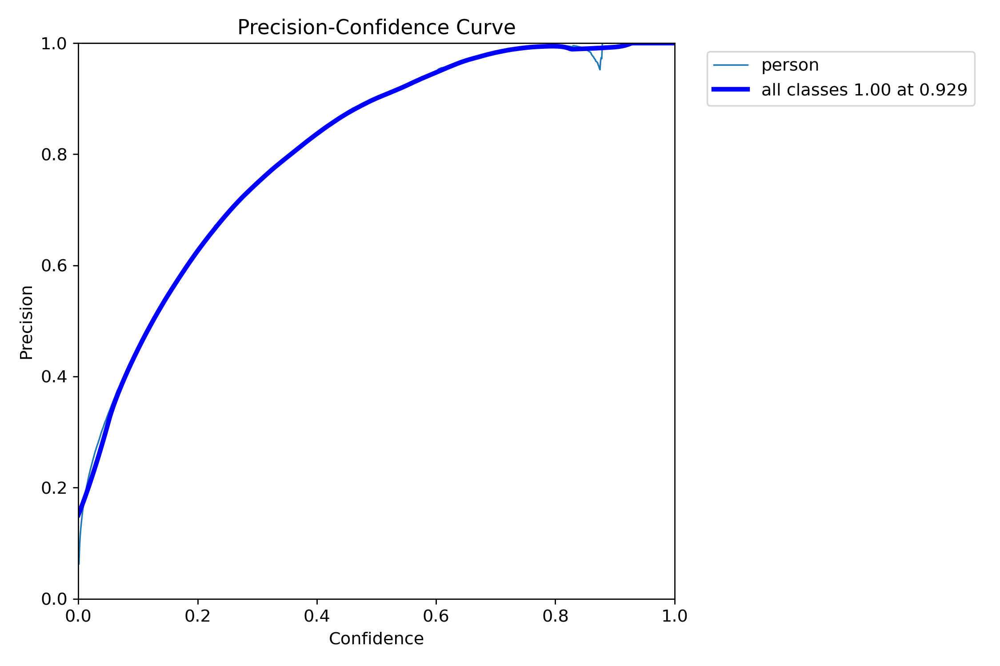

### BoxP_curve.png

`runs/standardized_validation/yolo11s/BoxP_curve.png`

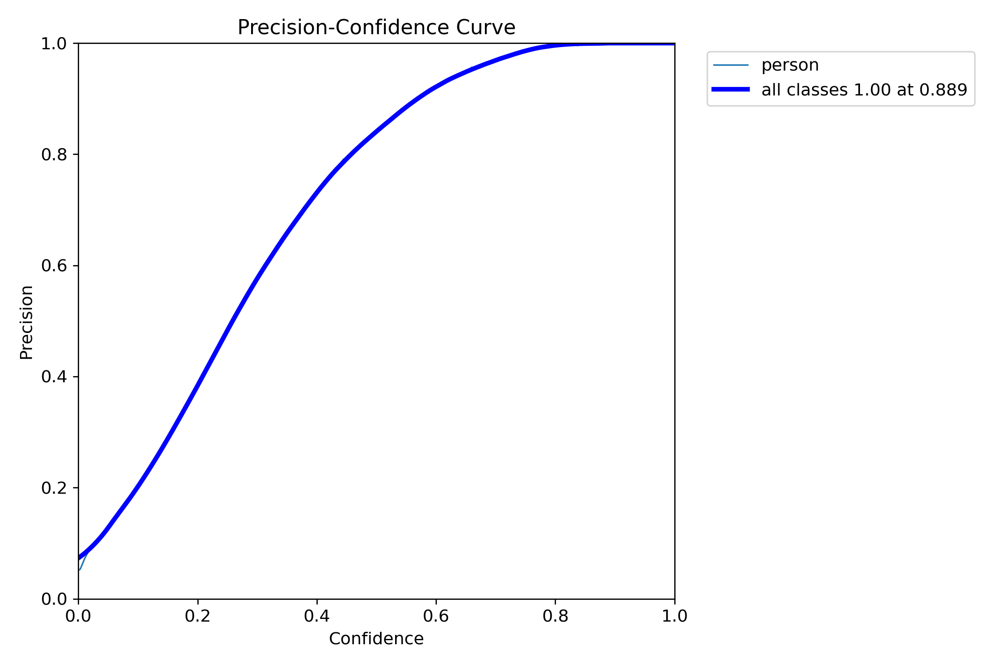

### BoxP_curve.png

`runs/standardized_validation/yolo11s_lr_tuned/BoxP_curve.png`

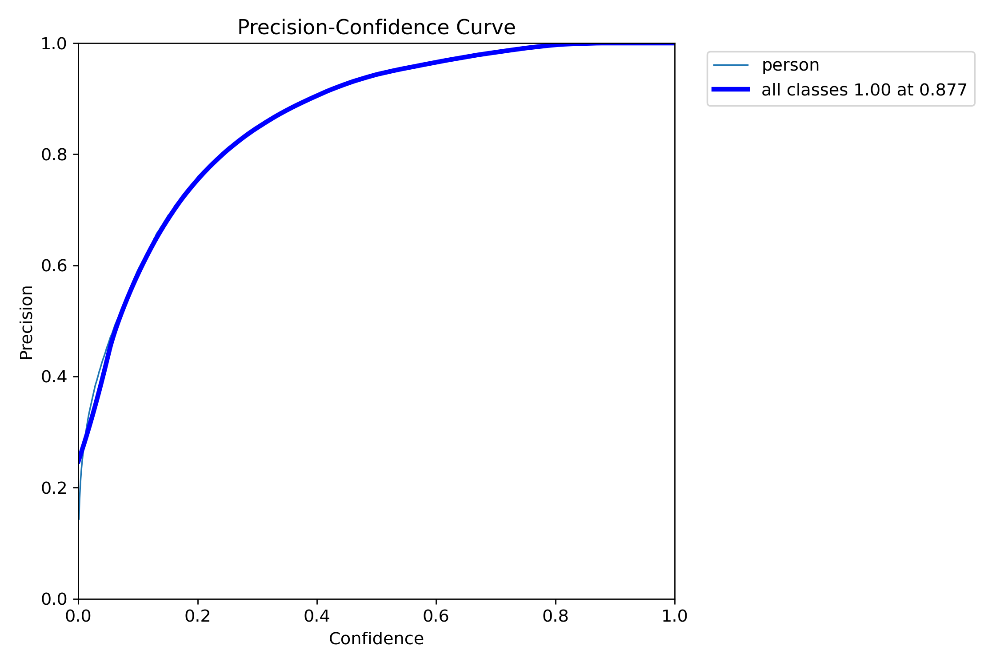

### BoxP_curve.png

`runs/yolo11n_refined/BoxP_curve.png`

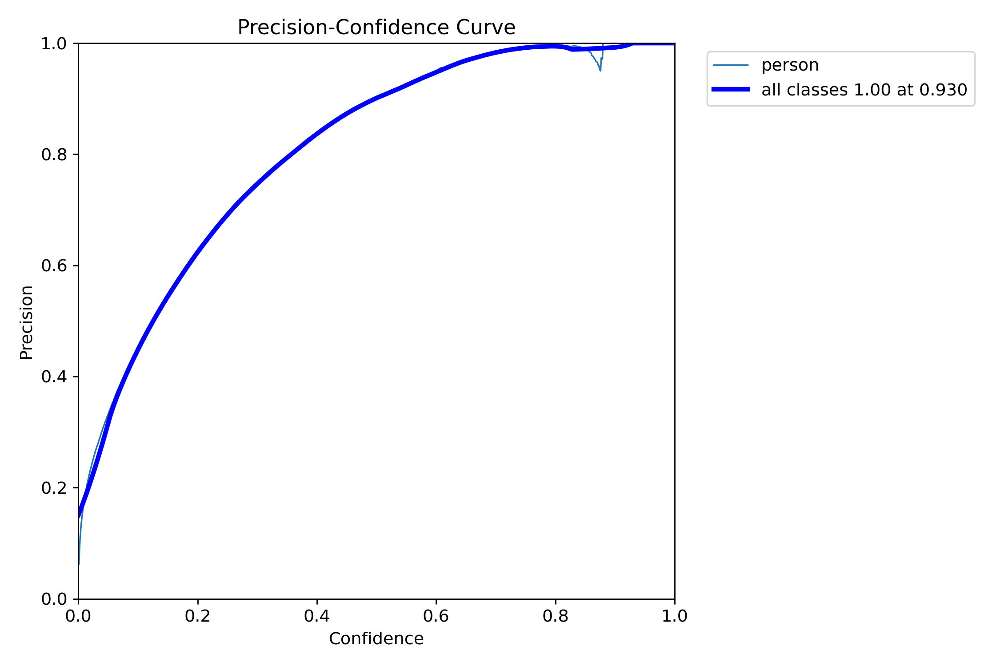

### BoxP_curve.png

`runs/yolo11s/BoxP_curve.png`

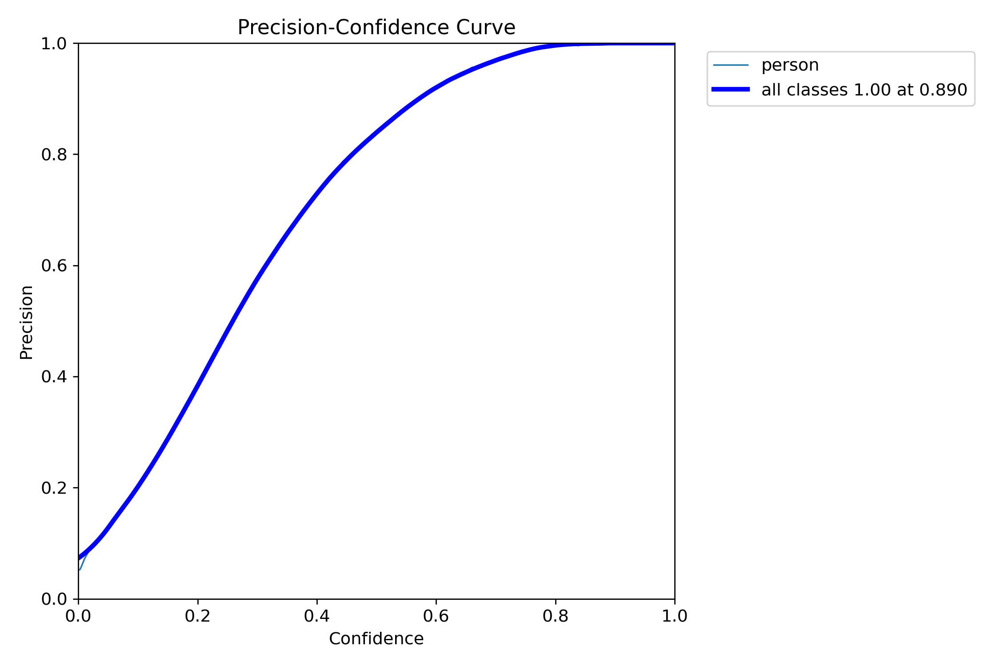

### BoxP_curve.png

`runs/yolo11s_lr_tuned/BoxP_curve.png`

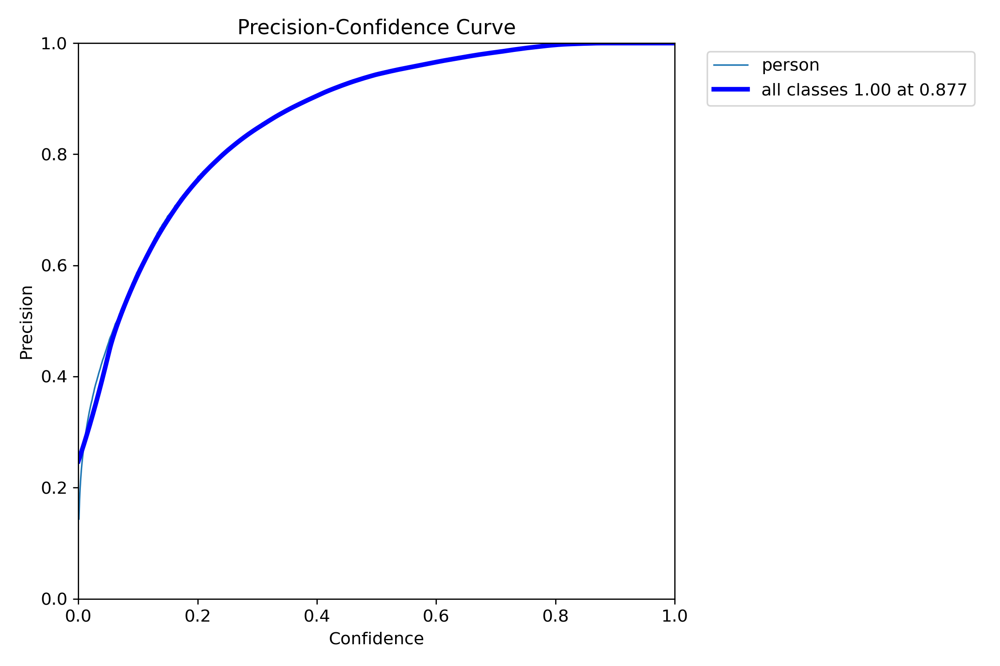

### baseline_map_curves.png

`visualizations/baseline_map_curves.png`

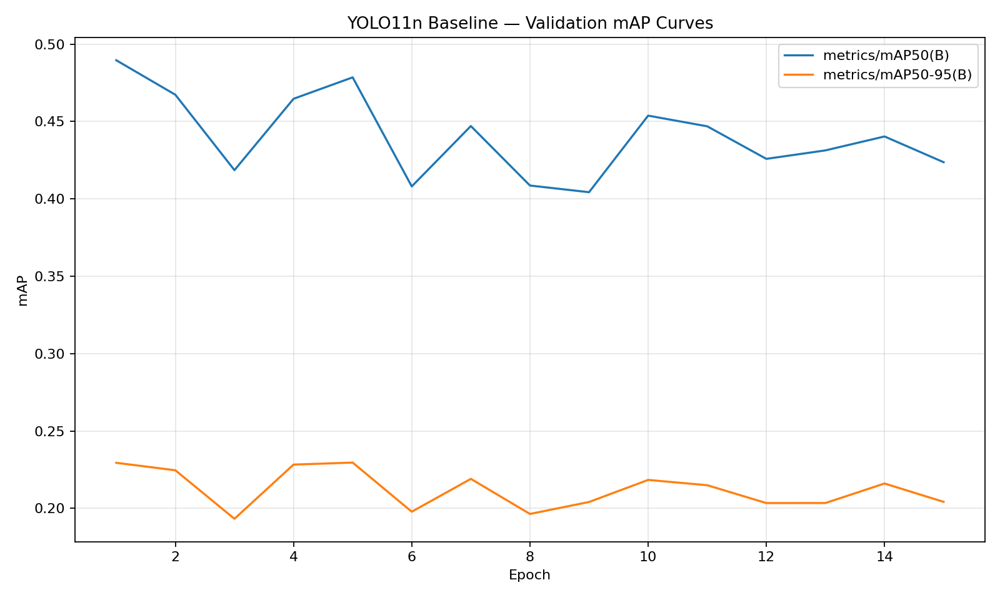

### BoxR_curve.png

`runs/baseline/BoxR_curve.png`

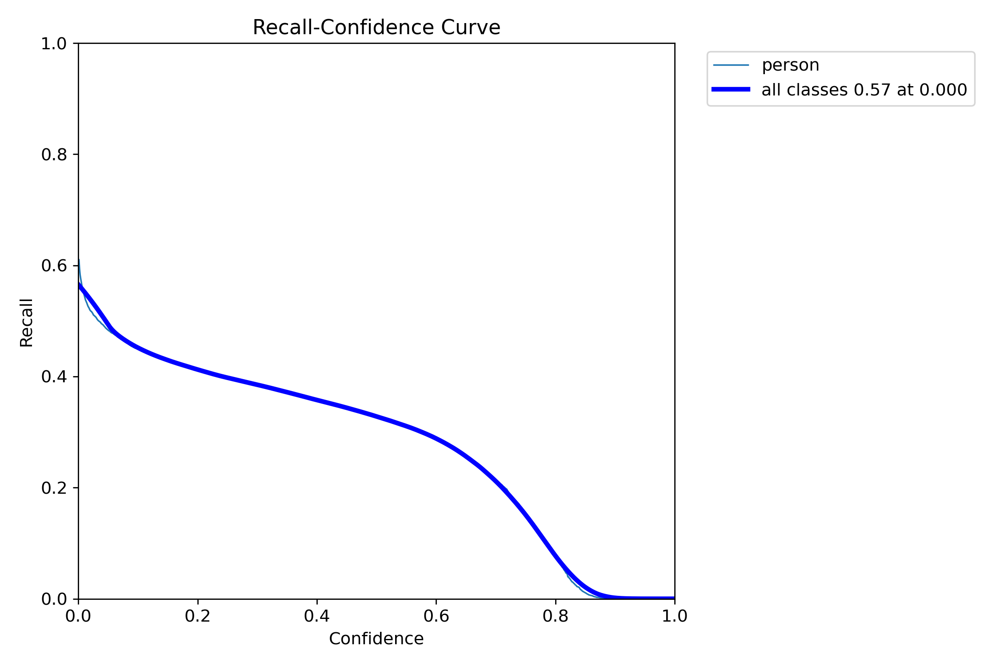

### BoxR_curve.png

`runs/experiment_02/BoxR_curve.png`

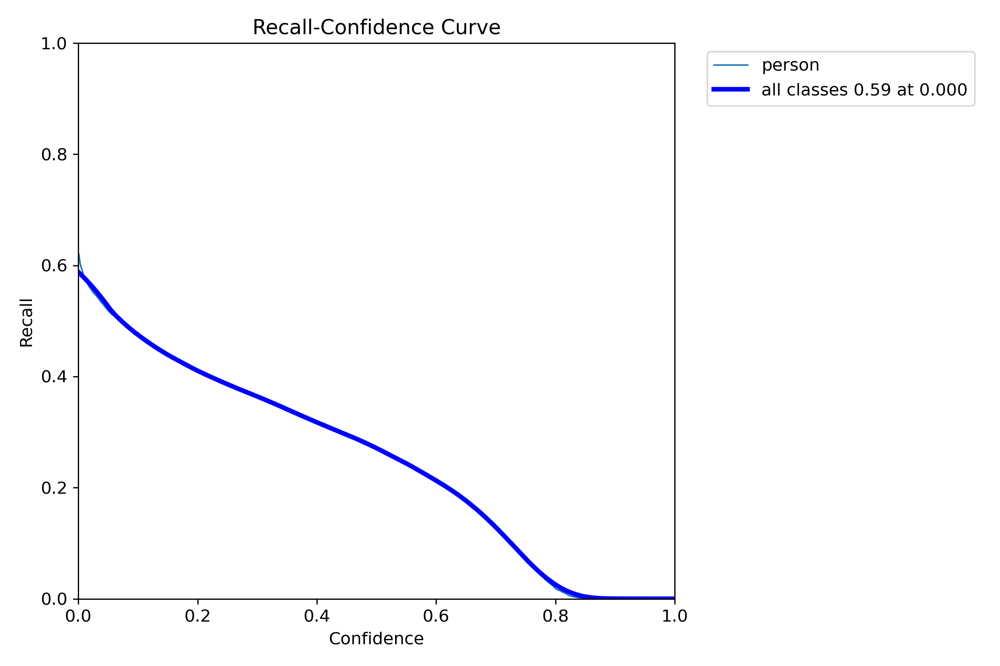

### BoxR_curve.png

`runs/final_test_evaluation/BoxR_curve.png`

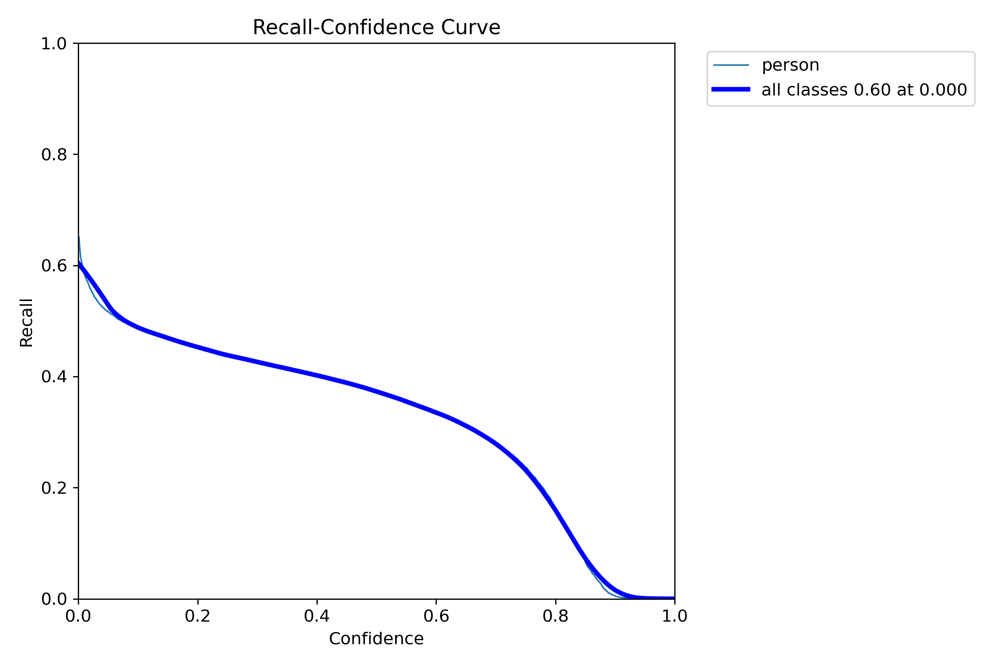

### BoxR_curve.png

`runs/standardized_validation/yolo11n_512_experiment/BoxR_curve.png`

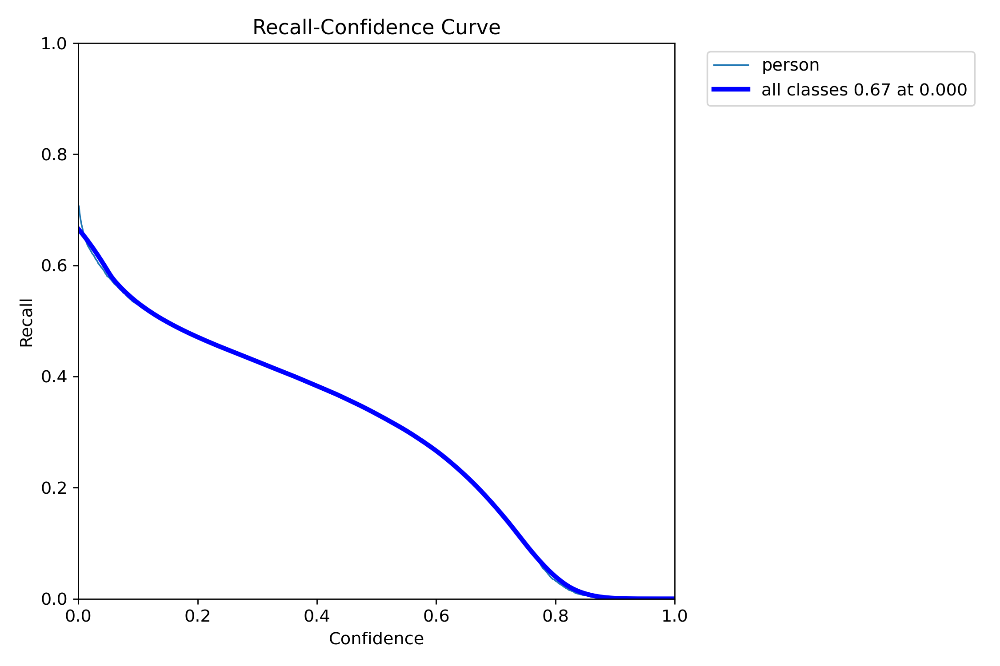

### BoxR_curve.png

`runs/standardized_validation/yolo11n_baseline/BoxR_curve.png`

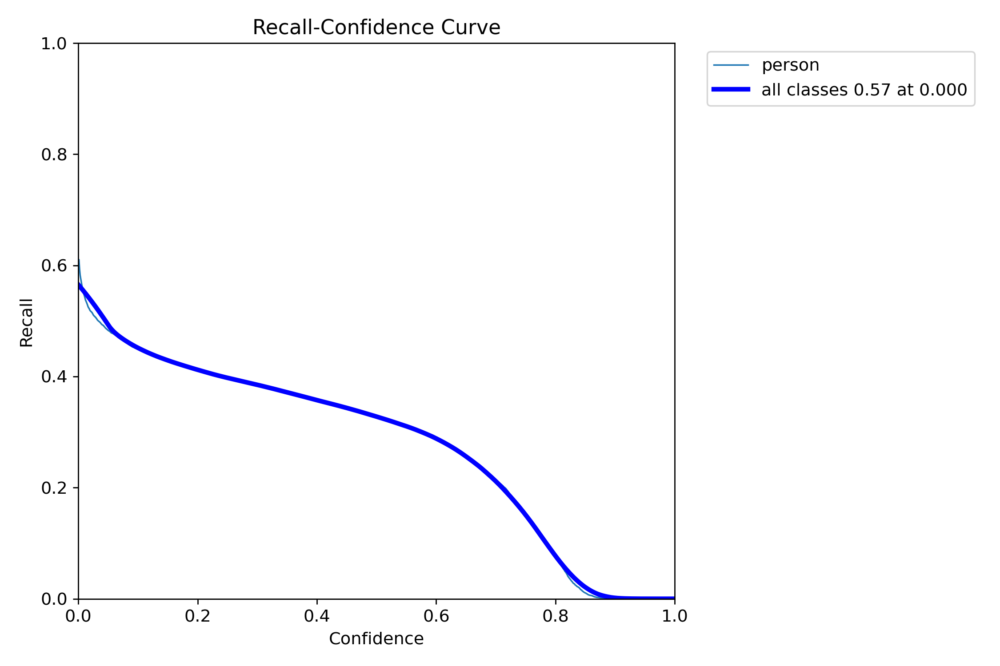

### BoxR_curve.png

`runs/standardized_validation/yolo11n_refined/BoxR_curve.png`

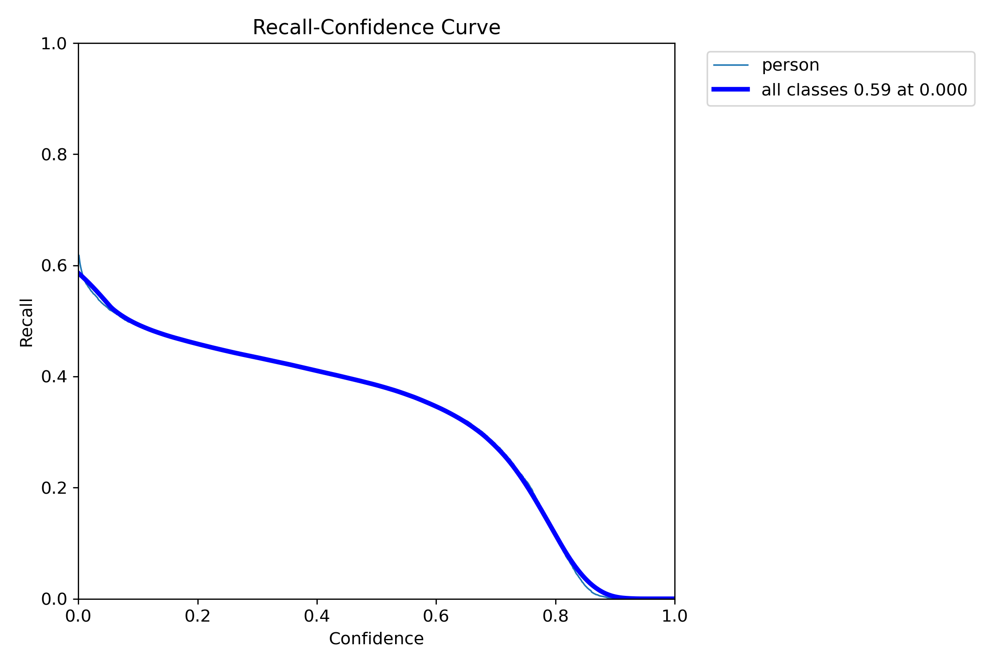

### BoxR_curve.png

`runs/standardized_validation/yolo11s/BoxR_curve.png`

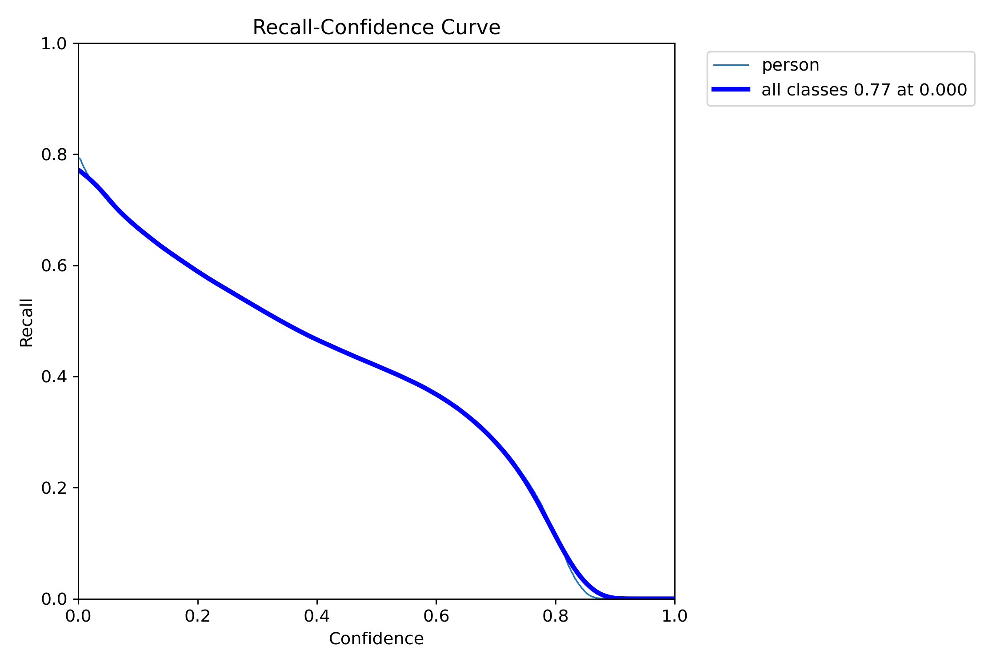

### BoxR_curve.png

`runs/standardized_validation/yolo11s_lr_tuned/BoxR_curve.png`

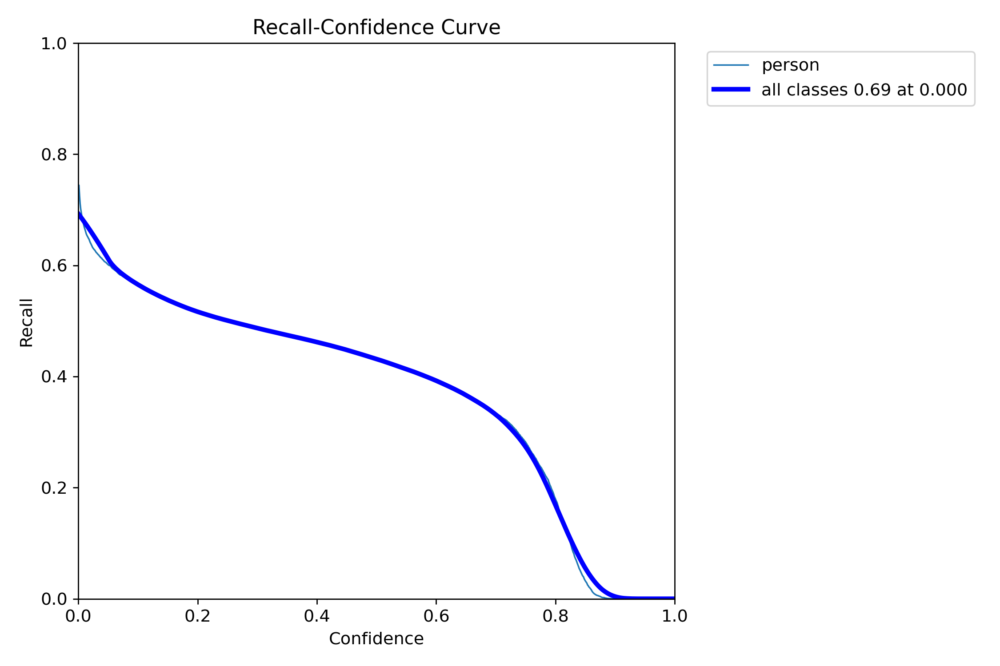

### BoxR_curve.png

`runs/yolo11n_refined/BoxR_curve.png`

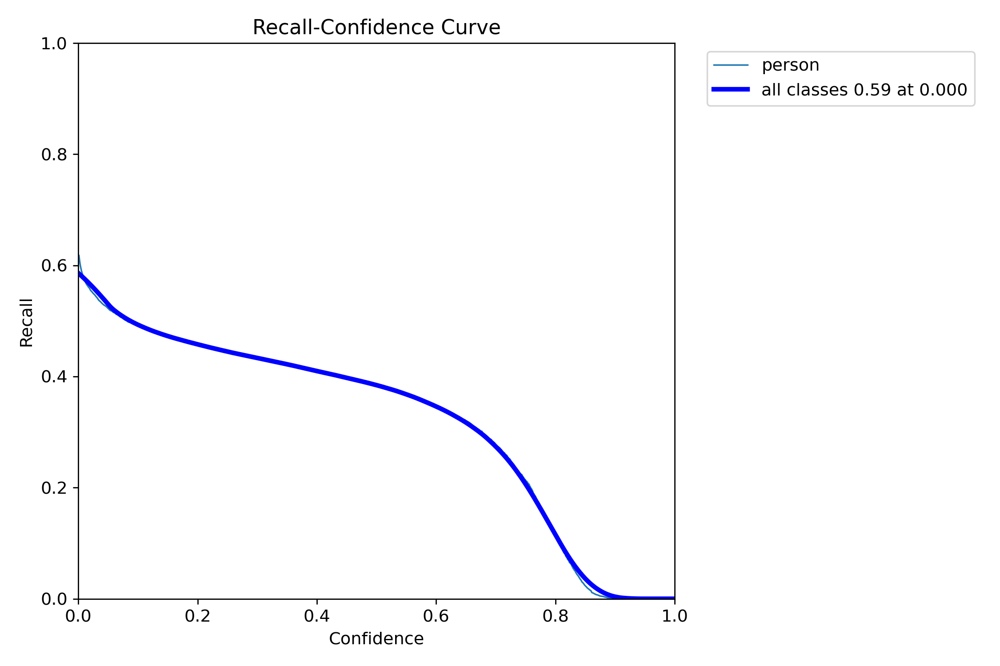

### BoxR_curve.png

`runs/yolo11s/BoxR_curve.png`

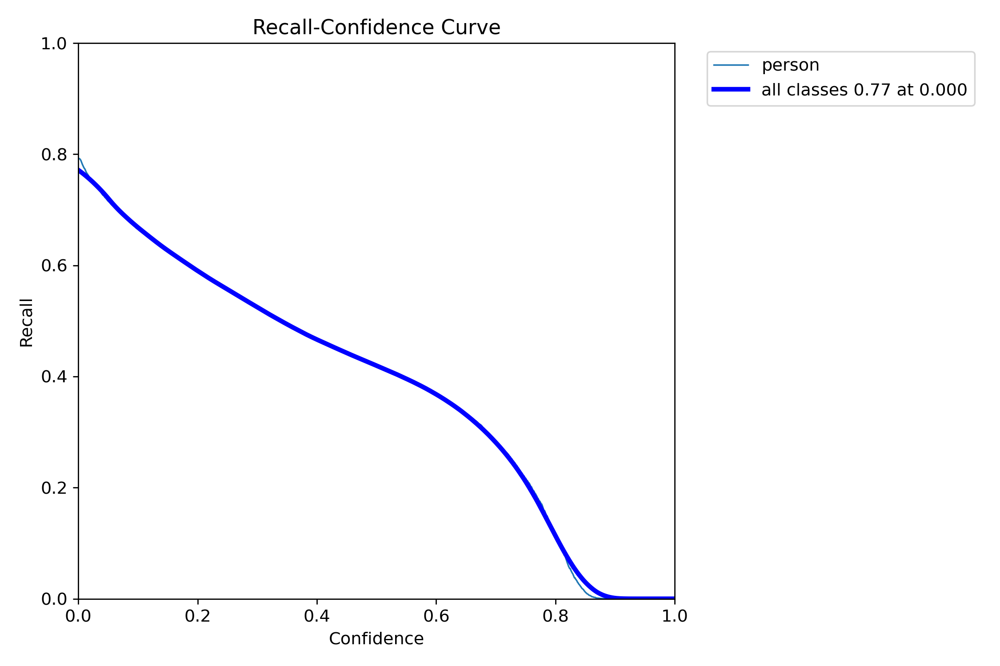

### BoxR_curve.png

`runs/yolo11s_lr_tuned/BoxR_curve.png`

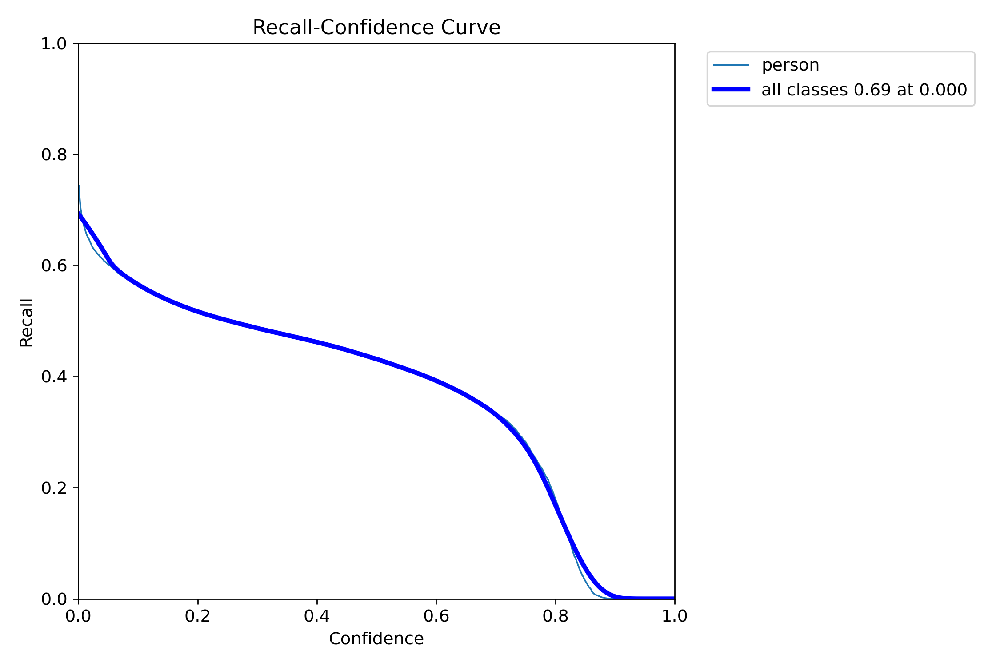

### all_models_map50_curves.png

`visualizations/all_models_map50_curves.png`

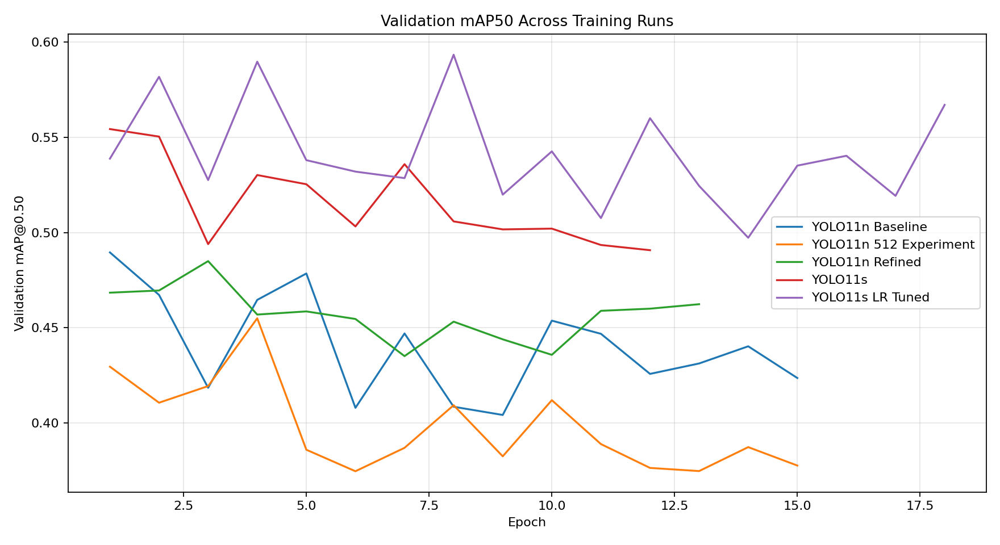

### validation_comparison_f1.png

`visualizations/validation_comparison_f1.png`

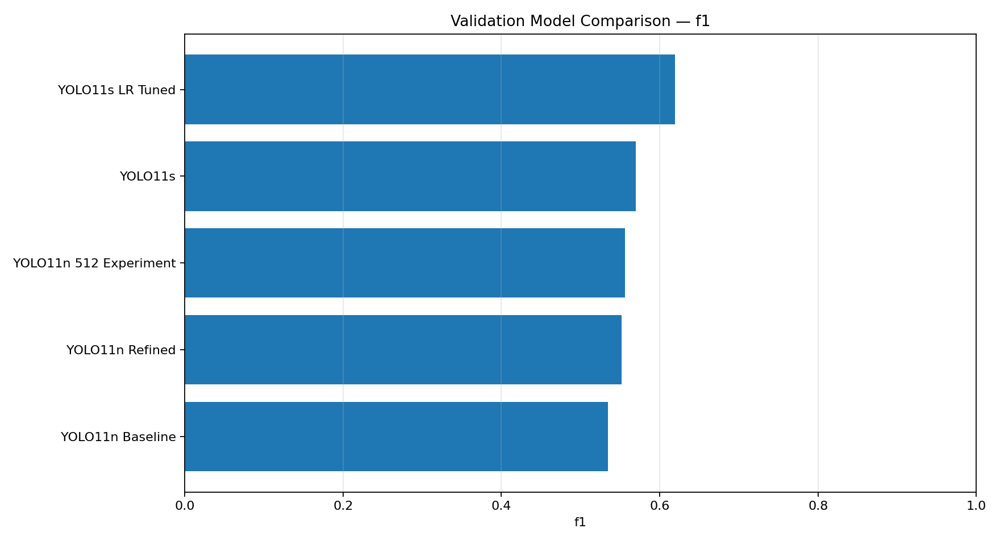

### validation_comparison_mAP50.png

`visualizations/validation_comparison_mAP50.png`

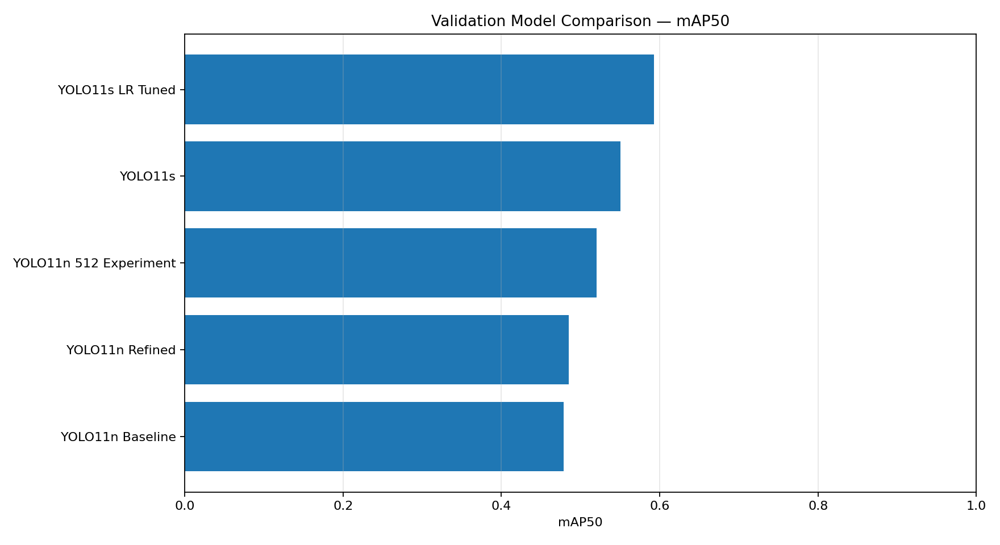

### validation_comparison_mAP50_95.png

`visualizations/validation_comparison_mAP50_95.png`

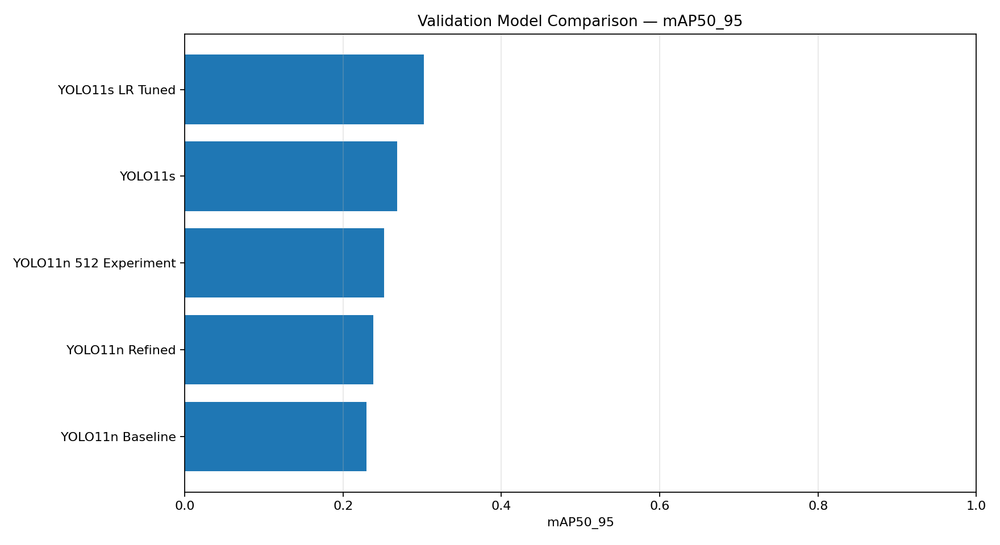

### validation_comparison_precision.png

`visualizations/validation_comparison_precision.png`

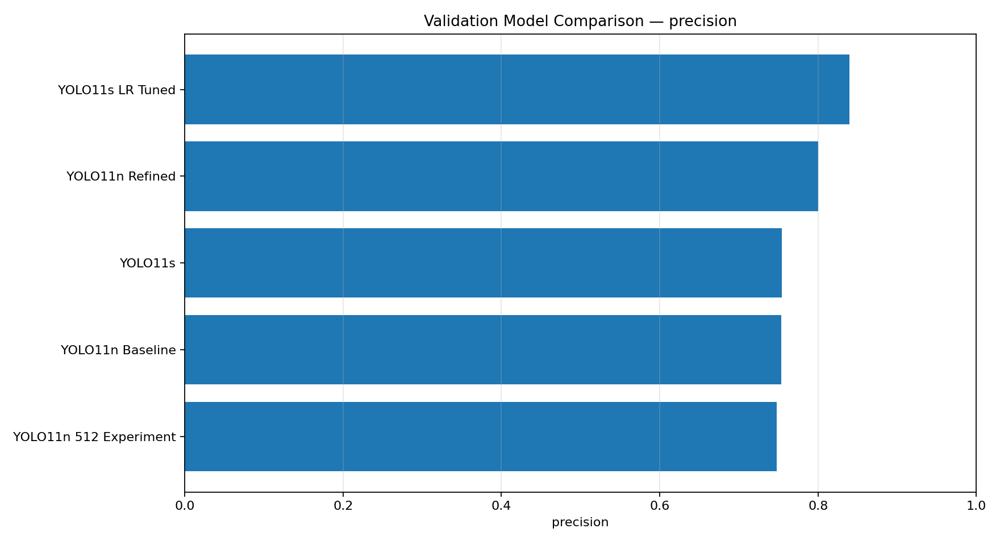

### validation_comparison_recall.png

`visualizations/validation_comparison_recall.png`

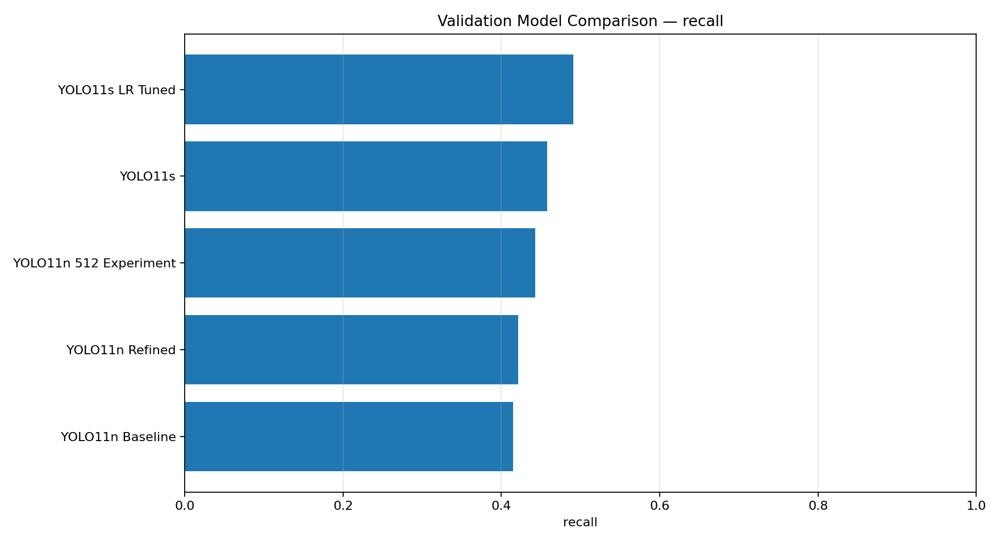

### final_test_metrics.png

`visualizations/final_test_metrics.png`

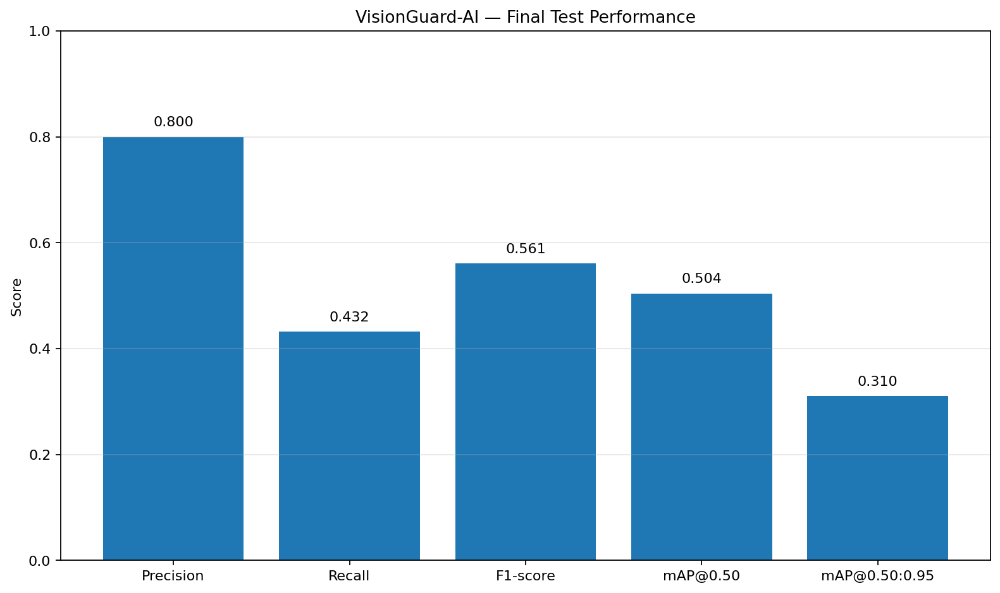

### five_test_predictions.png

`predictions/final_test_conf005/five_test_predictions.png`

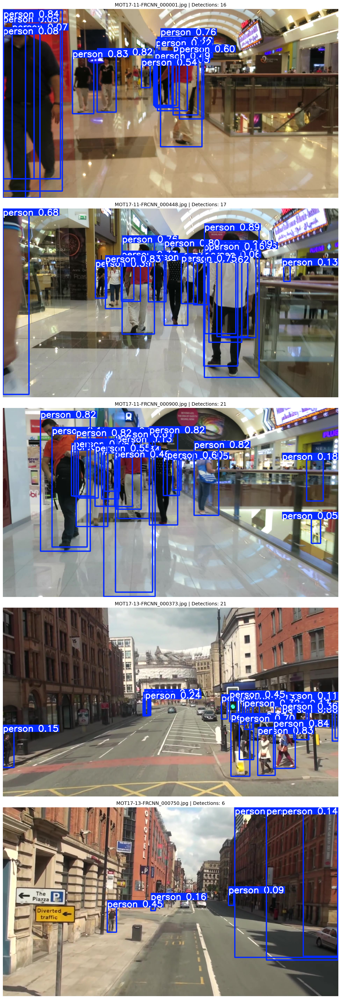

### ground_truth_vs_predictions.png

`predictions/final_test_conf005/ground_truth_vs_predictions.png`

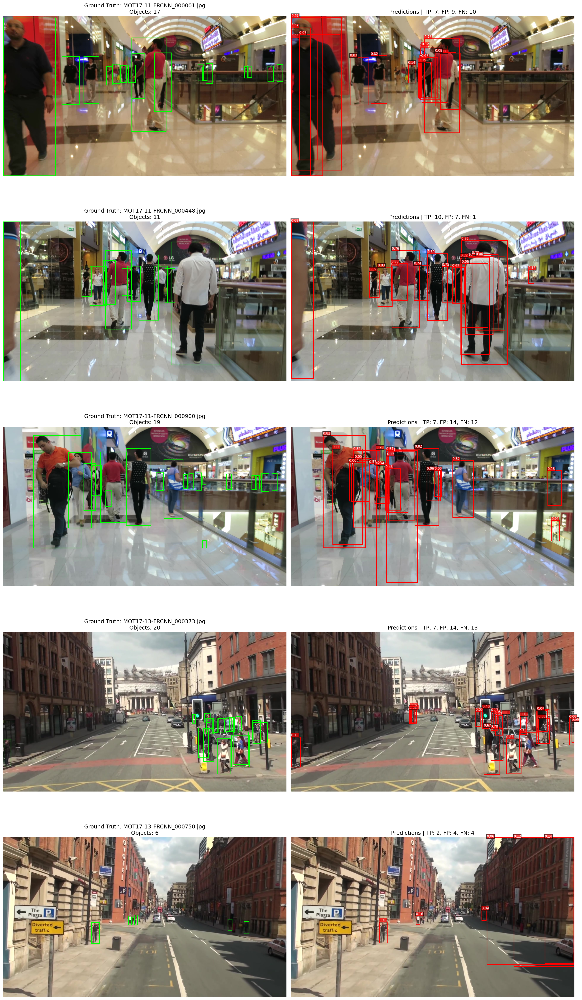

### MOT17-11-FRCNN_000001_prediction.jpg

`predictions/production_inference/MOT17-11-FRCNN_000001_prediction.jpg`

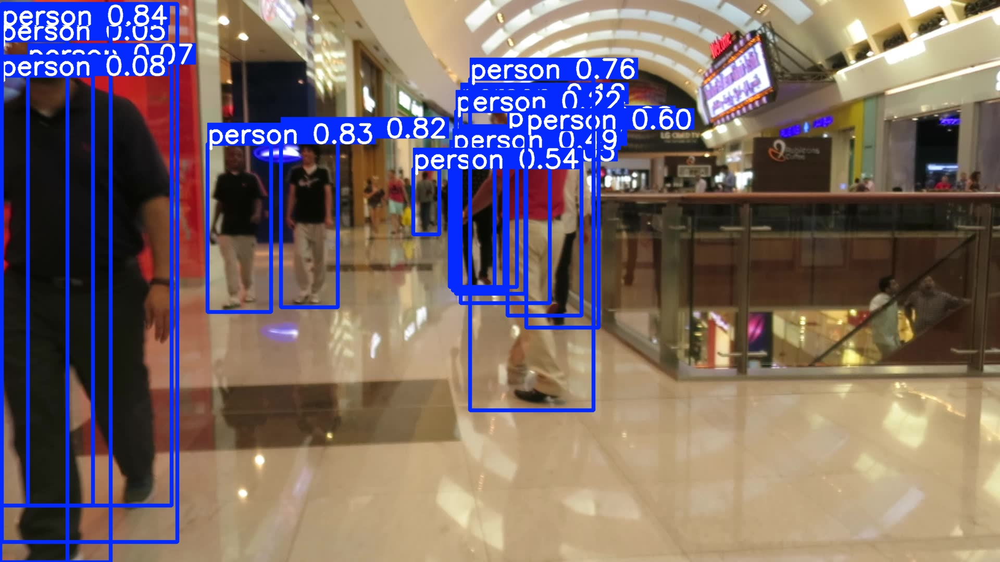

### baseline_loss_curves.png

`visualizations/baseline_loss_curves.png`

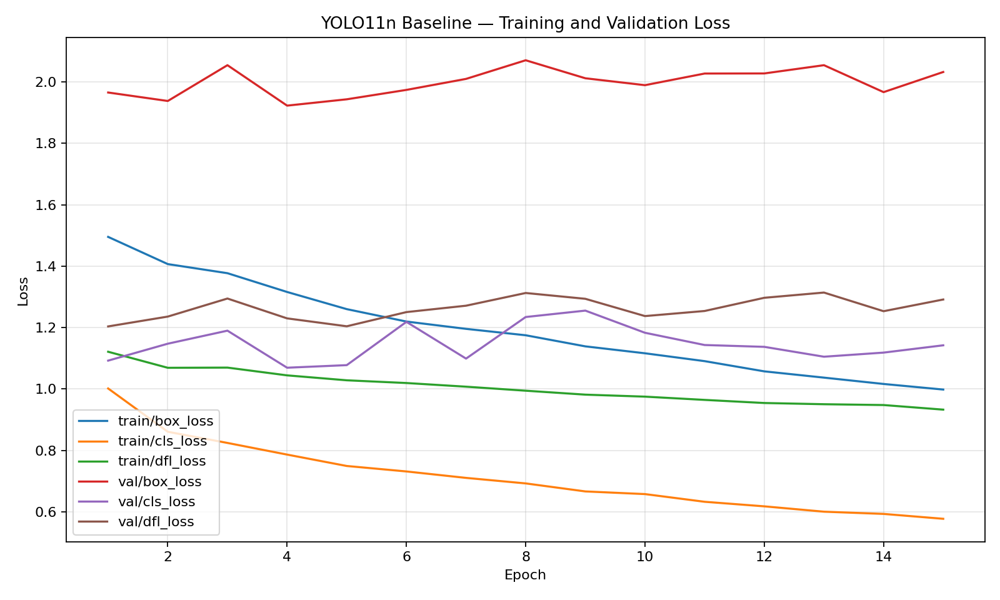

### MOT17-11-FRCNN_000001.jpg

`predictions/final_test_conf005/MOT17-11-FRCNN_000001.jpg`

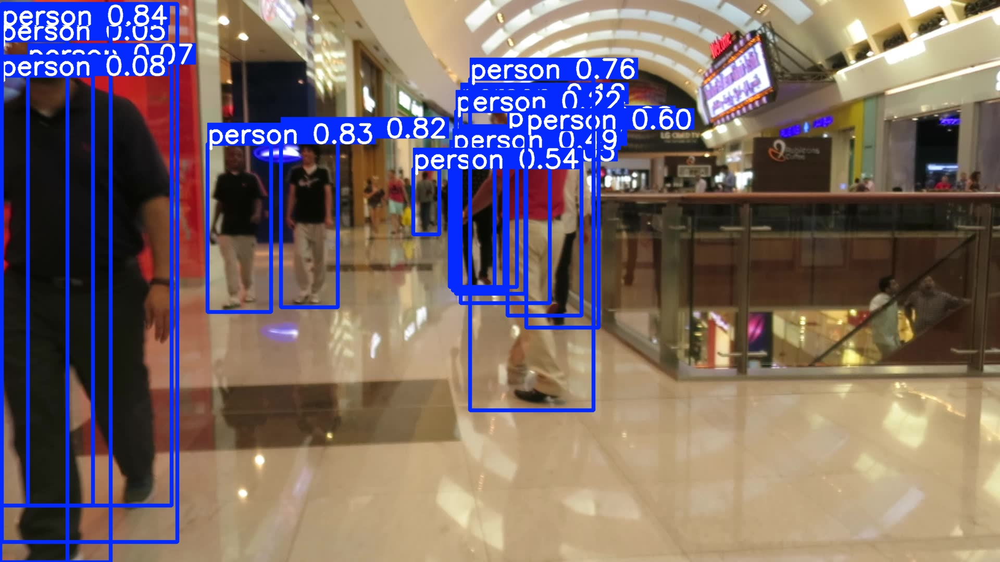

### MOT17-11-FRCNN_000448.jpg

`predictions/final_test_conf005/MOT17-11-FRCNN_000448.jpg`

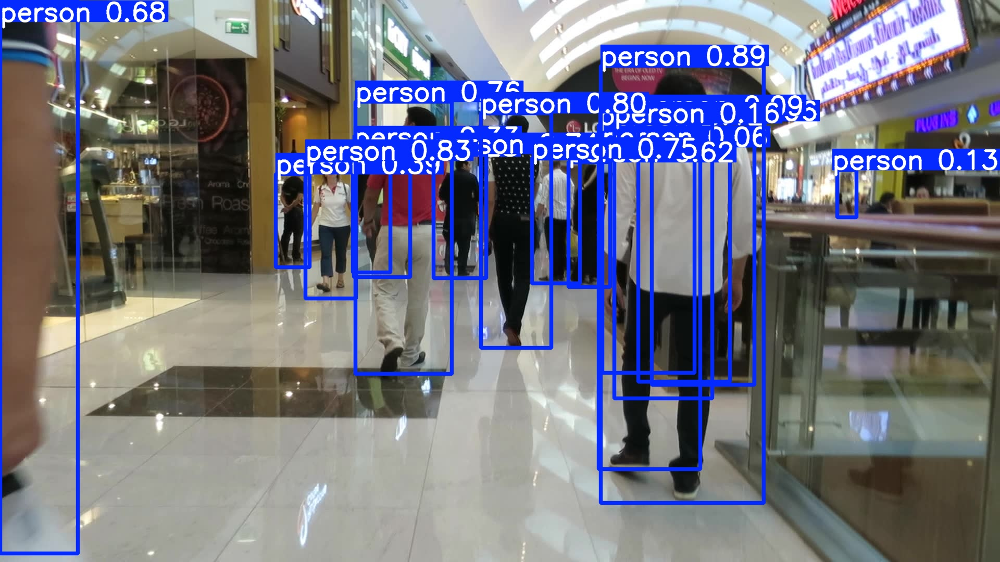

### MOT17-11-FRCNN_000900.jpg

`predictions/final_test_conf005/MOT17-11-FRCNN_000900.jpg`

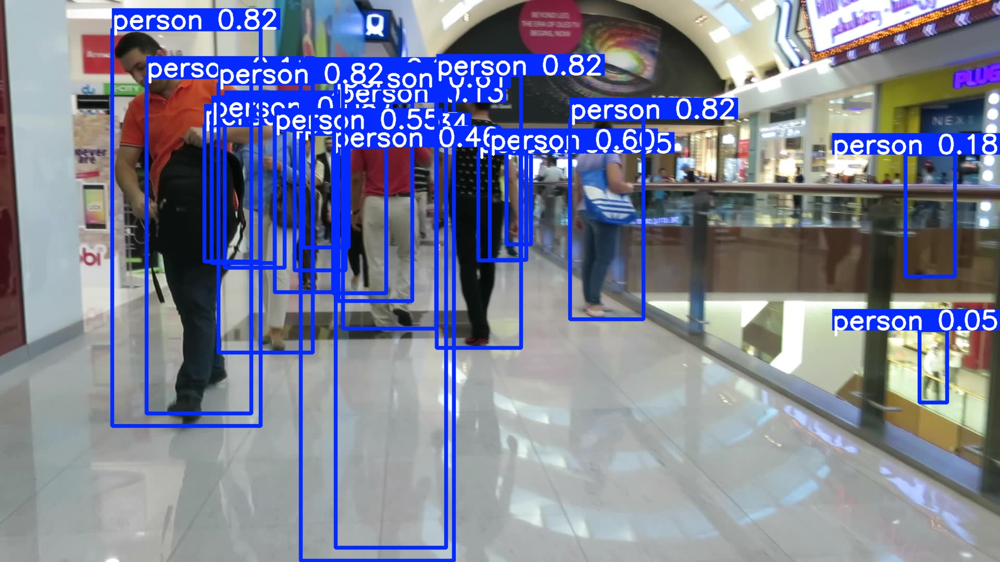

### MOT17-13-FRCNN_000373.jpg

`predictions/final_test_conf005/MOT17-13-FRCNN_000373.jpg`

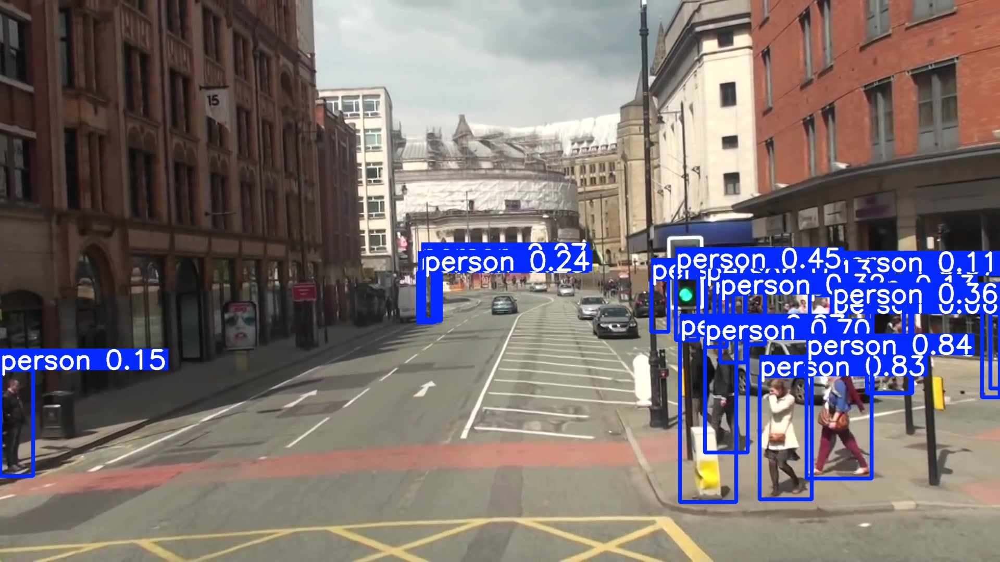

### MOT17-13-FRCNN_000750.jpg

`predictions/final_test_conf005/MOT17-13-FRCNN_000750.jpg`

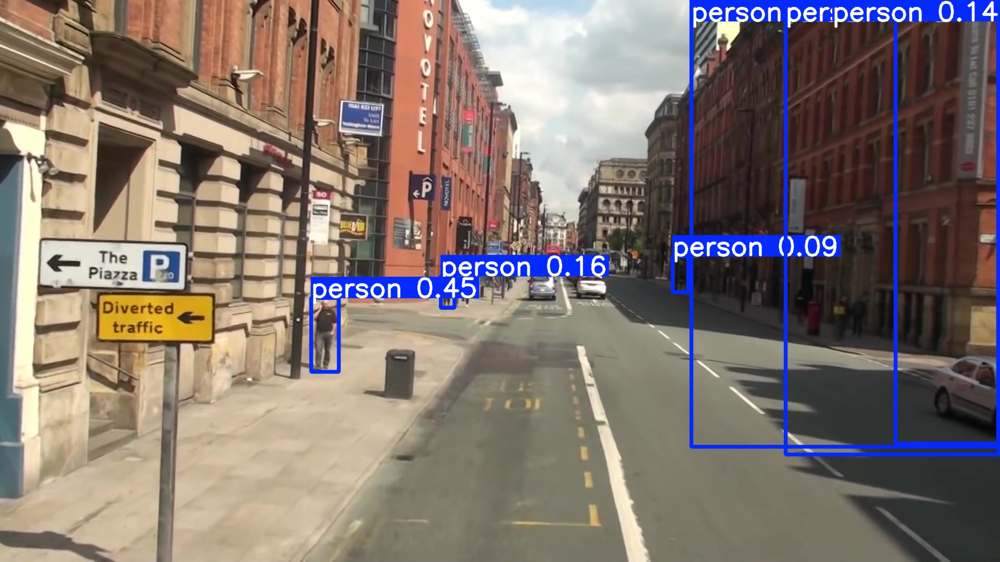

### MOT17-11-FRCNN_000055.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000055.jpg`

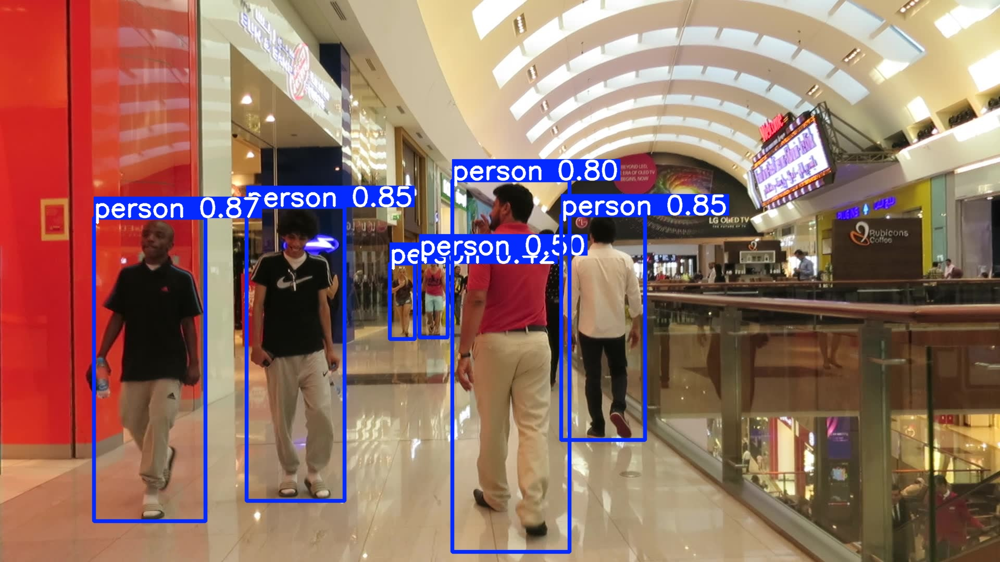

### MOT17-11-FRCNN_000235.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000235.jpg`

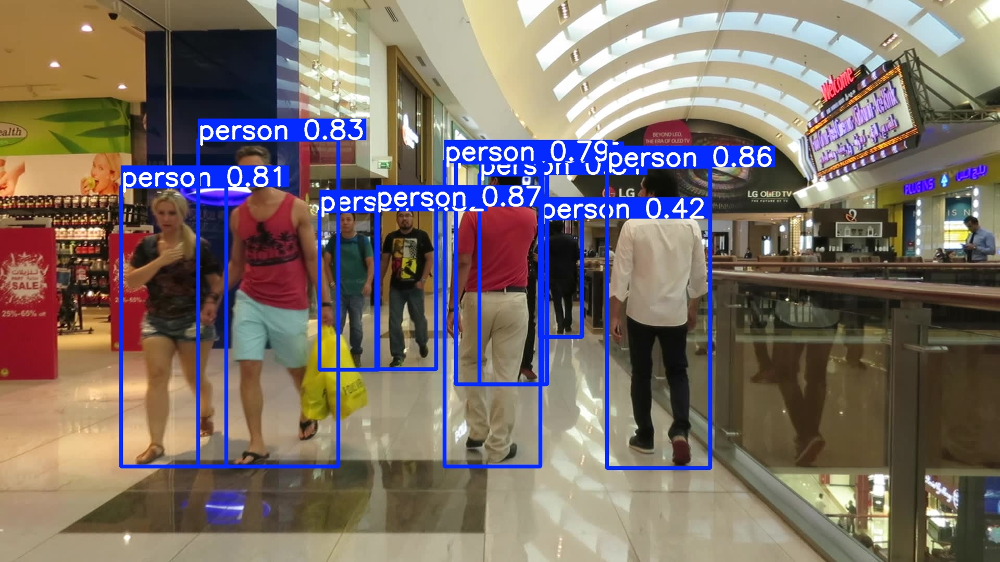

### MOT17-11-FRCNN_000258.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000258.jpg`

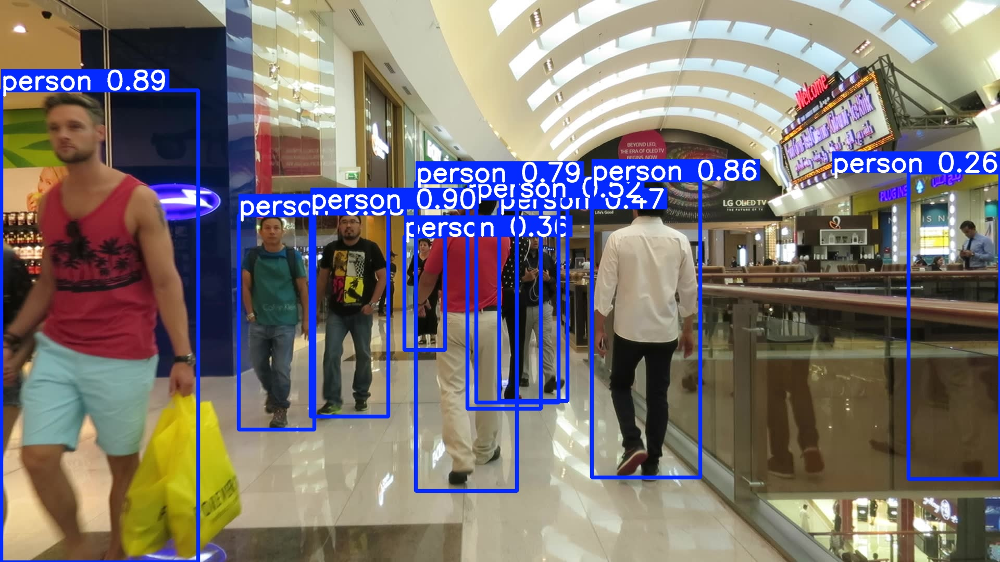

### MOT17-11-FRCNN_000321.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000321.jpg`

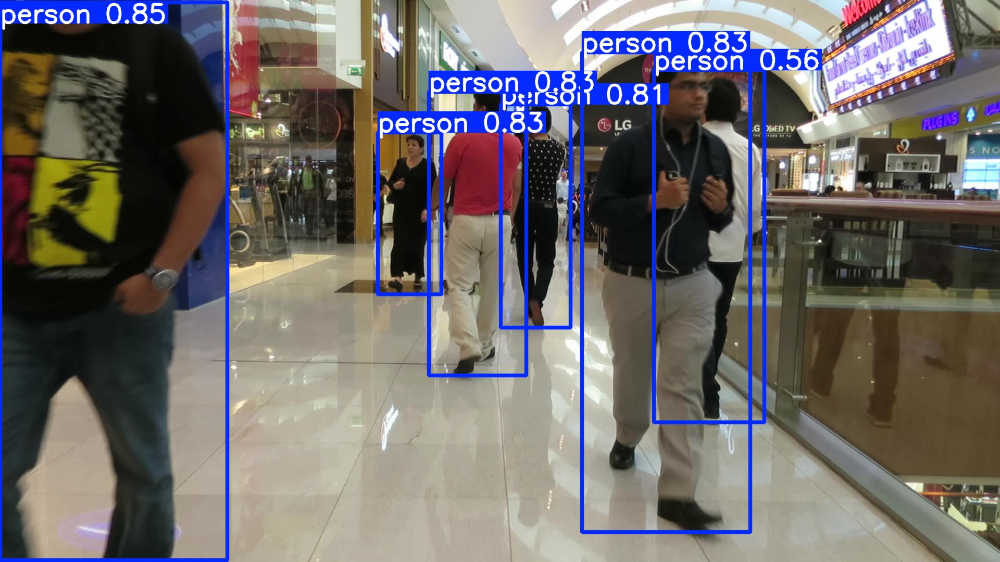

### MOT17-11-FRCNN_000516.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000516.jpg`

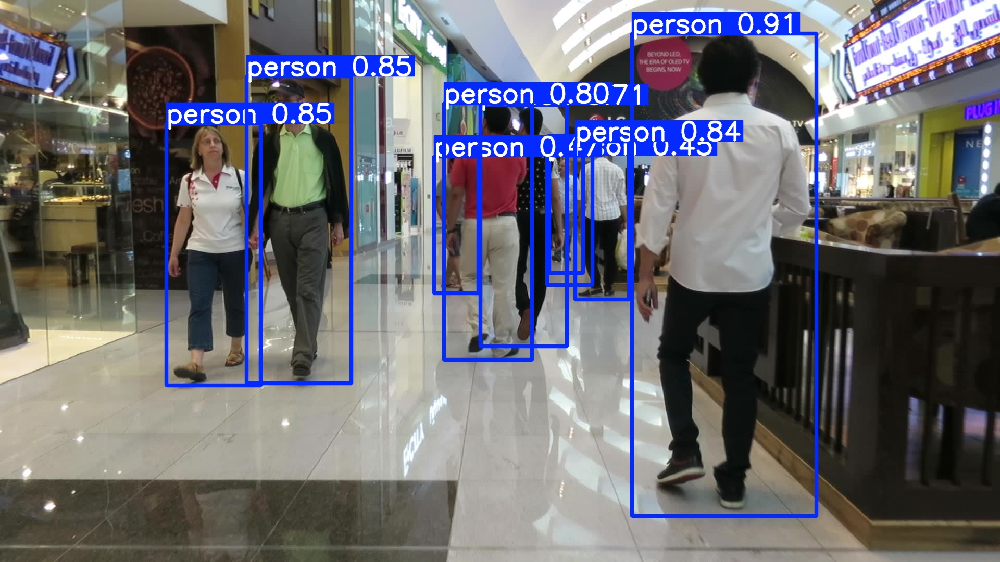

### MOT17-11-FRCNN_000565.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000565.jpg`

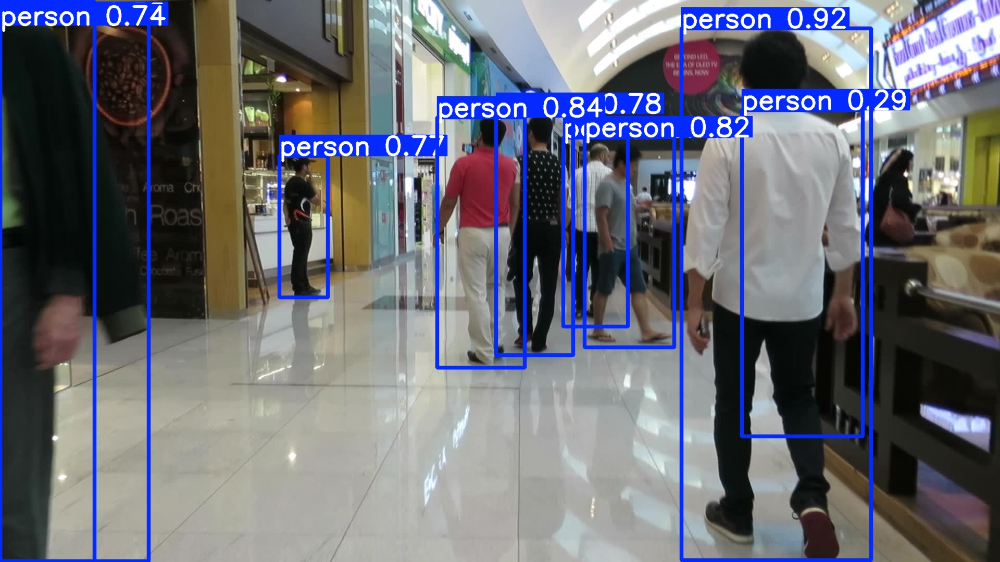

### MOT17-11-FRCNN_000633.jpg

`predictions/test/visual_samples/MOT17-11-FRCNN_000633.jpg`

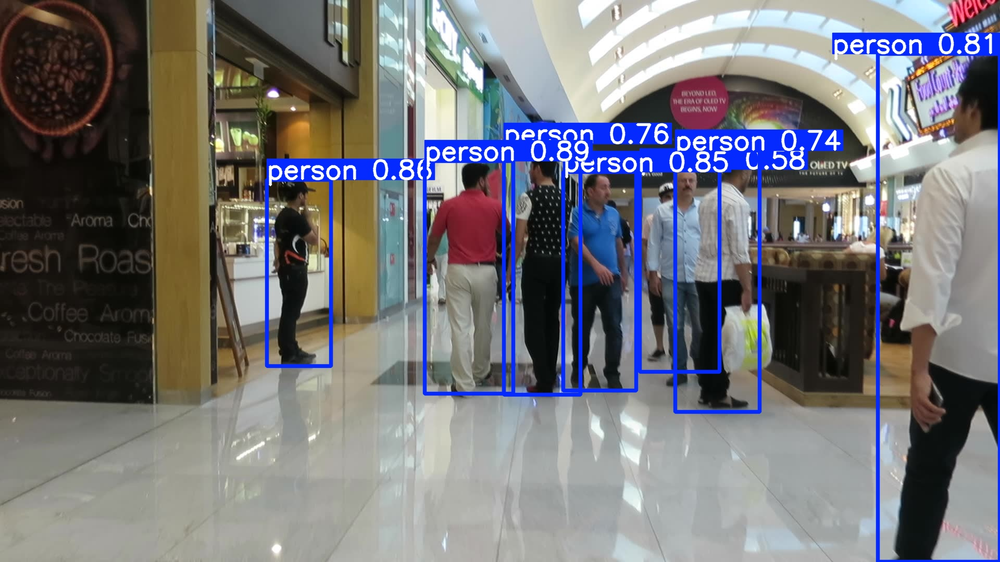

### MOT17-13-FRCNN_000479.jpg

`predictions/test/visual_samples/MOT17-13-FRCNN_000479.jpg`

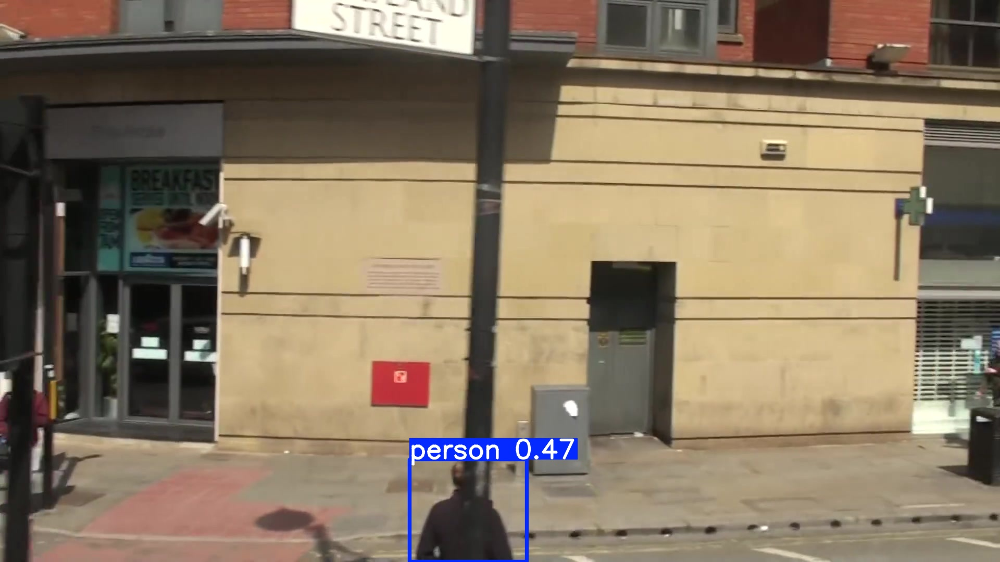

### MOT17-13-FRCNN_000667.jpg

`predictions/test/visual_samples/MOT17-13-FRCNN_000667.jpg`

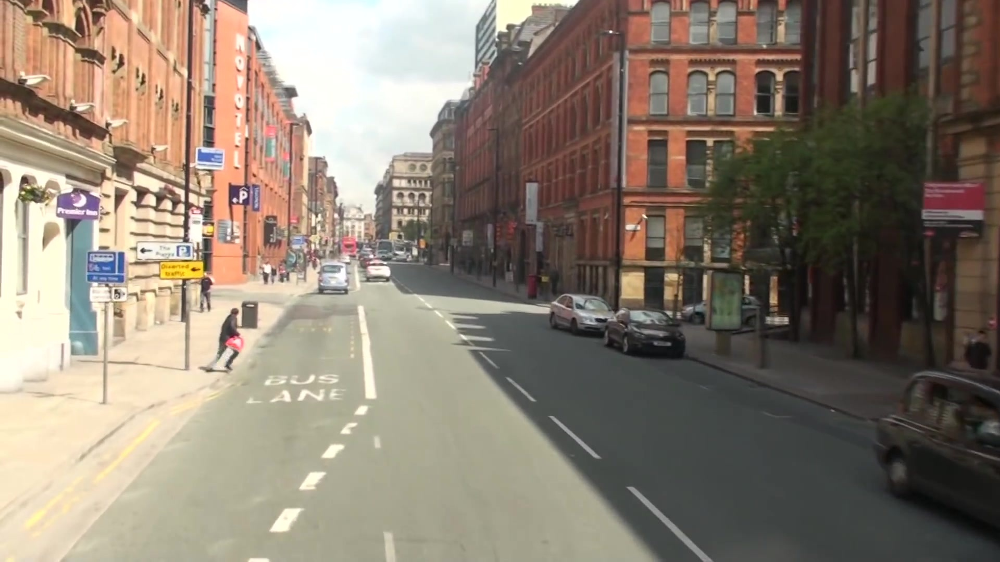

### MOT17-13-FRCNN_000674.jpg

`predictions/test/visual_samples/MOT17-13-FRCNN_000674.jpg`

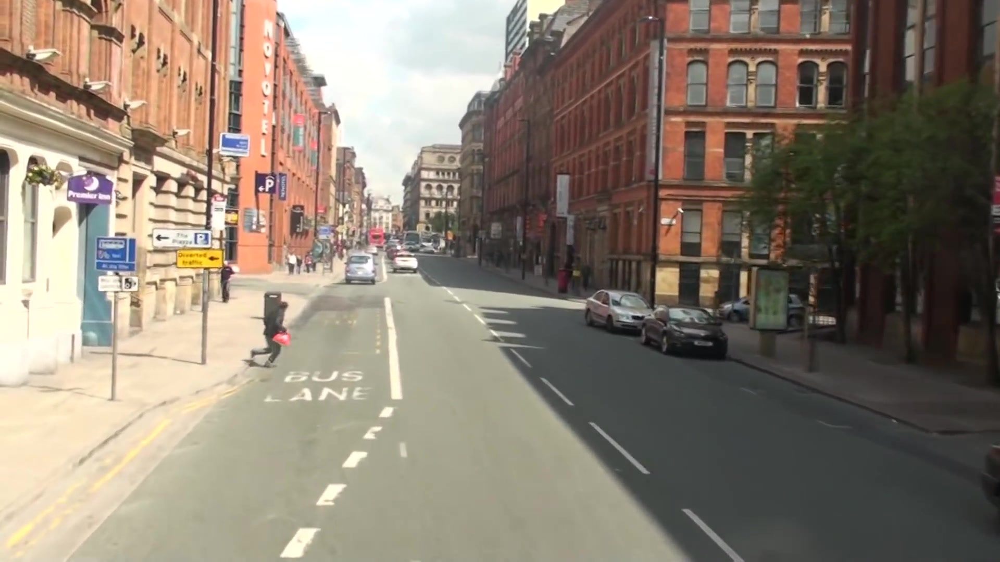

### labels.jpg

`runs/baseline/labels.jpg`

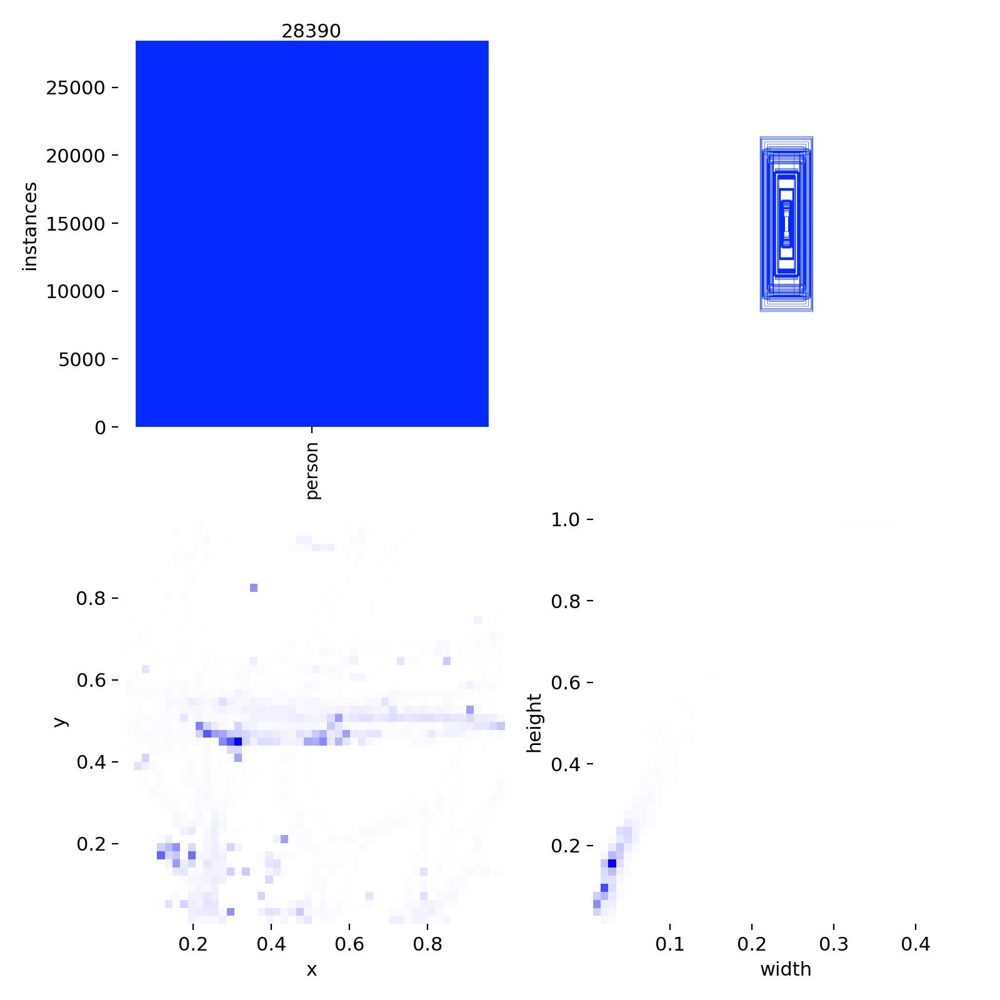

### results.png

`runs/baseline/results.png`

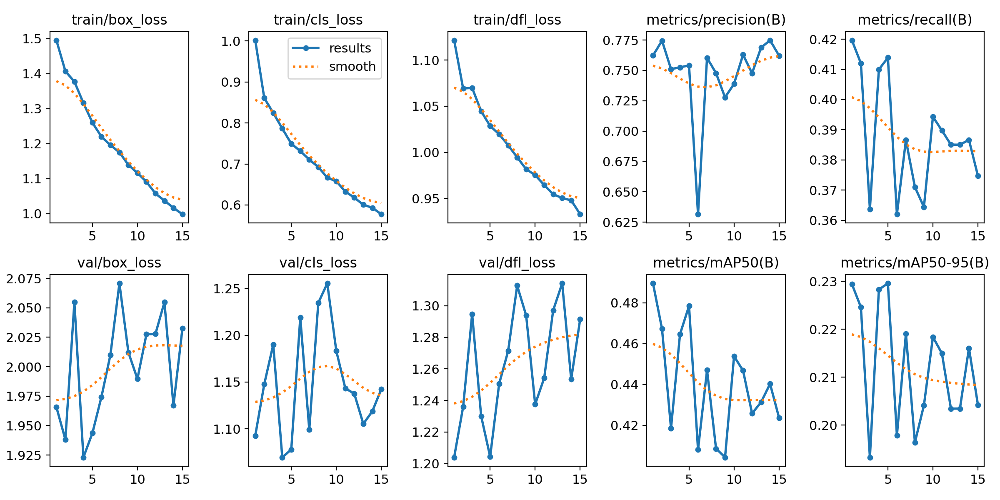

### train_batch0.jpg

`runs/baseline/train_batch0.jpg`

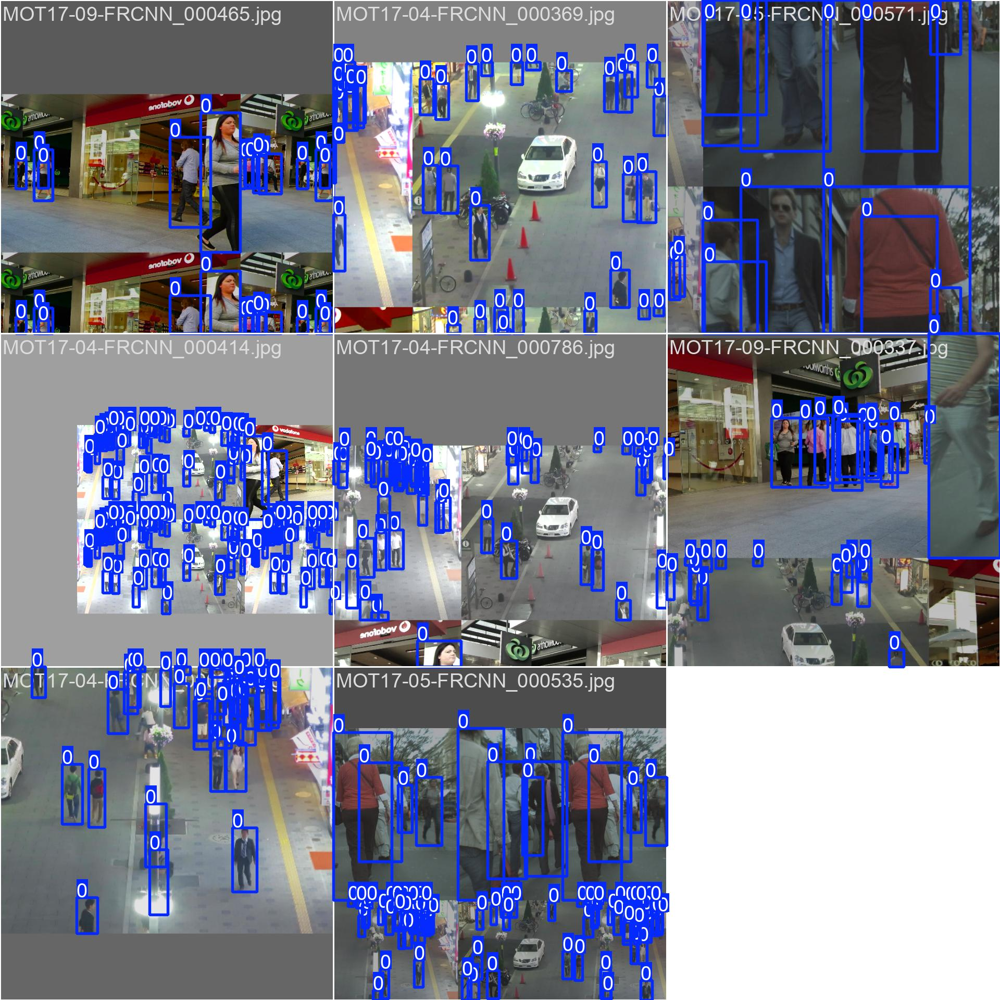

### train_batch1.jpg

`runs/baseline/train_batch1.jpg`

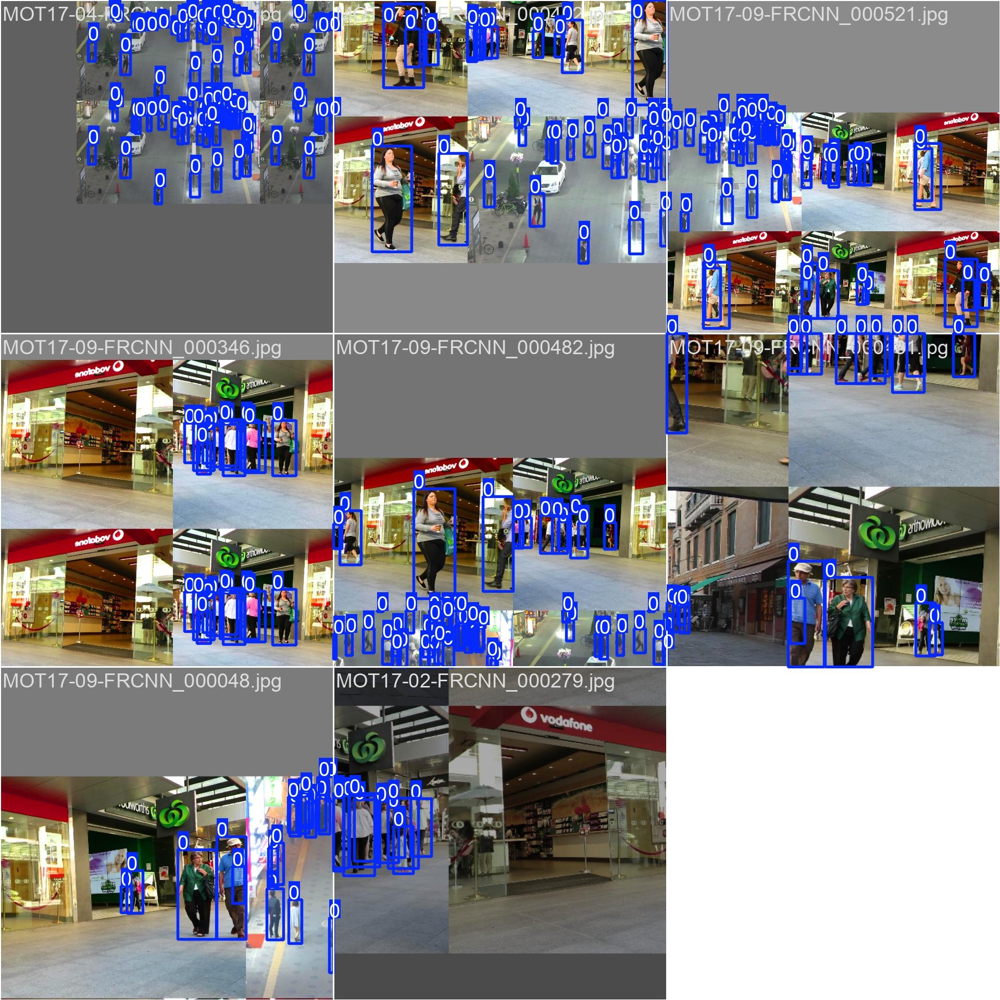

### train_batch2.jpg

`runs/baseline/train_batch2.jpg`

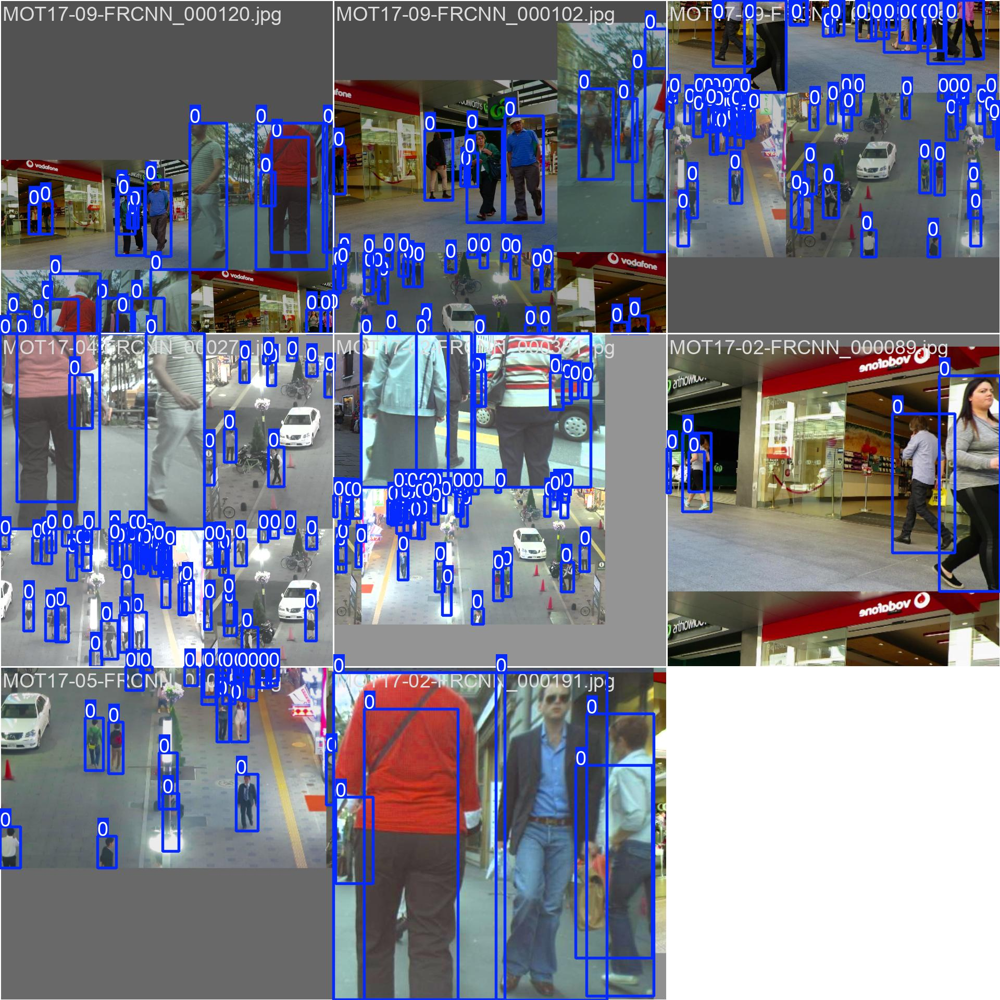

### train_batch750.jpg

`runs/baseline/train_batch750.jpg`

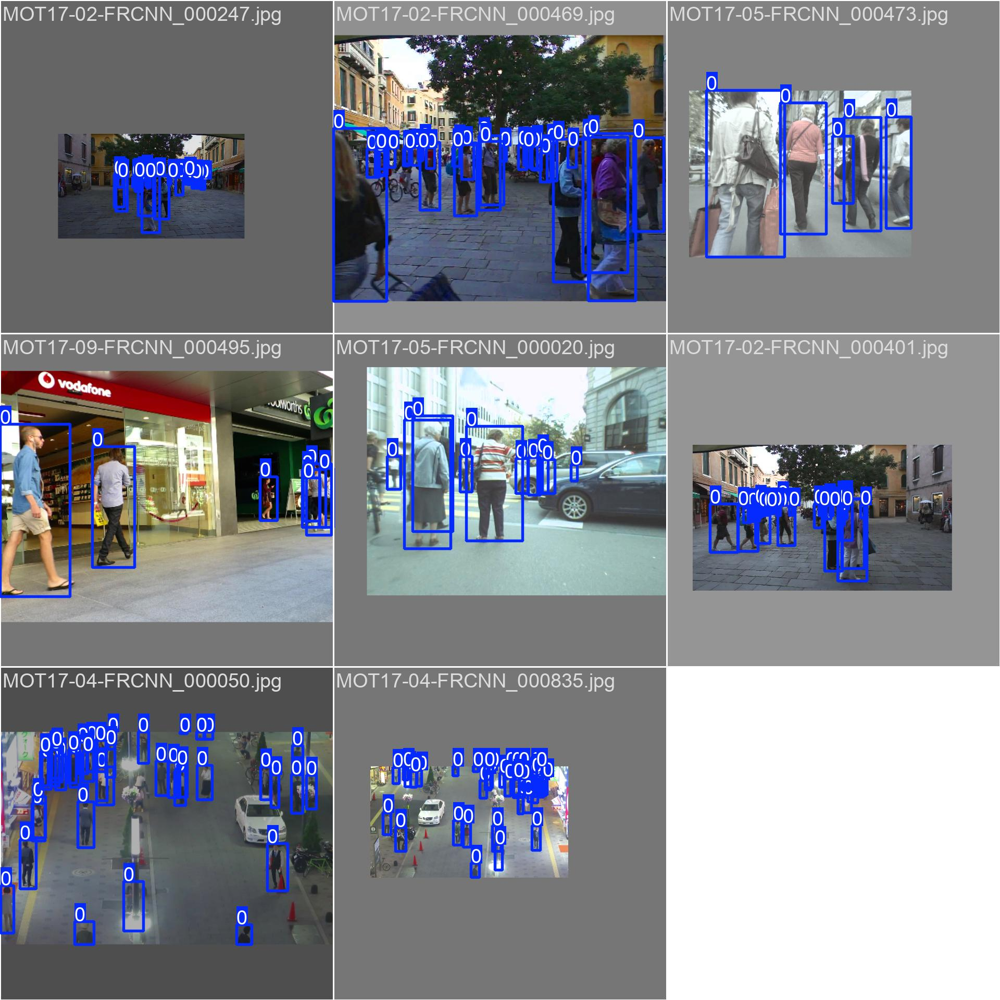

### train_batch751.jpg

`runs/baseline/train_batch751.jpg`

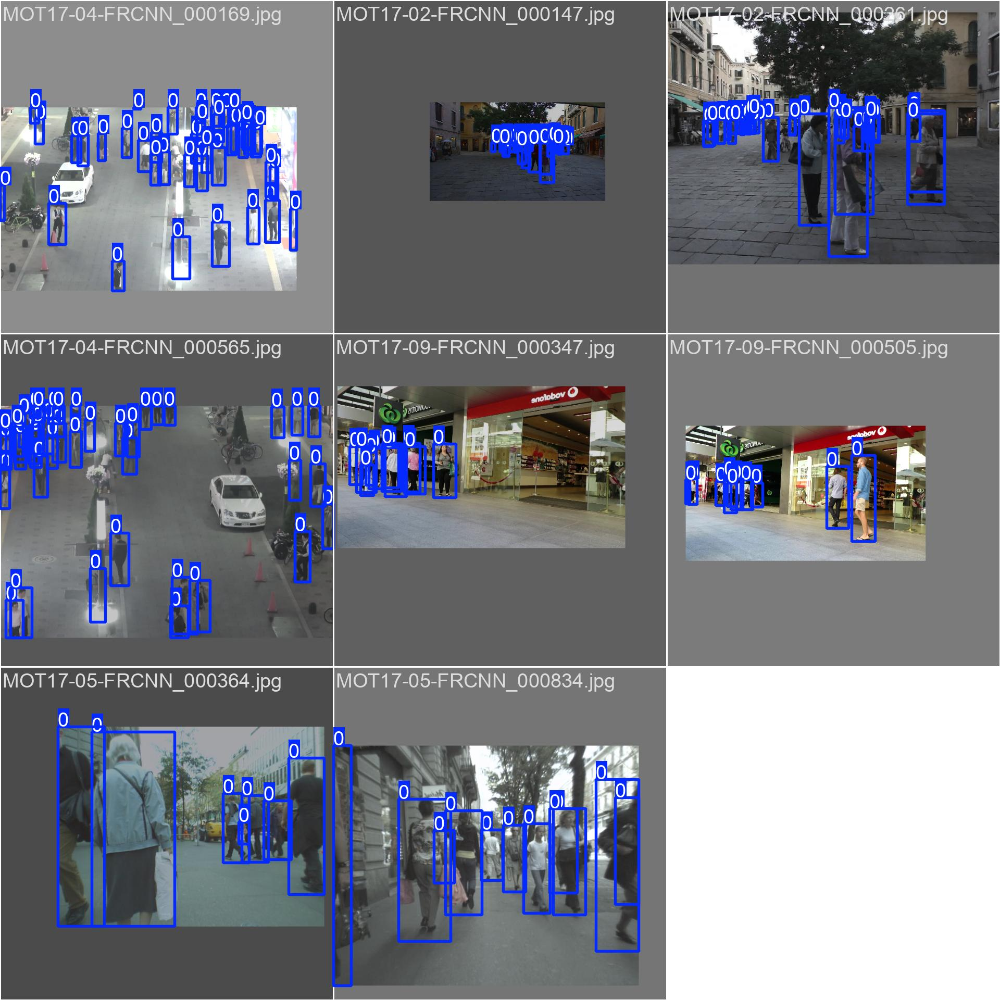

### train_batch752.jpg

`runs/baseline/train_batch752.jpg`

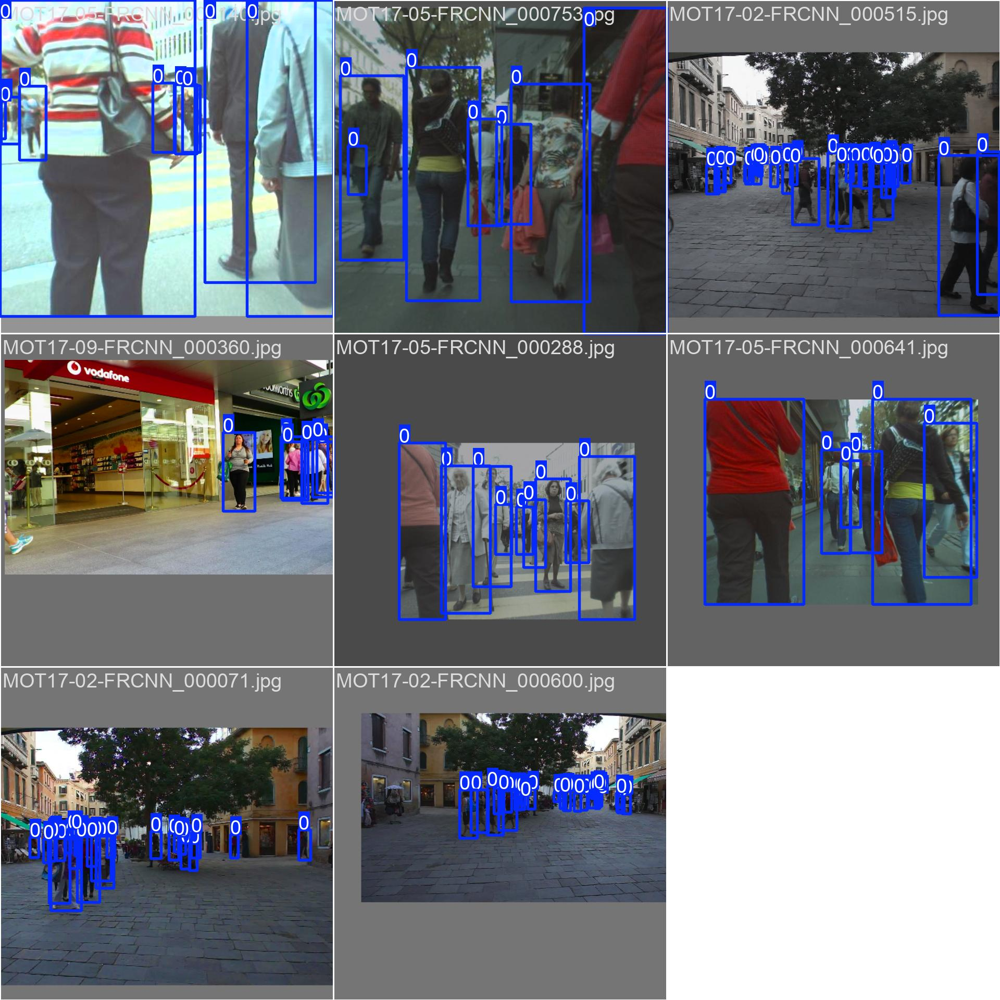

### val_batch0_labels.jpg

`runs/baseline/val_batch0_labels.jpg`

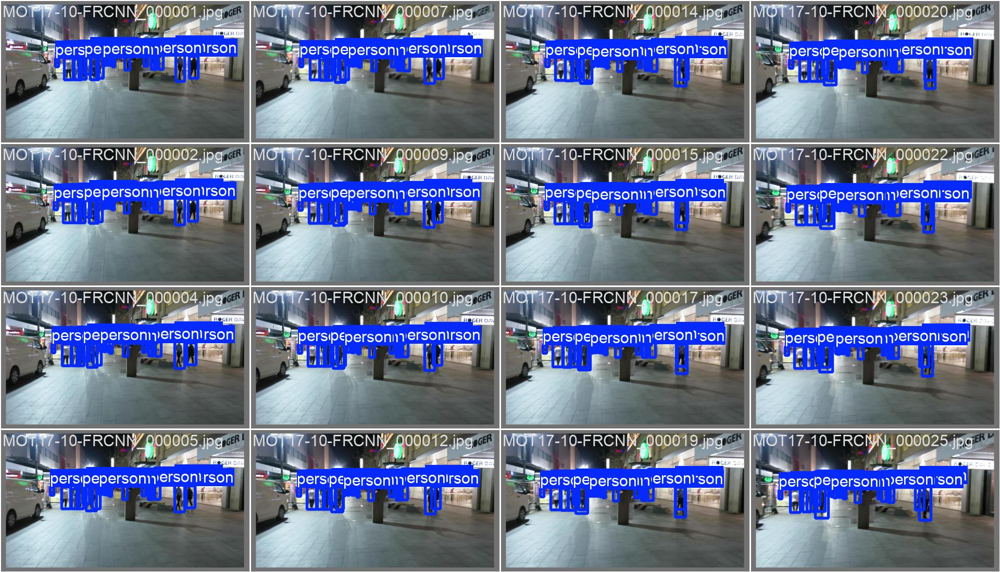

### val_batch0_pred.jpg

`runs/baseline/val_batch0_pred.jpg`

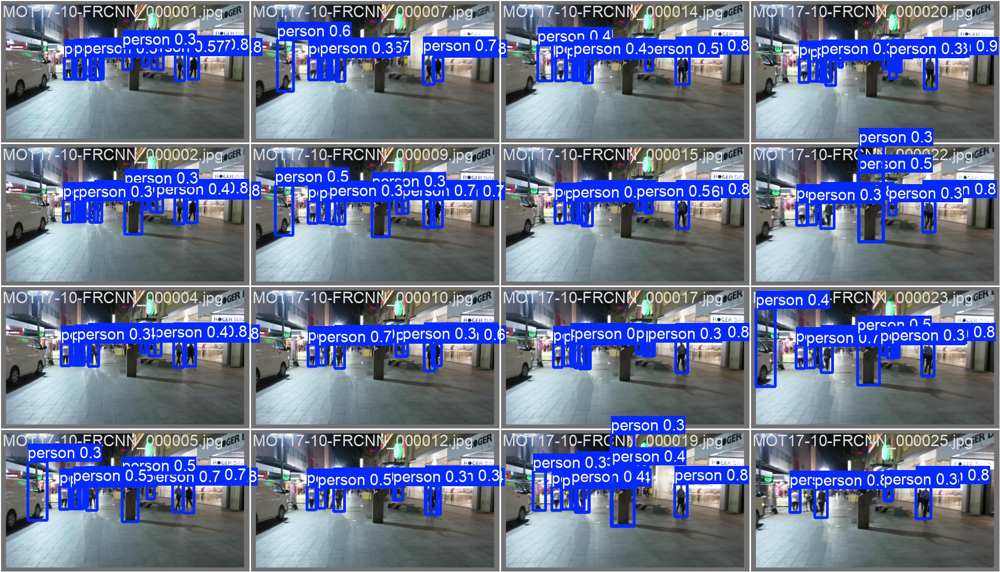

### val_batch1_labels.jpg

`runs/baseline/val_batch1_labels.jpg`

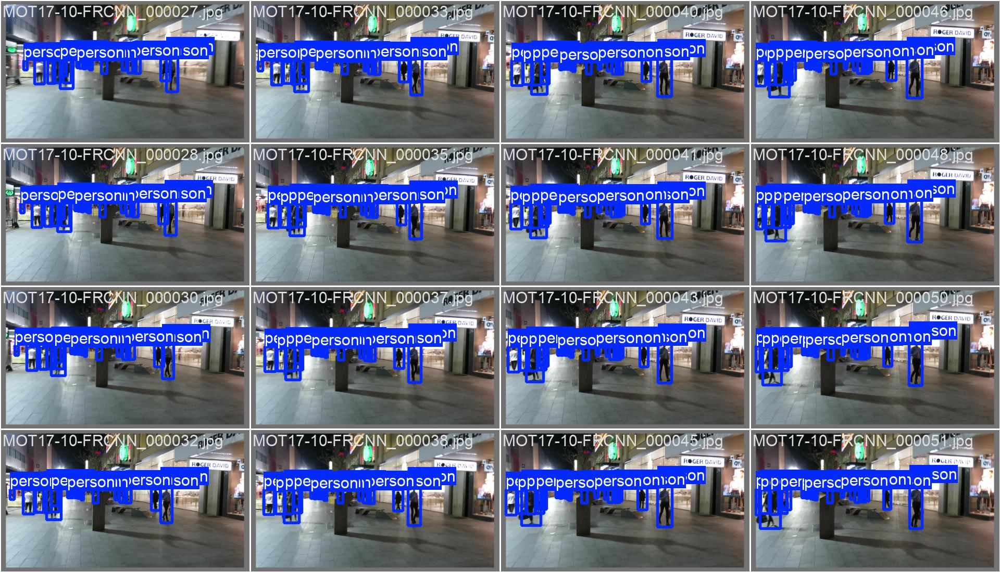

### val_batch1_pred.jpg

`runs/baseline/val_batch1_pred.jpg`

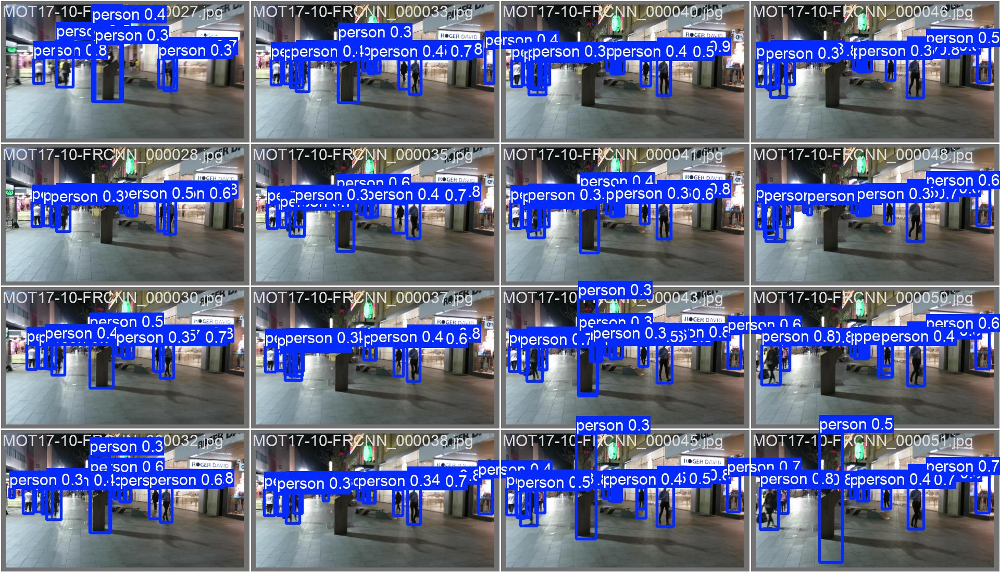

### val_batch2_labels.jpg

`runs/baseline/val_batch2_labels.jpg`

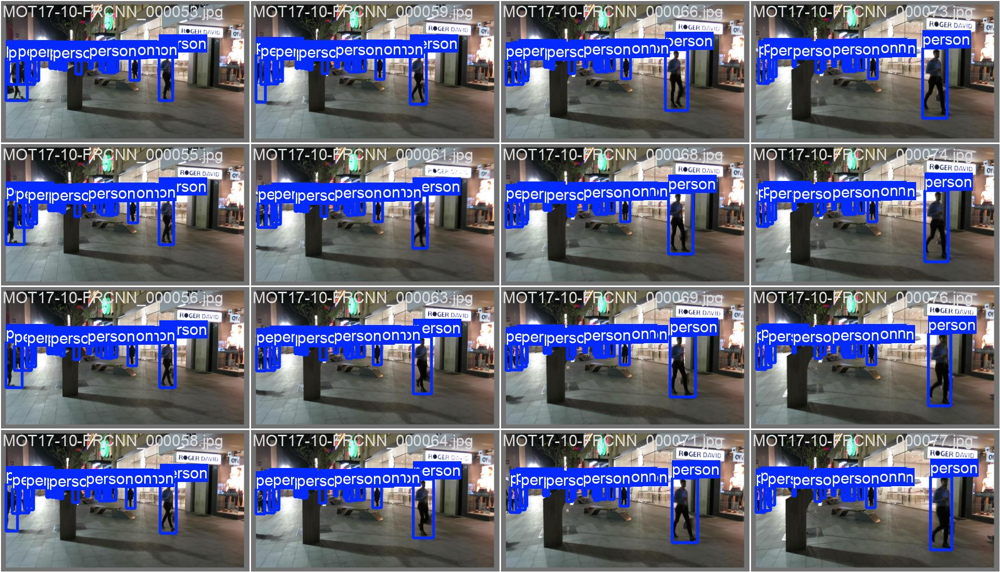

### val_batch2_pred.jpg

`runs/baseline/val_batch2_pred.jpg`

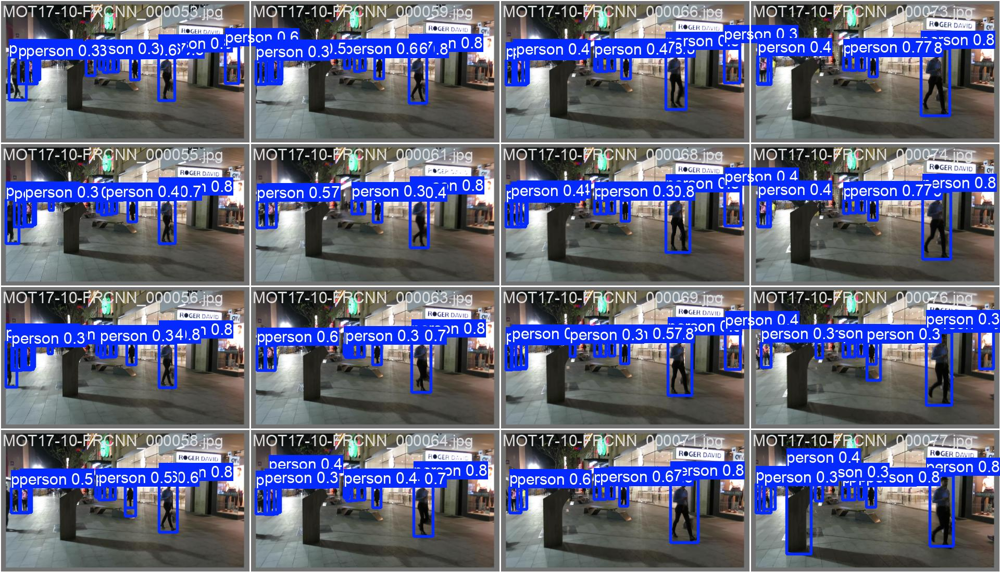

### labels.jpg

`runs/experiment_02/labels.jpg`

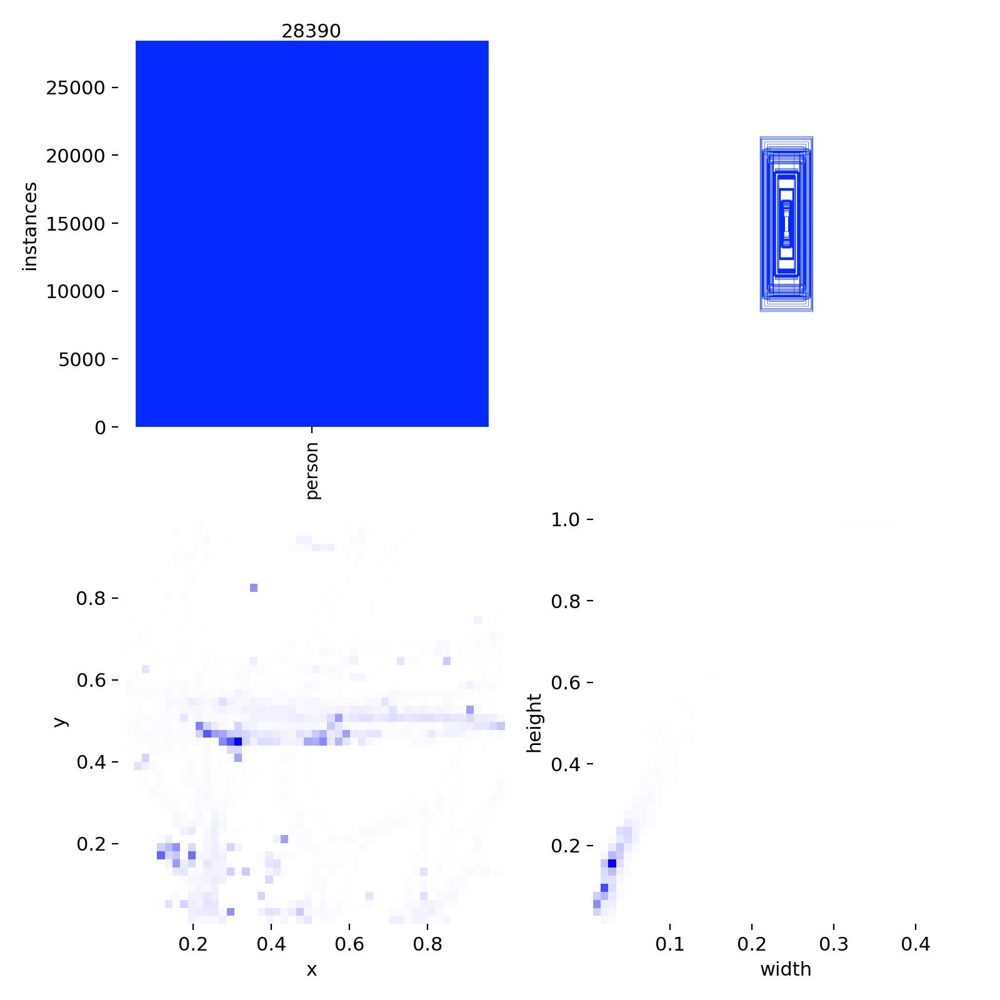

### results.png

`runs/experiment_02/results.png`

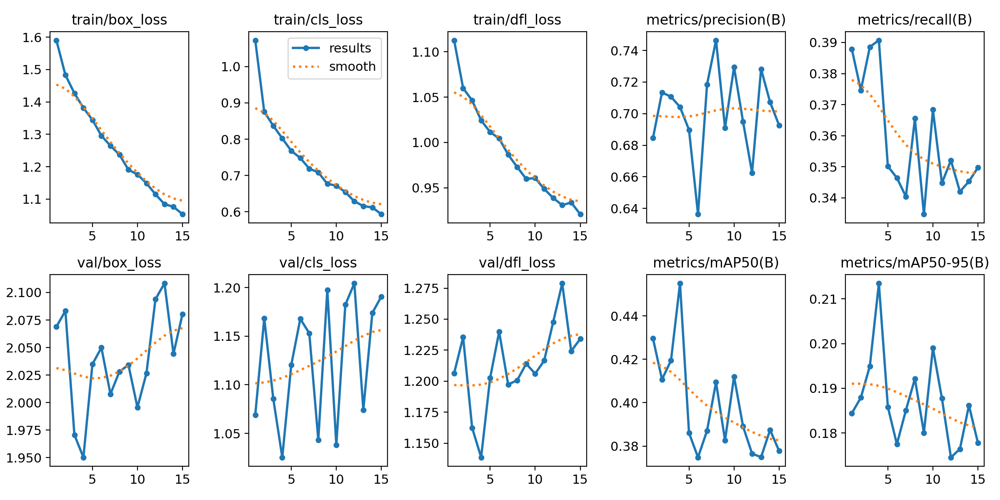

### train_batch0.jpg

`runs/experiment_02/train_batch0.jpg`

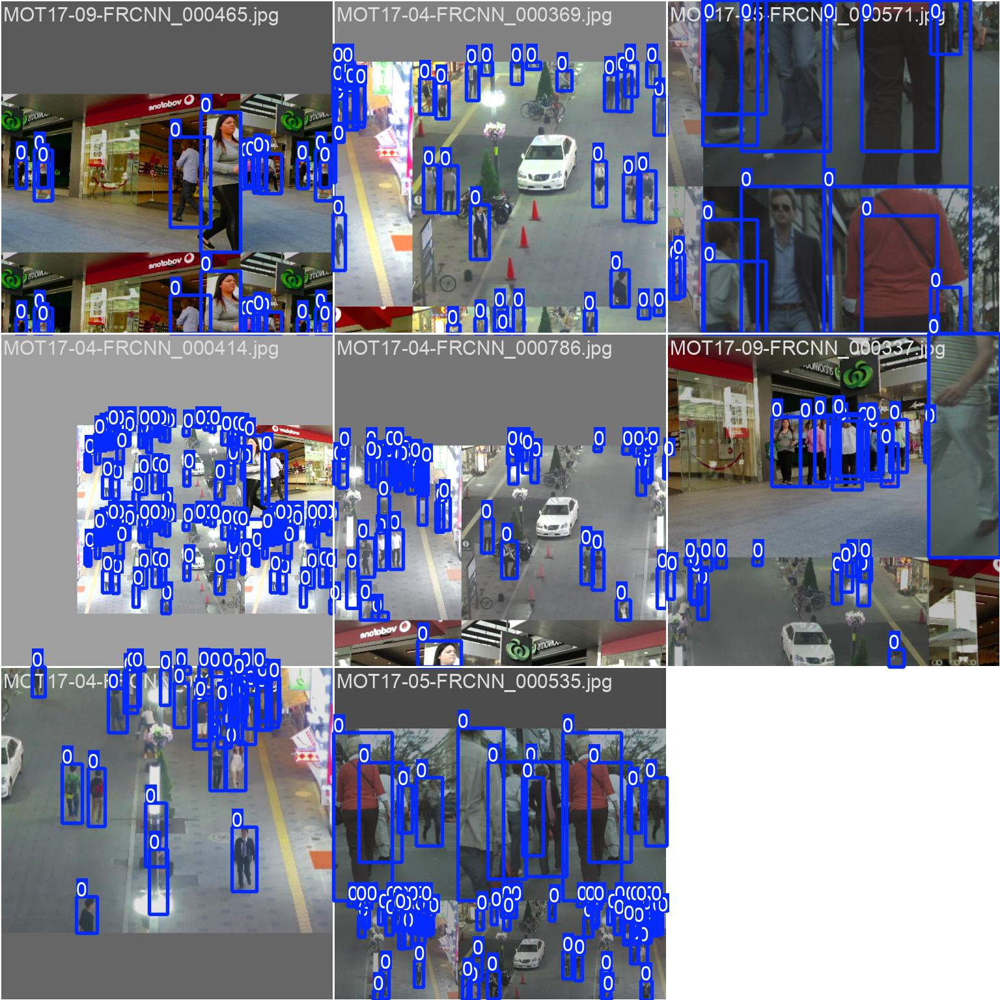

### train_batch1.jpg

`runs/experiment_02/train_batch1.jpg`

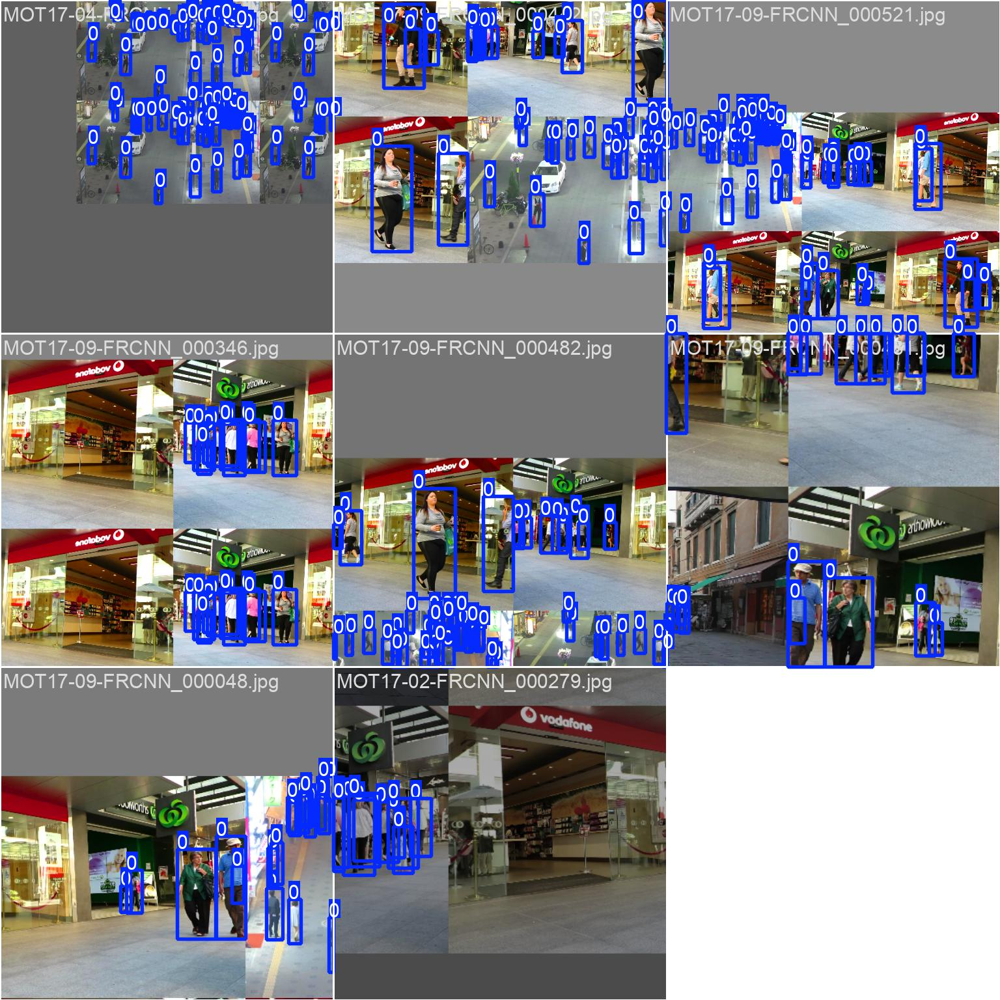

### train_batch2.jpg

`runs/experiment_02/train_batch2.jpg`

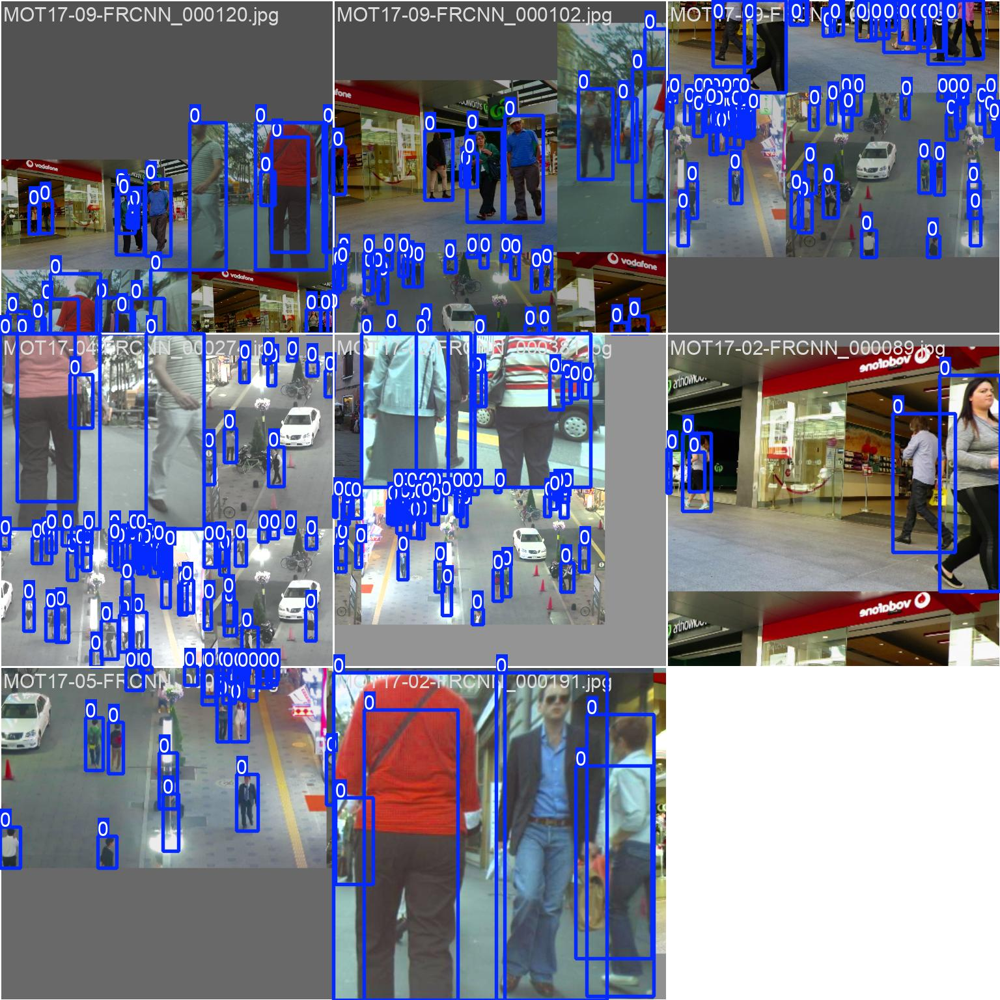

### train_batch750.jpg

`runs/experiment_02/train_batch750.jpg`

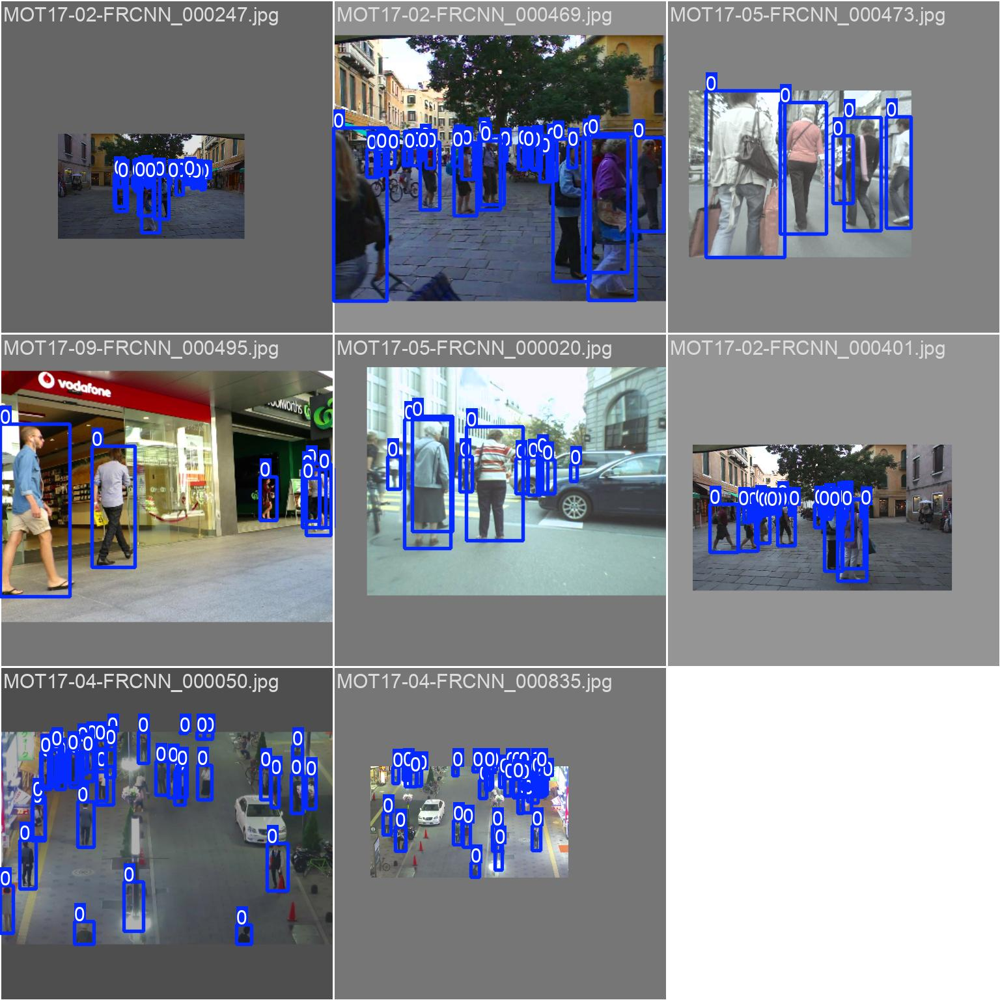

### train_batch751.jpg

`runs/experiment_02/train_batch751.jpg`

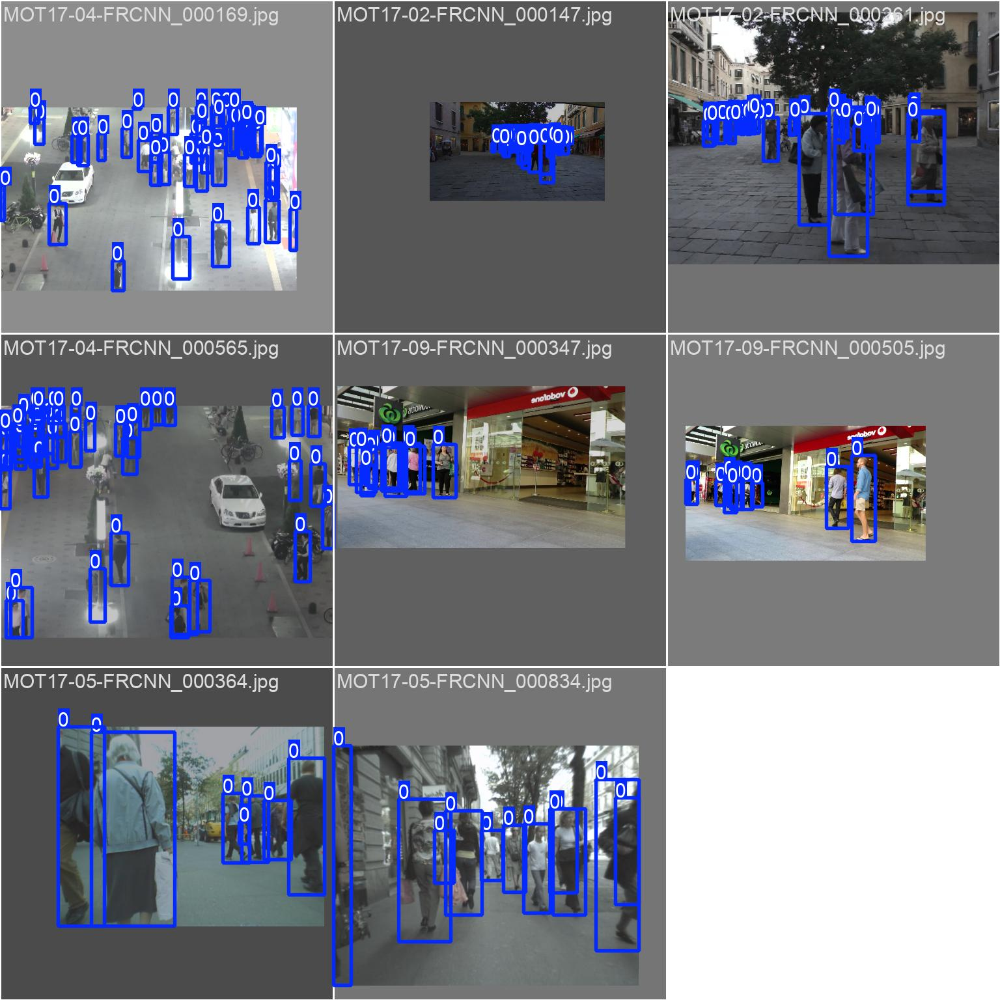

### train_batch752.jpg

`runs/experiment_02/train_batch752.jpg`

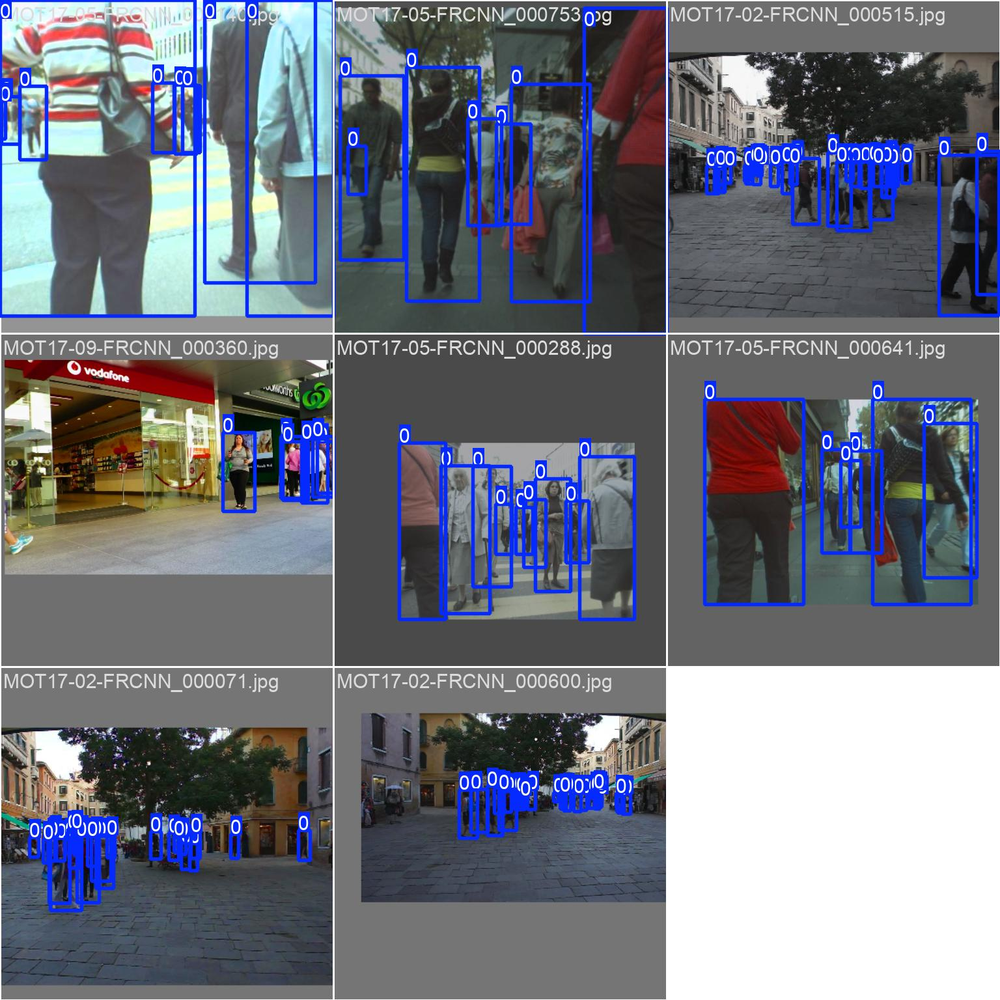

### val_batch0_labels.jpg

`runs/experiment_02/val_batch0_labels.jpg`

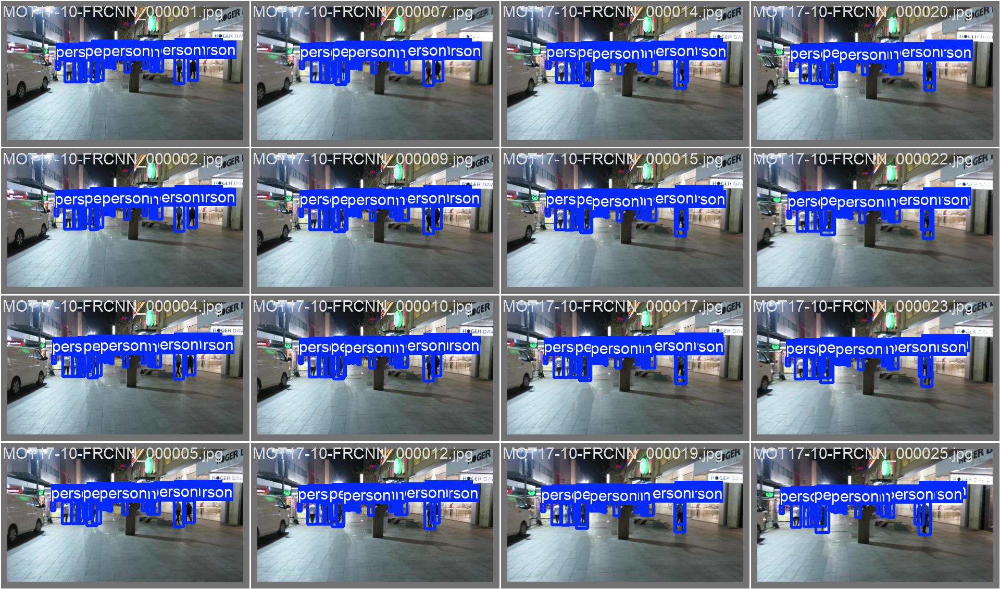

### val_batch0_pred.jpg

`runs/experiment_02/val_batch0_pred.jpg`

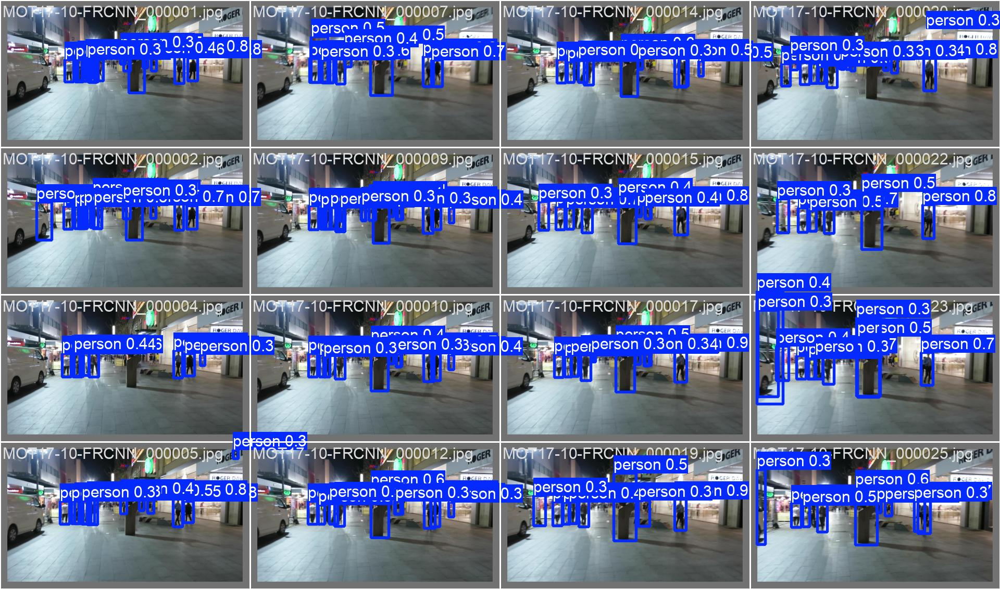

### val_batch1_labels.jpg

`runs/experiment_02/val_batch1_labels.jpg`

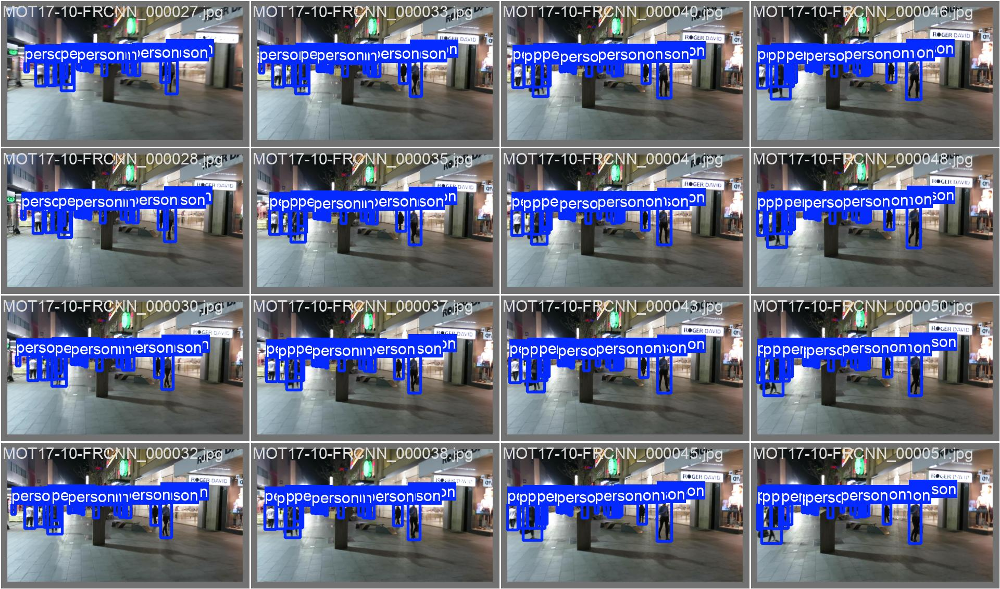

### val_batch1_pred.jpg

`runs/experiment_02/val_batch1_pred.jpg`

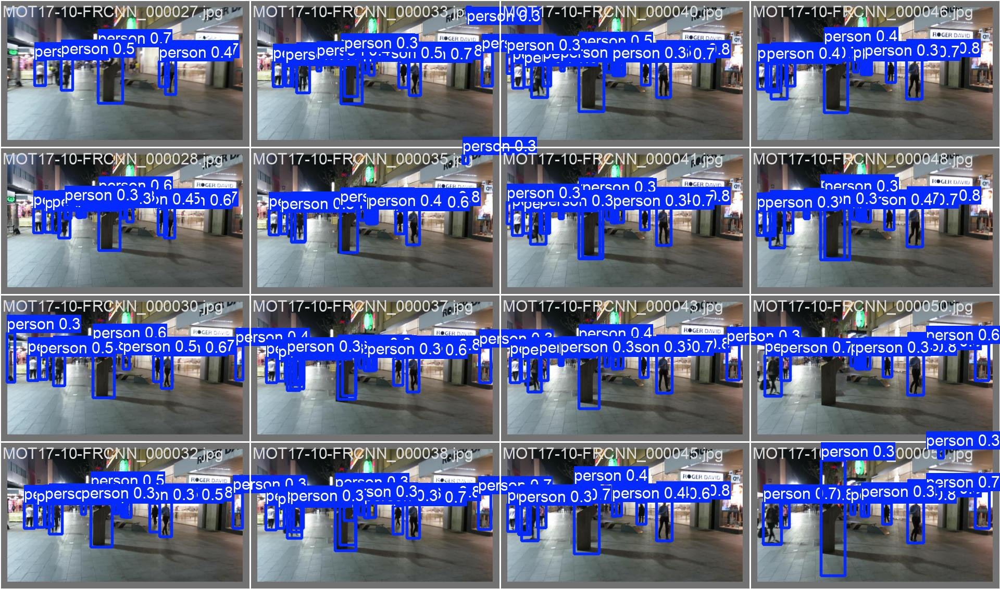

### val_batch2_labels.jpg

`runs/experiment_02/val_batch2_labels.jpg`

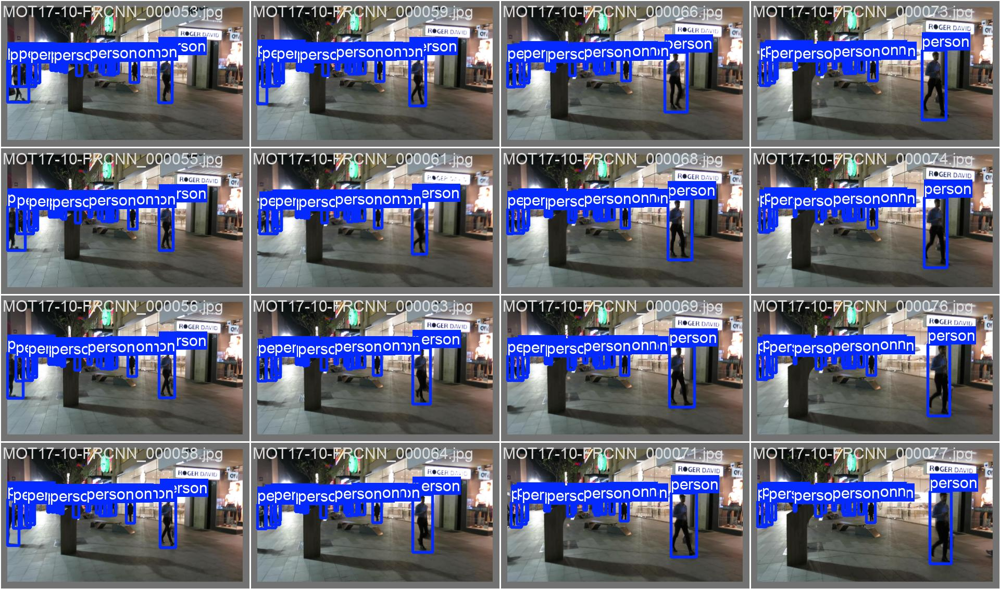

### val_batch2_pred.jpg

`runs/experiment_02/val_batch2_pred.jpg`

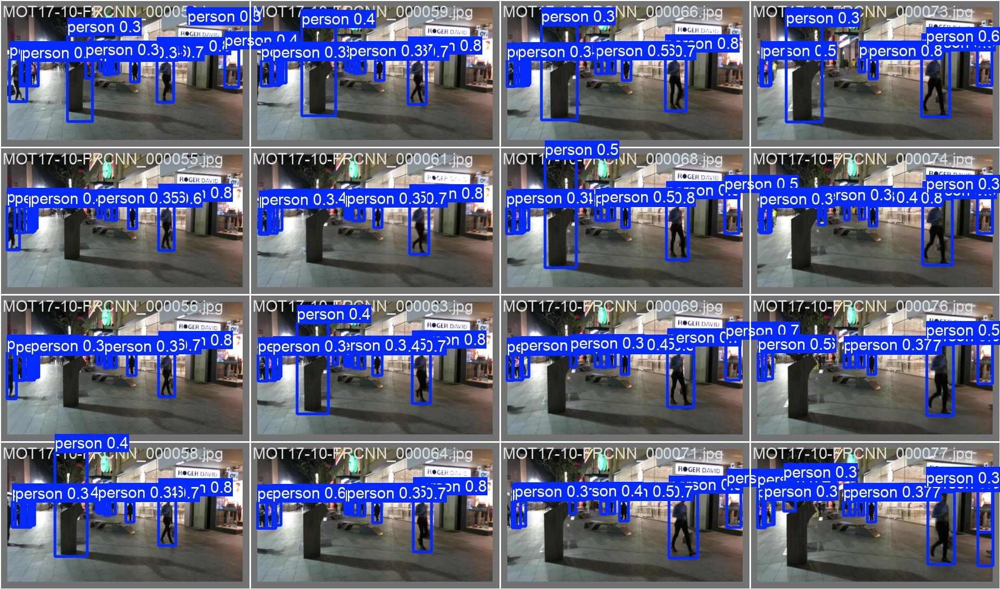

### val_batch0_labels.jpg

`runs/final_test_evaluation/val_batch0_labels.jpg`

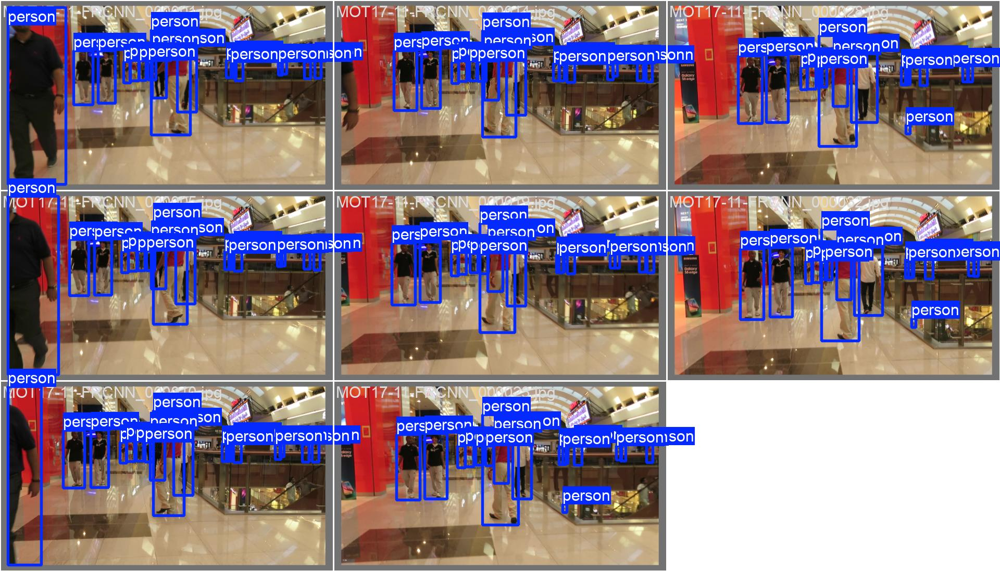

### val_batch0_pred.jpg

`runs/final_test_evaluation/val_batch0_pred.jpg`

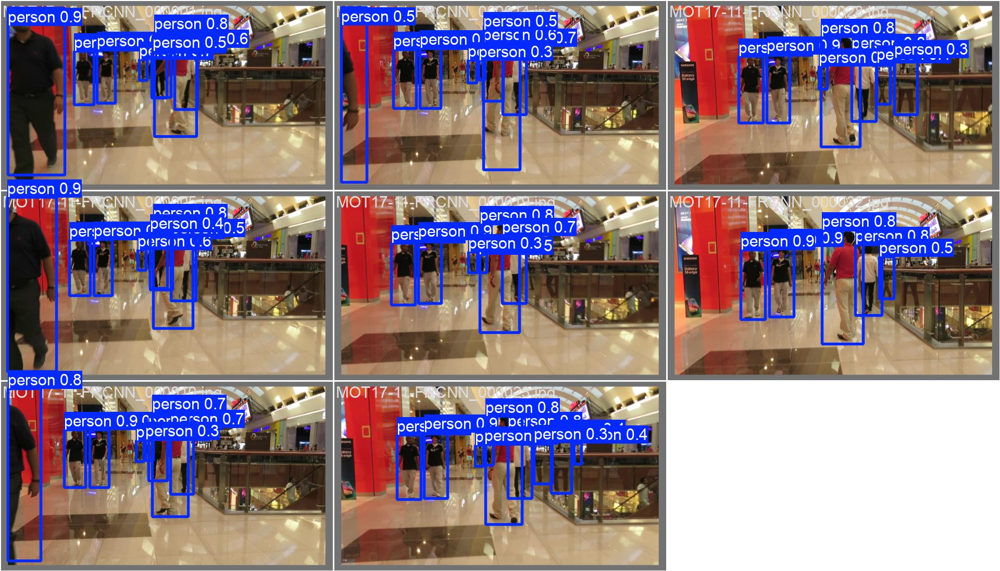

### val_batch1_labels.jpg

`runs/final_test_evaluation/val_batch1_labels.jpg`

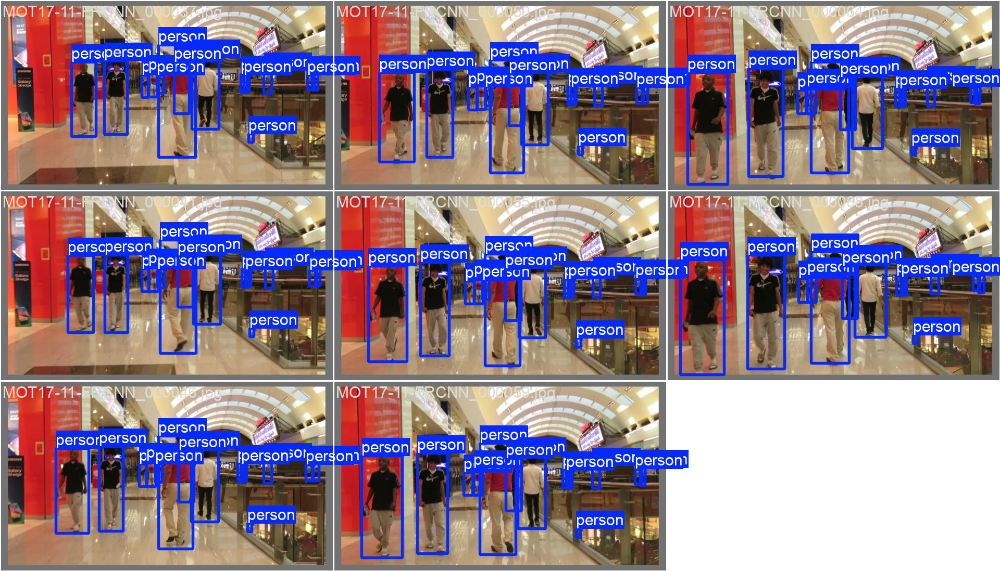

### val_batch1_pred.jpg

`runs/final_test_evaluation/val_batch1_pred.jpg`

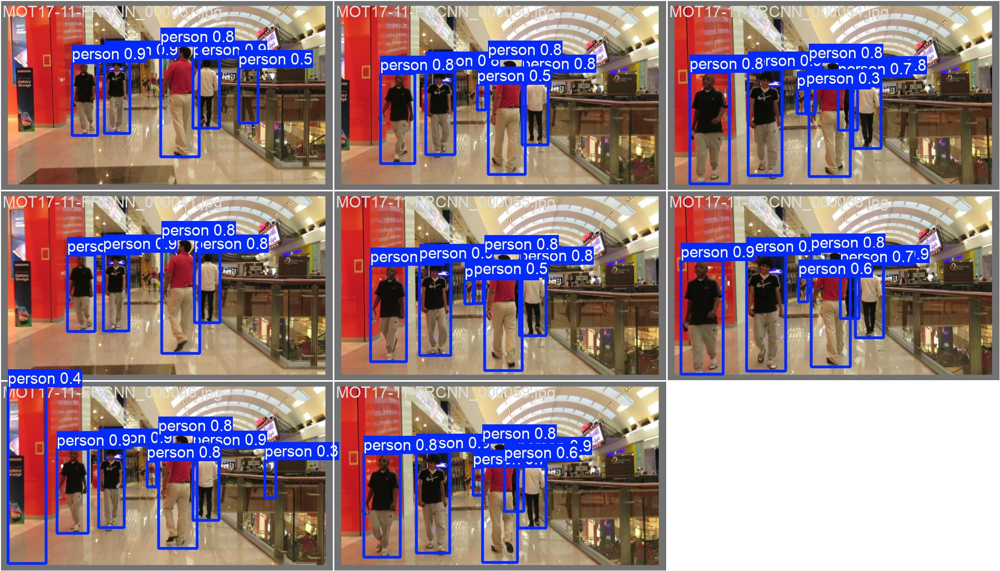

### val_batch2_labels.jpg

`runs/final_test_evaluation/val_batch2_labels.jpg`

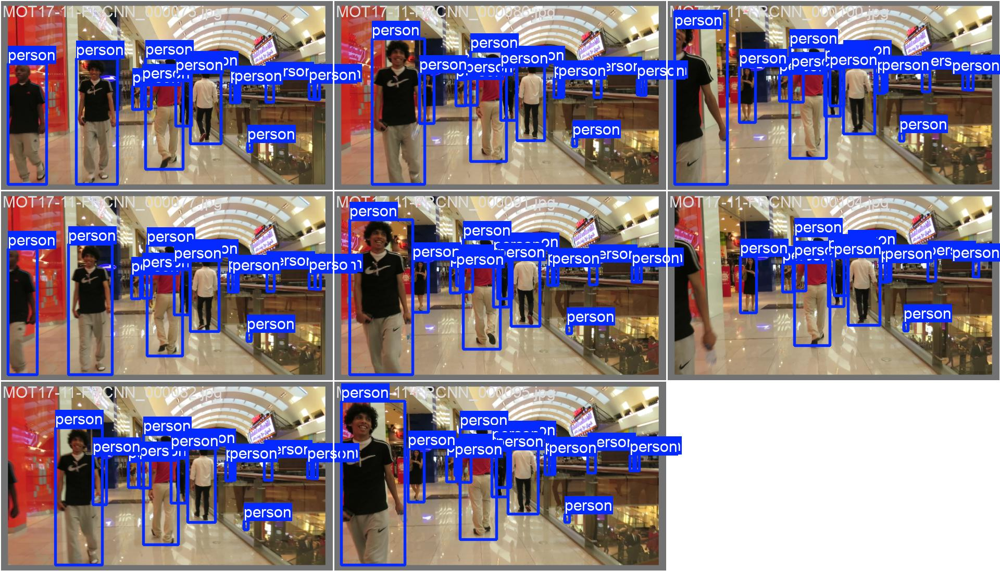

### val_batch2_pred.jpg

`runs/final_test_evaluation/val_batch2_pred.jpg`

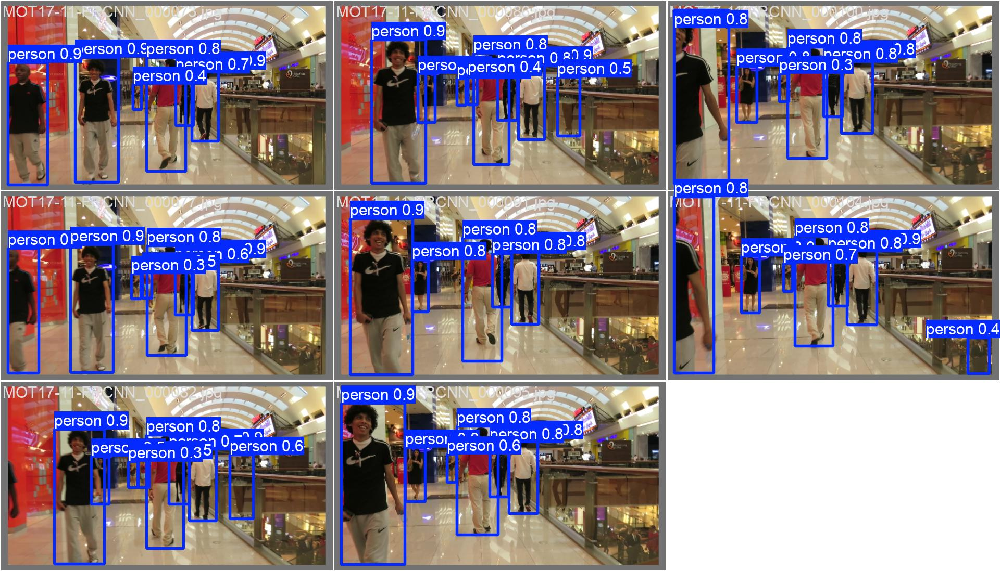

### val_batch0_labels.jpg

`runs/standardized_validation/yolo11n_512_experiment/val_batch0_labels.jpg`

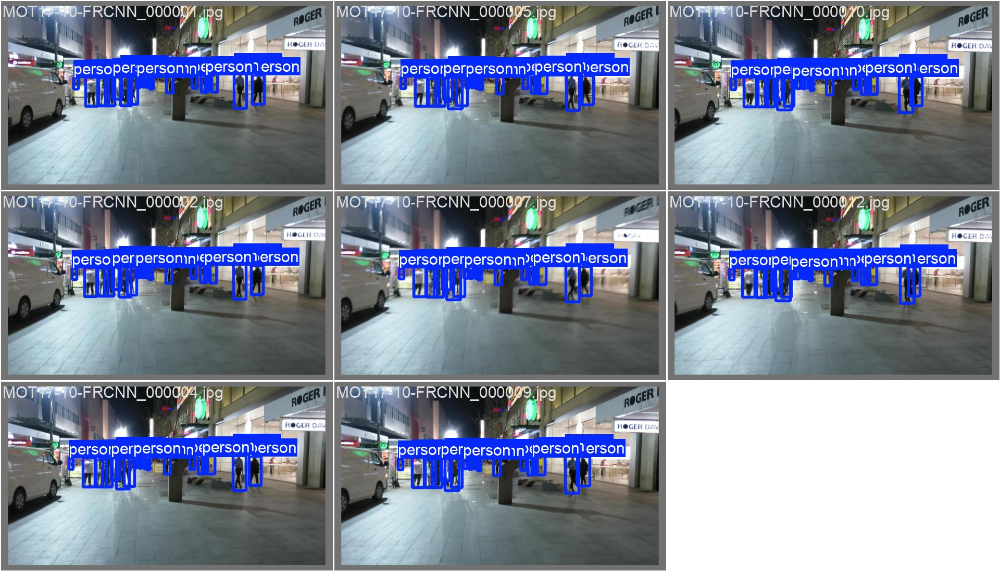

### val_batch0_pred.jpg

`runs/standardized_validation/yolo11n_512_experiment/val_batch0_pred.jpg`

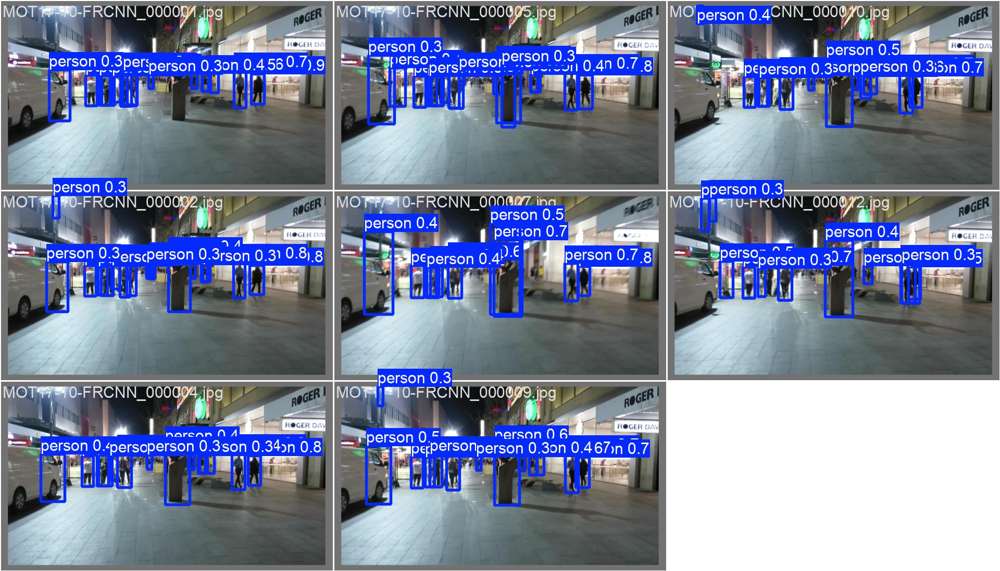

### val_batch1_labels.jpg

`runs/standardized_validation/yolo11n_512_experiment/val_batch1_labels.jpg`

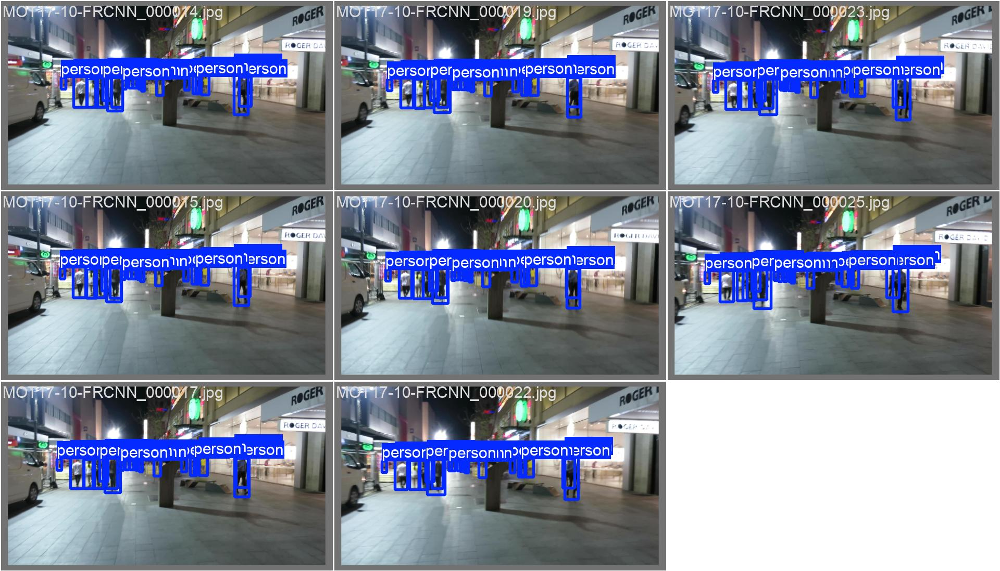

### val_batch1_pred.jpg

`runs/standardized_validation/yolo11n_512_experiment/val_batch1_pred.jpg`

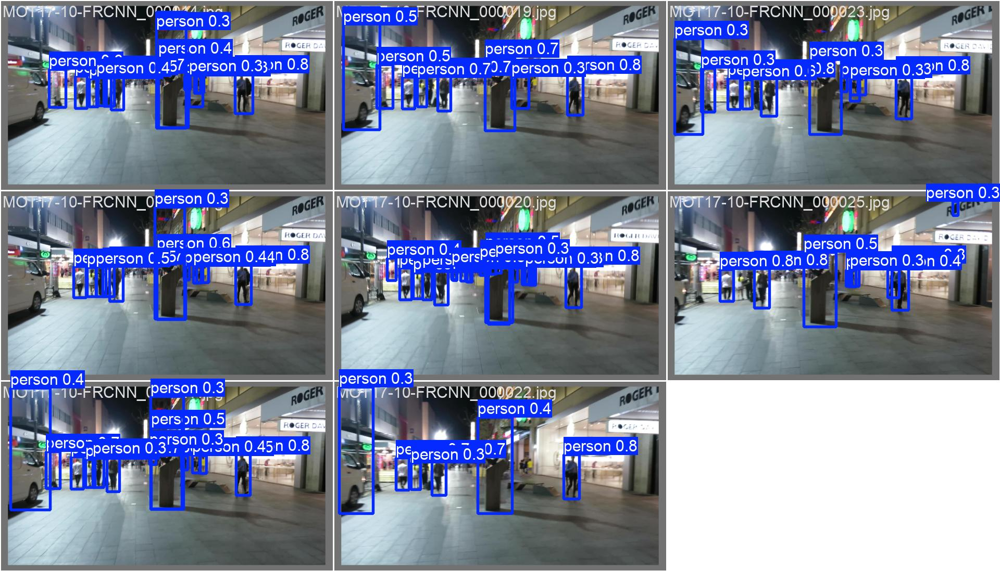

### val_batch2_labels.jpg

`runs/standardized_validation/yolo11n_512_experiment/val_batch2_labels.jpg`

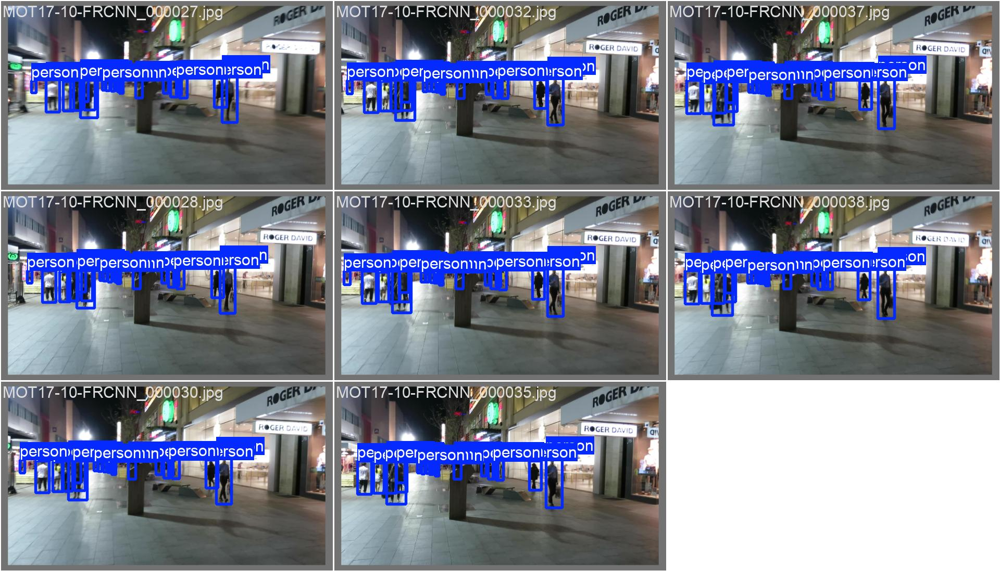

### val_batch2_pred.jpg

`runs/standardized_validation/yolo11n_512_experiment/val_batch2_pred.jpg`

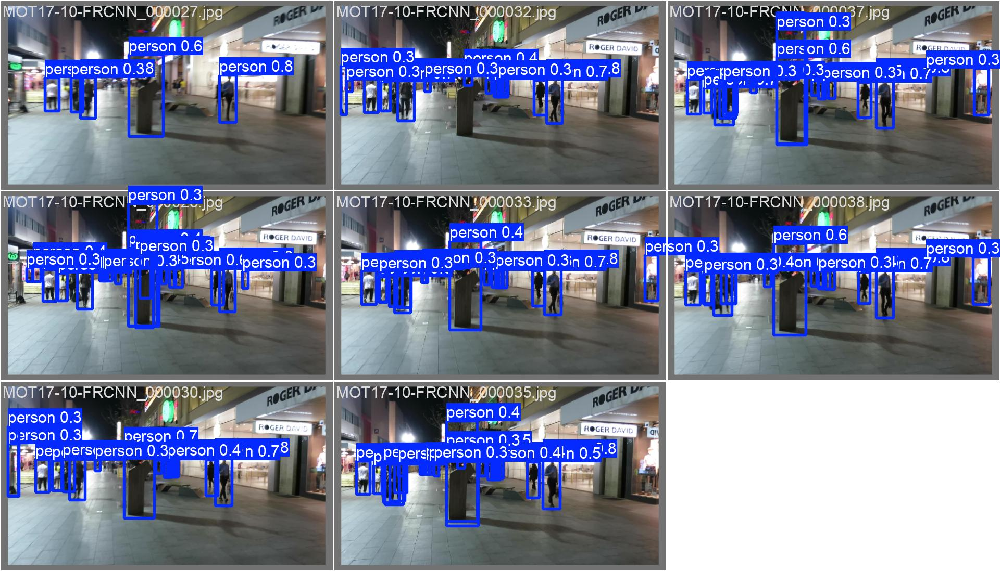

### val_batch0_labels.jpg

`runs/standardized_validation/yolo11n_baseline/val_batch0_labels.jpg`

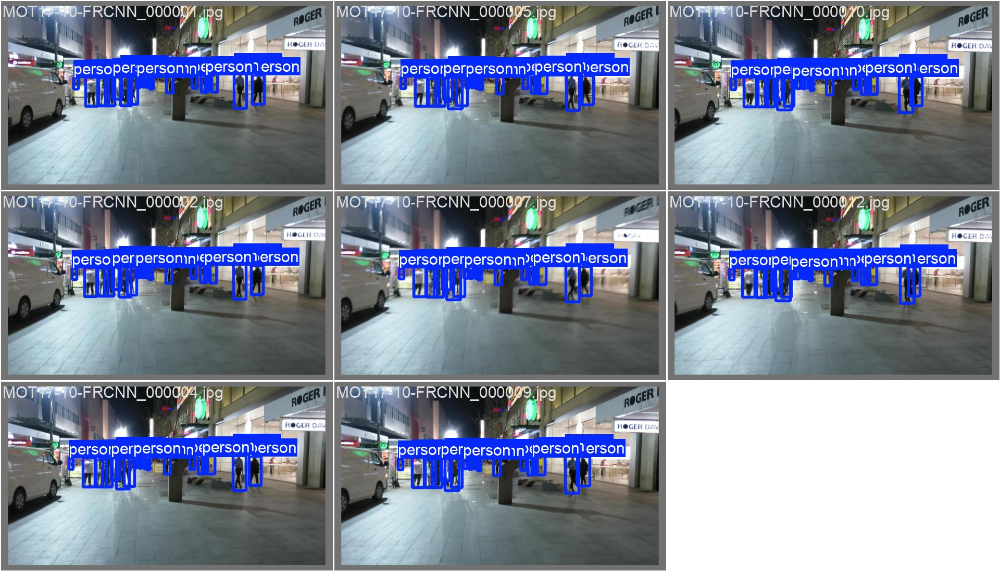

### val_batch0_pred.jpg

`runs/standardized_validation/yolo11n_baseline/val_batch0_pred.jpg`

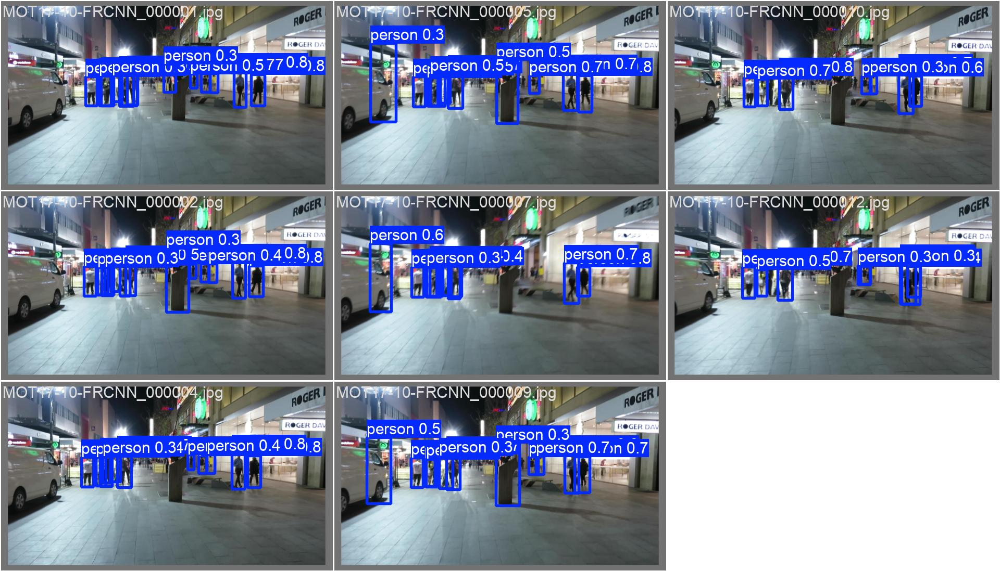

### val_batch1_labels.jpg

`runs/standardized_validation/yolo11n_baseline/val_batch1_labels.jpg`

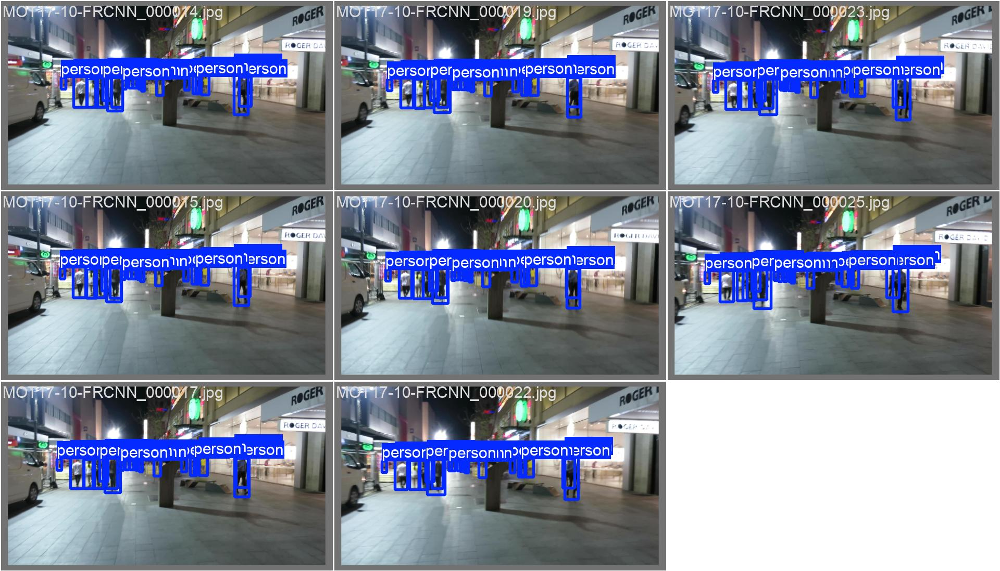

### val_batch1_pred.jpg

`runs/standardized_validation/yolo11n_baseline/val_batch1_pred.jpg`

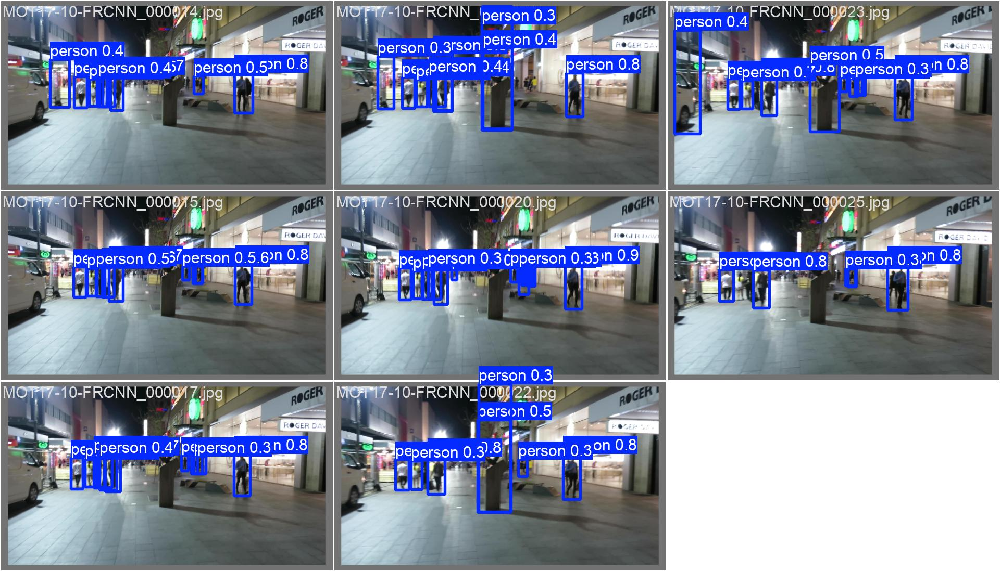

### val_batch2_labels.jpg

`runs/standardized_validation/yolo11n_baseline/val_batch2_labels.jpg`

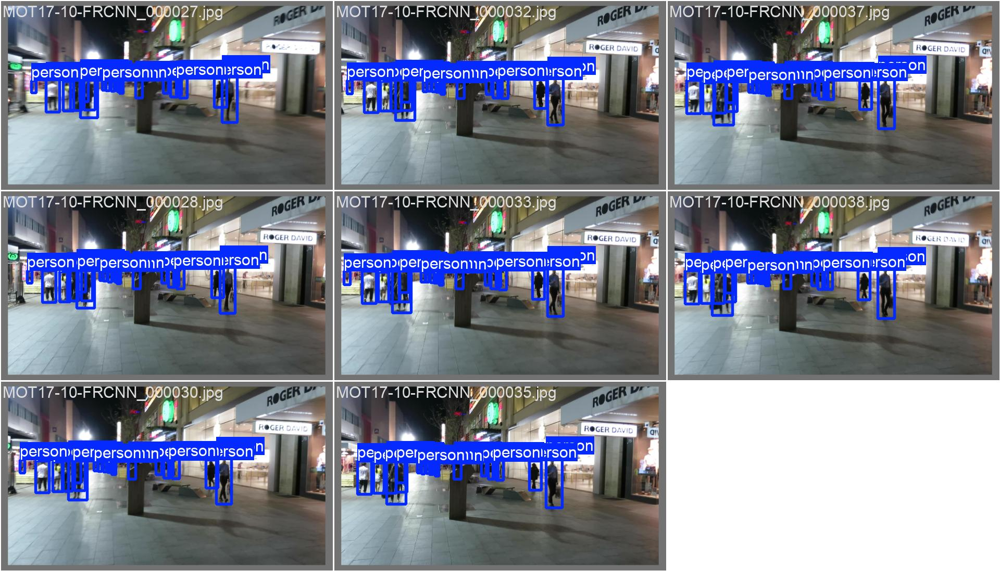

### val_batch2_pred.jpg

`runs/standardized_validation/yolo11n_baseline/val_batch2_pred.jpg`

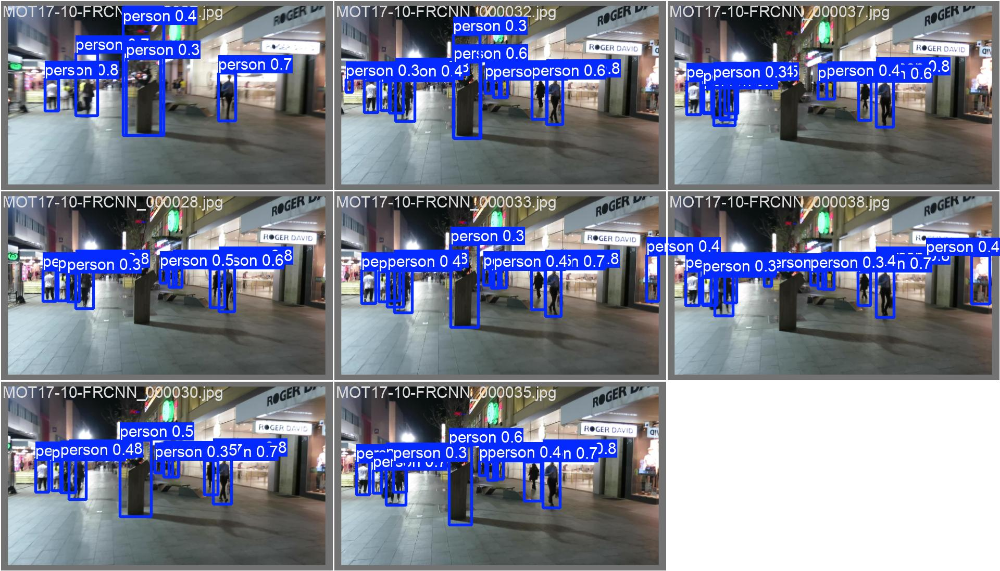

### val_batch0_labels.jpg

`runs/standardized_validation/yolo11n_refined/val_batch0_labels.jpg`

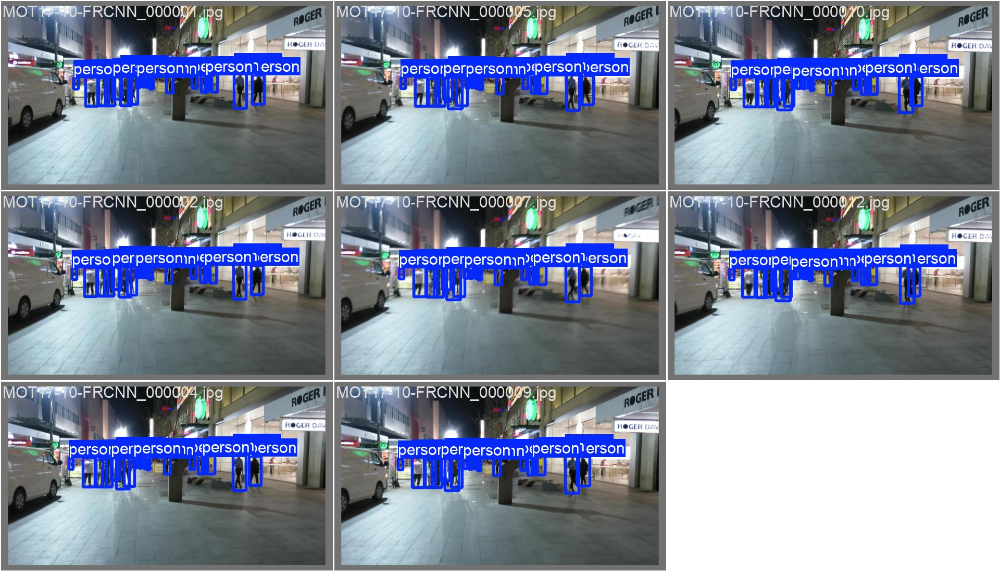

### val_batch0_pred.jpg

`runs/standardized_validation/yolo11n_refined/val_batch0_pred.jpg`

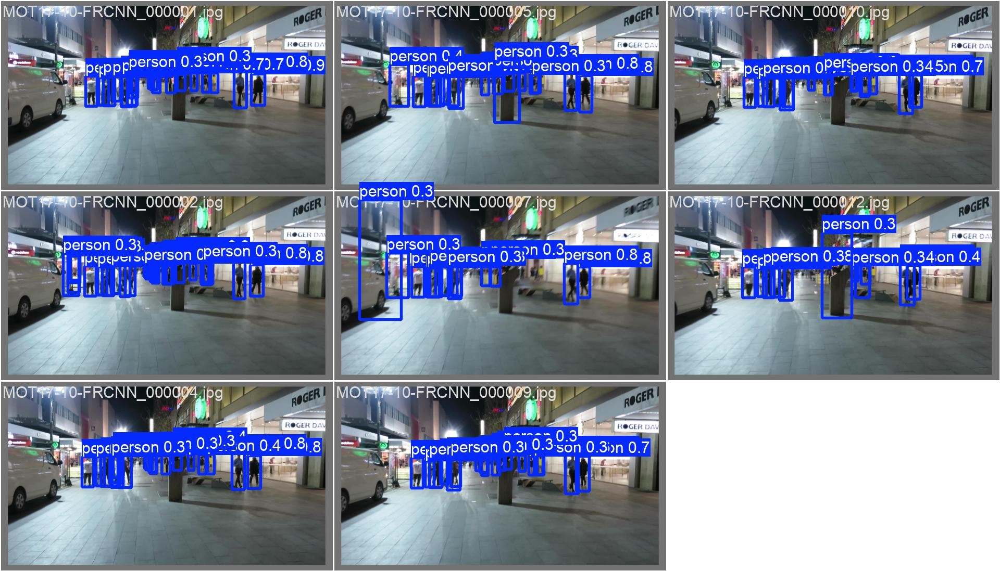

### val_batch1_labels.jpg

`runs/standardized_validation/yolo11n_refined/val_batch1_labels.jpg`

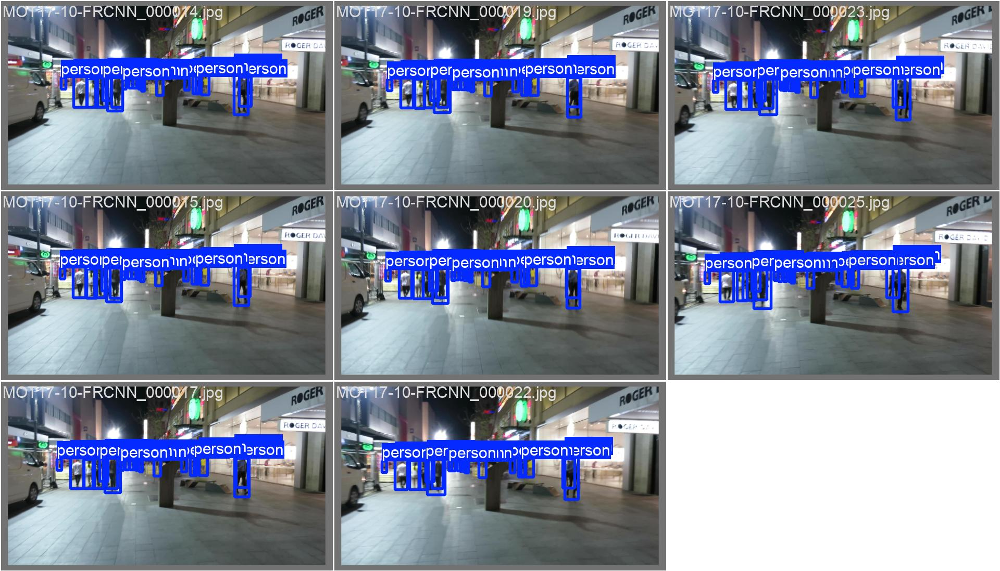

### val_batch1_pred.jpg

`runs/standardized_validation/yolo11n_refined/val_batch1_pred.jpg`

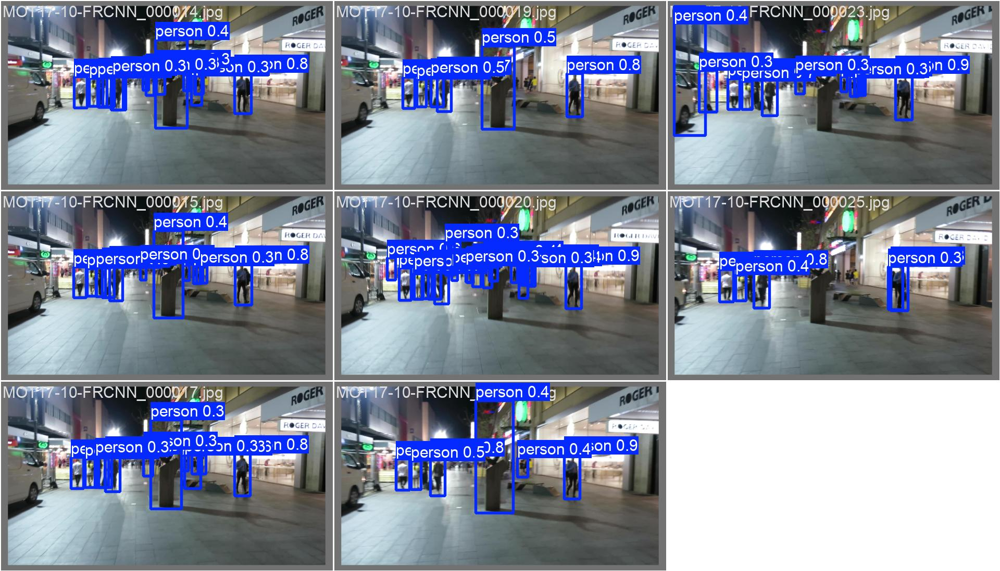

### val_batch2_labels.jpg

`runs/standardized_validation/yolo11n_refined/val_batch2_labels.jpg`

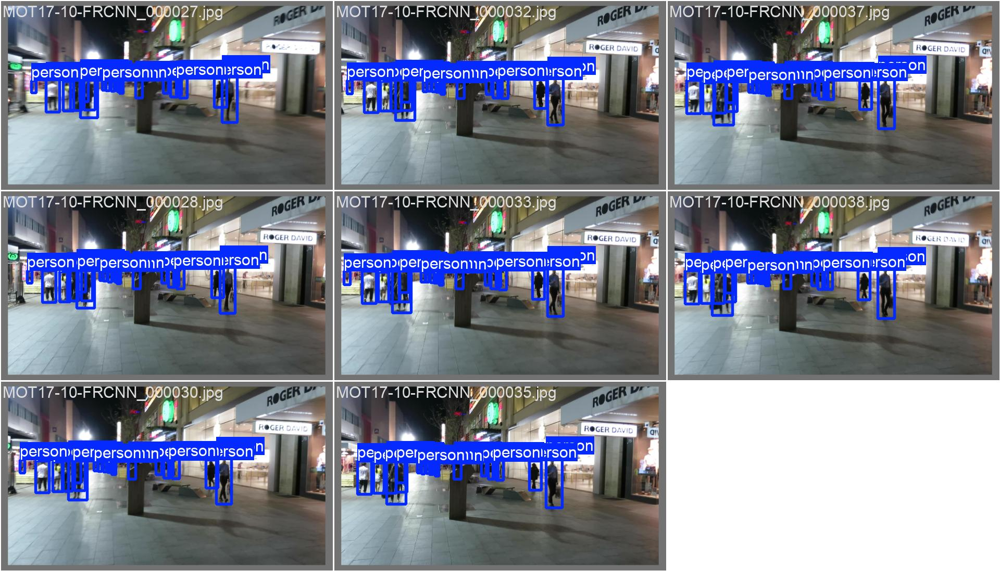

### val_batch2_pred.jpg

`runs/standardized_validation/yolo11n_refined/val_batch2_pred.jpg`

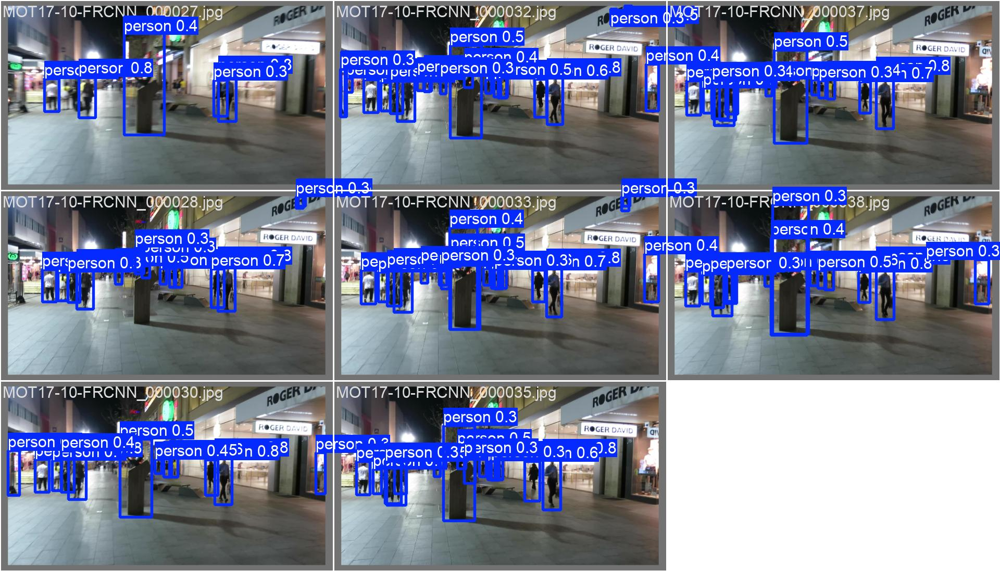

### val_batch0_labels.jpg

`runs/standardized_validation/yolo11s/val_batch0_labels.jpg`

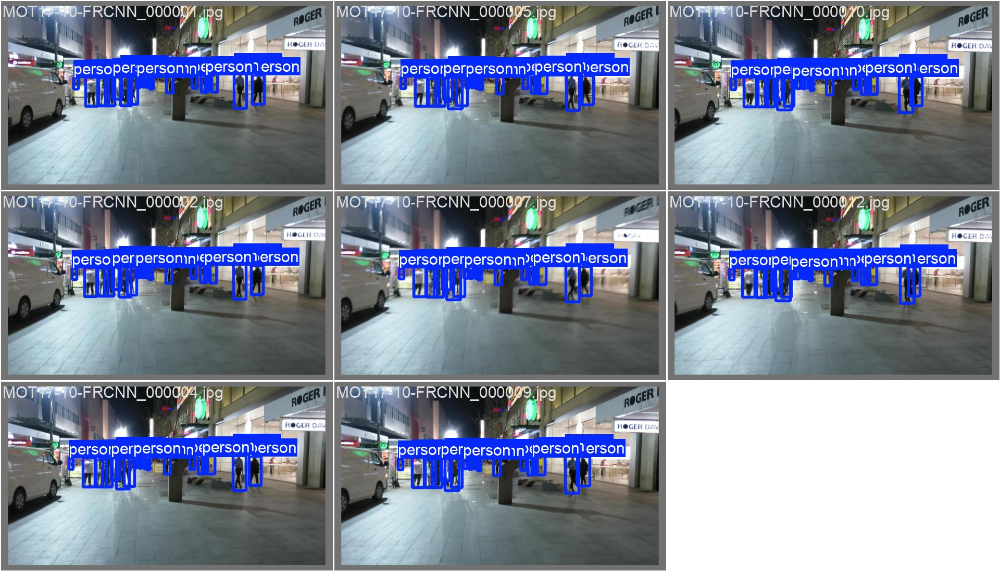

### val_batch0_pred.jpg

`runs/standardized_validation/yolo11s/val_batch0_pred.jpg`

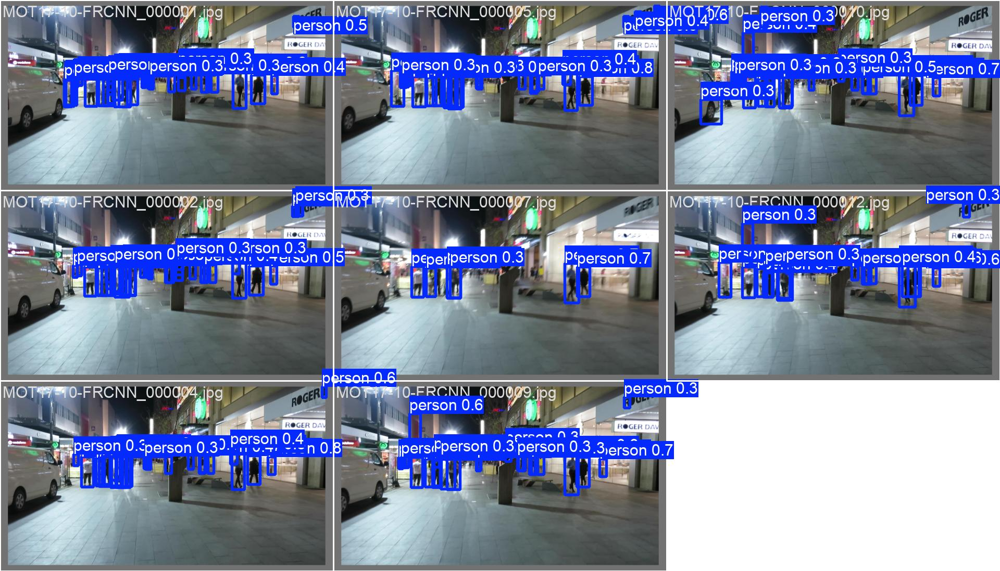

### val_batch1_labels.jpg

`runs/standardized_validation/yolo11s/val_batch1_labels.jpg`

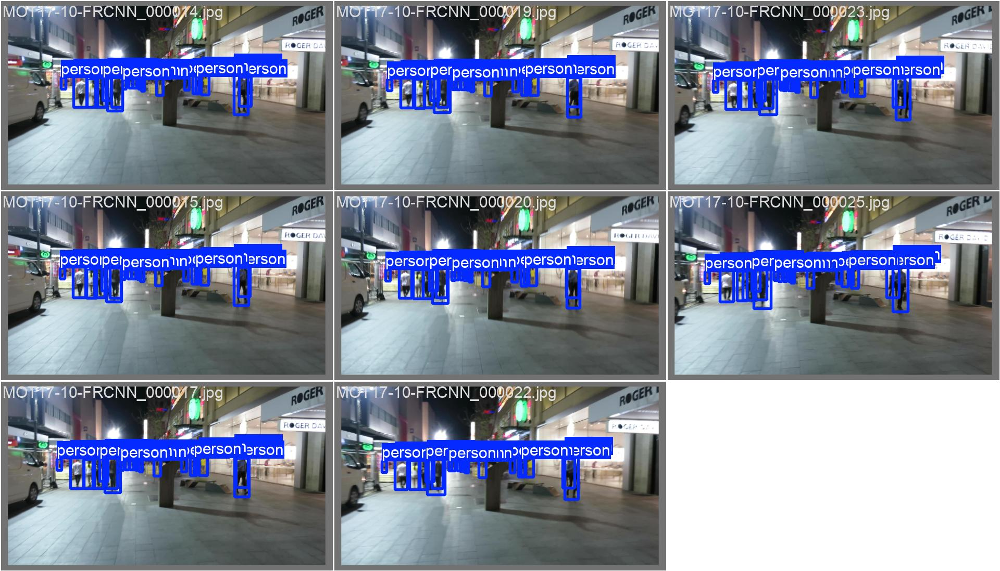

### val_batch1_pred.jpg

`runs/standardized_validation/yolo11s/val_batch1_pred.jpg`

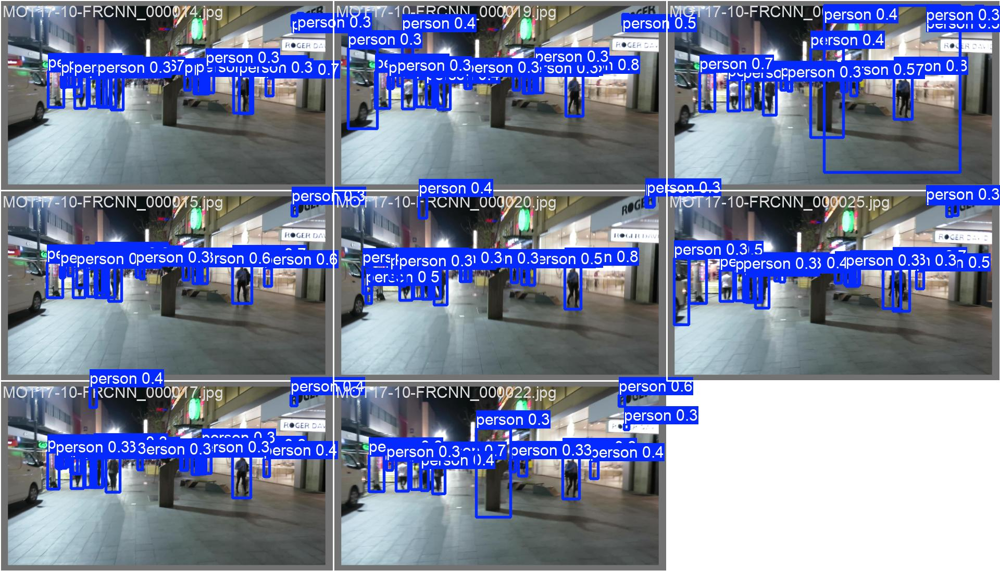

### val_batch2_labels.jpg

`runs/standardized_validation/yolo11s/val_batch2_labels.jpg`

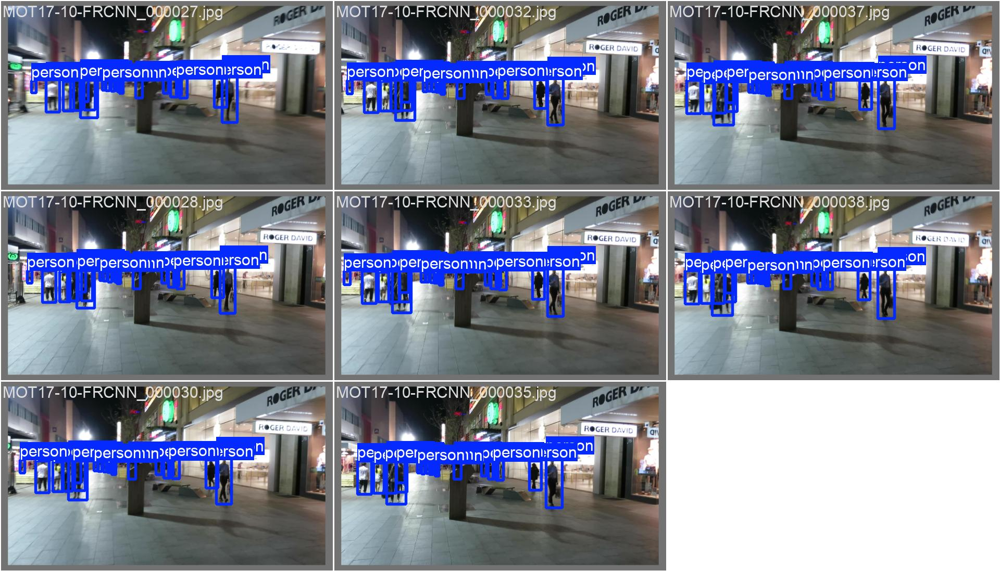

### val_batch2_pred.jpg

`runs/standardized_validation/yolo11s/val_batch2_pred.jpg`

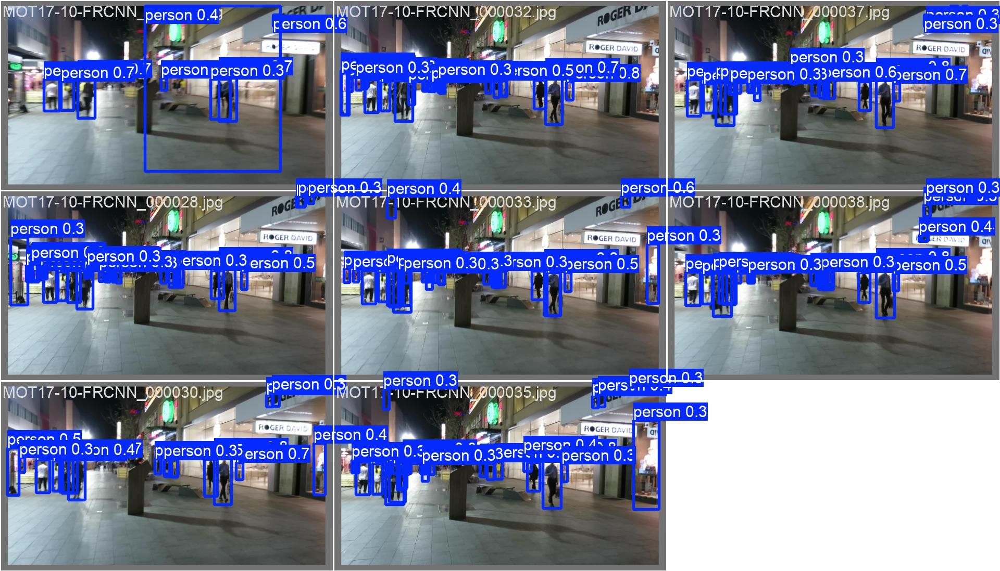

### val_batch0_labels.jpg

`runs/standardized_validation/yolo11s_lr_tuned/val_batch0_labels.jpg`

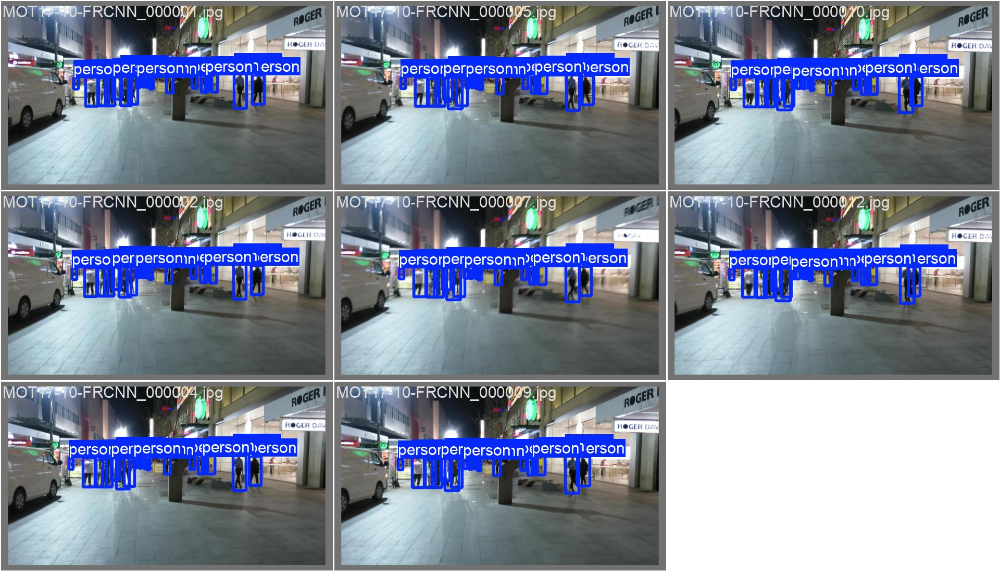

### val_batch0_pred.jpg

`runs/standardized_validation/yolo11s_lr_tuned/val_batch0_pred.jpg`

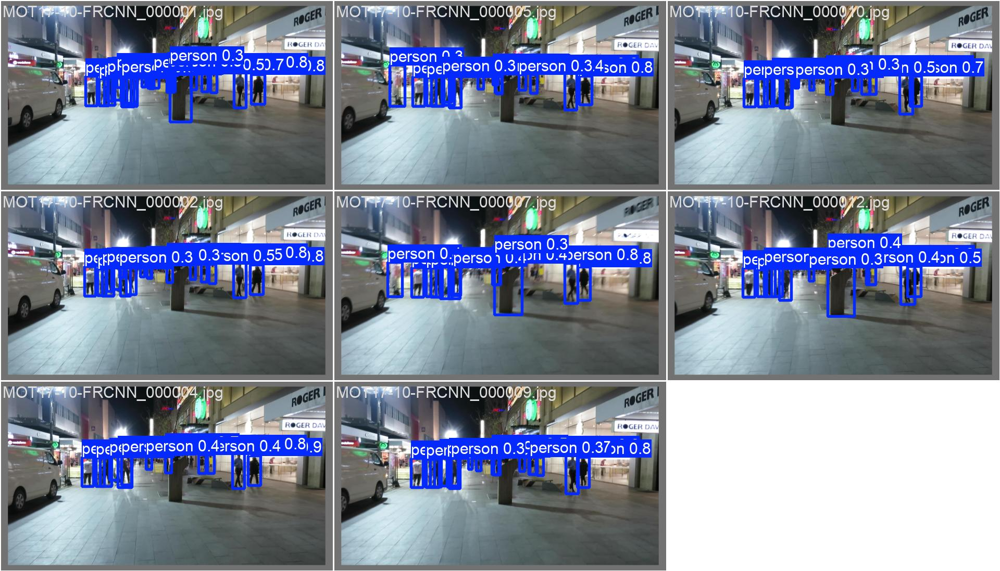

### val_batch1_labels.jpg

`runs/standardized_validation/yolo11s_lr_tuned/val_batch1_labels.jpg`

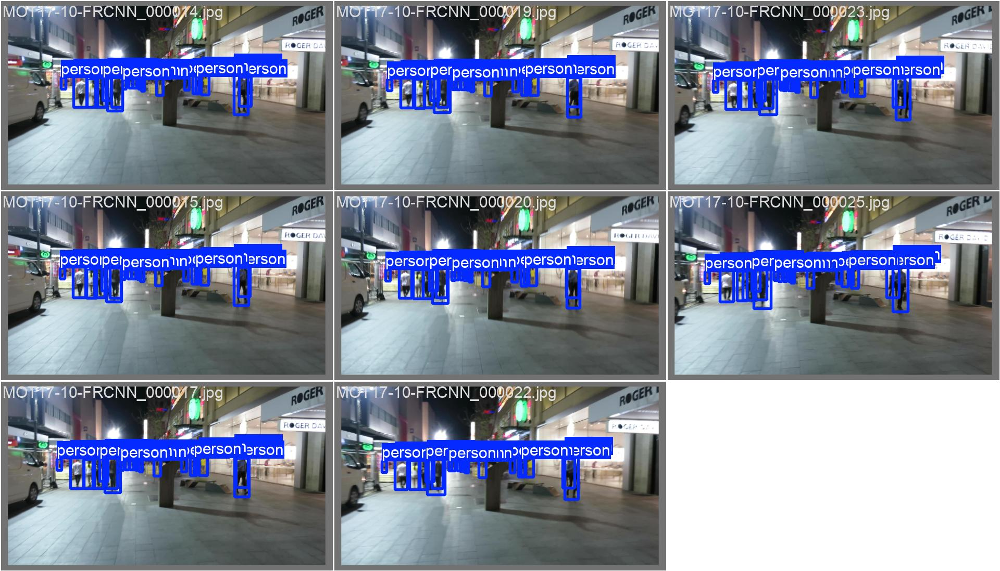

### val_batch1_pred.jpg

`runs/standardized_validation/yolo11s_lr_tuned/val_batch1_pred.jpg`

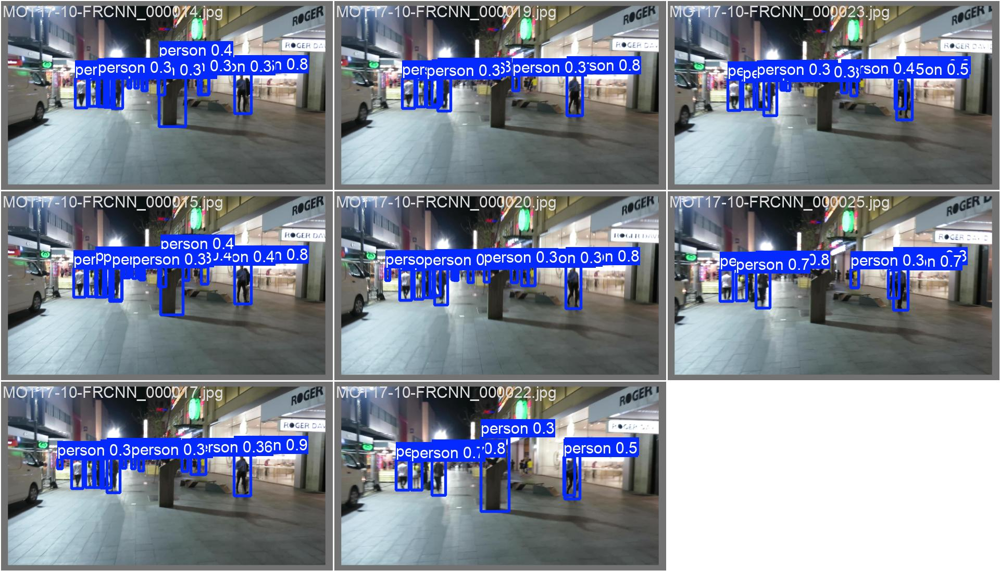

### val_batch2_labels.jpg

`runs/standardized_validation/yolo11s_lr_tuned/val_batch2_labels.jpg`

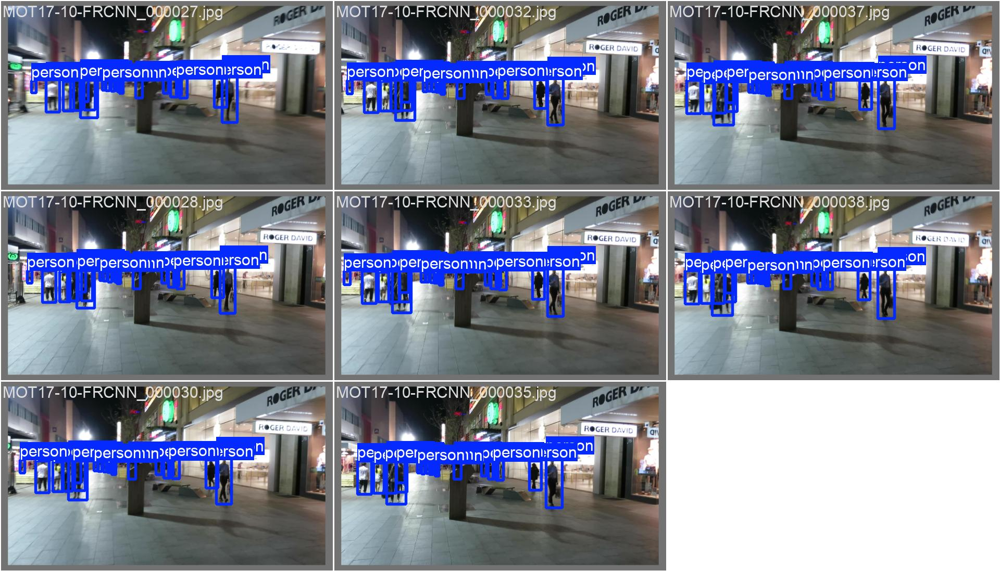

### val_batch2_pred.jpg

`runs/standardized_validation/yolo11s_lr_tuned/val_batch2_pred.jpg`

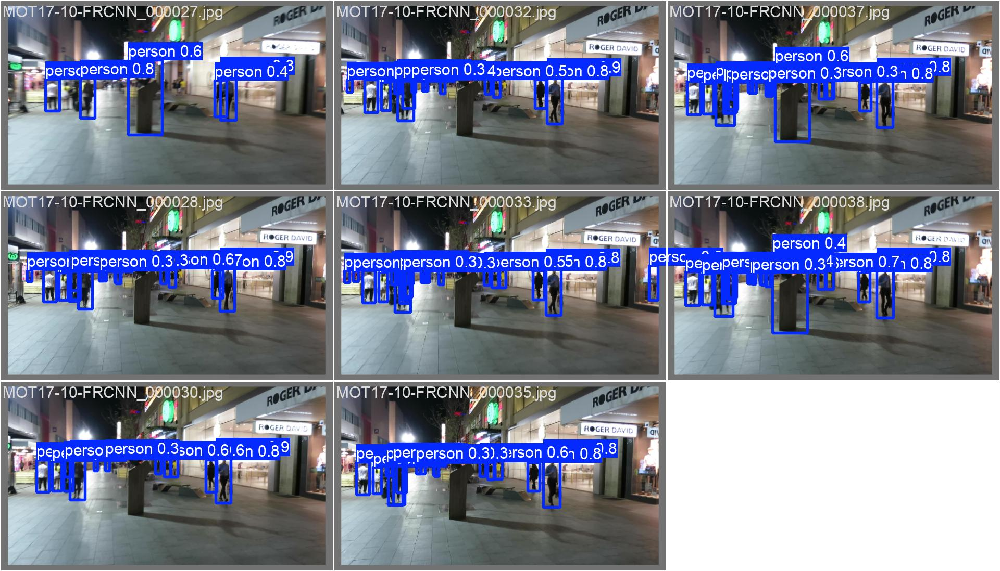

### labels.jpg

`runs/yolo11n_refined/labels.jpg`

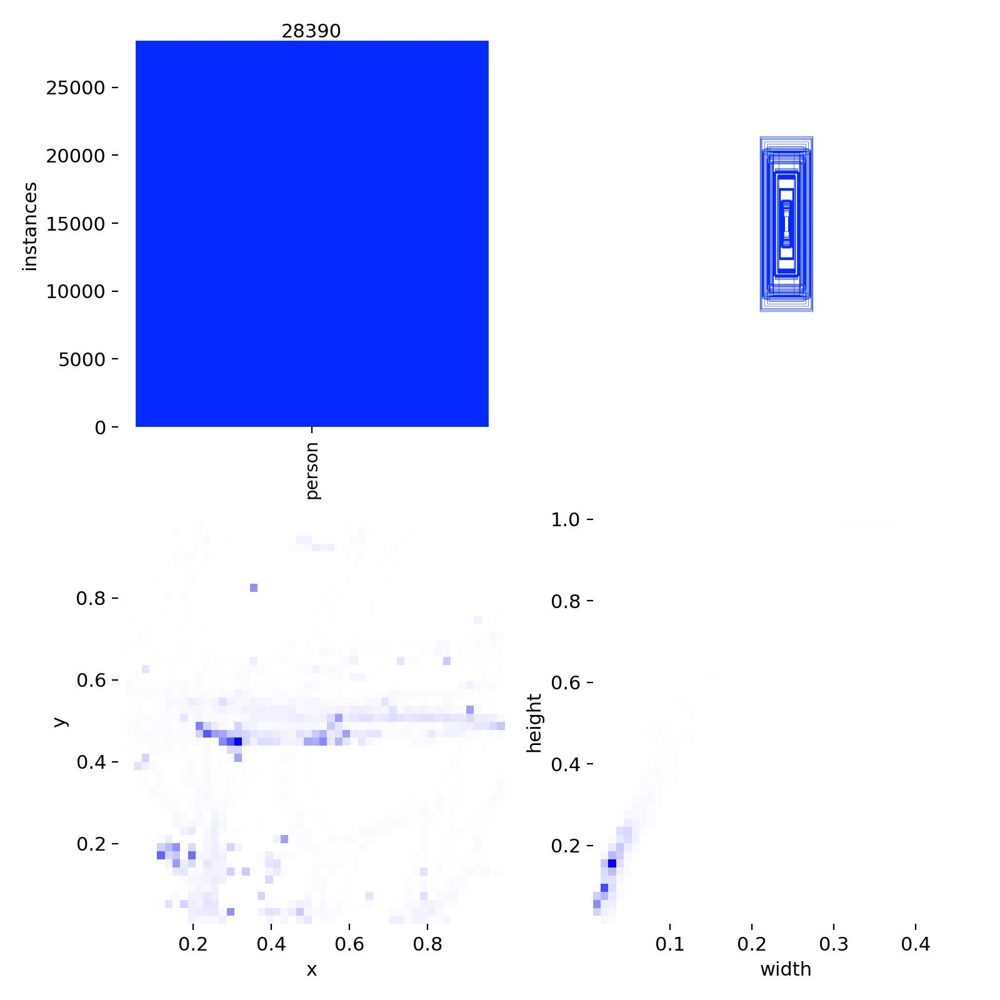

### results.png

`runs/yolo11n_refined/results.png`

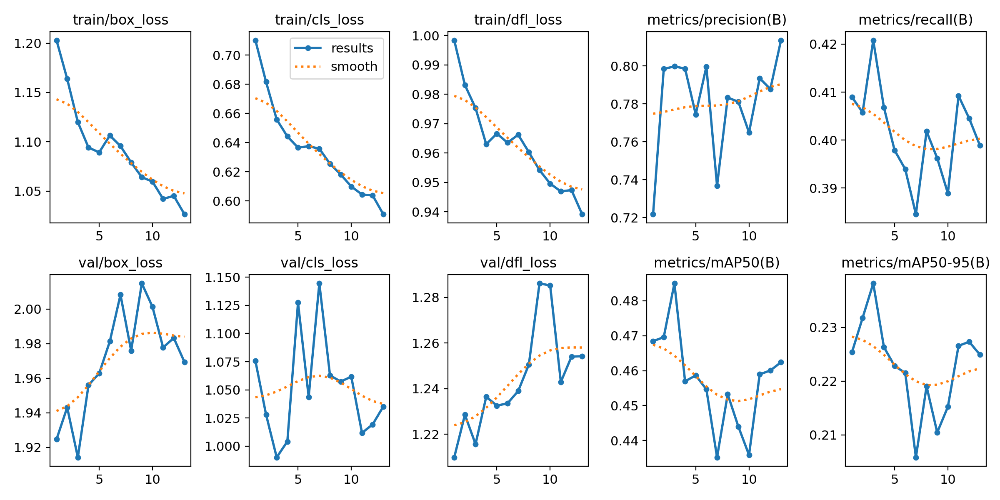

### train_batch0.jpg

`runs/yolo11n_refined/train_batch0.jpg`

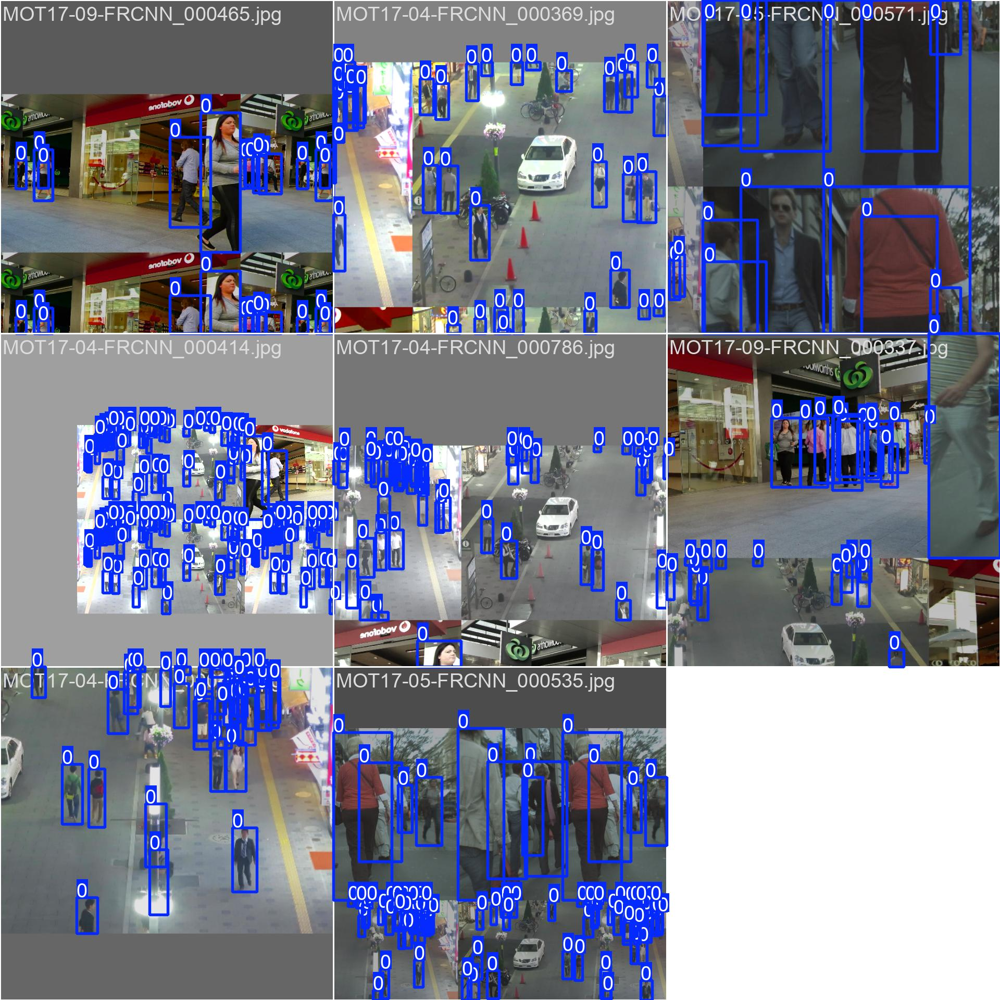

### train_batch1.jpg

`runs/yolo11n_refined/train_batch1.jpg`

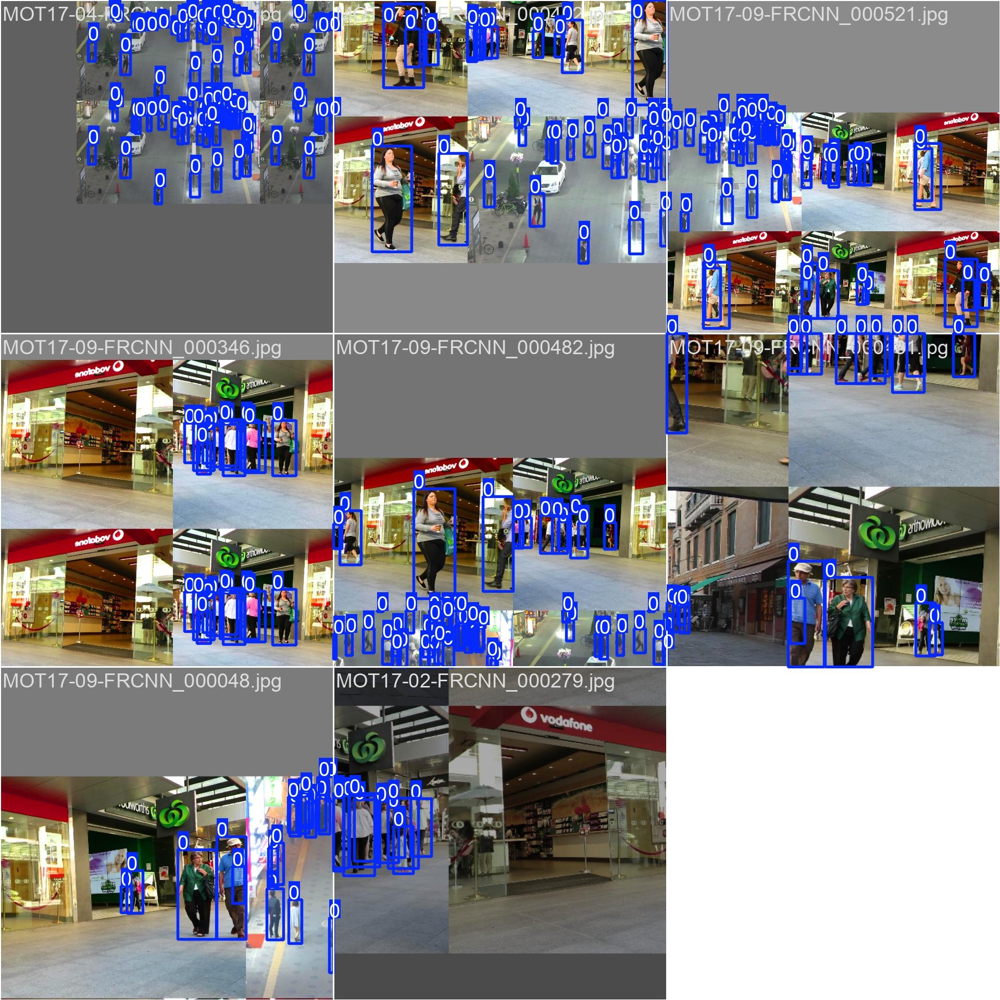

### train_batch2.jpg

`runs/yolo11n_refined/train_batch2.jpg`

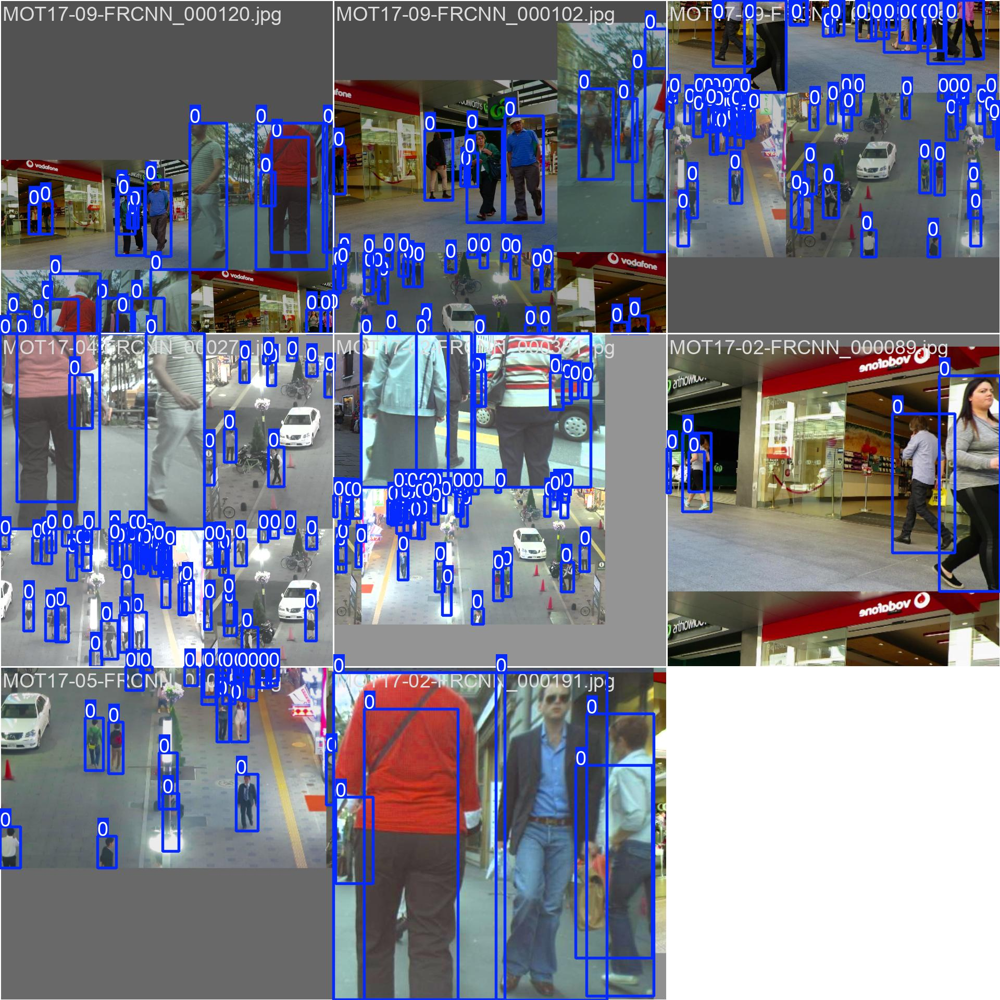

### val_batch0_labels.jpg

`runs/yolo11n_refined/val_batch0_labels.jpg`

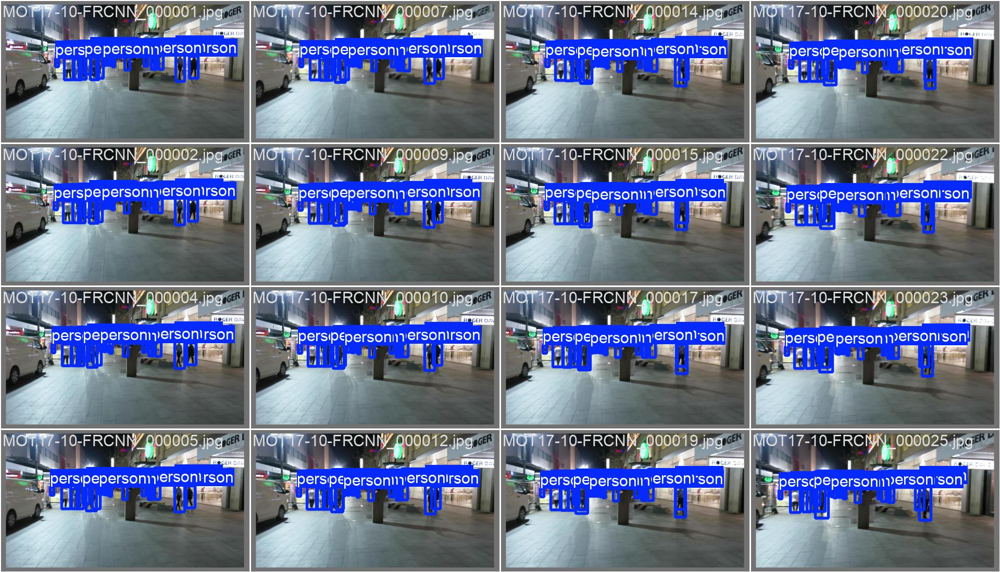

### val_batch0_pred.jpg

`runs/yolo11n_refined/val_batch0_pred.jpg`

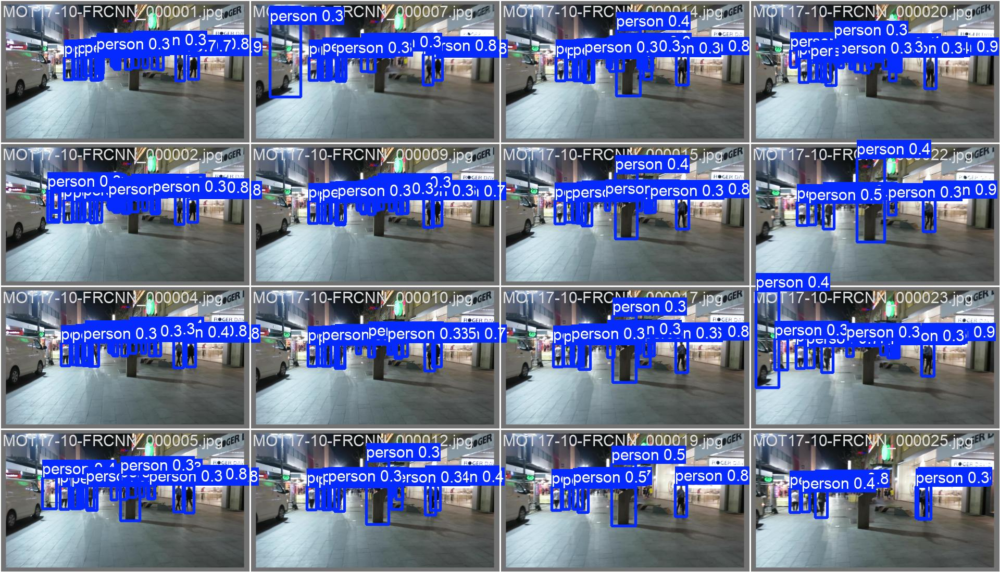

### val_batch1_labels.jpg

`runs/yolo11n_refined/val_batch1_labels.jpg`

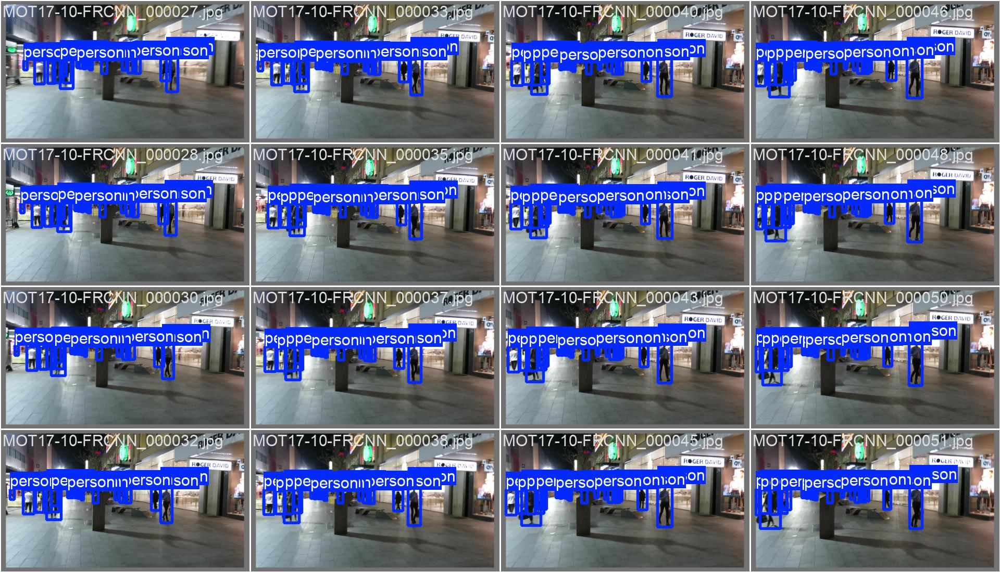

### val_batch1_pred.jpg

`runs/yolo11n_refined/val_batch1_pred.jpg`

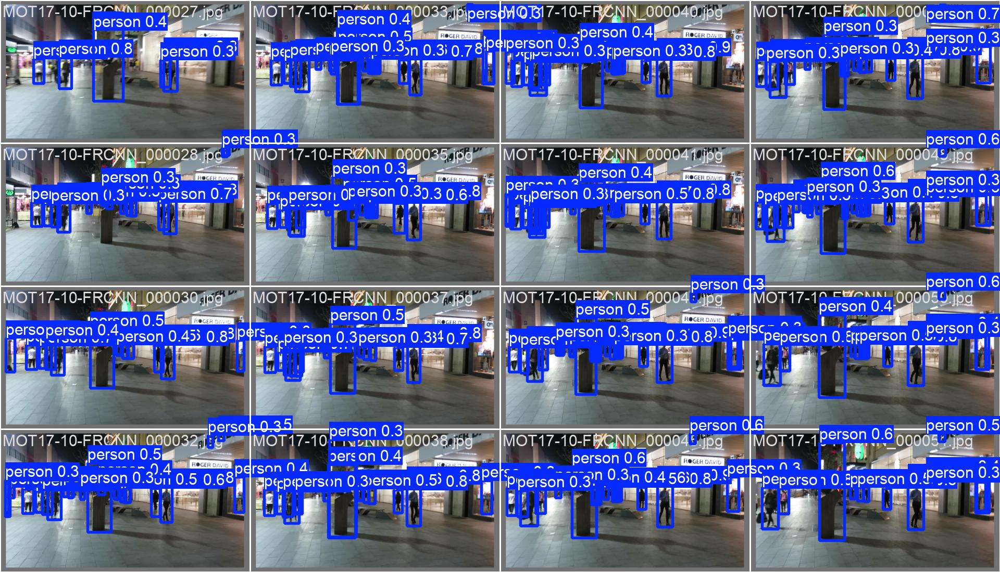

### val_batch2_labels.jpg

`runs/yolo11n_refined/val_batch2_labels.jpg`

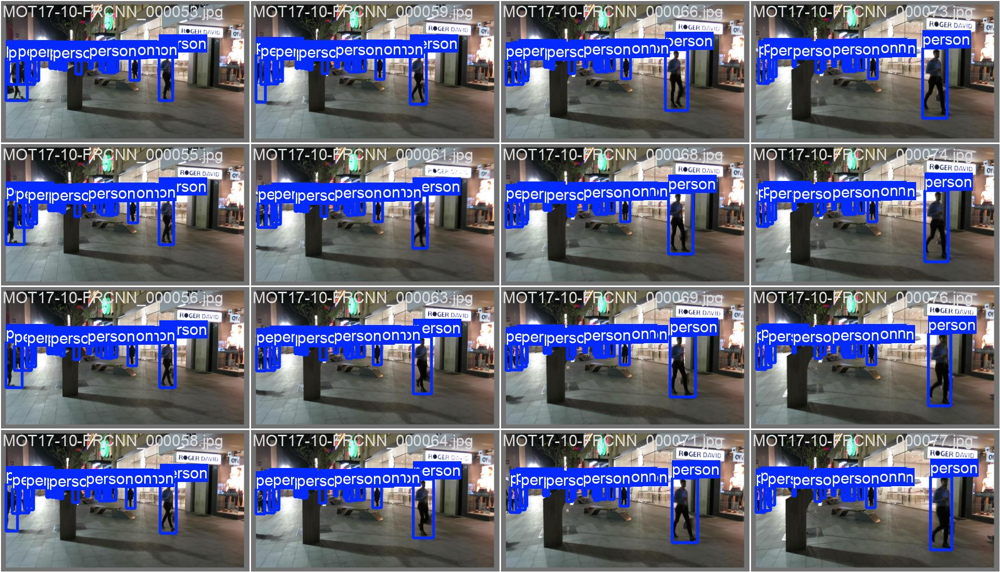

### val_batch2_pred.jpg

`runs/yolo11n_refined/val_batch2_pred.jpg`

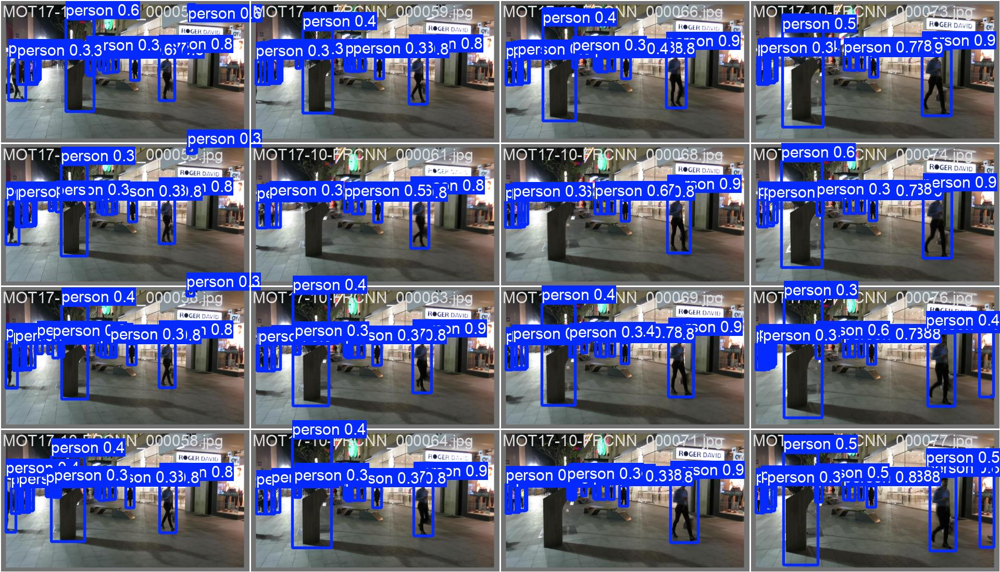

### labels.jpg

`runs/yolo11s/labels.jpg`

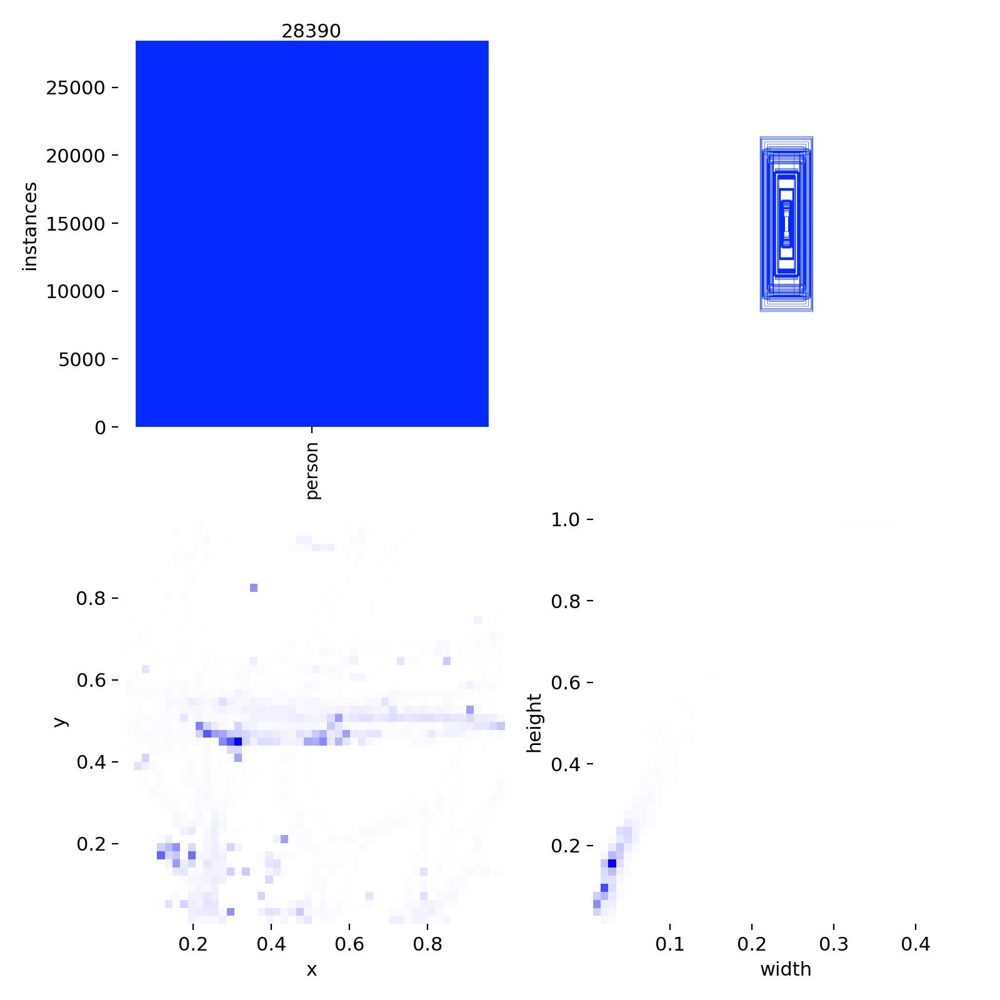

### results.png

`runs/yolo11s/results.png`

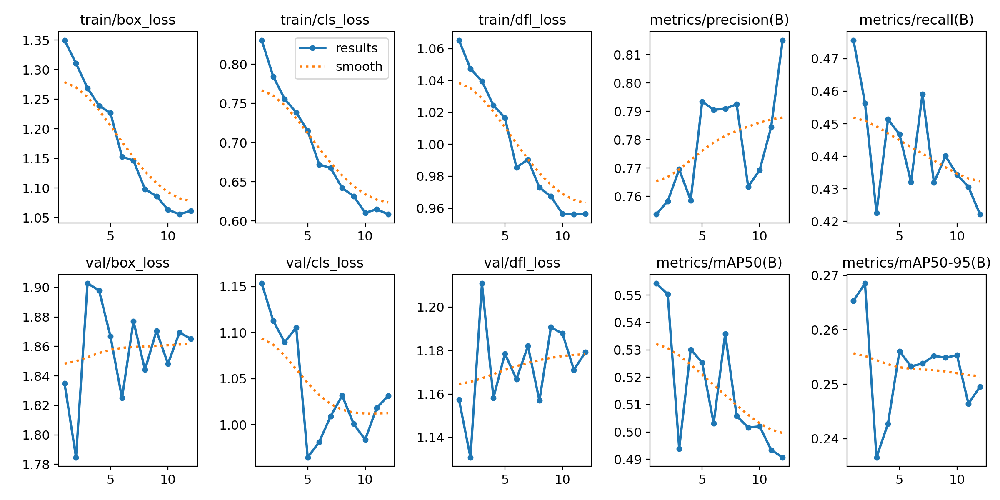

### train_batch0.jpg

`runs/yolo11s/train_batch0.jpg`

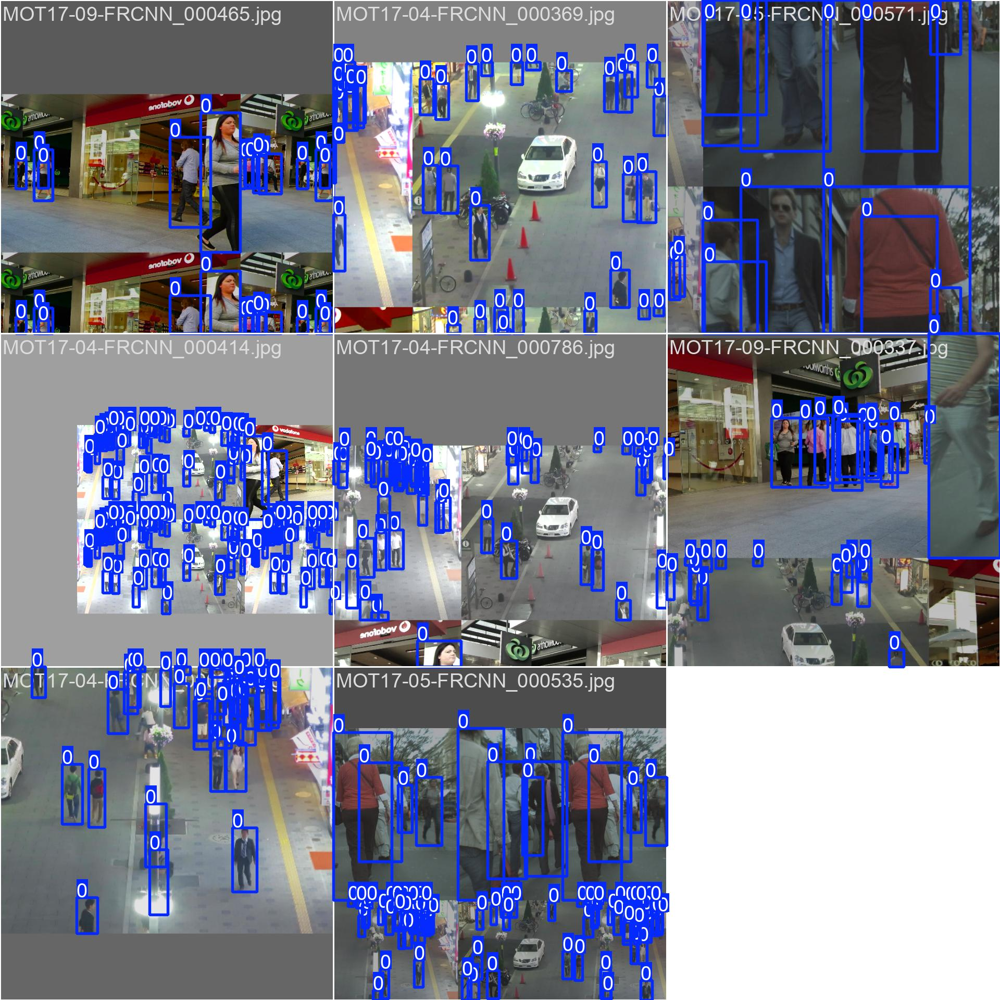

### train_batch1.jpg

`runs/yolo11s/train_batch1.jpg`

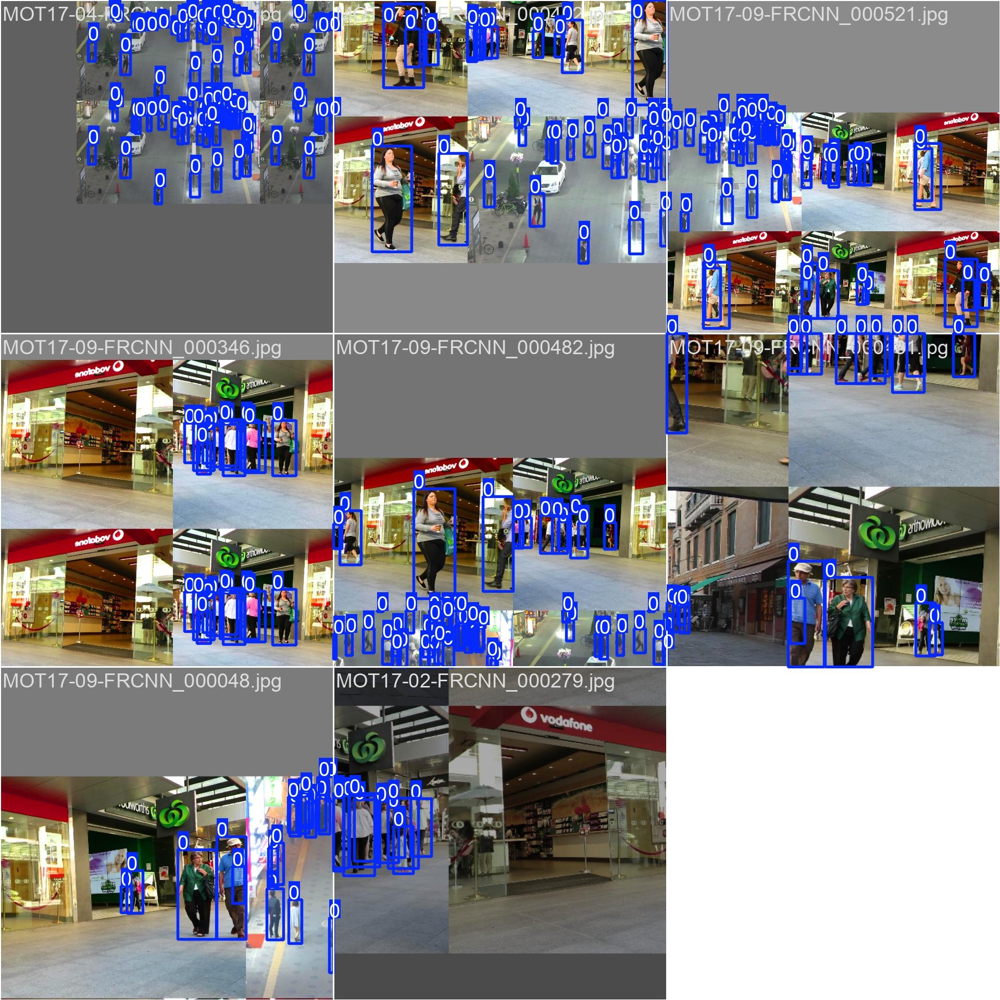

### train_batch2.jpg

`runs/yolo11s/train_batch2.jpg`

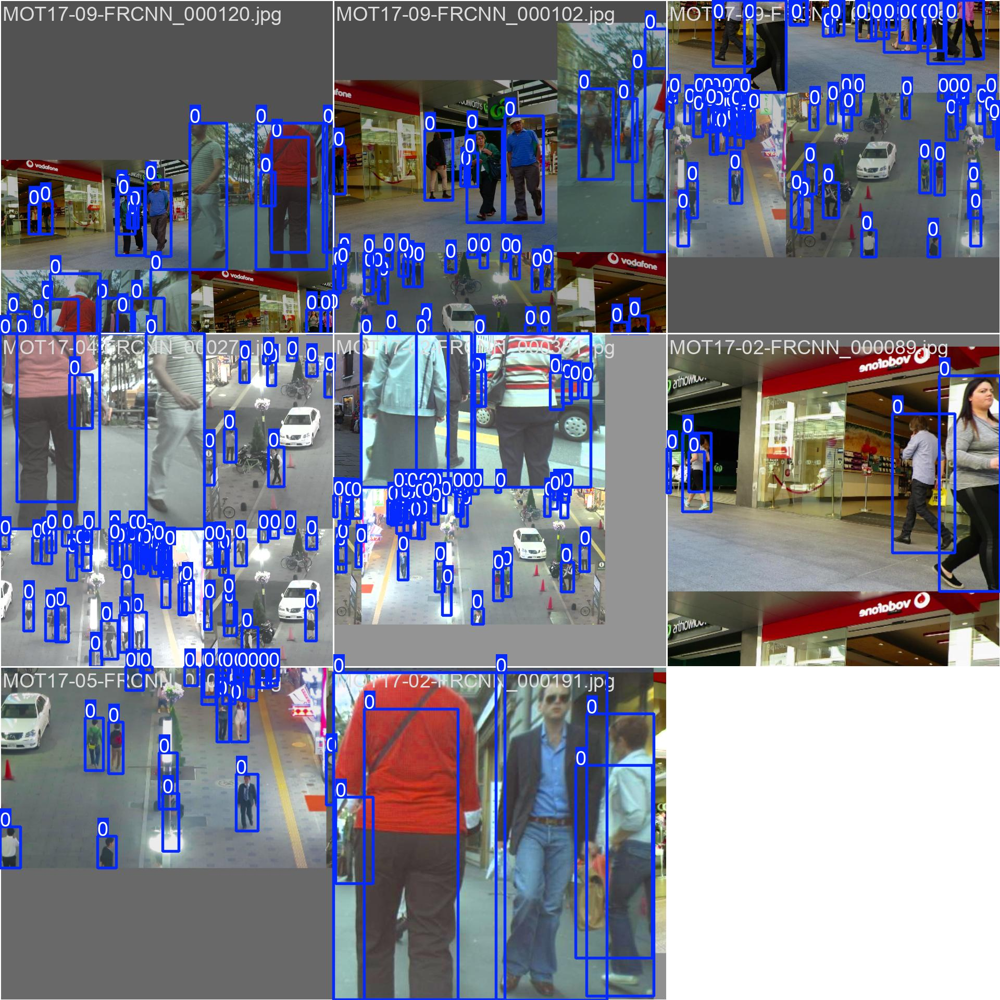

### val_batch0_labels.jpg

`runs/yolo11s/val_batch0_labels.jpg`

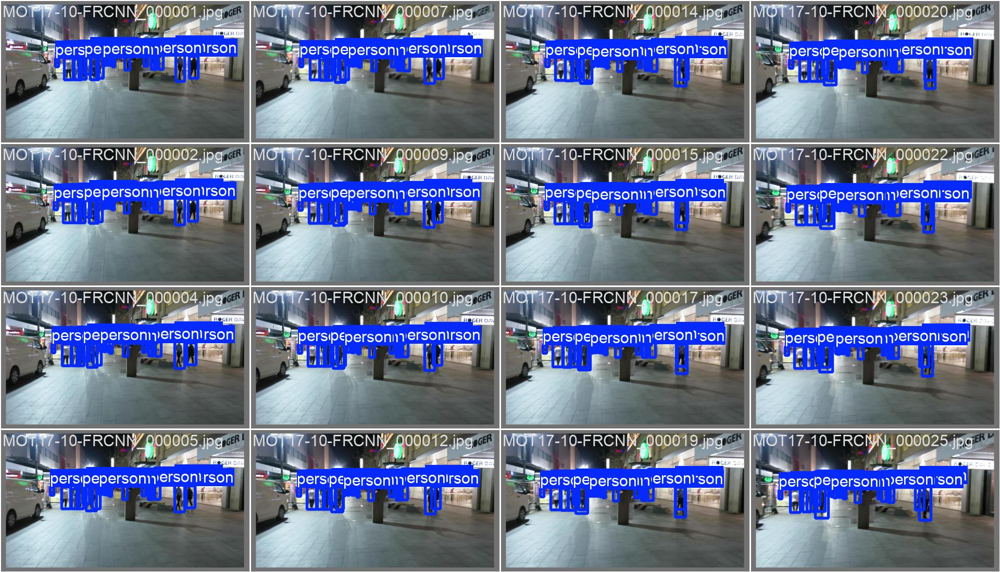

### val_batch0_pred.jpg

`runs/yolo11s/val_batch0_pred.jpg`

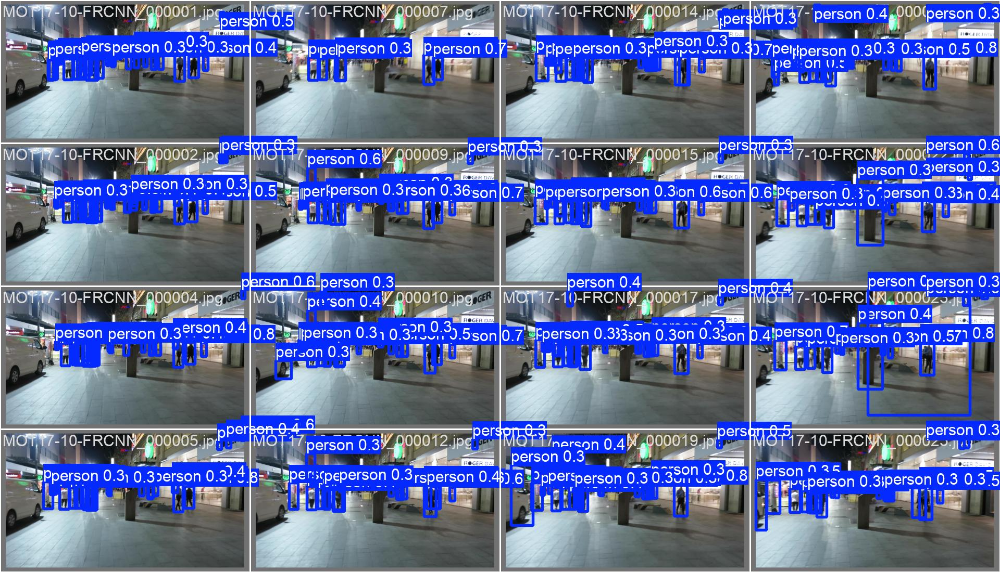

### val_batch1_labels.jpg

`runs/yolo11s/val_batch1_labels.jpg`

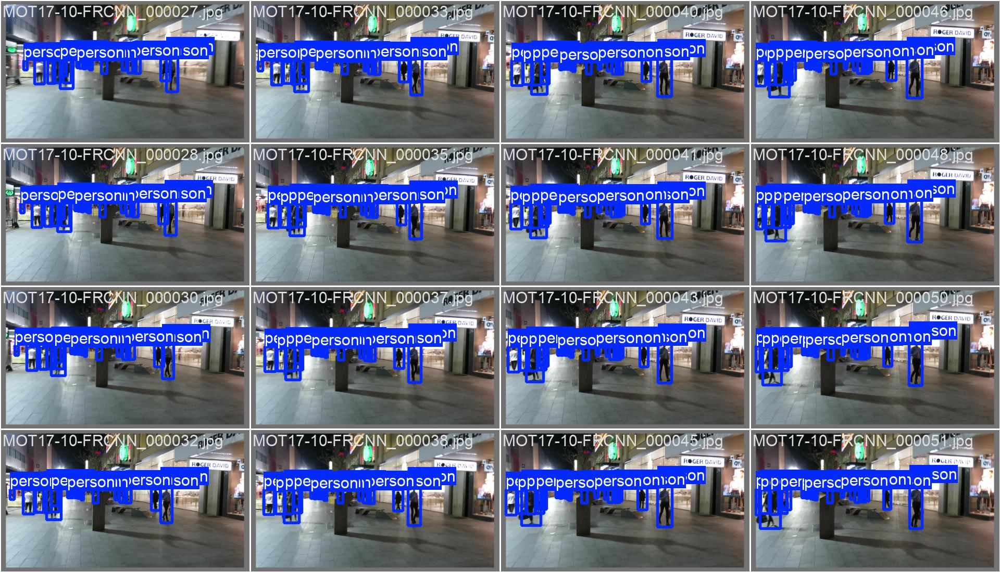

### val_batch1_pred.jpg

`runs/yolo11s/val_batch1_pred.jpg`

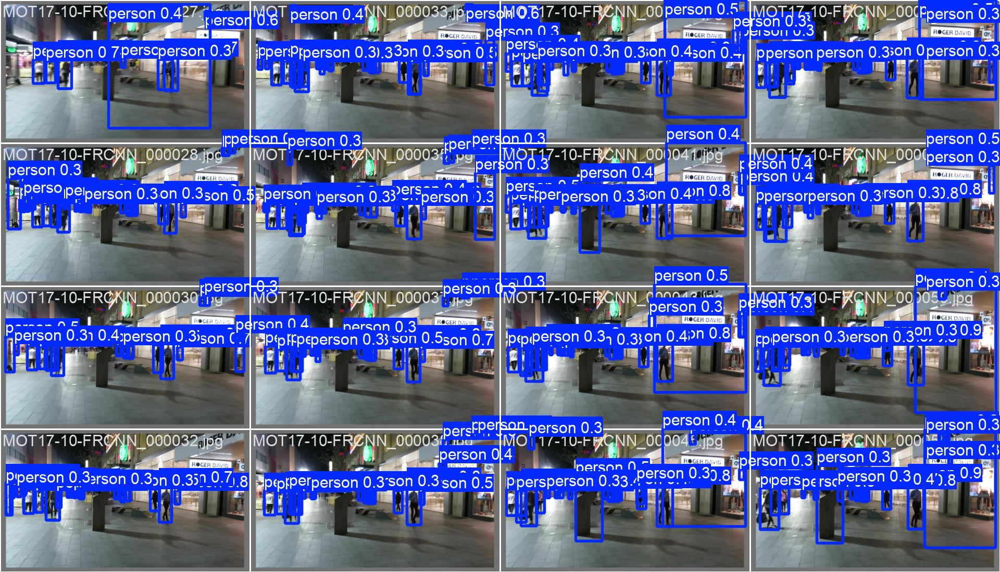

### val_batch2_labels.jpg

`runs/yolo11s/val_batch2_labels.jpg`

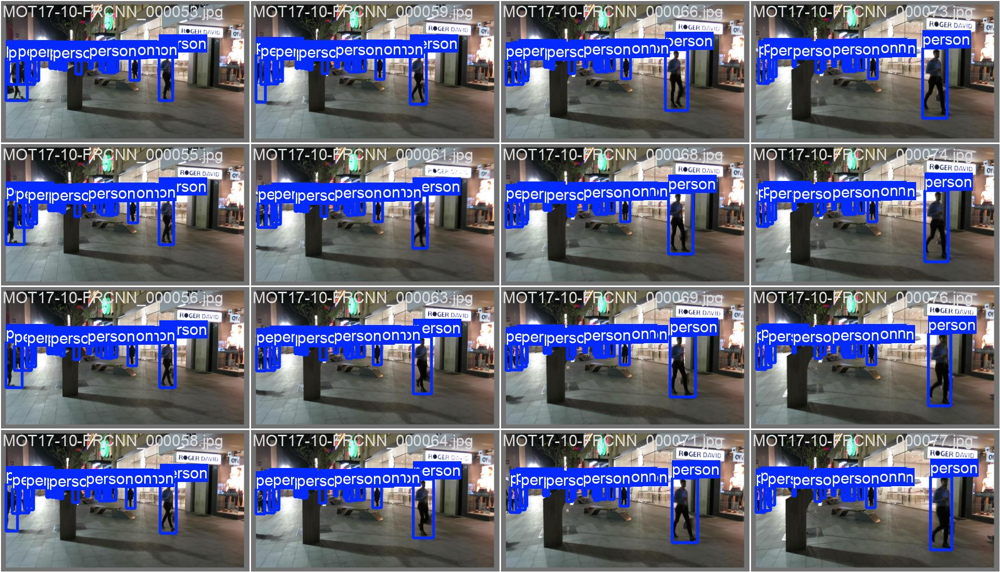

### val_batch2_pred.jpg

`runs/yolo11s/val_batch2_pred.jpg`

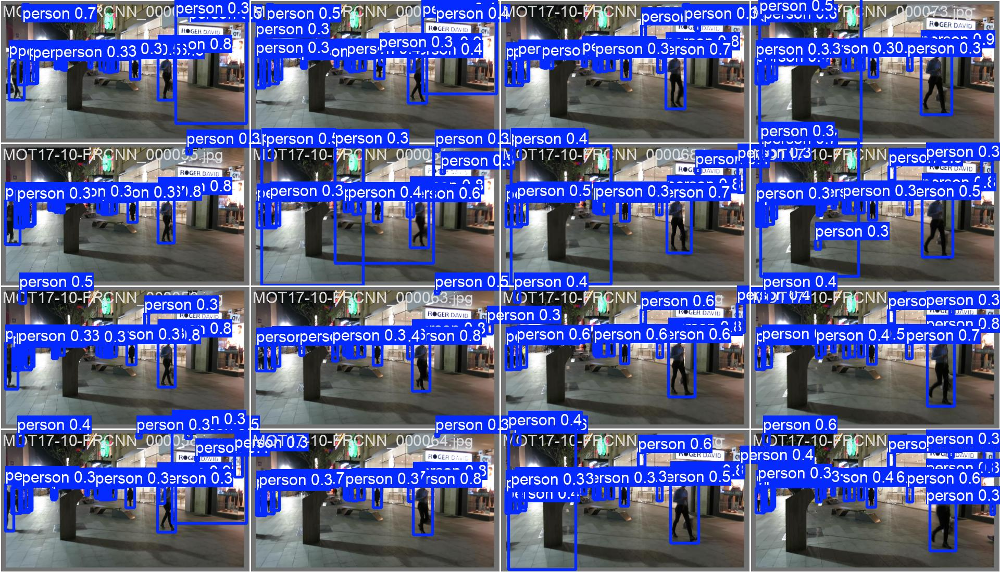

### labels.jpg

`runs/yolo11s_lr_tuned/labels.jpg`

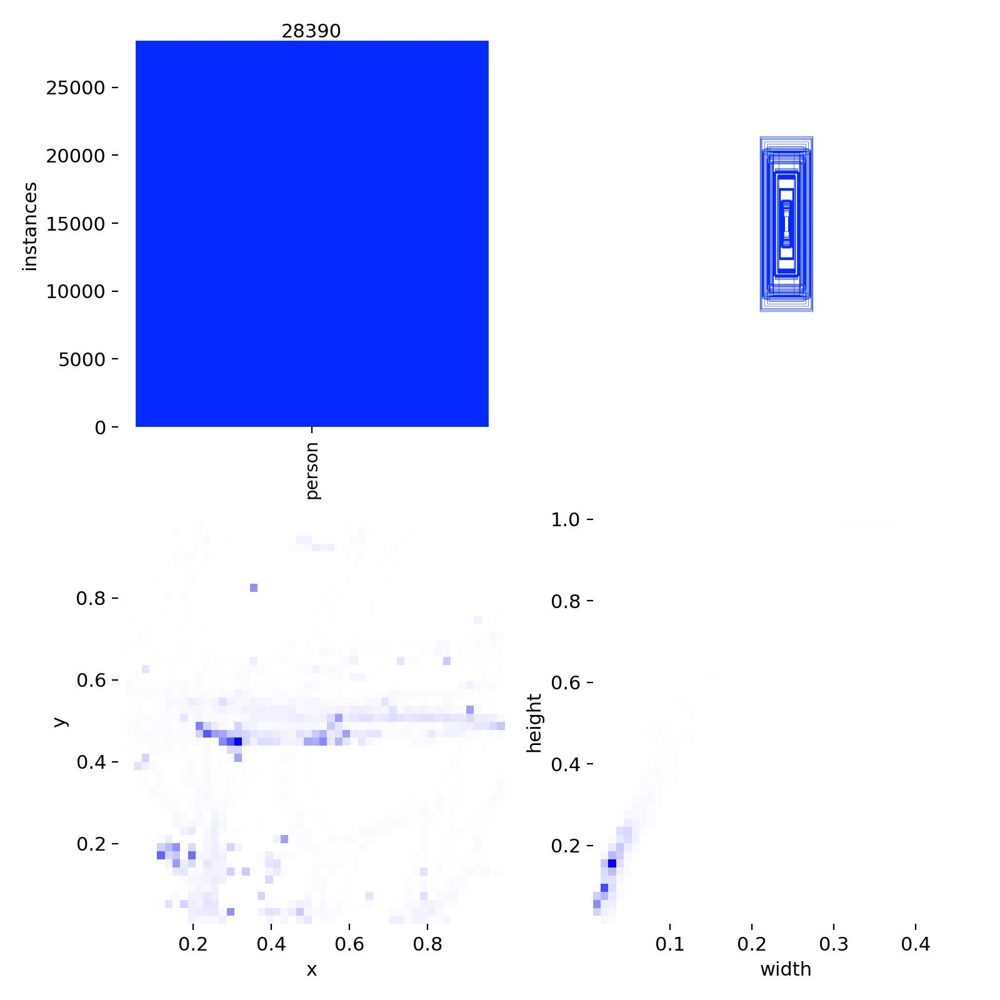

### results.png

`runs/yolo11s_lr_tuned/results.png`

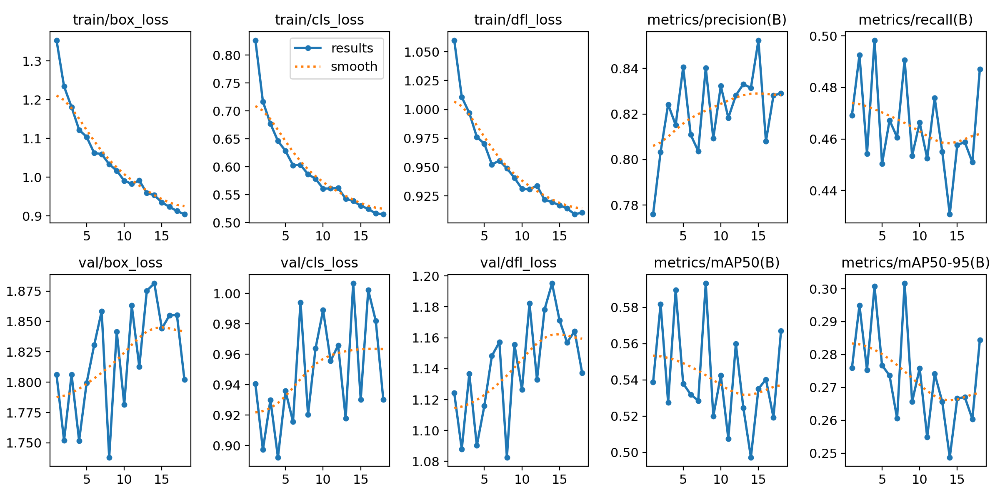

### train_batch0.jpg

`runs/yolo11s_lr_tuned/train_batch0.jpg`

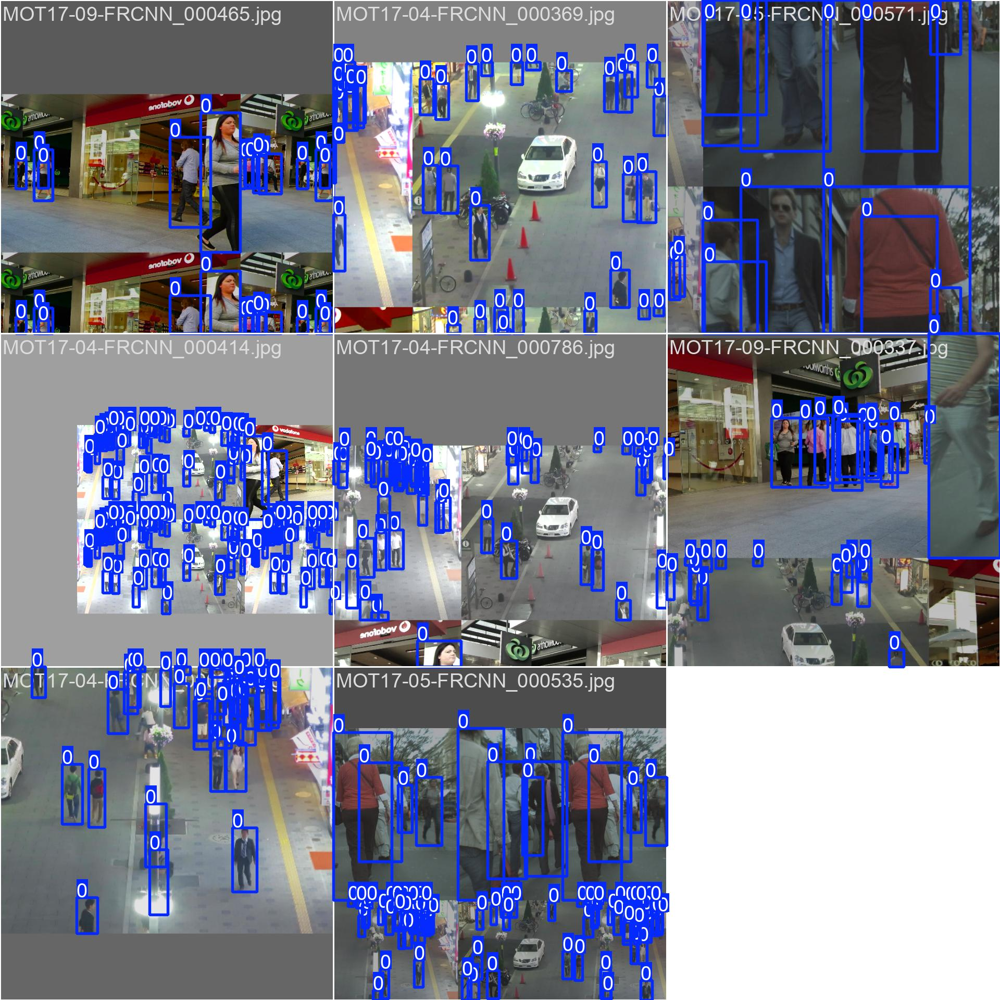

### train_batch1.jpg

`runs/yolo11s_lr_tuned/train_batch1.jpg`

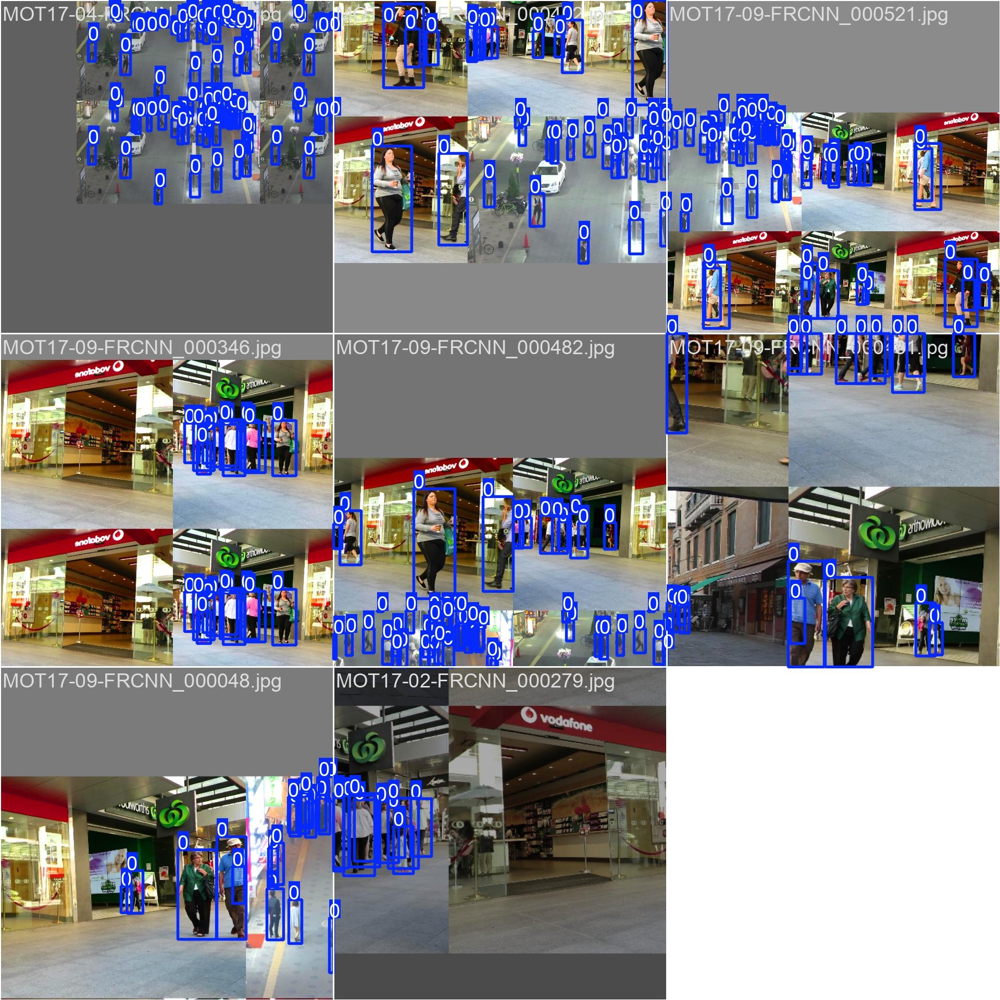

### train_batch2.jpg

`runs/yolo11s_lr_tuned/train_batch2.jpg`

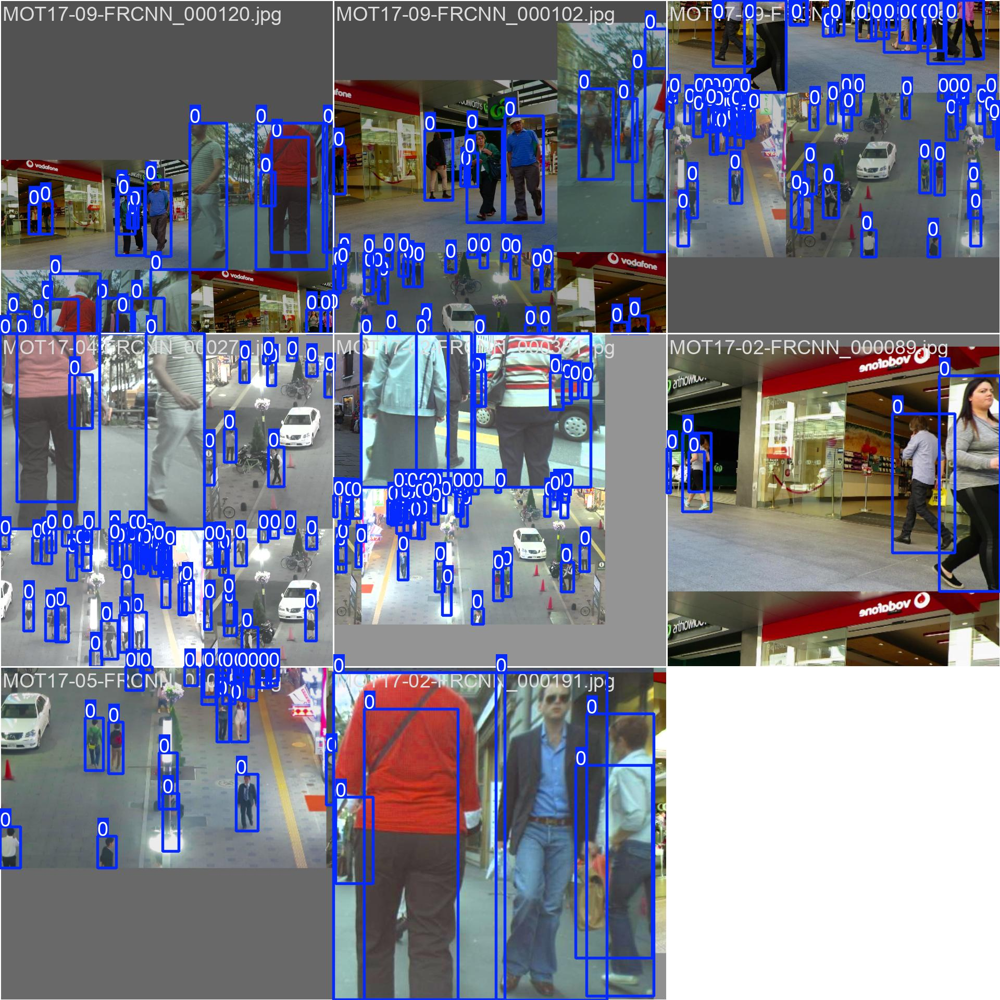

### val_batch0_labels.jpg

`runs/yolo11s_lr_tuned/val_batch0_labels.jpg`

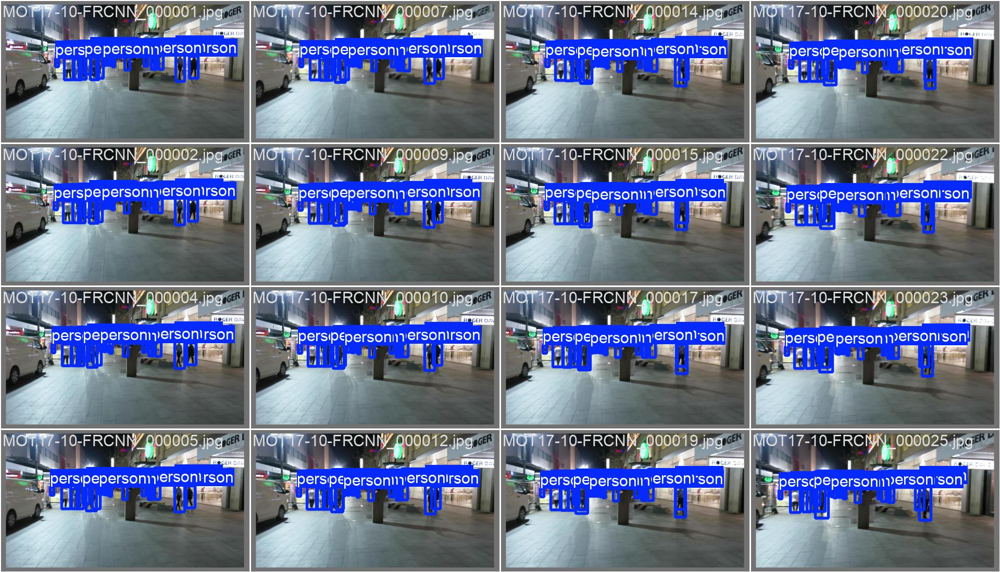

### val_batch0_pred.jpg

`runs/yolo11s_lr_tuned/val_batch0_pred.jpg`

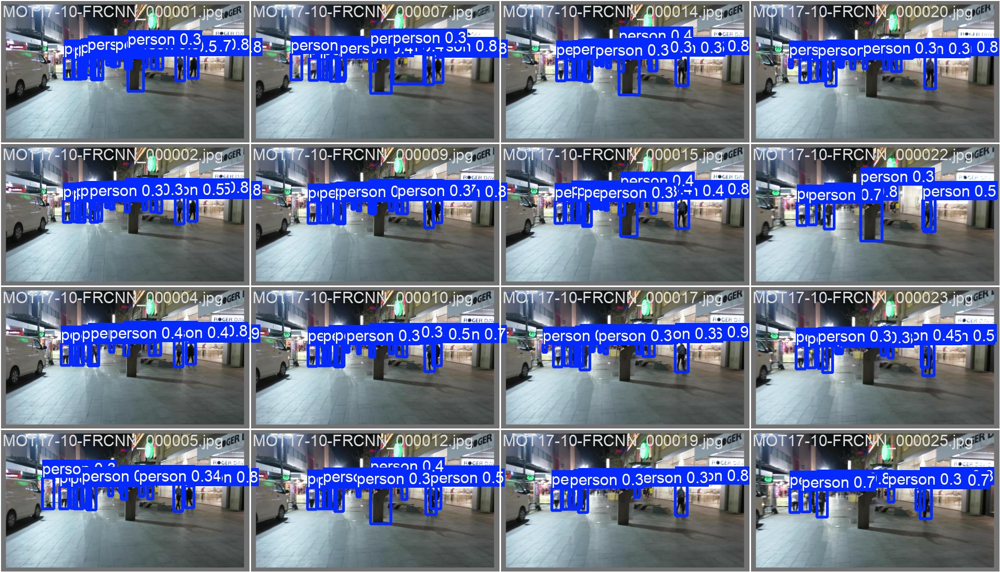

### val_batch1_labels.jpg

`runs/yolo11s_lr_tuned/val_batch1_labels.jpg`

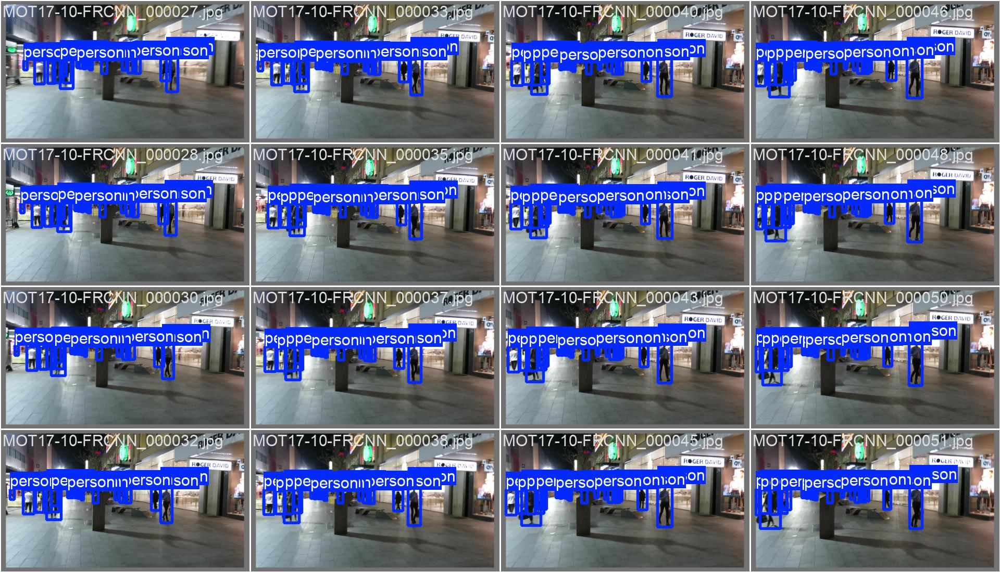

### val_batch1_pred.jpg

`runs/yolo11s_lr_tuned/val_batch1_pred.jpg`

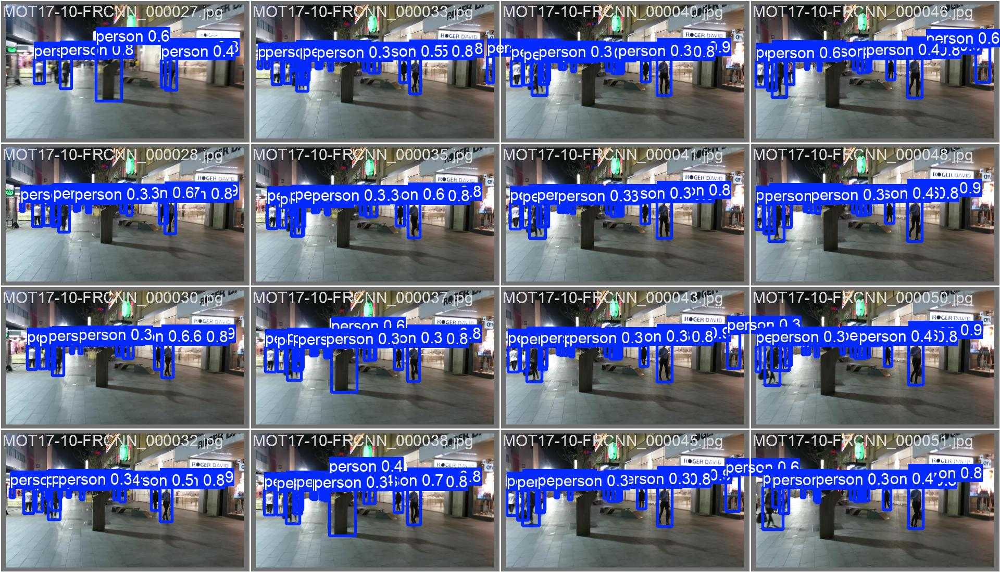

### val_batch2_labels.jpg

`runs/yolo11s_lr_tuned/val_batch2_labels.jpg`

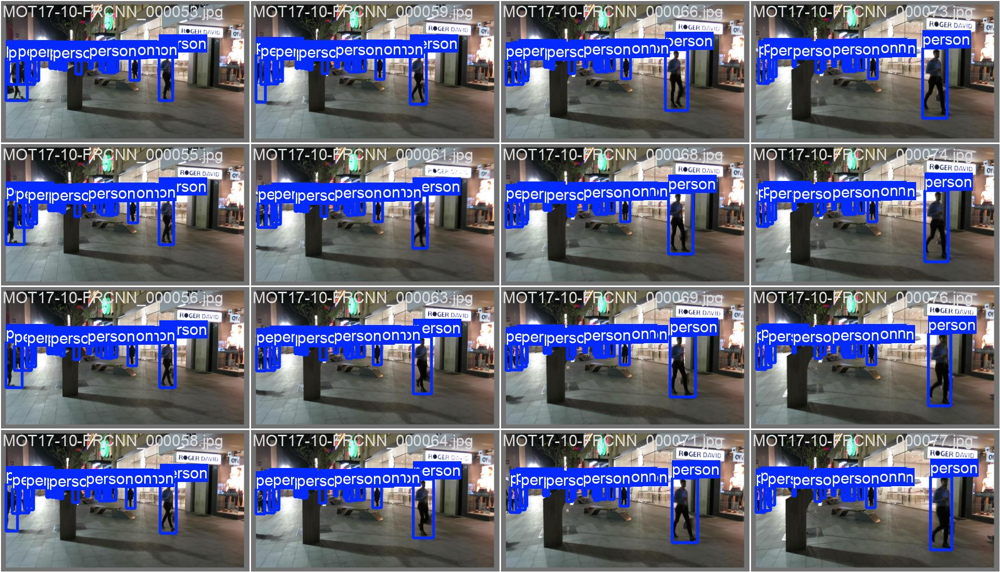

### val_batch2_pred.jpg

`runs/yolo11s_lr_tuned/val_batch2_pred.jpg`

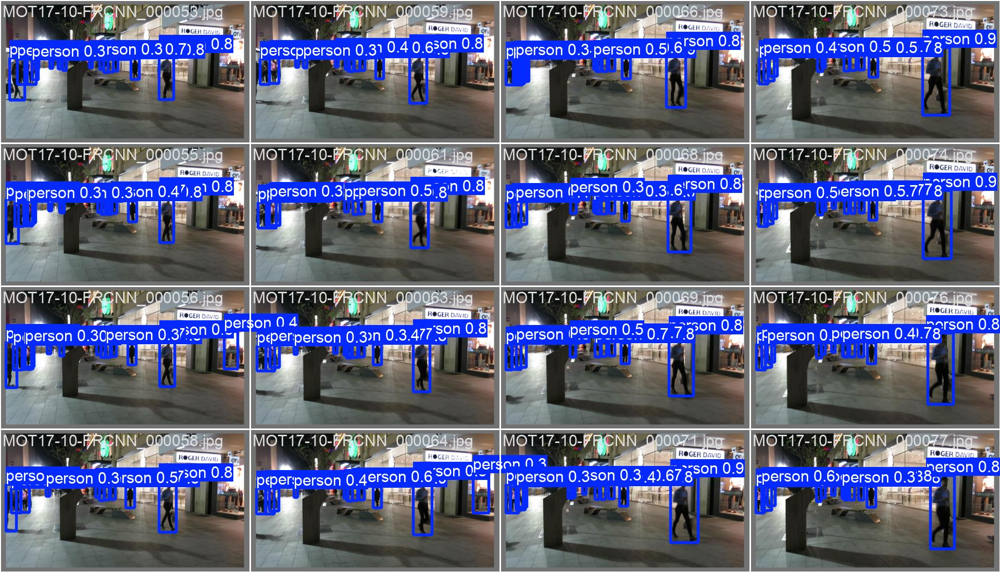


VISIONGUARD-AI VISUAL REVIEW COMPLETED.


In [41]:

from pathlib import Path
from IPython.display import display, Image, Markdown

PROJECT_DIR = Path("/content/VisionGuard-AI")

search_dirs = [
    PROJECT_DIR / "runs",
    PROJECT_DIR / "visualizations",
    PROJECT_DIR / "metrics",
    PROJECT_DIR / "predictions",
]

image_extensions = {".png", ".jpg", ".jpeg", ".webp"}
visual_files = []

for folder in search_dirs:
    if folder.exists():
        visual_files.extend(
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        )

visual_files = sorted(set(visual_files))

priority_terms = [
    "pr_curve",
    "confusion_matrix",
    "f1_curve",
    "p_curve",
    "r_curve",
    "all_models",
    "comparison",
    "final_test",
    "prediction",
    "loss",
    "map",
]

def priority(path):
    name = path.name.lower()
    return (
        next(
            (i for i, term in enumerate(priority_terms) if term in name),
            len(priority_terms)
        ),
        str(path)
    )

visual_files.sort(key=priority)

print(f"Total visual files found: {len(visual_files)}")

if not visual_files:
    print("No visualization images found.")
else:
    for path in visual_files:
        display(Markdown(f"### {path.name}"))
        display(Markdown(f"`{path.relative_to(PROJECT_DIR)}`"))
        display(Image(filename=str(path)))

print("\nVISIONGUARD-AI VISUAL REVIEW COMPLETED.")



# Final Conclusion

VisionGuard-AI successfully demonstrates an end-to-end deep learning pipeline for pedestrian object detection using the MOT17 dataset and the YOLO11 architecture.

A custom dataset containing 2,000 annotated images was prepared, consisting of 1,200 training images, 400 validation images, and 400 test images. A sequence-wise splitting strategy was applied to reduce data leakage between the different subsets.

Several model configurations were trained and evaluated, including YOLO11n and YOLO11s variants. A controlled experiment investigated the impact of reducing image size from 640 to 512 pixels. Additional experiments explored model capacity and learning-rate optimization.

Based on validation performance, YOLO11s with a tuned learning rate of 0.0005 was selected as the final model. The selected checkpoint was evaluated on the held-out test dataset using an image size of 640 pixels, confidence threshold of 0.001, and NMS IoU threshold of 0.70.

## Final Test Results

| Metric | Result |
|---|---:|
| Precision | 80.03% |
| Recall | 43.19% |
| F1-Score | 56.10% |
| mAP@50 | 50.39% |
| mAP@50-95 | 31.03% |

The results indicate that the model achieves relatively high precision but has room for improvement in recall. Visual inspection and failure analysis identified challenges involving occlusion, crowded scenes, small or distant pedestrians, and false-positive detections.

A production-oriented inference pipeline, model card, integrity audit, and performance benchmark were also prepared. The final deployment package provides the trained checkpoint and supporting configuration files.

## Limitations and Future Improvements

Future development could focus on:
- Improving pedestrian detection in crowded and heavily occluded scenes.
- Increasing recall through improved data augmentation and class-balanced sampling.
- Exploring larger YOLO architectures and alternative detection models.
- Evaluating tracking integration for multi-object tracking applications.
- Deploying the model through a FastAPI service with Docker and monitoring.

## Overall Conclusion

This project provided practical experience in dataset preparation, annotation processing, transfer learning, model training, hyperparameter experimentation, evaluation, error analysis, and deployment preparation.

VisionGuard-AI establishes a reproducible experimental foundation for pedestrian detection. Although further optimization is necessary before real-world deployment, the project demonstrates the complete workflow of developing and evaluating a deep learning-based computer vision system.
